# ЕГЭ по информатике · Задание 24 · Обработка символьных строк
Все задачи 1–392 из сборника К.Ю. Полякова ([kpolyakov.spb.ru/school/ege.htm](https://kpolyakov.spb.ru/school/ege.htm), файл `ege24.doc`).

**Как пользоваться**
1. Запустите ячейку из раздела «Подготовка» — она скачает и распакует архив с файлами задач.
2. Дальше каждую задачу можно запускать отдельно: скриншот условия → решение → ответ → (почти всегда) второй способ для проверки.
3. Оглавление Colab (значок ☰ слева) показывает все разделы и номера задач.

Решено 335 задач. В задачах 1–250 из серий **похожих** задач пропущена каждая третья
(всего 57: 3, 6, 9, 12, 15, 18, 23, 26, 29, 32, 35, 45, 48, 51, 54, 57, 60, 63, 66, 69, 74, 79, 82, 85, 89, 92, 95, 100, 105, 110, 115, 120, 127, 131, 136, 139, 142, 149, 155, 159, 162, 165, 171, 183, 189, 193, 198, 202, 207, 211, 214, 217, 220, 224, 227, 230, 245) — на месте каждой пропущенной стоит пометка.
Задачи 251–392 решены все.
Все ответы получены программой и **проверены вторым, независимым способом** — результаты совпали;
для самых запутанных задач (выражения, цепочки «число=число») метод дополнительно проверен полным перебором
на тысячах случайных строк.

## 0. Подготовка: загрузка файлов

In [1]:
# Скачиваем архив с файлами задач с сайта К.Ю. Полякова и распаковываем его в текущую папку
!wget -q -O 24data.zip https://kpolyakov.spb.ru/download/24data.zip
!unzip -o -q 24data.zip
!unzip -o -q k7data.zip
!unzip -o -q k8data.zip
!ls *.txt | wc -l

Если скачать не получилось, можно загрузить архив вручную:
```python
from google.colab import files
files.upload()          # выбрать 24data.zip, потом выполнить команды unzip из ячейки выше
```

# Теория: методы решения задания 24

Задание 24 — обработка длинной символьной строки (обычно ~10⁶ символов). Формулировки очень разные,
поэтому важно не заучить решения, а уметь **выбрать инструмент**. Ниже — все основные методы
(по статье К.Ю. Полякова «Методы обработки символьных строк в задачах ЕГЭ по информатике», Информатика в школе,
2025, №4, и приёмы из курса PRO100): перебор, однопроходные алгоритмы и конечные автоматы, `groupby`,
метод замен и `split`, регулярные выражения, список позиций, два указателя, динамическое программирование.

| Формулировка в условии | Чем решать |
|---|---|
| «сколько раз встречается …» | `count`, `findall`, перебор окон |
| «самая длинная цепочка из символов …» | однопроходный алгоритм, `groupby`, `findall('[ABC]+')` |
| «цепочка без символа/сочетания …» | `split`, метод замен (`replace('PP', 'P P')`) |
| «подряд идущие пары/тройки …» | замена на `*` + `groupby`, ДП, конечный автомат |
| «не более / ровно k символов …», максимум | список позиций, два указателя, перебор с `break` |
| «не менее / ровно k …», минимум | список позиций, два указателя |
| «число в N-ричной системе», «арифметическое выражение» | регулярные выражения, метод замен |
| «из фрагментов XY, YZ, YZZ …» (фрагменты пересекаются) | динамическое программирование, `findall('(?=(…))')` |
| файл из многих строк | `read().split()` / цикл по строкам + `Counter` |

## 1. Чтение файла

Файл обычно содержит **одну** строку. В конце может стоять перевод строки `\n` — его убирает `strip()`.

```python
s = open('24.txt').readline().strip()      # одна строка
a = open('24-s1.txt').read().split()        # файл из многих строк → список строк
```

В Colab (Linux) файлы читаются в кодировке UTF-8. Если в файле есть русские буквы, записанные в Windows-1251,
нужно указать кодировку: `open('24-j1.txt', encoding='cp1251')`.

## 2. Встроенные методы строк

`count` считает **непересекающиеся** вхождения, `replace` заменяет, `split` режет строку, `join` склеивает,
`find`/`rfind` ищут первое/последнее вхождение, срез `s[i:j]` — подстрока, `s[::-1]` — переворот.

In [2]:
s = 'ABABAB'
print(s.count('AB'), s.count('ABA'))   # 'ABA' перекрывается — count даёт 1, а не 2
print(s.replace('AB', '*'))
print('ab cd  ef'.split(), 'A-B--C'.split('-'))
print('_'.join(['x', 'y', 'z']))
print(s.find('B'), s.rfind('B'), s[1:4], s[::-1])

3 1
***
['ab', 'cd', 'ef'] ['A', 'B', '', 'C']
x_y_z
1 5 BAB BABABA


## 3. Однопроходный алгоритм

Перебираем символы **один раз** и поддерживаем длину текущей «правильной» цепочки `k` и лучший ответ `mx`.
Добавленный символ не нарушил правильность → `k += 1`, нарушил → `k = 0` (или `1`, если символ может
начать новую цепочку). Сложность O(n) — работает мгновенно даже на 10⁶ символах.

```python
k = mx = 0
for c in s:
    if <цепочка продолжается>:
        k += 1
        mx = max(mx, k)
    else:
        k = 0   # или 1
```

In [3]:
s = 'ABCCCACCB'
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)   # самая длинная цепочка из C

3


### Конечный автомат

Если для продолжения цепочки нужно знать, какой символ мы **ждём**, вводят состояние.
Пример из статьи: максимальное число подряд идущих пар `AB`. Состояние 0 — ждём `A`, 1 — ждём `B`.
Состояние всегда равно `k % 2`, поэтому автомат превращается в обычный однопроходный алгоритм.

In [4]:
s = 'CABABABBAB'
k = mx = 0
for c in s:
    if k % 2 == 0:              # ждём A
        k = k + 1 if c == 'A' else 0
    else:                       # ждём B
        if c == 'B':
            k += 1
        else:
            k = 1 if c == 'A' else 0
    mx = max(mx, k)
print(mx // 2)                  # число пар AB

3


## 4. `groupby` — группировка подряд идущих одинаковых символов

`itertools.groupby(s)` выдаёт пары `(символ, группа)`. Очень удобно вместе с методом замен:
сначала заменить «нужное» на `*`, потом найти самую длинную группу `*`.

In [5]:
from itertools import groupby
s = 'aaabbbcddbbaaaa'
print([(c, len(list(g))) for c, g in groupby(s)])
print(max(len(list(g)) for c, g in groupby(s) if c == 'b'))

[('a', 3), ('b', 3), ('c', 1), ('d', 2), ('b', 2), ('a', 4)]
3


## 5. Метод замен и `split`

Заменами сводим задачу к уже известной.
* Пары `AB` → `*`, и ищем самую длинную цепочку `*`.
* «согласная + гласная»: согласные → `s`, гласные → `g`, затем `sg` → `*`.
* Цепочка без двух соседних `P`: вставляем пробел внутрь каждой пары `PP` (дважды!) и делим `split()`.
* `re.sub('[0-9]', '*', s)` — замена по классу символов.

In [6]:
s = 'APPPPPBPPC'
s = s.replace('PP', 'P P')
s = s.replace('PP', 'P P')      # второй раз — для оставшихся пар (PPPPP → P PP PP → P P P P P)
print(s.split(), max(s.split(), key=len))

['AP', 'P', 'P', 'P', 'PBP', 'PC'] PBP


In [7]:
from re import sub
s = 'BADFECABOA'
s = sub('[BCDF]', 's', s)
s = sub('[AEO]', 'g', s)
print(s, s.replace('sg', '*'))

sgssgsgsgg *s***g


Метод замен из статьи для **арифметического выражения** (цифры 0, 6–9, знаки `-` и `*`, без ведущих нулей):
все ненулевые цифры → `1`, все знаки → `*`, затем пробелами разрезаем запрещённые места. После замен в строке
остаются только правильные выражения, разделённые пробелами.

```python
s = ' ' + s + ' '
for c in '6789': s = s.replace(c, '1')
s = s.replace('-', '*')
s = s.replace('**', ' ')
s = s.replace(' *', ' ').replace('* ', ' ')
s = s.replace('*00', '*0 0').replace('*01', '*0 1')
while ' 00' in s: s = s.replace(' 00', ' 0')
s = s.replace(' 01', ' 1')
print(len(max(s.split(), key=len)))
```

## 6. Регулярные выражения (`re`)

| Шаблон | Что значит |
|---|---|
| `A+`, `A*`, `A?` | одна и больше / ноль и больше / ноль или одна `A` |
| `[ABC]`, `[^D]`, `[0-9A-F]` | один символ из набора / любой, кроме `D` / диапазоны |
| `\d`, `\D`, `.` | цифра / не цифра / любой символ |
| `A{3}`, `A{2,5}` | ровно 3 / от 2 до 5 повторений |
| `(?:AB)+` | группа без захвата — повторяем фрагмент целиком |
| `X|Y` | ИЛИ для целых фрагментов |
| `(?<=A)`, `(?<!J)` | слева стоит `A` / слева НЕ `J` (символ не «съедается») |
| `(?=B)`, `(?!J)` | справа стоит `B` / справа НЕ `J` |
| `(?=(шаблон))` | искать совпадения, начиная с **каждой** позиции (перекрывающиеся) |

Основные функции: `findall` (все совпадения), `finditer` (с позициями), `sub` (замена), `fullmatch` (вся строка).
Число без ведущих нулей: `[1-9]\d*|0`; правильное выражение: `{number}(?:[-*]{number})*`.

In [8]:
from re import findall
s = 'XYZZXYXY'
print(findall('(?:YZZ|XY|YZ)+', s))          # теряет лучший вариант YZZXYXY
print(findall('(?=((?:YZZ|XY|YZ)+))', s))   # поиск с каждой позиции находит его
number = r'(?:[1-9]\d*|0)'
print(findall(fr'{number}(?:[-*]{number})*', '00-7*80--9*0*01'))

['XY', 'XYXY']
['XY', 'YZZXYXY', 'XYXY', 'XY']
['0', '0-7*80', '9*0*0', '1']


In [9]:
from re import findall
s = 'C1A0F2BBQ8AC'
# наибольшее чётное 14-ричное число (последняя цифра чётная)
parts = findall('[0-9A-D]*[02468AC]', s)
print(parts, max(parts, key=lambda x: int(x, 14)))

['C1A0', '2', '8AC'] C1A0


## 7. Полный перебор и оптимизированный перебор

Перебираем левую границу `L` и правую `R`. Полный перебор квадратичный и на 10⁶ символах слишком медленный,
но две оптимизации (из статьи и из курса) делают его рабочим:
1. для **максимума** начинаем `R` сразу с `L + mx` — более короткие строки уже не интересны;
2. если удлинение уже не сделает строку правильной (`cantBeValid`), делаем `break`.

```python
mx = 0
for L in range(len(s)):
    for R in range(L + mx, len(s)):
        sr = s[L:R+1]
        if sr.count('T') <= 100:          # ещё может стать правильной
            if sr.count('T') == 100:
                mx = max(mx, len(sr))
        else:
            break
```

Для **минимума** перебираем `R` в обратную сторону от `L + mn` и ставим не слишком большое начальное `mn`:

```python
mn = 250
for L in range(len(s)):
    for R in range(L + mn - 1, L, -1):
        sr = s[L:R+1]
        if sr.count('Z') >= 120:
            mn = min(mn, len(sr))
        else:
            break
```

## 8. Список позиций («статика»)

Собираем индексы интересующих символов в список и работаем с ним как с массивом чисел.
Например, максимальная подстрока, в которой **не более k** точек: добавим фиктивные позиции `-1` и `len(s)`,
тогда подстрока между точками `p[j]` и `p[j+k+1]` содержит ровно `k` точек, её длина `p[j+k+1] - p[j] - 1`.
Минимальная подстрока с **ровно k** точками — от `p[j]` до `p[j+k-1]` включительно.

In [10]:
s = 'AB.CD..E.FGH.I'
k = 2
p = [-1] + [i for i in range(len(s)) if s[i] == '.'] + [len(s)]
print(p)
print('не более 2 точек, максимум:', max(p[j+k+1] - p[j] - 1 for j in range(len(p) - k - 1)))
q = p[1:-1]
print('ровно 2 точки, минимум:', min(q[j+k-1] - q[j] + 1 for j in range(len(q) - k + 1)))

[-1, 2, 5, 6, 8, 12, 14]
не более 2 точек, максимум: 7
ровно 2 точки, минимум: 2


## 9. Метод двух указателей («динамика»)

Двигаем правую границу `R` по строке. Если подстрока `s[L..R]` стала «слишком длинной» (нарушила условие),
подтягиваем левую границу `L`. Каждый указатель проходит строку один раз — O(n).

**Максимум** («ровно 100 букв T»):
```python
L = cnt = mx = 0
for R in range(len(s)):
    cnt += s[R] == 'T'
    while cnt > 100:
        cnt -= s[L] == 'T'
        L += 1
    if cnt == 100:
        mx = max(mx, R - L + 1)
```
**Минимум**: подтягиваем `L`, пока строка остаётся правильной без левого символа — условие
`cnt > 100 or (cnt == 100 and s[L] != 'T')`.

In [11]:
s = 'TATTBTTCT'
L = cnt = mx = 0
mn = 10**9
for R in range(len(s)):
    cnt += s[R] == 'T'
    while cnt > 3 or (cnt == 3 and s[L] != 'T'):
        cnt -= s[L] == 'T'
        L += 1
    if cnt == 3:
        mn = min(mn, R - L + 1)
print('минимальная длина с ровно тремя T:', mn)

минимальная длина с ровно тремя T: 4


## 10. Динамическое программирование

`dp[i]` — лучший ответ для цепочек, **заканчивающихся** символом `s[i]`. Пример из статьи (Е. Джобс): самая
длинная подстрока из фрагментов `XY`, `YZ`, `YZZ`. Фрагменты пересекаются, поэтому замены не работают, а ДП — да:

In [12]:
s = 'XYYYZXYYZZX'
N = len(s)
dp = [0] * N
for i in range(N):
    if s[i-1:i+1] in ['XY', 'YZ']:
        dp[i] = 2 + dp[i-2]
    if s[i-2:i+1] in ['YZZ']:
        dp[i] = max(dp[i], 3 + dp[i-3])
print(dp, max(dp))

[0, 2, 0, 0, 2, 0, 4, 0, 6, 7, 0] 7


В Python отрицательные индексы `dp[-1]`, `dp[-2]` в начале указывают на ещё нулевые элементы,
а срезы `s[-1:1]` пустые, поэтому граничные случаи отдельно обрабатывать не нужно.

## 11. Подсчёт с `Counter` и выбор «с правилом при равенстве»

`Counter` считает, сколько раз встретился каждый элемент. Если нужен самый частый, а при равенстве — первый
по алфавиту, сортируем по ключу `(-количество, буква)`. «Позже по алфавиту» — ключ `(-количество, -ord(буква))`.

In [13]:
from collections import Counter
s = 'ABCAABADDD'
cnt = Counter(s[i+1] for i in range(len(s) - 1) if s[i] == 'A')   # что стоит после A
print(cnt)
c, k = sorted(cnt.items(), key=lambda x: (-x[1], x[0]))[0]
print(c + str(k))

Counter({'B': 2, 'A': 1, 'D': 1})
B2


# Практика: задачи 1–392

## Самая длинная цепочка одинаковых символов

**Идея.** Идём по строке один раз и держим два числа: `k` — длина текущей цепочки нужных символов, `mx` — лучшая длина.
Встретили нужный символ — `k += 1`, иначе цепочка оборвалась — `k = 0`. Это **однопроходный алгоритм**, работает за O(n).

Короткие альтернативы:
* `groupby` склеивает подряд идущие одинаковые символы в группы;
* `re.findall('C+', s)` сразу возвращает все цепочки из `C`;
* `split` по «чужим» символам оставляет только нужные куски.

### Задача 1

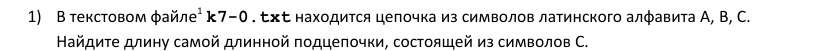

<details><summary>Текст условия</summary>В текстовом файле k7-0.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [14]:
s = open('k7-0.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

0


**Способ 2 (проверка):** groupby

In [15]:
from itertools import groupby
s = open('k7-0.txt').readline().strip()
a = [len(list(g)) for c, g in groupby(s) if c == 'C']
print(max(a, default=0))

0


**Ответ: `0`**

> В файле k7-0.txt нет ни одной буквы C, поэтому ответ 0.

### Задача 2

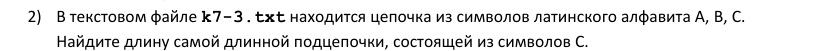

<details><summary>Текст условия</summary>В текстовом файле k7-3.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [16]:
s = open('k7-3.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

1


**Способ 2 (проверка):** регулярное выражение

In [17]:
from re import findall
s = open('k7-3.txt').readline().strip()
print(max(map(len, findall('C+', s)), default=0))

1


**Ответ: `1`**

*Задача 3 — подобная предыдущим, пропущена.*

### Задача 4

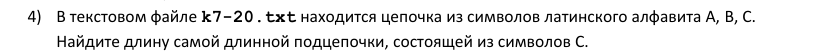

<details><summary>Текст условия</summary>В текстовом файле k7-20.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [18]:
s = open('k7-20.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

4


**Способ 2 (проверка):** замена + split

In [19]:
s = open('k7-20.txt').readline().strip()
s = s.replace('A', ' ').replace('B', ' ')
print(max(map(len, s.split()), default=0))

4


**Ответ: `4`**

### Задача 5

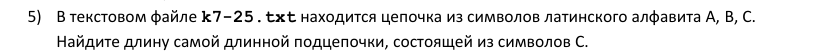

<details><summary>Текст условия</summary>В текстовом файле k7-25.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [20]:
s = open('k7-25.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

5


**Способ 2 (проверка):** groupby

In [21]:
from itertools import groupby
s = open('k7-25.txt').readline().strip()
a = [len(list(g)) for c, g in groupby(s) if c == 'C']
print(max(a, default=0))

5


**Ответ: `5`**

*Задача 6 — подобная предыдущим, пропущена.*

### Задача 7

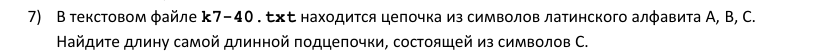

<details><summary>Текст условия</summary>В текстовом файле k7-40.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [22]:
s = open('k7-40.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

7


**Способ 2 (проверка):** регулярное выражение

In [23]:
from re import findall
s = open('k7-40.txt').readline().strip()
print(max(map(len, findall('C+', s)), default=0))

7


**Ответ: `7`**

### Задача 8

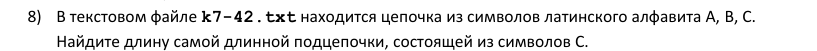

<details><summary>Текст условия</summary>В текстовом файле k7-42.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [24]:
s = open('k7-42.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

8


**Способ 2 (проверка):** замена + split

In [25]:
s = open('k7-42.txt').readline().strip()
s = s.replace('A', ' ').replace('B', ' ')
print(max(map(len, s.split()), default=0))

8


**Ответ: `8`**

*Задача 9 — подобная предыдущим, пропущена.*

### Задача 10

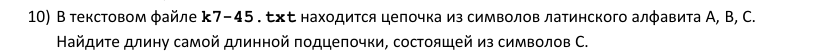

<details><summary>Текст условия</summary>В текстовом файле k7-45.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [26]:
s = open('k7-45.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

9


**Способ 2 (проверка):** groupby

In [27]:
from itertools import groupby
s = open('k7-45.txt').readline().strip()
a = [len(list(g)) for c, g in groupby(s) if c == 'C']
print(max(a, default=0))

9


**Ответ: `9`**

### Задача 11

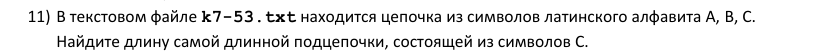

<details><summary>Текст условия</summary>В текстовом файле k7-53.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [28]:
s = open('k7-53.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

14


**Способ 2 (проверка):** регулярное выражение

In [29]:
from re import findall
s = open('k7-53.txt').readline().strip()
print(max(map(len, findall('C+', s)), default=0))

14


**Ответ: `14`**

*Задача 12 — подобная предыдущим, пропущена.*

### Задача 13

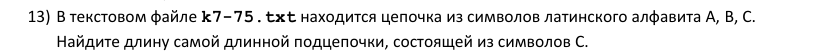

<details><summary>Текст условия</summary>В текстовом файле k7-75.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [30]:
s = open('k7-75.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

19


**Способ 2 (проверка):** замена + split

In [31]:
s = open('k7-75.txt').readline().strip()
s = s.replace('A', ' ').replace('B', ' ')
print(max(map(len, s.split()), default=0))

19


**Ответ: `19`**

### Задача 14

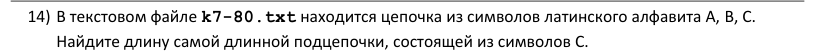

<details><summary>Текст условия</summary>В текстовом файле k7-80.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [32]:
s = open('k7-80.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

28


**Способ 2 (проверка):** groupby

In [33]:
from itertools import groupby
s = open('k7-80.txt').readline().strip()
a = [len(list(g)) for c, g in groupby(s) if c == 'C']
print(max(a, default=0))

28


**Ответ: `28`**

*Задача 15 — подобная предыдущим, пропущена.*

### Задача 16

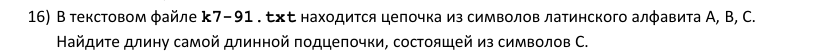

<details><summary>Текст условия</summary>В текстовом файле k7-91.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [34]:
s = open('k7-91.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

49


**Способ 2 (проверка):** регулярное выражение

In [35]:
from re import findall
s = open('k7-91.txt').readline().strip()
print(max(map(len, findall('C+', s)), default=0))

49


**Ответ: `49`**

### Задача 17

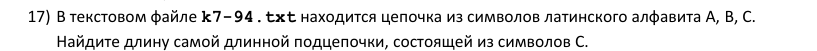

<details><summary>Текст условия</summary>В текстовом файле k7-94.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [36]:
s = open('k7-94.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

106


**Способ 2 (проверка):** замена + split

In [37]:
s = open('k7-94.txt').readline().strip()
s = s.replace('A', ' ').replace('B', ' ')
print(max(map(len, s.split()), default=0))

106


**Ответ: `106`**

*Задача 18 — подобная предыдущим, пропущена.*

### Задача 19

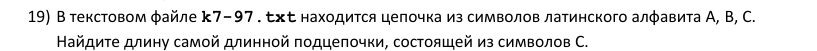

<details><summary>Текст условия</summary>В текстовом файле k7-97.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [38]:
s = open('k7-97.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

136


**Способ 2 (проверка):** groupby

In [39]:
from itertools import groupby
s = open('k7-97.txt').readline().strip()
a = [len(list(g)) for c, g in groupby(s) if c == 'C']
print(max(a, default=0))

136


**Ответ: `136`**

### Задача 20

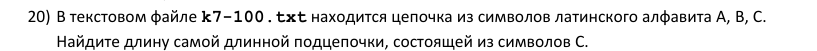

<details><summary>Текст условия</summary>В текстовом файле k7-100.txt находится цепочка из символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C.</details>

**Способ 1:** однопроходный алгоритм (счётчик текущей цепочки)

In [40]:
s = open('k7-100.txt').readline().strip()
k = mx = 0
for c in s:
    if c == 'C':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

732


**Способ 2 (проверка):** регулярное выражение

In [41]:
from re import findall
s = open('k7-100.txt').readline().strip()
print(max(map(len, findall('C+', s)), default=0))

732


**Ответ: `732`**

## Цепочки из набора символов / без символов

**Метод замен.** Все «нужные» символы заменяем на `*` (через `re.sub('[ABC]', '*', s)`), и задача сводится к
самой длинной цепочке звёздочек. Если нужна цепочка **без** символа `D`, то просто режем строку: `s.split('D')`
и берём самый длинный кусок. Несколько запрещённых символов сначала заменяем на один (`s.replace('F', 'C')`).

### Задача 21

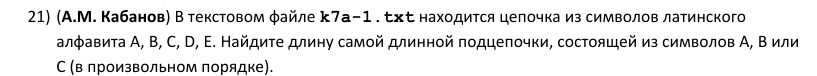

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7a-1.txt находится цепочка из символов латинского алфавита A, B, C, D, E. Найдите длину самой длинной подцепочки, состоящей из символов A, B или C (в произвольном порядке).</details>

**Способ 1:** замена через re.sub + groupby

In [42]:
from itertools import groupby
from re import sub
s = open('k7a-1.txt').readline().strip()
s = sub('[ABC]', '*', s)
print(max(len(list(g)) for c, g in groupby(s) if c == '*'))

16


**Способ 2 (проверка):** регулярное выражение

In [43]:
from re import findall
s = open('k7a-1.txt').readline().strip()
print(max(map(len, findall('[ABC]+', s))))

16


**Ответ: `16`**

### Задача 22

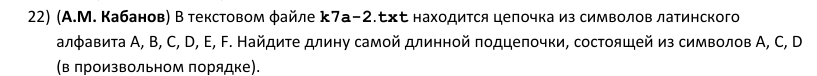

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7a-2.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите длину самой длинной подцепочки, состоящей из символов A, C, D (в произвольном порядке).</details>

**Способ 1:** замена через re.sub + groupby

In [44]:
from itertools import groupby
from re import sub
s = open('k7a-2.txt').readline().strip()
s = sub('[ACD]', '*', s)
print(max(len(list(g)) for c, g in groupby(s) if c == '*'))

11


**Способ 2 (проверка):** однопроходный алгоритм

In [45]:
s = open('k7a-2.txt').readline().strip()
k = mx = 0
for c in s:
    if c in 'ACD':
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

11


**Ответ: `11`**

*Задача 23 — подобная предыдущим, пропущена.*

### Задача 24

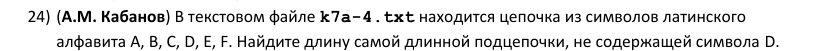

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7a-4.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите длину самой длинной подцепочки, не содержащей символа D.</details>

**Способ 1:** split по запрещённому символу

In [46]:
s = open('k7a-4.txt').readline().strip()
print(len(max(s.split('D'), key=len)))

44


**Способ 2 (проверка):** регулярное выражение [^D]+

In [47]:
from re import findall
s = open('k7a-4.txt').readline().strip()
print(max(map(len, findall('[^D]+', s))))

44


**Ответ: `44`**

### Задача 25

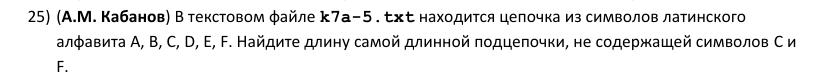

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7a-5.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите длину самой длинной подцепочки, не содержащей символов C и F.</details>

**Способ 1:** замена + split

In [48]:
s = open('k7a-5.txt').readline().strip()
s = s.replace('F', 'C')
print(len(max(s.split('C'), key=len)))

19


**Способ 2 (проверка):** регулярное выражение

In [49]:
from re import findall
s = open('k7a-5.txt').readline().strip()
print(max(map(len, findall('[^CF]+', s))))

19


**Ответ: `19`**

*Задача 26 — подобная предыдущим, пропущена.*

## Цепочки из повторяющегося фрагмента (последний может быть неполным)

**Однопроходный алгоритм с «ожидаемым символом».** Пусть `p = 'EAB'`, `k` — длина текущей правильной цепочки.
Следующий символ цепочки должен быть `p[k % len(p)]`. Совпал — `k += 1`; не совпал — цепочка рвётся,
но новый символ может сам начать цепочку: `k = 1`, если он равен `p[0]`, иначе `k = 0`.
По сути это **конечный автомат**, где состояние — `k % len(p)`.

Проверка — регулярным выражением: `(?:EAB)*(?:EA|E)?` (целые фрагменты + неполный хвост).

### Задача 27

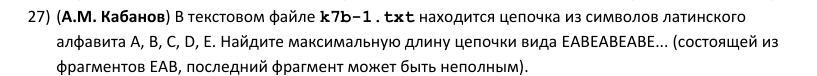

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7b-1.txt находится цепочка из символов латинского алфавита A, B, C, D, E. Найдите максимальную длину цепочки вида EABEABEABE... (состоящей из фрагментов EAB, последний фрагмент может быть неполным).</details>

**Способ 1:** однопроходный алгоритм (конечный автомат)

In [50]:
s = open('k7b-1.txt').readline().strip()
p = 'EAB'
k = mx = 0
for c in s:
    if c == p[k % len(p)]:
        k += 1
    elif c == p[0]:
        k = 1
    else:
        k = 0
    mx = max(mx, k)
print(mx)

7


**Способ 2 (проверка):** регулярное выражение

In [51]:
from re import findall
s = open('k7b-1.txt').readline().strip()
print(max(map(len, findall('(?:EAB)*(?:EA|E)?', s))))

7


**Ответ: `7`**

### Задача 28

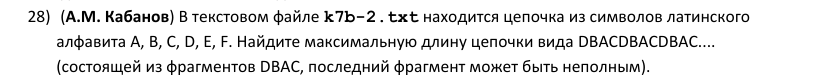

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7b-2.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите максимальную длину цепочки вида DBACDBACDBAC.... (состоящей из фрагментов DBAC, последний фрагмент может быть неполным).</details>

**Способ 1:** однопроходный алгоритм (конечный автомат)

In [52]:
s = open('k7b-2.txt').readline().strip()
p = 'DBAC'
k = mx = 0
for c in s:
    if c == p[k % len(p)]:
        k += 1
    elif c == p[0]:
        k = 1
    else:
        k = 0
    mx = max(mx, k)
print(mx)

95


**Способ 2 (проверка):** регулярное выражение

In [53]:
from re import findall
s = open('k7b-2.txt').readline().strip()
print(max(map(len, findall('(?:DBAC)*(?:DBA|DB|D)?', s))))

95


**Ответ: `95`**

*Задача 29 — подобная предыдущим, пропущена.*

### Задача 30

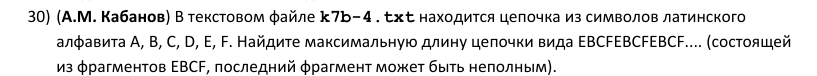

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7b-4.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите максимальную длину цепочки вида EBCFEBCFEBCF.... (состоящей из фрагментов EBCF, последний фрагмент может быть неполным).</details>

**Способ 1:** однопроходный алгоритм (конечный автомат)

In [54]:
s = open('k7b-4.txt').readline().strip()
p = 'EBCF'
k = mx = 0
for c in s:
    if c == p[k % len(p)]:
        k += 1
    elif c == p[0]:
        k = 1
    else:
        k = 0
    mx = max(mx, k)
print(mx)

150


**Способ 2 (проверка):** регулярное выражение

In [55]:
from re import findall
s = open('k7b-4.txt').readline().strip()
print(max(map(len, findall('(?:EBCF)*(?:EBC|EB|E)?', s))))

150


**Ответ: `150`**

### Задача 31

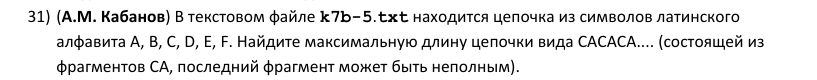

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7b-5.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите максимальную длину цепочки вида CACACA.... (состоящей из фрагментов CA, последний фрагмент может быть неполным).</details>

**Способ 1:** однопроходный алгоритм (конечный автомат)

In [56]:
s = open('k7b-5.txt').readline().strip()
p = 'CA'
k = mx = 0
for c in s:
    if c == p[k % len(p)]:
        k += 1
    elif c == p[0]:
        k = 1
    else:
        k = 0
    mx = max(mx, k)
print(mx)

54


**Способ 2 (проверка):** регулярное выражение

In [57]:
from re import findall
s = open('k7b-5.txt').readline().strip()
print(max(map(len, findall('(?:CA)*(?:C)?', s))))

54


**Ответ: `54`**

*Задача 32 — подобная предыдущим, пропущена.*

## Подсчёт цепочек фиксированной длины по условиям

**Перебор окон.** Цепочка длины 3 начинается в позиции `i` и состоит из `s[i]`, `s[i+1]`, `s[i+2]`.
Перебираем все `i` от 0 до `len(s)-3` и проверяем условие. Удобно писать генератором:
`sum(1 for i in range(len(s)-2) if <условие>)`.

### Задача 33

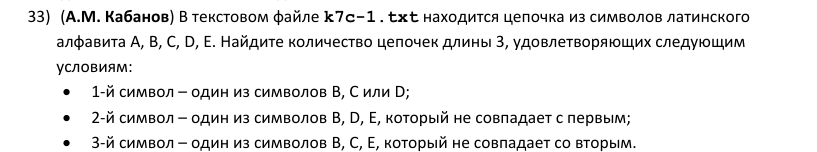

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7c-1.txt находится цепочка из символов латинского алфавита A, B, C, D, E. Найдите количество цепочек длины 3, удовлетворяющих следующим условиям:<br>• 1-й символ – один из символов B, C или D;<br>• 2-й символ – один из символов B, D, E, который не совпадает с первым;<br>• 3-й символ – один из символов B, C, E, который не совпадает со вторым.</details>

**Способ 1:** перебор всех троек

In [58]:
s = open('k7c-1.txt').readline().strip()
k = 0
for i in range(len(s) - 2):
    a, b, c = s[i], s[i+1], s[i+2]
    if a in 'BCD' and b in 'BDE' and b != a and c in 'BCE' and c != b:
        k += 1
print(k)

1280


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [59]:
from re import findall
s = open('k7c-1.txt').readline().strip()
# (?=...) — поиск с каждой позиции, чтобы тройки могли перекрываться
a = findall('(?=([BCD][BDE][BCE]))', s)
print(sum(1 for t in a if t[0] != t[1] and t[1] != t[2]))

1280


**Ответ: `1280`**

### Задача 34

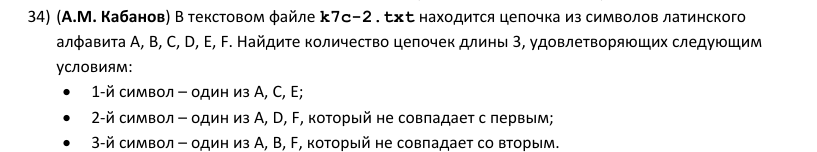

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7c-2.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите количество цепочек длины 3, удовлетворяющих следующим условиям:<br>• 1-й символ – один из A, C, E;<br>• 2-й символ – один из A, D, F, который не совпадает с первым;<br>• 3-й символ – один из A, B, F, который не совпадает со вторым.</details>

**Способ 1:** перебор всех троек

In [60]:
s = open('k7c-2.txt').readline().strip()
k = 0
for i in range(len(s) - 2):
    a, b, c = s[i], s[i+1], s[i+2]
    if a in 'ACE' and b in 'ADF' and b != a and c in 'ABF' and c != b:
        k += 1
print(k)

891


**Способ 2 (проверка):** список срезов

In [61]:
s = open('k7c-2.txt').readline().strip()
t = [s[i:i+3] for i in range(len(s) - 2)]
print(len([x for x in t if x[0] in 'ACE' and x[1] in 'ADF' and x[2] in 'ABF' and x[0] != x[1] != x[2]]))

891


**Ответ: `891`**

*Задача 35 — подобная предыдущим, пропущена.*

### Задача 36

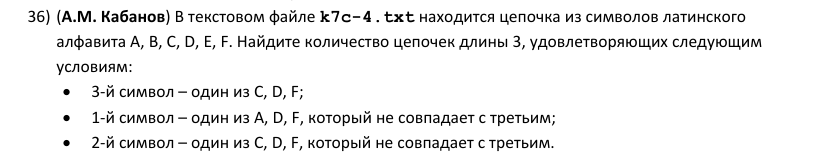

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7c-4.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите количество цепочек длины 3, удовлетворяющих следующим условиям:<br>• 3-й символ – один из C, D, F;<br>• 1-й символ – один из A, D, F, который не совпадает с третьим;<br>• 2-й символ – один из C, D, F, который не совпадает с третьим.</details>

**Способ 1:** перебор всех троек

In [62]:
s = open('k7c-4.txt').readline().strip()
k = 0
for i in range(len(s) - 2):
    a, b, c = s[i], s[i+1], s[i+2]
    if c in 'CDF' and a in 'ADF' and a != c and b in 'CDF' and b != c:
        k += 1
print(k)

660


**Способ 2 (проверка):** список срезов

In [63]:
s = open('k7c-4.txt').readline().strip()
t = [s[i:i+3] for i in range(len(s) - 2)]
print(len([x for x in t if x[2] in 'CDF' and x[0] in 'ADF' and x[1] in 'CDF' and x[0] != x[2] and x[1] != x[2]]))

660


**Ответ: `660`**

### Задача 37

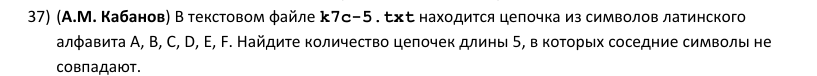

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7c-5.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите количество цепочек длины 5, в которых соседние символы не совпадают.</details>

**Способ 1:** перебор окон длины 5

In [64]:
s = open('k7c-5.txt').readline().strip()
k = 0
for i in range(len(s) - 4):
    w = s[i:i+5]
    if all(w[j] != w[j+1] for j in range(4)):
        k += 1
print(k)

4904


**Способ 2 (проверка):** однопроходный алгоритм

In [65]:
s = open('k7c-5.txt').readline().strip()
# однопроходно: d — длина текущего участка без одинаковых соседей
d = k = 0
for i in range(len(s)):
    d = d + 1 if i > 0 and s[i] != s[i-1] else 1
    if d >= 5:
        k += 1
print(k)

4904


**Ответ: `4904`**

### Задача 38

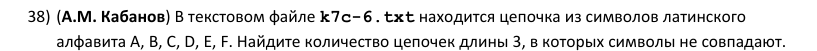

<details><summary>Текст условия</summary>(А.М. Кабанов) В текстовом файле k7c-6.txt находится цепочка из символов латинского алфавита A, B, C, D, E, F. Найдите количество цепочек длины 3, в которых символы не совпадают.</details>

**Способ 1:** перебор троек, set

In [66]:
s = open('k7c-6.txt').readline().strip()
print(sum(1 for i in range(len(s) - 2) if len(set(s[i:i+3])) == 3))

5563


**Способ 2 (проверка):** явная проверка

In [67]:
s = open('k7c-6.txt').readline().strip()
k = 0
for i in range(len(s) - 2):
    if s[i] != s[i+1] and s[i+1] != s[i+2] and s[i] != s[i+2]:
        k += 1
print(k)

5563


**Ответ: `5563`**

## Задачи Б.С. Михлина: C-подцепочки

**groupby / findall.** Список всех C-подцепочек проще всего получить так: `a = re.findall('C+', s)`.
Дальше — обычная работа со списком: `len(a)`, `min(map(len, a))`, нумерация через `enumerate`.
Для замен с сохранением порядка удобно `re.sub('C+', функция, s)` — функция получает каждое совпадение
и возвращает строку-замену.

### Задача 39

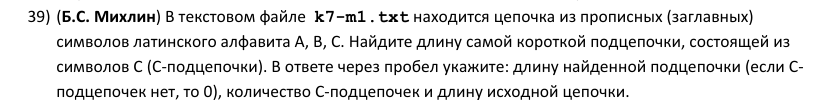

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле  k7-m1.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C. Найдите длину самой короткой подцепочки, состоящей из символов C (C-подцепочки). В ответе через пробел укажите: длину найденной подцепочки (если C-подцепочек нет, то 0), количество C-подцепочек и длину исходной цепочки.</details>

**Способ 1:** findall + min

In [68]:
from re import findall
s = open('k7-m1.txt').readline().strip()
a = findall('C+', s)
print(min(map(len, a)) if a else 0, len(a), len(s))

5 6 126


**Способ 2 (проверка):** groupby

In [69]:
from itertools import groupby
s = open('k7-m1.txt').readline().strip()
a = [len(list(g)) for c, g in groupby(s) if c == 'C']
print(min(a, default=0), len(a), len(s))

5 6 126


**Ответ: `5 6 126`**

### Задача 40

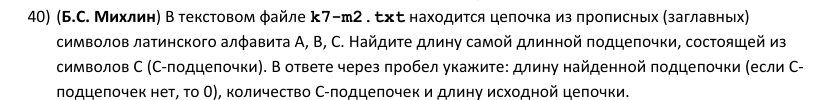

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m2.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C. Найдите длину самой длинной подцепочки, состоящей из символов C (C-подцепочки). В ответе через пробел укажите: длину найденной подцепочки (если C-подцепочек нет, то 0), количество C-подцепочек и длину исходной цепочки.</details>

**Способ 1:** findall + max

In [70]:
from re import findall
s = open('k7-m2.txt').readline().strip()
a = findall('C+', s)
print(max(map(len, a)) if a else 0, len(a), len(s))

14 9 179


**Способ 2 (проверка):** groupby

In [71]:
from itertools import groupby
s = open('k7-m2.txt').readline().strip()
a = [len(list(g)) for c, g in groupby(s) if c == 'C']
print(max(a, default=0), len(a), len(s))

14 9 179


**Ответ: `14 9 179`**

### Задача 41

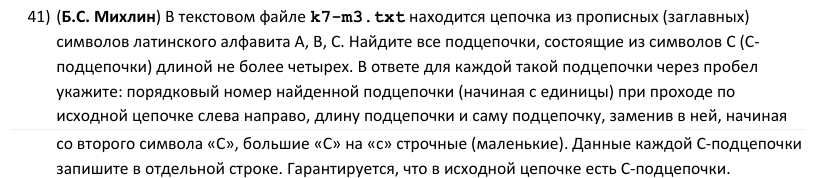

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m3.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C. Найдите все подцепочки, состоящие из символов C (C-подцепочки) длиной не более четырех. В ответе для каждой такой подцепочки через пробел укажите: порядковый номер найденной подцепочки (начиная с единицы) при проходе по исходной цепочке слева направо, длину подцепочки и саму подцепочку, заменив в ней, начиная со второго символа «С», большие «С» на «с» строчные (маленькие). Данные каждой С-подцепочки запишите в отдельной строке. Гарантируется, что в исходной цепочке есть C-подцепочки.</details>

**Способ 1:** findall + enumerate

In [72]:
from re import findall
s = open('k7-m3.txt').readline().strip()
a = [x for x in findall('C+', s) if len(x) <= 4]
for i, x in enumerate(a, 1):
    print(i, len(x), 'C' + 'c' * (len(x) - 1))

1 4 Cccc
2 3 Ccc
3 1 C
4 2 Cc


**Способ 2 (проверка):** groupby

In [73]:
from itertools import groupby
s = open('k7-m3.txt').readline().strip()
i = 0
for c, g in groupby(s):
    L = len(list(g))
    if c == 'C' and L <= 4:
        i += 1
        print(i, L, 'C' + 'c' * (L - 1))

1 4 Cccc
2 3 Ccc
3 1 C
4 2 Cc


**Ответ:**
```
1 4 Cccc
2 3 Ccc
3 1 C
4 2 Cc
```

> Нумерация — среди найденных подцепочек (длиной не более 4).

### Задача 42

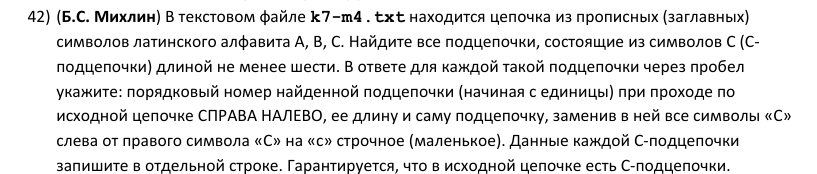

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m4.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C. Найдите все подцепочки, состоящие из символов C (C-подцепочки) длиной не менее шести. В ответе для каждой такой подцепочки через пробел укажите: порядковый номер найденной подцепочки (начиная с единицы) при проходе по исходной цепочке СПРАВА НАЛЕВО, ее длину и саму подцепочку, заменив в ней все символы «С» слева от правого символа «С» на «с» строчное (маленькое). Данные каждой С-подцепочки запишите в отдельной строке. Гарантируется, что в исходной цепочке есть C-подцепочки.</details>

**Способ 1:** findall, проход справа налево

In [74]:
from re import findall
s = open('k7-m4.txt').readline().strip()
a = [x for x in findall('C+', s) if len(x) >= 6]
for i, x in enumerate(a[::-1], 1):
    print(i, len(x), 'c' * (len(x) - 1) + 'C')

1 9 ccccccccC
2 8 cccccccC
3 8 cccccccC
4 6 cccccC
5 7 ccccccC
6 8 cccccccC


**Способ 2 (проверка):** groupby по перевёрнутой строке

In [75]:
from itertools import groupby
s = open('k7-m4.txt').readline().strip()
i = 0
for c, g in groupby(s[::-1]):
    L = len(list(g))
    if c == 'C' and L >= 6:
        i += 1
        print(i, L, 'c' * (L - 1) + 'C')

1 9 ccccccccC
2 8 cccccccC
3 8 cccccccC
4 6 cccccC
5 7 ccccccC
6 8 cccccccC


**Ответ:**
```
1 9 ccccccccC
2 8 cccccccC
3 8 cccccccC
4 6 cccccC
5 7 ccccccC
6 8 cccccccC
```

### Задача 43

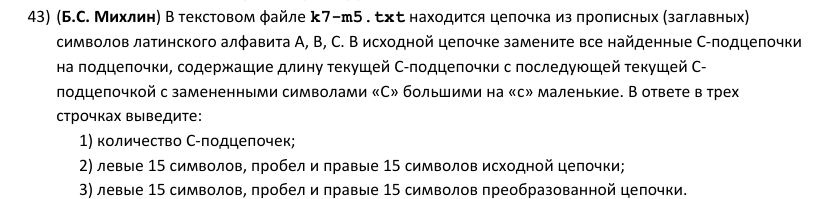

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m5.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C. В исходной цепочке замените все найденные C-подцепочки на подцепочки, содержащие длину текущей С-подцепочки с последующей текущей C-подцепочкой с замененными символами «С» большими на «с» маленькие. В ответе в трех строчках выведите:<br>1) количество C-подцепочек;<br>2) левые 15 символов, пробел и правые 15 символов исходной цепочки;<br>3) левые 15 символов, пробел и правые 15 символов преобразованной цепочки.</details>

**Способ 1:** re.sub с функцией

In [76]:
from re import findall, sub
s = open('k7-m5.txt').readline().strip()
t = sub('C+', lambda m: str(len(m.group())) + m.group().lower(), s)
print(len(findall('C+', s)))
print(s[:15], s[-15:])
print(t[:15], t[-15:])

18
AAACCAAABBBCBBB BBBCCCCCCABCCCC
AAA2ccAAABBB1cB B6ccccccAB4cccc


**Способ 2 (проверка):** groupby + сборка строки

In [77]:
from itertools import groupby
s = open('k7-m5.txt').readline().strip()
t = ''
k = 0
for c, g in groupby(s):
    x = ''.join(g)
    if c == 'C':
        k += 1
        t += str(len(x)) + x.lower()
    else:
        t += x
print(k)
print(s[:15], s[-15:])
print(t[:15], t[-15:])

18
AAACCAAABBBCBBB BBBCCCCCCABCCCC
AAA2ccAAABBB1cB B6ccccccAB4cccc


**Ответ:**
```
18
AAACCAAABBBCBBB BBBCCCCCCABCCCC
AAA2ccAAABBB1cB B6ccccccAB4cccc
```

### Задача 44

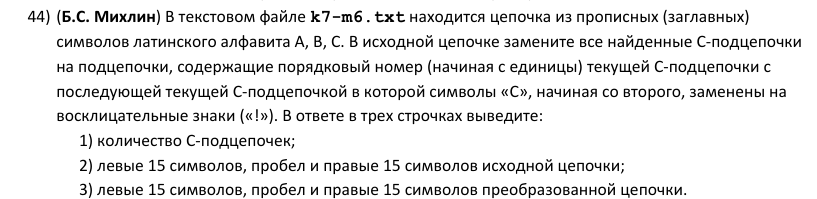

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m6.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C. В исходной цепочке замените все найденные C-подцепочки на подцепочки, содержащие порядковый номер (начиная с единицы) текущей С-подцепочки с последующей текущей C-подцепочкой в которой символы «С», начиная со второго, заменены на восклицательные знаки («!»). В ответе в трех строчках выведите:<br>1) количество C-подцепочек;<br>2) левые 15 символов, пробел и правые 15 символов исходной цепочки;<br>3) левые 15 символов, пробел и правые 15 символов преобразованной цепочки.</details>

**Способ 1:** re.sub с функцией и счётчиком

In [78]:
from re import sub
s = open('k7-m6.txt').readline().strip()
num = 0
def rep(m):
    global num
    num += 1
    return str(num) + 'C' + '!' * (len(m.group()) - 1)
t = sub('C+', rep, s)
print(num)
print(s[:15], s[-15:])
print(t[:15], t[-15:])

17
AAACCAAABBBCBBB AABBBBBBCCCABCC
AAA1C!AAABBB2CB BBBB16C!!AB17C!


**Способ 2 (проверка):** groupby + сборка строки

In [79]:
from itertools import groupby
s = open('k7-m6.txt').readline().strip()
t = ''
k = 0
for c, g in groupby(s):
    x = ''.join(g)
    if c == 'C':
        k += 1
        t += str(k) + 'C' + '!' * (len(x) - 1)
    else:
        t += x
print(k)
print(s[:15], s[-15:])
print(t[:15], t[-15:])

17
AAACCAAABBBCBBB AABBBBBBCCCABCC
AAA1C!AAABBB2CB BBBB16C!!AB17C!


**Ответ:**
```
17
AAACCAAABBBCBBB AABBBBBBCCCABCC
AAA1C!AAABBB2CB BBBB16C!!AB17C!
```

*Задача 45 — подобная предыдущим, пропущена.*

## Тройки символов в алфавитном порядке (Б.С. Михлин)

Перебираем все `i` и сравниваем символы как строки: в Python `'A' < 'B'` — сравнение по коду символа,
а цепочку сравнений можно писать сразу: `s[i] < s[i+1] < s[i+2]`. Индексы подходящих троек собираем в список —
тогда ответ это `len(a)` и `a[-1]`.

### Задача 46

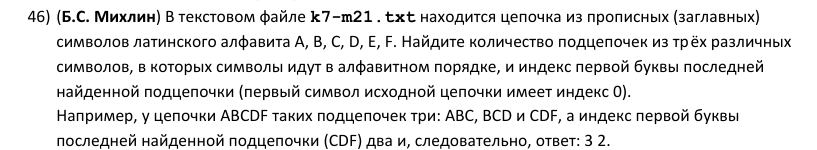

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m21.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C, D, E, F. Найдите количество подцепочек из тр	ёх различных символов, в которых символы идут в алфавитном порядке, и индекс первой буквы последней найденной подцепочки (первый символ исходной цепочки имеет индекс 0).<br>Например, у цепочки ABCDF таких подцепочек три: ABC, BCD и CDF, а индекс первой буквы последней найденной подцепочки (CDF) два и, следовательно, ответ: 3 2.</details>

**Способ 1:** перебор троек, цепочка сравнений

In [80]:
s = open('k7-m21.txt').readline().strip()
a = [i for i in range(len(s) - 2) if s[i] < s[i+1] < s[i+2]]
print(len(a), a[-1])

12 129


**Способ 2 (проверка):** через срез и sorted

In [81]:
s = open('k7-m21.txt').readline().strip()
k = last = 0
for i in range(len(s) - 2):
    a = s[i:i+3]
    if a == ''.join(sorted(a)) and len(set(a)) == 3:
        k += 1
        last = i
print(k, last)

12 129


**Ответ: `12 129`**

### Задача 47

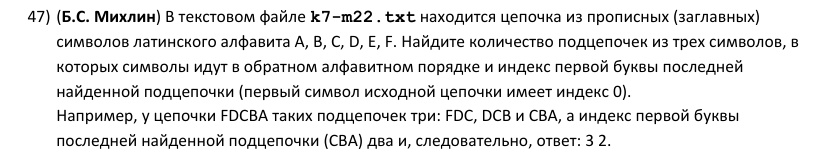

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m22.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C, D, E, F. Найдите количество подцепочек из трех символов, в которых символы идут в обратном алфавитном порядке и индекс первой буквы последней найденной подцепочки (первый символ исходной цепочки имеет индекс 0).<br>Например, у цепочки FDCBA таких подцепочек три: FDC, DCB и CBA, а индекс первой буквы последней найденной подцепочки (CBA) два и, следовательно, ответ: 3 2.</details>

**Способ 1:** перебор троек, цепочка сравнений

In [82]:
s = open('k7-m22.txt').readline().strip()
a = [i for i in range(len(s) - 2) if s[i] > s[i+1] > s[i+2]]
print(len(a), a[-1])

18 145


**Способ 2 (проверка):** через срез и sorted

In [83]:
s = open('k7-m22.txt').readline().strip()
k = last = 0
for i in range(len(s) - 2):
    a = s[i:i+3]
    if a == ''.join(sorted(a))[::-1] and len(set(a)) == 3:
        k += 1
        last = i
print(k, last)

18 145


**Ответ: `18 145`**

*Задача 48 — подобная предыдущим, пропущена.*

### Задача 49

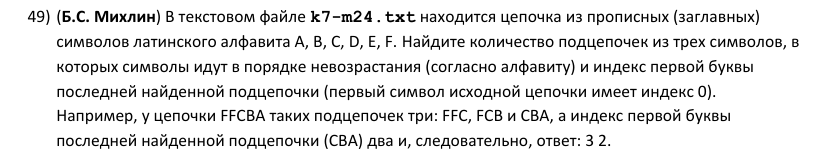

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m24.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C, D, E, F. Найдите количество подцепочек из трех символов, в которых символы идут в порядке невозрастания (согласно алфавиту) и индекс первой буквы последней найденной подцепочки (первый символ исходной цепочки имеет индекс 0).<br>Например, у цепочки FFCBA таких подцепочек три: FFC, FCB и CBA, а индекс первой буквы последней найденной подцепочки (CBA) два и, следовательно, ответ: 3 2.</details>

**Способ 1:** перебор троек, цепочка сравнений

In [84]:
s = open('k7-m24.txt').readline().strip()
a = [i for i in range(len(s) - 2) if s[i] >= s[i+1] >= s[i+2]]
print(len(a), a[-1])

62 155


**Способ 2 (проверка):** через срез и sorted

In [85]:
s = open('k7-m24.txt').readline().strip()
k = last = 0
for i in range(len(s) - 2):
    a = s[i:i+3]
    if a == ''.join(sorted(a, reverse=True)):
        k += 1
        last = i
print(k, last)

62 155


**Ответ: `62 155`**

### Задача 50

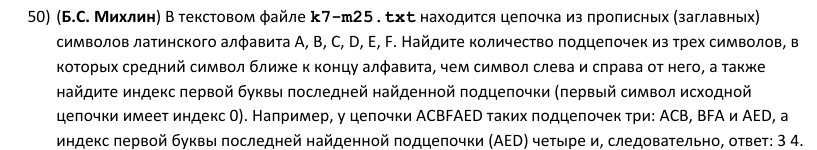

<details><summary>Текст условия</summary>(Б.С. Михлин) В текстовом файле k7-m25.txt находится цепочка из прописных (заглавных) символов латинского алфавита A, B, C, D, E, F. Найдите количество подцепочек из трех символов, в которых средний символ ближе к концу алфавита, чем символ слева и справа от него, а также найдите индекс первой буквы последней найденной подцепочки (первый символ исходной цепочки имеет индекс 0). Например, у цепочки ACBFAED таких подцепочек три: ACB, BFA и AED, а индекс первой буквы последней найденной подцепочки (AED) четыре и, следовательно, ответ: 3 4.</details>

**Способ 1:** перебор троек, цепочка сравнений

In [86]:
s = open('k7-m25.txt').readline().strip()
a = [i for i in range(len(s) - 2) if s[i] < s[i+1] > s[i+2]]
print(len(a), a[-1])

19 156


**Способ 2 (проверка):** через срез и sorted

In [87]:
s = open('k7-m25.txt').readline().strip()
k = last = 0
for i in range(len(s) - 2):
    a = s[i:i+3]
    if a[1] == max(a) and a[1] != a[0] and a[1] != a[2]:
        k += 1
        last = i
print(k, last)

19 156


**Ответ: `19 156`**

*Задача 51 — подобная предыдущим, пропущена.*

## Самая длинная цепочка одинаковых символов (любых)

**groupby** даёт пары `(символ, группа)` для каждого участка одинаковых символов. Превращаем в список
`(символ, длина)` и ищем максимум по длине. `max` с `key` возвращает **первый** максимальный элемент —
ровно то, что нужно при «если несколько, взять первую».

Однопроходный вариант: сравниваем `s[i]` с `s[i-1]`, при совпадении `k += 1`, иначе `k = 1`;
обновляем ответ только при **строгом** `k > mx`, чтобы запоминалась первая цепочка.

### Задача 52

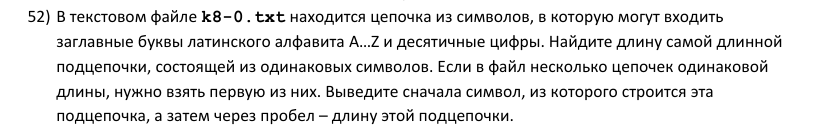

<details><summary>Текст условия</summary>В текстовом файле k8-0.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файл несколько цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [88]:
from itertools import groupby
s = open('k8-0.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

2 3


**Способ 2 (проверка):** однопроходный алгоритм

In [89]:
s = open('k8-0.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

2 3


**Ответ: `2 3`**

### Задача 53

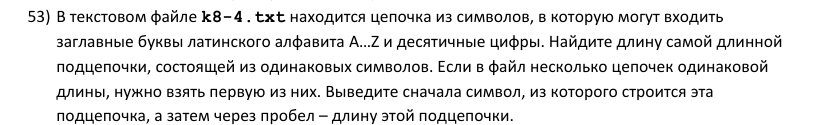

<details><summary>Текст условия</summary>В текстовом файле k8-4.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файл несколько цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [90]:
from itertools import groupby
s = open('k8-4.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

W 4


**Способ 2 (проверка):** однопроходный алгоритм

In [91]:
s = open('k8-4.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

W 4


**Ответ: `W 4`**

*Задача 54 — подобная предыдущим, пропущена.*

### Задача 55

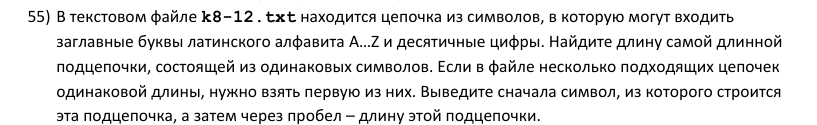

<details><summary>Текст условия</summary>В текстовом файле k8-12.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [92]:
from itertools import groupby
s = open('k8-12.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

S 6


**Способ 2 (проверка):** однопроходный алгоритм

In [93]:
s = open('k8-12.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

S 6


**Ответ: `S 6`**

### Задача 56

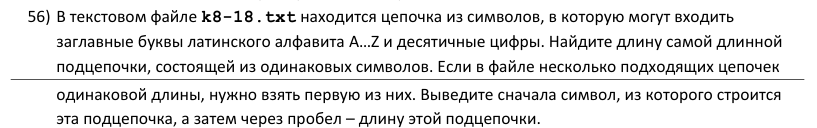

<details><summary>Текст условия</summary>В текстовом файле k8-18.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [94]:
from itertools import groupby
s = open('k8-18.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

K 7


**Способ 2 (проверка):** однопроходный алгоритм

In [95]:
s = open('k8-18.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

K 7


**Ответ: `K 7`**

*Задача 57 — подобная предыдущим, пропущена.*

### Задача 58

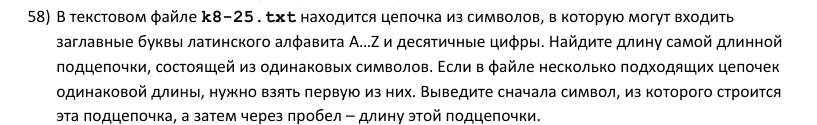

<details><summary>Текст условия</summary>В текстовом файле k8-25.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [96]:
from itertools import groupby
s = open('k8-25.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

V 8


**Способ 2 (проверка):** однопроходный алгоритм

In [97]:
s = open('k8-25.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

V 8


**Ответ: `V 8`**

### Задача 59

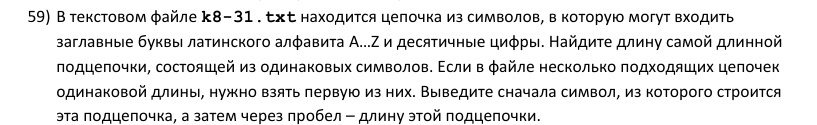

<details><summary>Текст условия</summary>В текстовом файле k8-31.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [98]:
from itertools import groupby
s = open('k8-31.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

1 9


**Способ 2 (проверка):** однопроходный алгоритм

In [99]:
s = open('k8-31.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

1 9


**Ответ: `1 9`**

*Задача 60 — подобная предыдущим, пропущена.*

### Задача 61

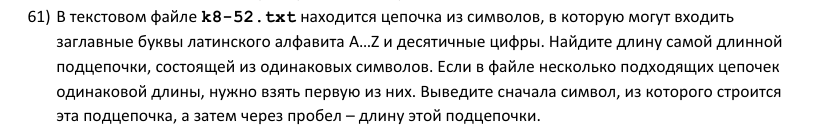

<details><summary>Текст условия</summary>В текстовом файле k8-52.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [100]:
from itertools import groupby
s = open('k8-52.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

0 14


**Способ 2 (проверка):** однопроходный алгоритм

In [101]:
s = open('k8-52.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

0 14


**Ответ: `0 14`**

### Задача 62

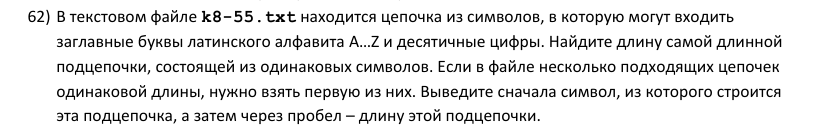

<details><summary>Текст условия</summary>В текстовом файле k8-55.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [102]:
from itertools import groupby
s = open('k8-55.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

O 13


**Способ 2 (проверка):** однопроходный алгоритм

In [103]:
s = open('k8-55.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

O 13


**Ответ: `O 13`**

*Задача 63 — подобная предыдущим, пропущена.*

### Задача 64

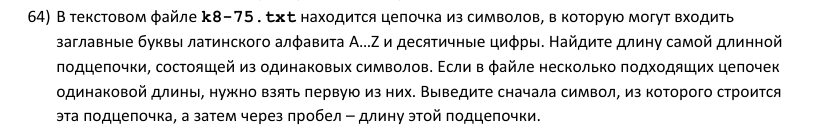

<details><summary>Текст условия</summary>В текстовом файле k8-75.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [104]:
from itertools import groupby
s = open('k8-75.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

V 28


**Способ 2 (проверка):** однопроходный алгоритм

In [105]:
s = open('k8-75.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

V 28


**Ответ: `V 28`**

### Задача 65

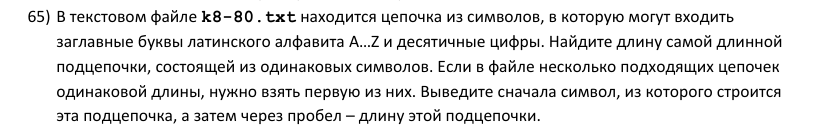

<details><summary>Текст условия</summary>В текстовом файле k8-80.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [106]:
from itertools import groupby
s = open('k8-80.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

Z 41


**Способ 2 (проверка):** однопроходный алгоритм

In [107]:
s = open('k8-80.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

Z 41


**Ответ: `Z 41`**

*Задача 66 — подобная предыдущим, пропущена.*

### Задача 67

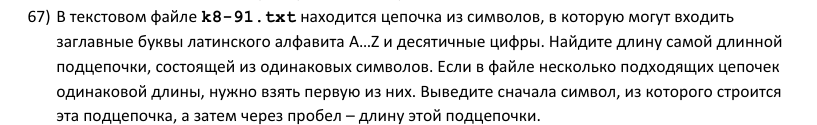

<details><summary>Текст условия</summary>В текстовом файле k8-91.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [108]:
from itertools import groupby
s = open('k8-91.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

O 63


**Способ 2 (проверка):** однопроходный алгоритм

In [109]:
s = open('k8-91.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

O 63


**Ответ: `O 63`**

### Задача 68

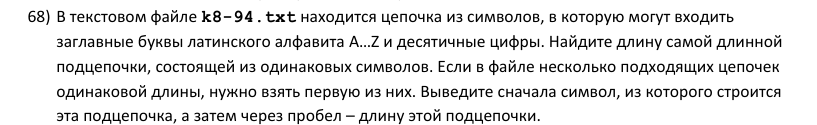

<details><summary>Текст условия</summary>В текстовом файле k8-94.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [110]:
from itertools import groupby
s = open('k8-94.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

7 100


**Способ 2 (проверка):** однопроходный алгоритм

In [111]:
s = open('k8-94.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

7 100


**Ответ: `7 100`**

*Задача 69 — подобная предыдущим, пропущена.*

### Задача 70

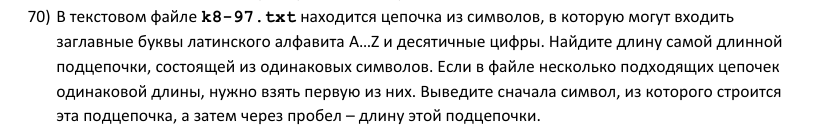

<details><summary>Текст условия</summary>В текстовом файле k8-97.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [112]:
from itertools import groupby
s = open('k8-97.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

S 153


**Способ 2 (проверка):** однопроходный алгоритм

In [113]:
s = open('k8-97.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

S 153


**Ответ: `S 153`**

### Задача 71

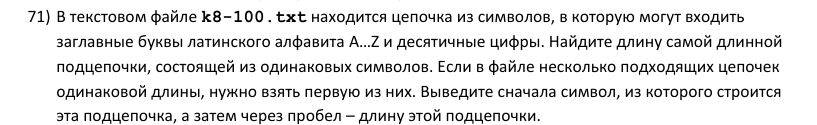

<details><summary>Текст условия</summary>В текстовом файле k8-100.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Если в файле несколько подходящих цепочек одинаковой длины, нужно взять первую из них. Выведите сначала символ, из которого строится эта подцепочка, а затем через пробел – длину этой подцепочки.</details>

**Способ 1:** groupby + max

In [114]:
from itertools import groupby
s = open('k8-100.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
c, L = max(a, key=lambda x: x[1])   # max берёт первый из равных
print(c, L)

S 4500


**Способ 2 (проверка):** однопроходный алгоритм

In [115]:
s = open('k8-100.txt').readline().strip()
k = mx = 1
ch = s[0]
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        k += 1
    else:
        k = 1
    if k > mx:
        mx = k
        ch = s[i]
print(ch, mx)

S 4500


**Ответ: `S 4500`**

### Задача 72

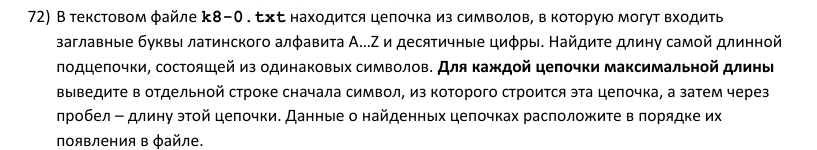

<details><summary>Текст условия</summary>В текстовом файле k8-0.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Для каждой цепочки максимальной длины выведите в отдельной строке сначала символ, из которого строится эта цепочка, а затем через пробел – длину этой цепочки. Данные о найденных цепочках расположите в порядке их появления в файле.</details>

**Способ 1:** groupby + фильтр по максимальной длине

In [116]:
from itertools import groupby
s = open('k8-0.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
mx = max(L for c, L in a)
for c, L in a:
    if L == mx:
        print(c, L)

2 3
7 3
7 3
5 3


**Способ 2 (проверка):** регулярное выражение (.)\1*

In [117]:
from re import finditer
s = open('k8-0.txt').readline().strip()
a = [m.group() for m in finditer(r'(.)\1*', s)]   # \1 — тот же символ, что в группе
mx = max(map(len, a))
for x in a:
    if len(x) == mx:
        print(x[0], mx)

2 3
7 3
7 3
5 3


**Ответ:**
```
2 3
7 3
7 3
5 3
```

### Задача 73

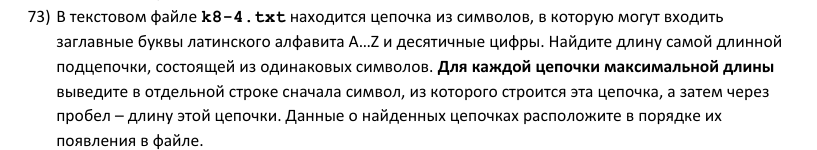

<details><summary>Текст условия</summary>В текстовом файле k8-4.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Для каждой цепочки максимальной длины выведите в отдельной строке сначала символ, из которого строится эта цепочка, а затем через пробел – длину этой цепочки. Данные о найденных цепочках расположите в порядке их появления в файле.</details>

**Способ 1:** groupby + фильтр по максимальной длине

In [118]:
from itertools import groupby
s = open('k8-4.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
mx = max(L for c, L in a)
for c, L in a:
    if L == mx:
        print(c, L)

W 4
0 4
7 4


**Способ 2 (проверка):** регулярное выражение (.)\1*

In [119]:
from re import finditer
s = open('k8-4.txt').readline().strip()
a = [m.group() for m in finditer(r'(.)\1*', s)]   # \1 — тот же символ, что в группе
mx = max(map(len, a))
for x in a:
    if len(x) == mx:
        print(x[0], mx)

W 4
0 4
7 4


**Ответ:**
```
W 4
0 4
7 4
```

*Задача 74 — подобная предыдущим, пропущена.*

### Задача 75

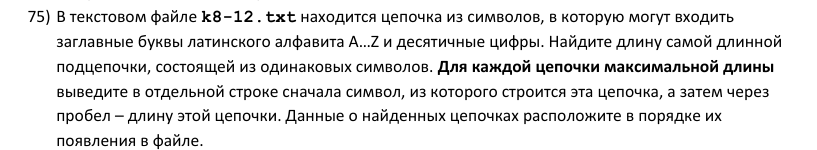

<details><summary>Текст условия</summary>В текстовом файле k8-12.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Для каждой цепочки максимальной длины выведите в отдельной строке сначала символ, из которого строится эта цепочка, а затем через пробел – длину этой цепочки. Данные о найденных цепочках расположите в порядке их появления в файле.</details>

**Способ 1:** groupby + фильтр по максимальной длине

In [120]:
from itertools import groupby
s = open('k8-12.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
mx = max(L for c, L in a)
for c, L in a:
    if L == mx:
        print(c, L)

S 6
P 6
C 6


**Способ 2 (проверка):** регулярное выражение (.)\1*

In [121]:
from re import finditer
s = open('k8-12.txt').readline().strip()
a = [m.group() for m in finditer(r'(.)\1*', s)]   # \1 — тот же символ, что в группе
mx = max(map(len, a))
for x in a:
    if len(x) == mx:
        print(x[0], mx)

S 6
P 6
C 6


**Ответ:**
```
S 6
P 6
C 6
```

### Задача 76

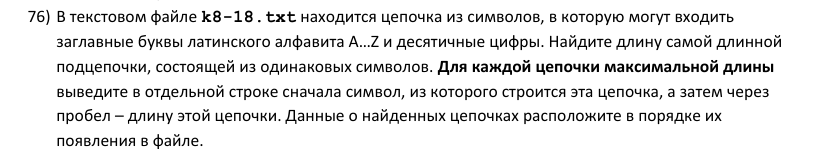

<details><summary>Текст условия</summary>В текстовом файле k8-18.txt находится цепочка из символов, в которую могут входить заглавные буквы латинского алфавита A…Z и десятичные цифры. Найдите длину самой длинной подцепочки, состоящей из одинаковых символов. Для каждой цепочки максимальной длины выведите в отдельной строке сначала символ, из которого строится эта цепочка, а затем через пробел – длину этой цепочки. Данные о найденных цепочках расположите в порядке их появления в файле.</details>

**Способ 1:** groupby + фильтр по максимальной длине

In [122]:
from itertools import groupby
s = open('k8-18.txt').readline().strip()
a = [(c, len(list(g))) for c, g in groupby(s)]
mx = max(L for c, L in a)
for c, L in a:
    if L == mx:
        print(c, L)

K 7
5 7
N 7
Q 7


**Способ 2 (проверка):** регулярное выражение (.)\1*

In [123]:
from re import finditer
s = open('k8-18.txt').readline().strip()
a = [m.group() for m in finditer(r'(.)\1*', s)]   # \1 — тот же символ, что в группе
mx = max(map(len, a))
for x in a:
    if len(x) == mx:
        print(x[0], mx)

K 7
5 7
N 7
Q 7


**Ответ:**
```
K 7
5 7
N 7
Q 7
```

## Самая длинная цепочка, где соседние символы различны

Однопроходный алгоритм: если `s[i] != s[i-1]`, цепочка продолжается (`k += 1`), иначе новая цепочка
начинается с текущего символа (`k = 1`, а не 0!).

Метод замен: вставим пробел между каждой парой одинаковых соседей — тогда `split()` выдаст ровно
правильные куски. Для пар из одинаковых символов удобно `re.sub(r'(.)(?=\1)', r'\1 ', s)`.

### Задача 77

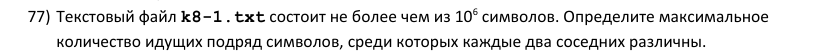

<details><summary>Текст условия</summary>Текстовый файл k8-1.txt состоит не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых каждые два соседних различны.</details>

**Способ 1:** однопроходный алгоритм

In [124]:
s = open('k8-1.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i] != s[i-1]:
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

159


**Способ 2 (проверка):** метод замен + split

In [125]:
from re import sub
s = open('k8-1.txt').readline().strip()
s = sub(r'(.)(?=\1)', r'\1 ', s)   # пробел между одинаковыми соседями
print(len(max(s.split(), key=len)))

159


**Ответ: `159`**

### Задача 78

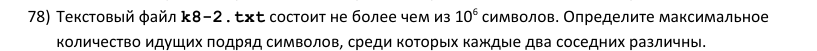

<details><summary>Текст условия</summary>Текстовый файл k8-2.txt состоит не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых каждые два соседних различны.</details>

**Способ 1:** однопроходный алгоритм

In [126]:
s = open('k8-2.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i] != s[i-1]:
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

166


**Способ 2 (проверка):** метод замен + split

In [127]:
from re import sub
s = open('k8-2.txt').readline().strip()
s = sub(r'(.)(?=\1)', r'\1 ', s)   # пробел между одинаковыми соседями
print(len(max(s.split(), key=len)))

166


**Ответ: `166`**

*Задача 79 — подобная предыдущим, пропущена.*

### Задача 80

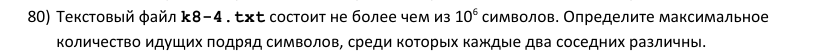

<details><summary>Текст условия</summary>Текстовый файл k8-4.txt состоит не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых каждые два соседних различны.</details>

**Способ 1:** однопроходный алгоритм

In [128]:
s = open('k8-4.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i] != s[i-1]:
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

82


**Способ 2 (проверка):** метод замен + split

In [129]:
from re import sub
s = open('k8-4.txt').readline().strip()
s = sub(r'(.)(?=\1)', r'\1 ', s)   # пробел между одинаковыми соседями
print(len(max(s.split(), key=len)))

82


**Ответ: `82`**

### Задача 81

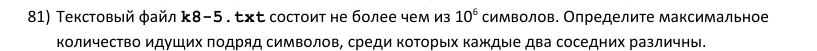

<details><summary>Текст условия</summary>Текстовый файл k8-5.txt состоит не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых каждые два соседних различны.</details>

**Способ 1:** однопроходный алгоритм

In [130]:
s = open('k8-5.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i] != s[i-1]:
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

74


**Способ 2 (проверка):** метод замен + split

In [131]:
from re import sub
s = open('k8-5.txt').readline().strip()
s = sub(r'(.)(?=\1)', r'\1 ', s)   # пробел между одинаковыми соседями
print(len(max(s.split(), key=len)))

74


**Ответ: `74`**

*Задача 82 — подобная предыдущим, пропущена.*

### Задача 83

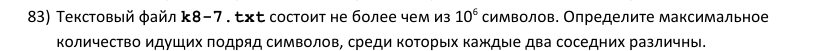

<details><summary>Текст условия</summary>Текстовый файл k8-7.txt состоит не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых каждые два соседних различны.</details>

**Способ 1:** однопроходный алгоритм

In [132]:
s = open('k8-7.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i] != s[i-1]:
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

124


**Способ 2 (проверка):** метод замен + split

In [133]:
from re import sub
s = open('k8-7.txt').readline().strip()
s = sub(r'(.)(?=\1)', r'\1 ', s)   # пробел между одинаковыми соседями
print(len(max(s.split(), key=len)))

124


**Ответ: `124`**

### Задача 84

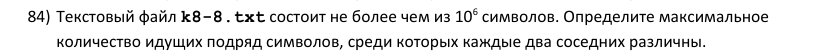

<details><summary>Текст условия</summary>Текстовый файл k8-8.txt состоит не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых каждые два соседних различны.</details>

**Способ 1:** однопроходный алгоритм

In [134]:
s = open('k8-8.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i] != s[i-1]:
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

65


**Способ 2 (проверка):** метод замен + split

In [135]:
from re import sub
s = open('k8-8.txt').readline().strip()
s = sub(r'(.)(?=\1)', r'\1 ', s)   # пробел между одинаковыми соседями
print(len(max(s.split(), key=len)))

65


**Ответ: `65`**

*Задача 85 — подобная предыдущим, пропущена.*

### Задача 86

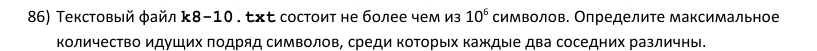

<details><summary>Текст условия</summary>Текстовый файл k8-10.txt состоит не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых каждые два соседних различны.</details>

**Способ 1:** однопроходный алгоритм

In [136]:
s = open('k8-10.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i] != s[i-1]:
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

54


**Способ 2 (проверка):** метод замен + split

In [137]:
from re import sub
s = open('k8-10.txt').readline().strip()
s = sub(r'(.)(?=\1)', r'\1 ', s)   # пробел между одинаковыми соседями
print(len(max(s.split(), key=len)))

54


**Ответ: `54`**

## Числа в строке

**Выделение чисел.** Число — это максимальная цепочка цифр. Самый короткий способ — регулярное выражение:
`re.findall(r'\d+', s)` (`\d` — любая цифра, `+` — одна или больше). Другой способ — **метод замен**:
`re.sub(r'\D', ' ', s).split()` (`\D` — любой НЕ-цифровой символ).
Числа могут быть очень длинными — в Python `int` это не проблема.

### Задача 87

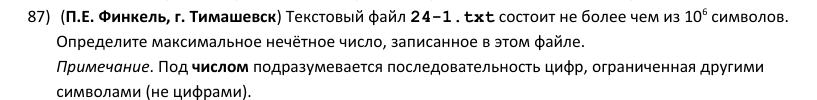

<details><summary>Текст условия</summary>(П.Е. Финкель, г. Тимашевск) Текстовый файл 24-1.txt состоит не более чем из 10⁶ символов. Определите максимальное нечётное число, записанное в этом файле.<br>Примечание. Под числом подразумевается последовательность цифр, ограниченная другими символами (не цифрами).</details>

**Способ 1:** findall + фильтр

In [138]:
from re import findall
s = open('24-1.txt').readline().strip()
a = [int(x) for x in findall(r'\d+', s)]
print(max(x for x in a if x % 2 == 1))

7642289


**Способ 2 (проверка):** метод замен + split

In [139]:
from re import sub
s = open('24-1.txt').readline().strip()
a = sub(r'\D', ' ', s).split()
print(max(int(x) for x in a if x[-1] in '13579'))

7642289


**Ответ: `7642289`**

### Задача 88

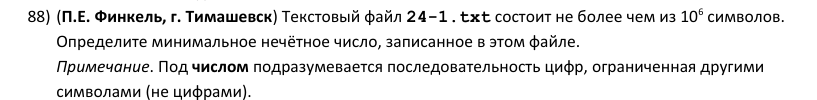

<details><summary>Текст условия</summary>(П.Е. Финкель, г. Тимашевск) Текстовый файл 24-1.txt состоит не более чем из 10⁶ символов. Определите минимальное нечётное число, записанное в этом файле.<br>Примечание. Под числом подразумевается последовательность цифр, ограниченная другими символами (не цифрами).</details>

**Способ 1:** findall + фильтр

In [140]:
from re import findall
s = open('24-1.txt').readline().strip()
a = [int(x) for x in findall(r'\d+', s)]
print(min(x for x in a if x % 2 == 1))

123


**Способ 2 (проверка):** метод замен + split

In [141]:
from re import sub
s = open('24-1.txt').readline().strip()
a = sub(r'\D', ' ', s).split()
print(min(int(x) for x in a if x[-1] in '13579'))

123


**Ответ: `123`**

*Задача 89 — подобная предыдущим, пропущена.*

### Задача 90

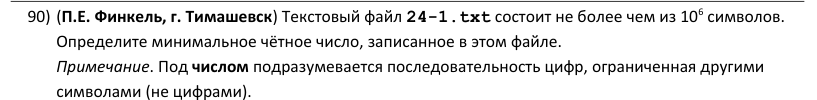

<details><summary>Текст условия</summary>(П.Е. Финкель, г. Тимашевск) Текстовый файл 24-1.txt состоит не более чем из 10⁶ символов. Определите минимальное чётное число, записанное в этом файле.<br>Примечание. Под числом подразумевается последовательность цифр, ограниченная другими символами (не цифрами).</details>

**Способ 1:** findall + фильтр

In [142]:
from re import findall
s = open('24-1.txt').readline().strip()
a = [int(x) for x in findall(r'\d+', s)]
print(min(x for x in a if x % 2 == 0))

888


**Способ 2 (проверка):** метод замен + split

In [143]:
from re import sub
s = open('24-1.txt').readline().strip()
a = sub(r'\D', ' ', s).split()
print(min(int(x) for x in a if x[-1] in '02468'))

888


**Ответ: `888`**

### Задача 91

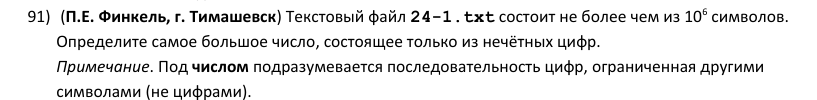

<details><summary>Текст условия</summary>(П.Е. Финкель, г. Тимашевск) Текстовый файл 24-1.txt состоит не более чем из 10⁶ символов. Определите самое большое число, состоящее только из нечётных цифр.<br>Примечание. Под числом подразумевается последовательность цифр, ограниченная другими символами (не цифрами).</details>

**Способ 1:** findall с классом символов

In [144]:
from re import findall
s = open('24-1.txt').readline().strip()
# число целиком из нечётных цифр: слева и справа — не цифры
a = findall(r'(?<!\d)[13579]+(?!\d)', s)
print(max(map(int, a)))

577331


**Способ 2 (проверка):** метод замен + проверка всех цифр

In [145]:
from re import sub
s = open('24-1.txt').readline().strip()
a = sub(r'\D', ' ', s).split()
print(max(int(x) for x in a if all(c in '13579' for c in x)))

577331


**Ответ: `577331`**

*Задача 92 — подобная предыдущим, пропущена.*

## Возрастающие и убывающие подпоследовательности (по коду ASCII)

Символы сравниваются по коду: `'0' < '9' < 'A' < 'Z' < 'a' < 'z'`, поэтому достаточно писать `s[i-1] < s[i]`.

**Однопроходный алгоритм с запоминанием начала.** Держим `start` — индекс начала текущей возрастающей цепочки.
Если `s[i] <= s[i-1]`, цепочка оборвалась, новая начинается в `i`. Длина текущей — `i - start + 1`.
Обновляем ответ при **строгом** `>`, тогда при равных длинах останется первая цепочка.
Зная `start` лучшей цепочки, сразу получаем и саму цепочку `s[start:start+mx]`, и её номер `start + 1`.

> В архиве файл `24.txt` состоит только из букв X, Y, Z (он общий с другой задачей), поэтому для него ответы маленькие.

### Задача 93

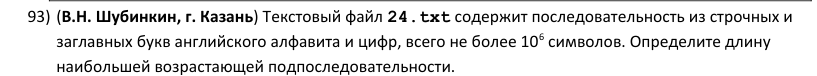

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Определите длину наибольшей возрастающей подпоследовательности.</details>

**Способ 1:** однопроходный алгоритм

In [146]:
s = open('24.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(mx)

3


**Способ 2 (проверка):** список точек разрыва + max

In [147]:
s = open('24.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(L)

3


**Ответ: `3`**

### Задача 94

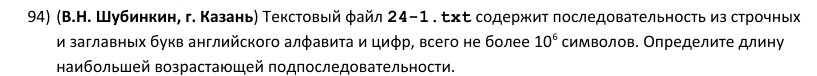

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-1.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Определите длину наибольшей возрастающей подпоследовательности.</details>

**Способ 1:** однопроходный алгоритм

In [148]:
s = open('24-1.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(mx)

7


**Способ 2 (проверка):** список точек разрыва + max

In [149]:
s = open('24-1.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(L)

7


**Ответ: `7`**

*Задача 95 — подобная предыдущим, пропущена.*

### Задача 96

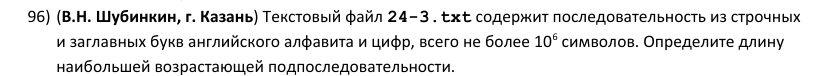

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-3.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Определите длину наибольшей возрастающей подпоследовательности.</details>

**Способ 1:** однопроходный алгоритм

In [150]:
s = open('24-3.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(mx)

7


**Способ 2 (проверка):** список точек разрыва + max

In [151]:
s = open('24-3.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(L)

7


**Ответ: `7`**

### Задача 97

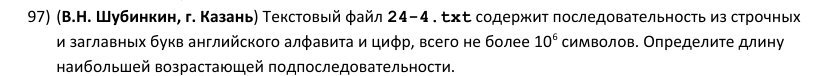

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-4.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Определите длину наибольшей возрастающей подпоследовательности.</details>

**Способ 1:** однопроходный алгоритм

In [152]:
s = open('24-4.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(mx)

6


**Способ 2 (проверка):** список точек разрыва + max

In [153]:
s = open('24-4.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(L)

6


**Ответ: `6`**

### Задача 98

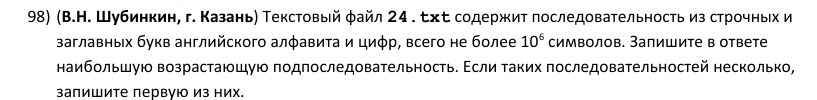

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе наибольшую возрастающую подпоследовательность. Если таких последовательностей несколько, запишите первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [154]:
s = open('24.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(s[best:best + mx])

XYZ


**Способ 2 (проверка):** список точек разрыва + max

In [155]:
s = open('24.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(w)

XYZ


**Ответ: `XYZ`**

### Задача 99

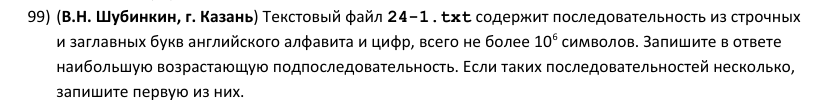

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-1.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе наибольшую возрастающую подпоследовательность. Если таких последовательностей несколько, запишите первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [156]:
s = open('24-1.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(s[best:best + mx])

ADEFWXZ


**Способ 2 (проверка):** список точек разрыва + max

In [157]:
s = open('24-1.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(w)

ADEFWXZ


**Ответ: `ADEFWXZ`**

*Задача 100 — подобная предыдущим, пропущена.*

### Задача 101

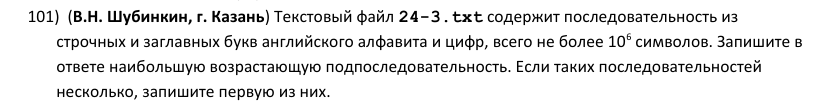

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-3.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе наибольшую возрастающую подпоследовательность. Если таких последовательностей несколько, запишите первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [158]:
s = open('24-3.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(s[best:best + mx])

3TWZfgq


**Способ 2 (проверка):** список точек разрыва + max

In [159]:
s = open('24-3.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(w)

3TWZfgq


**Ответ: `3TWZfgq`**

### Задача 102

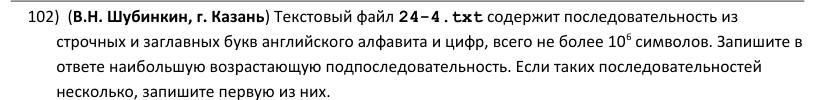

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-4.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе наибольшую возрастающую подпоследовательность. Если таких последовательностей несколько, запишите первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [160]:
s = open('24-4.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(s[best:best + mx])

DLXipu


**Способ 2 (проверка):** список точек разрыва + max

In [161]:
s = open('24-4.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(w)

DLXipu


**Ответ: `DLXipu`**

### Задача 103

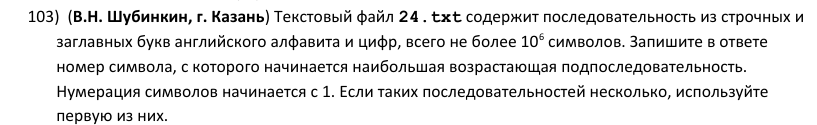

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе номер символа, с которого начинается наибольшая возрастающая подпоследовательность. Нумерация символов начинается с 1. Если таких последовательностей несколько, используйте первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [162]:
s = open('24.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(best + 1)

7


**Способ 2 (проверка):** список точек разрыва + max

In [163]:
s = open('24.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(pos + 1)

7


**Ответ: `7`**

### Задача 104

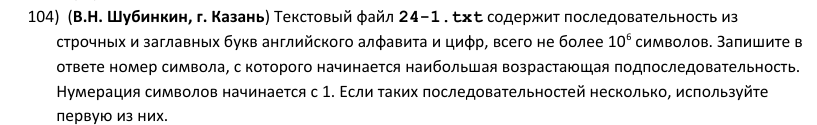

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-1.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе номер символа, с которого начинается наибольшая возрастающая подпоследовательность. Нумерация символов начинается с 1. Если таких последовательностей несколько, используйте первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [164]:
s = open('24-1.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(best + 1)

49234


**Способ 2 (проверка):** список точек разрыва + max

In [165]:
s = open('24-1.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(pos + 1)

49234


**Ответ: `49234`**

*Задача 105 — подобная предыдущим, пропущена.*

### Задача 106

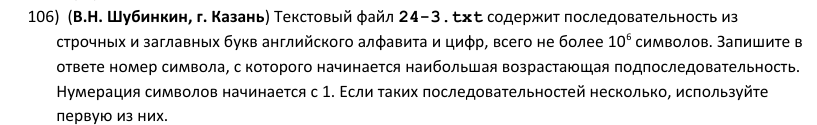

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-3.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе номер символа, с которого начинается наибольшая возрастающая подпоследовательность. Нумерация символов начинается с 1. Если таких последовательностей несколько, используйте первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [166]:
s = open('24-3.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(best + 1)

994


**Способ 2 (проверка):** список точек разрыва + max

In [167]:
s = open('24-3.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(pos + 1)

994


**Ответ: `994`**

### Задача 107

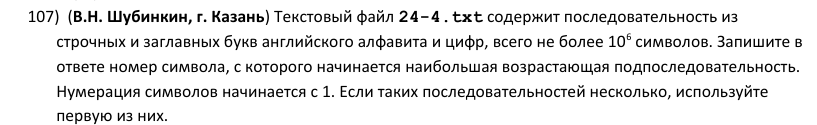

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-4.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе номер символа, с которого начинается наибольшая возрастающая подпоследовательность. Нумерация символов начинается с 1. Если таких последовательностей несколько, используйте первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [168]:
s = open('24-4.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] > s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(best + 1)

224


**Способ 2 (проверка):** список точек разрыва + max

In [169]:
s = open('24-4.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] > s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(pos + 1)

224


**Ответ: `224`**

### Задача 108

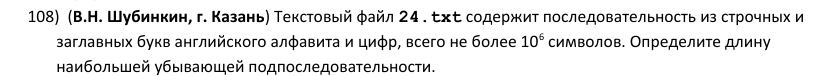

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Определите длину наибольшей убывающей подпоследовательности.</details>

**Способ 1:** однопроходный алгоритм

In [170]:
s = open('24.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(mx)

3


**Способ 2 (проверка):** список точек разрыва + max

In [171]:
s = open('24.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(L)

3


**Ответ: `3`**

### Задача 109

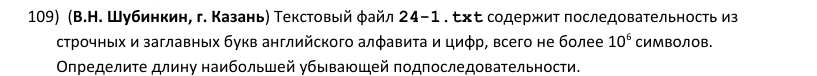

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-1.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Определите длину наибольшей убывающей подпоследовательности.</details>

**Способ 1:** однопроходный алгоритм

In [172]:
s = open('24-1.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(mx)

8


**Способ 2 (проверка):** список точек разрыва + max

In [173]:
s = open('24-1.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(L)

8


**Ответ: `8`**

*Задача 110 — подобная предыдущим, пропущена.*

### Задача 111

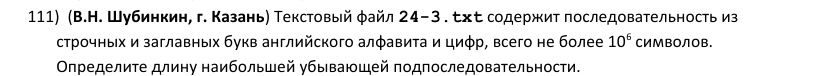

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-3.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Определите длину наибольшей убывающей подпоследовательности.</details>

**Способ 1:** однопроходный алгоритм

In [174]:
s = open('24-3.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(mx)

6


**Способ 2 (проверка):** список точек разрыва + max

In [175]:
s = open('24-3.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(L)

6


**Ответ: `6`**

### Задача 112

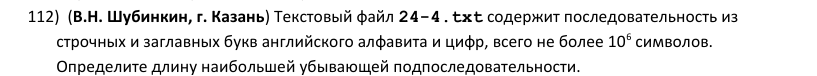

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-4.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Определите длину наибольшей убывающей подпоследовательности.</details>

**Способ 1:** однопроходный алгоритм

In [176]:
s = open('24-4.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(mx)

8


**Способ 2 (проверка):** список точек разрыва + max

In [177]:
s = open('24-4.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(L)

8


**Ответ: `8`**

### Задача 113

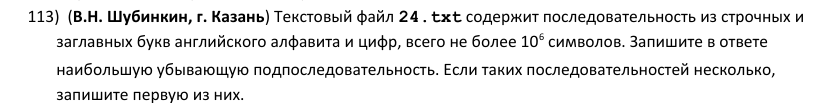

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе наибольшую убывающую подпоследовательность. Если таких последовательностей несколько, запишите первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [178]:
s = open('24.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(s[best:best + mx])

ZYX


**Способ 2 (проверка):** список точек разрыва + max

In [179]:
s = open('24.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(w)

ZYX


**Ответ: `ZYX`**

### Задача 114

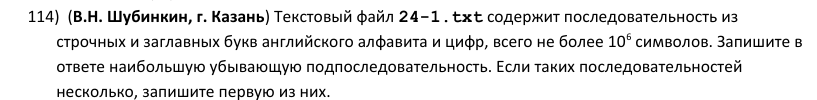

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-1.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе наибольшую убывающую подпоследовательность. Если таких последовательностей несколько, запишите первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [180]:
s = open('24-1.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(s[best:best + mx])

ZYXFEDBA


**Способ 2 (проверка):** список точек разрыва + max

In [181]:
s = open('24-1.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(w)

ZYXFEDBA


**Ответ: `ZYXFEDBA`**

*Задача 115 — подобная предыдущим, пропущена.*

### Задача 116

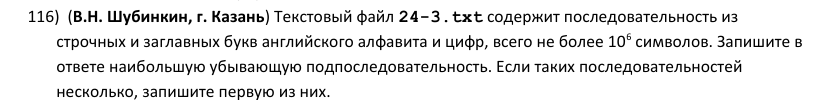

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-3.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе наибольшую убывающую подпоследовательность. Если таких последовательностей несколько, запишите первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [182]:
s = open('24-3.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(s[best:best + mx])

xEA541


**Способ 2 (проверка):** список точек разрыва + max

In [183]:
s = open('24-3.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(w)

xEA541


**Ответ: `xEA541`**

### Задача 117

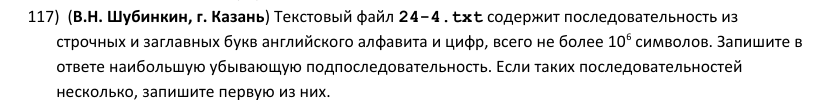

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-4.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе наибольшую убывающую подпоследовательность. Если таких последовательностей несколько, запишите первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [184]:
s = open('24-4.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(s[best:best + mx])

zrqjWRC1


**Способ 2 (проверка):** список точек разрыва + max

In [185]:
s = open('24-4.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(w)

zrqjWRC1


**Ответ: `zrqjWRC1`**

### Задача 118

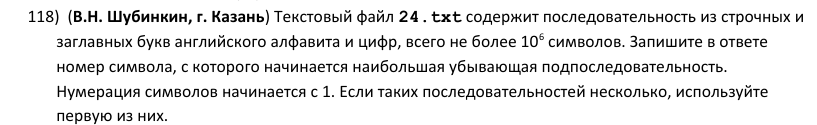

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе номер символа, с которого начинается наибольшая убывающая подпоследовательность. Нумерация символов начинается с 1. Если таких последовательностей несколько, используйте первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [186]:
s = open('24.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(best + 1)

14


**Способ 2 (проверка):** список точек разрыва + max

In [187]:
s = open('24.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(pos + 1)

14


**Ответ: `14`**

### Задача 119

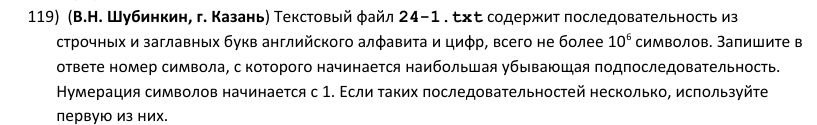

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-1.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе номер символа, с которого начинается наибольшая убывающая подпоследовательность. Нумерация символов начинается с 1. Если таких последовательностей несколько, используйте первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [188]:
s = open('24-1.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(best + 1)

353204


**Способ 2 (проверка):** список точек разрыва + max

In [189]:
s = open('24-1.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(pos + 1)

353204


**Ответ: `353204`**

*Задача 120 — подобная предыдущим, пропущена.*

### Задача 121

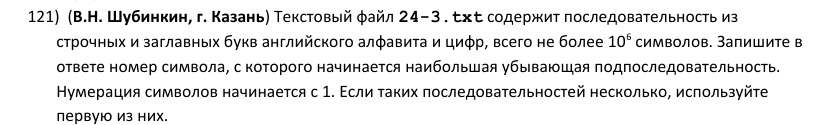

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-3.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе номер символа, с которого начинается наибольшая убывающая подпоследовательность. Нумерация символов начинается с 1. Если таких последовательностей несколько, используйте первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [190]:
s = open('24-3.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(best + 1)

563


**Способ 2 (проверка):** список точек разрыва + max

In [191]:
s = open('24-3.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(pos + 1)

563


**Ответ: `563`**

### Задача 122

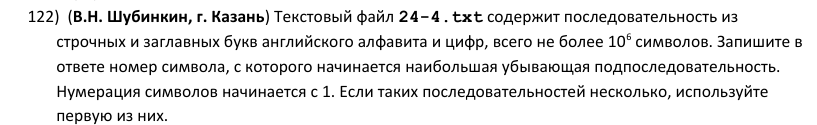

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл 24-4.txt содержит последовательность из строчных и заглавных букв английского алфавита и цифр, всего не более 10⁶ символов. Запишите в ответе номер символа, с которого начинается наибольшая убывающая подпоследовательность. Нумерация символов начинается с 1. Если таких последовательностей несколько, используйте первую из них.</details>

**Способ 1:** однопроходный алгоритм

In [192]:
s = open('24-4.txt').readline().strip()
start = 0              # начало текущей цепочки
mx, best = 1, 0        # длина и начало лучшей цепочки
for i in range(1, len(s)):
    if not s[i] < s[i-1]:
        start = i
    if i - start + 1 > mx:
        mx = i - start + 1
        best = start
print(best + 1)

993


**Способ 2 (проверка):** список точек разрыва + max

In [193]:
s = open('24-4.txt').readline().strip()
# индексы, где порядок нарушается, — это начала новых цепочек
cut = [0] + [i for i in range(1, len(s)) if not s[i] < s[i-1]] + [len(s)]
a = [(cut[j+1] - cut[j], cut[j]) for j in range(len(cut) - 1)]   # (длина, начало)
L, pos = max(a, key=lambda x: x[0])                              # первая самая длинная
w = s[pos:pos + L]
print(pos + 1)

993


**Ответ: `993`**

### Задача 123

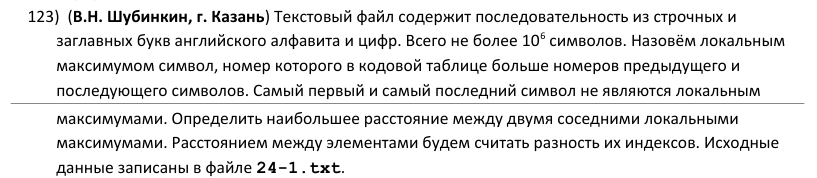

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл содержит последовательность из строчных и заглавных букв английского алфавита и цифр. Всего не более 10⁶ символов. Назовём локальным максимумом символ, номер которого в кодовой таблице больше номеров предыдущего и последующего символов. Самый первый и самый последний символ не являются локальным максимумами. Определить наибольшее расстояние между двумя соседними локальными максимумами. Расстоянием между элементами будем считать разность их индексов. Исходные данные записаны в файле 24-1.txt.</details>

**Способ 1:** список индексов + разности соседних

In [194]:
s = open('24-1.txt').readline().strip()
a = [i for i in range(1, len(s) - 1) if s[i-1] < s[i] > s[i+1]]
print(max(a[i+1] - a[i] for i in range(len(a) - 1)))

28


**Способ 2 (проверка):** однопроходный алгоритм

In [195]:
s = open('24-1.txt').readline().strip()
prev = None
mx = 0
for i in range(1, len(s) - 1):
    if s[i] > s[i-1] and s[i] > s[i+1]:
        if prev is not None:
            mx = max(mx, i - prev)
        prev = i
print(mx)

28


**Ответ: `28`**

### Задача 124

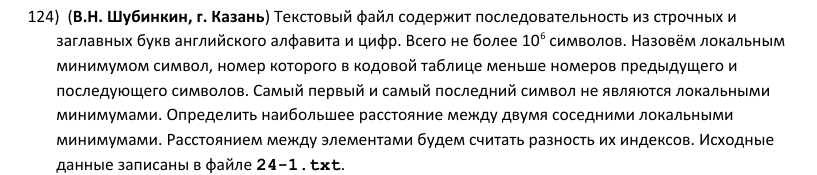

<details><summary>Текст условия</summary>(В.Н. Шубинкин, г. Казань) Текстовый файл содержит последовательность из строчных и заглавных букв английского алфавита и цифр. Всего не более 10⁶ символов. Назовём локальным минимумом символ, номер которого в кодовой таблице меньше номеров предыдущего и последующего символов. Самый первый и самый последний символ не являются локальными минимумами. Определить наибольшее расстояние между двумя соседними локальными минимумами. Расстоянием между элементами будем считать разность их индексов. Исходные данные записаны в файле 24-1.txt.</details>

**Способ 1:** список индексов + разности соседних

In [196]:
s = open('24-1.txt').readline().strip()
a = [i for i in range(1, len(s) - 1) if s[i-1] > s[i] < s[i+1]]
print(max(a[i+1] - a[i] for i in range(len(a) - 1)))

29


**Способ 2 (проверка):** однопроходный алгоритм

In [197]:
s = open('24-1.txt').readline().strip()
prev = None
mx = 0
for i in range(1, len(s) - 1):
    if s[i] < s[i-1] and s[i] < s[i+1]:
        if prev is not None:
            mx = max(mx, i - prev)
        prev = i
print(mx)

29


**Ответ: `29`**

## Скобки

* количество пар `()` — `s.count('()')` (пара не может перекрываться сама с собой);
* подряд идущие пары — заменяем `()` на `*` и ищем самую длинную цепочку `*`;
* «каким по счёту символом окажется k-я скобка» — собираем индексы нужных символов в список, ответ `a[k-1] + 1`
  (нумерация символов с 1, а индексы Python с 0).

### Задача 125

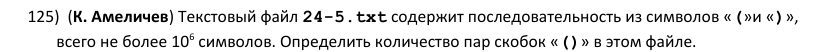

<details><summary>Текст условия</summary>(К. Амеличев) Текстовый файл 24-5.txt содержит последовательность из символов «(»и «)», всего не более 10⁶ символов. Определить количество пар скобок «()» в этом файле.</details>

**Способ 1:** count

In [198]:
s = open('24-5.txt').readline().strip()
print(s.count('()'))

236815


**Способ 2 (проверка):** перебор пар

In [199]:
s = open('24-5.txt').readline().strip()
print(sum(1 for i in range(len(s) - 1) if s[i] == '(' and s[i+1] == ')'))

236815


**Ответ: `236815`**

### Задача 126

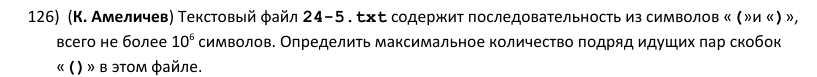

<details><summary>Текст условия</summary>(К. Амеличев) Текстовый файл 24-5.txt содержит последовательность из символов «(»и «)», всего не более 10⁶ символов. Определить максимальное количество подряд идущих пар скобок «()» в этом файле.</details>

**Способ 1:** замена + groupby

In [200]:
from itertools import groupby
s = open('24-5.txt').readline().strip()
s = s.replace('()', '*')
print(max(len(list(g)) for c, g in groupby(s) if c == '*'))

10


**Способ 2 (проверка):** регулярное выражение

In [201]:
from re import findall
s = open('24-5.txt').readline().strip()
print(max(map(len, findall(r'(?:\(\))+', s))) // 2)

10


**Ответ: `10`**

*Задача 127 — подобная предыдущим, пропущена.*

### Задача 128

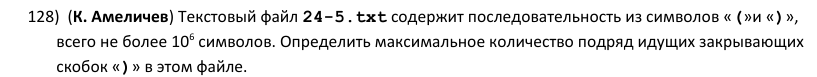

<details><summary>Текст условия</summary>(К. Амеличев) Текстовый файл 24-5.txt содержит последовательность из символов «(»и «)», всего не более 10⁶ символов. Определить максимальное количество подряд идущих закрывающих скобок «)» в этом файле.</details>

**Способ 1:** groupby

In [202]:
from itertools import groupby
s = open('24-5.txt').readline().strip()
print(max(len(list(g)) for c, g in groupby(s) if c == ')'))

17


**Способ 2 (проверка):** split по другой скобке

In [203]:
s = open('24-5.txt').readline().strip()
print(len(max(s.split('('), key=len)))

17


**Ответ: `17`**

### Задача 129

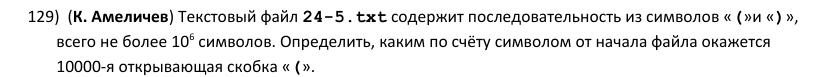

<details><summary>Текст условия</summary>(К. Амеличев) Текстовый файл 24-5.txt содержит последовательность из символов «(»и «)», всего не более 10⁶ символов. Определить, каким по счёту символом от начала файла окажется 10000-я открывающая скобка «(».</details>

**Способ 1:** список индексов

In [204]:
s = open('24-5.txt').readline().strip()
a = [i for i in range(len(s)) if s[i] == '(']
print(a[10000 - 1] + 1)

20137


**Способ 2 (проверка):** счётчик

In [205]:
s = open('24-5.txt').readline().strip()
k = 0
for i in range(len(s)):
    if s[i] == '(':
        k += 1
        if k == 10000:
            print(i + 1)
            break

20137


**Ответ: `20137`**

### Задача 130

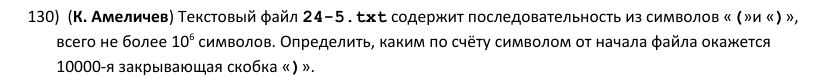

<details><summary>Текст условия</summary>(К. Амеличев) Текстовый файл 24-5.txt содержит последовательность из символов «(»и «)», всего не более 10⁶ символов. Определить, каким по счёту символом от начала файла окажется 10000-я закрывающая скобка «)».</details>

**Способ 1:** список индексов

In [206]:
s = open('24-5.txt').readline().strip()
a = [i for i in range(len(s)) if s[i] == ')']
print(a[10000 - 1] + 1)

19857


**Способ 2 (проверка):** счётчик

In [207]:
s = open('24-5.txt').readline().strip()
k = 0
for i in range(len(s)):
    if s[i] == ')':
        k += 1
        if k == 10000:
            print(i + 1)
            break

19857


**Ответ: `19857`**

*Задача 131 — подобная предыдущим, пропущена.*

## Задачи Е. Джобса: комбинации символов

* «сколько раз встречается» — `s.count(...)`, если комбинация не может перекрываться сама с собой;
* «подряд идущие комбинации» — заменяем комбинацию на `*` и ищем самую длинную цепочку `*`;
* условие на соседей (нет `J` до и после) — **регулярное выражение** с проверками `(?<!J)` («слева не J»)
  и `(?!J)` («справа не J»): они смотрят на соседний символ, но не «съедают» его.

> Файл `24-j1.txt` записан в кодировке Windows-1251 (русские буквы К, О, Т), поэтому в Colab его надо открывать
> с `encoding='cp1251'`.

### Задача 132

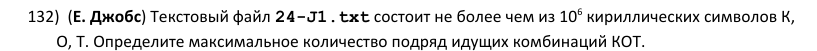

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-J1.txt состоит не более чем из 10⁶ кириллических символов К, О, Т. Определите максимальное количество подряд идущих комбинаций КОТ.</details>

**Способ 1:** замена + groupby

In [208]:
from itertools import groupby
s = open('24-j1.txt', encoding='cp1251').readline().strip()
s = s.replace('КОТ', '*')
print(max(len(list(g)) for c, g in groupby(s) if c == '*'))

75


**Способ 2 (проверка):** регулярное выражение

In [209]:
from re import findall
s = open('24-j1.txt', encoding='cp1251').readline().strip()
print(max(map(len, findall('(?:КОТ)+', s))) // 3)

75


**Ответ: `75`**

### Задача 133

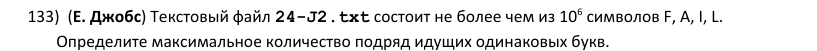

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-J2.txt состоит не более чем из 10⁶ символов F, A, I, L. Определите максимальное количество подряд идущих одинаковых букв.</details>

**Способ 1:** groupby

In [210]:
from itertools import groupby
s = open('24-j2.txt').readline().strip()
print(max(len(list(g)) for c, g in groupby(s)))

75


**Способ 2 (проверка):** однопроходный алгоритм

In [211]:
s = open('24-j2.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    k = k + 1 if s[i] == s[i-1] else 1
    mx = max(mx, k)
print(mx)

75


**Ответ: `75`**

### Задача 134

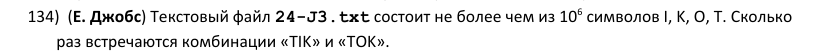

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-J3.txt состоит не более чем из 10⁶ символов I, K, O, T. Сколько раз встречаются комбинации «TIK» и «TOK».</details>

**Способ 1:** count

In [212]:
s = open('24-j3.txt').readline().strip()
print(s.count('TIK') + s.count('TOK'))

31348


**Способ 2 (проверка):** регулярное выражение

In [213]:
from re import findall
s = open('24-j3.txt').readline().strip()
print(len(findall('T[IO]K', s)))

31348


**Ответ: `31348`**

### Задача 135

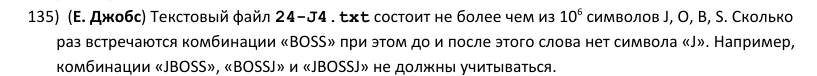

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-J4.txt состоит не более чем из 10⁶ символов J, O, B, S. Сколько раз встречаются комбинации «BOSS» при этом до и после этого слова нет символа «J». Например, комбинации «JBOSS», «BOSSJ» и «JBOSSJ» не должны учитываться.</details>

**Способ 1:** замена на * + проверка соседей

In [214]:
s = open('24-j4.txt').readline().strip()
s = 'S' + s.replace('BOSS', '*') + 'S'   # 'S' по краям — чтобы не выйти за границу
print(sum(1 for i in range(1, len(s) - 1) if s[i] == '*' and s[i-1] != 'J' and s[i+1] != 'J'))

2198


**Способ 2 (проверка):** регулярное выражение с (?<!J) и (?!J)

In [215]:
from re import findall
s = open('24-j4.txt').readline().strip()
print(len(findall('(?<!J)BOSS(?!J)', s)))

2198


**Ответ: `2198`**

*Задача 136 — подобная предыдущим, пропущена.*

## Файл из многих строк

Читаем все строки: `a = open(...).read().split()` (или `readlines()` + `strip()`), потом обрабатываем каждую.
Для шаблона «`F*O`, где `*` — любой символ» удобно регулярное выражение `F.O` (точка — любой символ).

### Задача 137

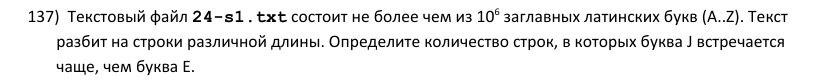

<details><summary>Текст условия</summary>Текстовый файл 24-s1.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Определите количество строк, в которых буква J встречается чаще, чем буква E.</details>

**Способ 1:** перебор строк + count

In [216]:
a = open('24-s1.txt').read().split()
print(sum(1 for t in a if t.count('J') > t.count('E')))

482


**Способ 2 (проверка):** цикл по строкам файла

In [217]:
k = 0
for line in open('24-s1.txt'):
    line = line.strip()
    if line.count('J') > line.count('E'):
        k += 1
print(k)

482


**Ответ: `482`**

### Задача 138

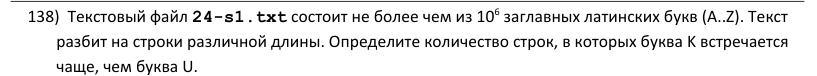

<details><summary>Текст условия</summary>Текстовый файл 24-s1.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Определите количество строк, в которых буква K встречается чаще, чем буква U.</details>

**Способ 1:** перебор строк + count

In [218]:
a = open('24-s1.txt').read().split()
print(sum(1 for t in a if t.count('K') > t.count('U')))

470


**Способ 2 (проверка):** цикл по строкам файла

In [219]:
k = 0
for line in open('24-s1.txt'):
    line = line.strip()
    if line.count('K') > line.count('U'):
        k += 1
print(k)

470


**Ответ: `470`**

*Задача 139 — подобная предыдущим, пропущена.*

### Задача 140

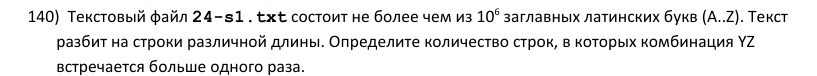

<details><summary>Текст условия</summary>Текстовый файл 24-s1.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Определите количество строк, в которых комбинация YZ встречается больше одного раза.</details>

**Способ 1:** перебор строк + count

In [220]:
a = open('24-s1.txt').read().split()
print(sum(1 for t in a if t.count('YZ') > 1))

433


**Способ 2 (проверка):** регулярное выражение

In [221]:
from re import findall
a = open('24-s1.txt').read().split()
print(sum(1 for t in a if len(findall('YZ', t)) > 1))

433


**Ответ: `433`**

### Задача 141

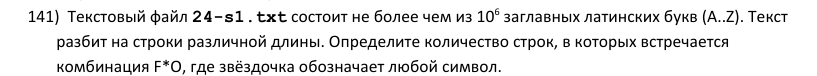

<details><summary>Текст условия</summary>Текстовый файл 24-s1.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Определите количество строк, в которых встречается комбинация F*O, где звёздочка обозначает любой символ.</details>

**Способ 1:** регулярное выражение F.O

In [222]:
from re import search
a = open('24-s1.txt').read().split()
print(sum(1 for t in a if search('F.O', t)))

757


**Способ 2 (проверка):** перебор позиций

In [223]:
a = open('24-s1.txt').read().split()
k = 0
for t in a:
    if any(t[i] == 'F' and t[i+2] == 'O' for i in range(len(t) - 2)):
        k += 1
print(k)

757


**Ответ: `757`**

*Задача 142 — подобная предыдущим, пропущена.*

### Задача 143

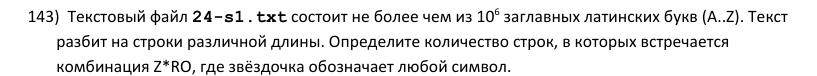

<details><summary>Текст условия</summary>Текстовый файл 24-s1.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Определите количество строк, в которых встречается комбинация Z*RO, где звёздочка обозначает любой символ.</details>

**Способ 1:** регулярное выражение Z.RO

In [224]:
from re import search
a = open('24-s1.txt').read().split()
print(sum(1 for t in a if search('Z.RO', t)))

59


**Способ 2 (проверка):** перебор позиций

In [225]:
a = open('24-s1.txt').read().split()
k = 0
for t in a:
    if any(t[i] == 'Z' and t[i+2:i+4] == 'RO' for i in range(len(t) - 3)):
        k += 1
print(k)

59


**Ответ: `59`**

## Последовательности цифр (Е. Джобс)

Однопроходный алгоритм: `k` — длина текущей последовательности. Когда последовательность обрывается,
проверяем её длину (или обновляем максимум). Не забываем проверить **последнюю** последовательность после цикла.

### Задача 144

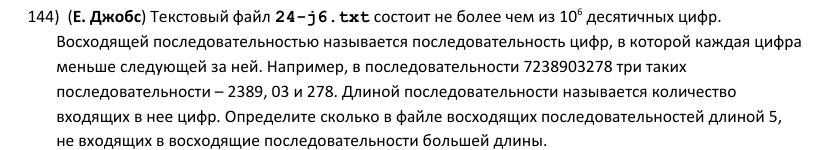

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-j6.txt состоит не более чем из 10⁶ десятичных цифр. Восходящей последовательностью называется последовательность цифр, в которой каждая цифра меньше следующей за ней. Например, в последовательности 7238903278 три таких последовательности – 2389, 03 и 278. Длиной последовательности называется количество входящих в нее цифр. Определите сколько в файле восходящих последовательностей длиной 5, не входящих в восходящие последовательности большей длины.</details>

**Способ 1:** однопроходный алгоритм

In [226]:
s = open('24-j6.txt').readline().strip()
k = 1
cnt = 0
for i in range(1, len(s)):
    if s[i-1] < s[i]:
        k += 1
    else:
        if k == 5:
            cnt += 1
        k = 1
if k == 5:          # последняя последовательность
    cnt += 1
print(cnt)

2087


**Способ 2 (проверка):** список точек разрыва

In [227]:
s = open('24-j6.txt').readline().strip()
cut = [0] + [i for i in range(1, len(s)) if s[i] <= s[i-1]] + [len(s)]
print(sum(1 for j in range(len(cut) - 1) if cut[j+1] - cut[j] == 5))

2087


**Ответ: `2087`**

### Задача 145

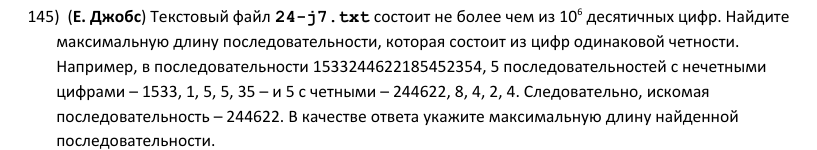

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-j7.txt состоит не более чем из 10⁶ десятичных цифр. Найдите максимальную длину последовательности, которая состоит из цифр одинаковой четности. Например, в последовательности 1533244622185452354, 5 последовательностей с нечетными цифрами – 1533, 1, 5, 5, 35 – и 5 с четными – 244622, 8, 4, 2, 4. Следовательно, искомая последовательность – 244622. В качестве ответа укажите максимальную длину найденной последовательности.</details>

**Способ 1:** метод замен + groupby

In [228]:
from itertools import groupby
from re import sub
s = open('24-j7.txt').readline().strip()
s = sub('[13579]', '1', s)
s = sub('[02468]', '0', s)
print(max(len(list(g)) for c, g in groupby(s)))

18


**Способ 2 (проверка):** однопроходный алгоритм

In [229]:
s = open('24-j7.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if int(s[i]) % 2 == int(s[i-1]) % 2:
        k += 1
    else:
        k = 1
    mx = max(mx, k)
print(mx)

18


**Ответ: `18`**

### Задача 146

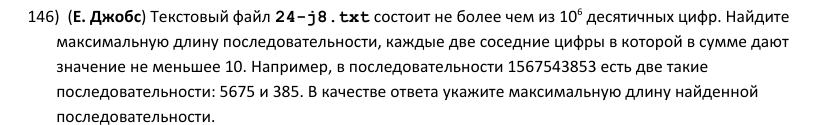

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-j8.txt состоит не более чем из 10⁶ десятичных цифр. Найдите максимальную длину последовательности, каждые две соседние цифры в которой в сумме дают значение не меньшее 10. Например, в последовательности 1567543853 есть две такие последовательности: 5675 и 385. В качестве ответа укажите максимальную длину найденной последовательности.</details>

**Способ 1:** однопроходный алгоритм

In [230]:
s = open('24-j8.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if int(s[i-1]) + int(s[i]) >= 10:
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

26


**Способ 2 (проверка):** список точек разрыва

In [231]:
s = open('24-j8.txt').readline().strip()
cut = [0] + [i for i in range(1, len(s)) if int(s[i-1]) + int(s[i]) < 10] + [len(s)]
print(max(cut[j+1] - cut[j] for j in range(len(cut) - 1)))

26


**Ответ: `26`**

## Самый частый символ в заданном окружении

Подсчёт удобно вести в словаре: `d = {c: 0 for c in ascii_uppercase}` или `Counter`.
Для ответа «максимум, а при равенстве — раньше по алфавиту» сортируем пары по ключу `(-количество, буква)`
или пользуемся тем, что `max` возвращает первый из равных, если перебирать буквы по алфавиту.

### Задача 147

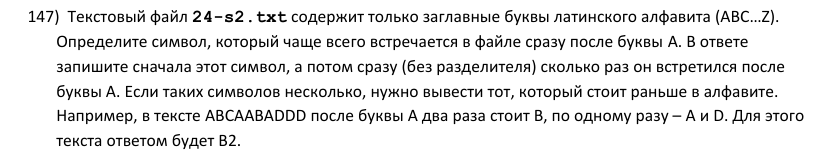

<details><summary>Текст условия</summary>Текстовый файл 24-s2.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите символ, который чаще всего встречается в файле сразу после буквы A. В ответе запишите сначала этот символ, а потом сразу (без разделителя) сколько раз он встретился после буквы А. Если таких символов несколько, нужно вывести тот, который стоит раньше в алфавите. Например, в тексте ABCAABADDD после буквы A два раза стоит B, по одному разу – A и D. Для этого текста ответом будет B2.</details>

**Способ 1:** словарь-счётчик

In [232]:
from string import ascii_uppercase
s = open('24-s2.txt').readline().strip()
d = {c: 0 for c in ascii_uppercase}
for i in range(len(s) - 1):
    if s[i] == 'A':
        d[s[i+1]] += 1
c = max(d, key=d.get)        # буквы идут по алфавиту, max берёт первую из равных
print(c + str(d[c]))

L1567


**Способ 2 (проверка):** Counter + регулярное выражение

In [233]:
from collections import Counter
from re import findall
s = open('24-s2.txt').readline().strip()
cnt = Counter(findall('(?<=A).', s))     # (?<=..) и (?=..) не «съедают» соседей
c, k = sorted(cnt.items(), key=lambda x: (-x[1], x[0]))[0]
print(c + str(k))

L1567


**Ответ: `L1567`**

### Задача 148

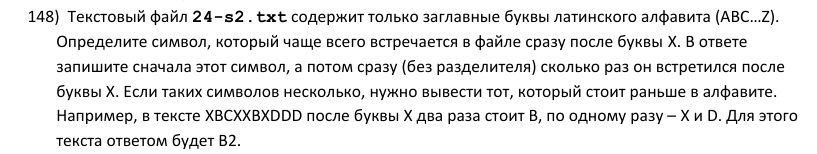

<details><summary>Текст условия</summary>Текстовый файл 24-s2.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите символ, который чаще всего встречается в файле сразу после буквы X. В ответе запишите сначала этот символ, а потом сразу (без разделителя) сколько раз он встретился после буквы X. Если таких символов несколько, нужно вывести тот, который стоит раньше в алфавите. Например, в тексте XBCXXBXDDD после буквы X два раза стоит B, по одному разу – X и D. Для этого текста ответом будет B2.</details>

**Способ 1:** словарь-счётчик

In [234]:
from string import ascii_uppercase
s = open('24-s2.txt').readline().strip()
d = {c: 0 for c in ascii_uppercase}
for i in range(len(s) - 1):
    if s[i] == 'X':
        d[s[i+1]] += 1
c = max(d, key=d.get)        # буквы идут по алфавиту, max берёт первую из равных
print(c + str(d[c]))

U1618


**Способ 2 (проверка):** Counter + регулярное выражение

In [235]:
from collections import Counter
from re import findall
s = open('24-s2.txt').readline().strip()
cnt = Counter(findall('(?<=X).', s))     # (?<=..) и (?=..) не «съедают» соседей
c, k = sorted(cnt.items(), key=lambda x: (-x[1], x[0]))[0]
print(c + str(k))

U1618


**Ответ: `U1618`**

*Задача 149 — подобная предыдущим, пропущена.*

### Задача 150

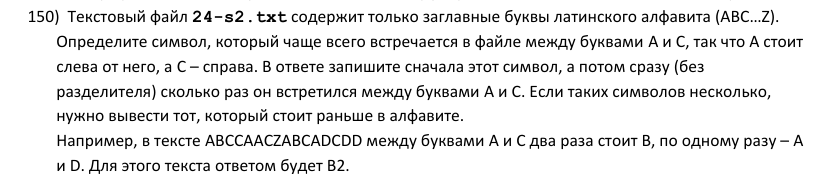

<details><summary>Текст условия</summary>Текстовый файл 24-s2.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите символ, который чаще всего встречается в файле между буквами A и C, так что A стоит слева от него, а C – справа. В ответе запишите сначала этот символ, а потом сразу (без разделителя) сколько раз он встретился между буквами A и C. Если таких символов несколько, нужно вывести тот, который стоит раньше в алфавите.<br>Например, в тексте ABCCAACZABCADCDD между буквами A и C два раза стоит B, по одному разу – A и D. Для этого текста ответом будет B2.</details>

**Способ 1:** словарь-счётчик

In [236]:
from string import ascii_uppercase
s = open('24-s2.txt').readline().strip()
d = {c: 0 for c in ascii_uppercase}
for i in range(len(s) - 2):
    if s[i] == 'A' and s[i+2] == 'C':
        d[s[i+1]] += 1
c = max(d, key=d.get)        # буквы идут по алфавиту, max берёт первую из равных
print(c + str(d[c]))

T72


**Способ 2 (проверка):** Counter + регулярное выражение

In [237]:
from collections import Counter
from re import findall
s = open('24-s2.txt').readline().strip()
cnt = Counter(findall('(?<=A).(?=C)', s))     # (?<=..) и (?=..) не «съедают» соседей
c, k = sorted(cnt.items(), key=lambda x: (-x[1], x[0]))[0]
print(c + str(k))

T72


**Ответ: `T72`**

### Задача 151

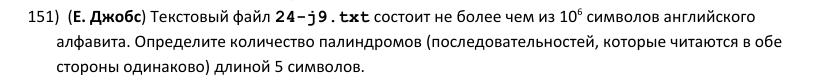

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-j9.txt состоит не более чем из 10⁶ символов английского алфавита. Определите количество палиндромов (последовательностей, которые читаются в обе стороны одинаково) длиной 5 символов.</details>

**Способ 1:** перебор окон длины 5

In [238]:
s = open('24-j9.txt').readline().strip()
k = 0
for i in range(len(s) - 4):
    w = s[i:i+5]
    if w == w[::-1]:
        k += 1
print(k)

1521


**Способ 2 (проверка):** сравнение крайних символов

In [239]:
s = open('24-j9.txt').readline().strip()
print(sum(1 for i in range(len(s) - 4) if s[i] == s[i+4] and s[i+1] == s[i+3]))

1521


**Ответ: `1521`**

### Задача 152

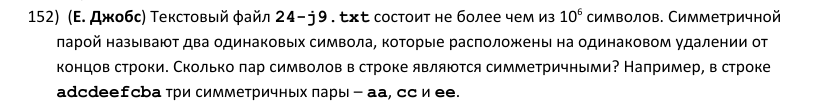

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-j9.txt состоит не более чем из 10⁶ символов. Симметричной парой называют два одинаковых символа, которые расположены на одинаковом удалении от концов строки. Сколько пар символов в строке являются симметричными? Например, в строке adcdeefcba три симметричных пары – aa, cc и ee.</details>

**Способ 1:** сравнение s[i] и s[n-1-i]

In [240]:
s = open('24-j9.txt').readline().strip()
n = len(s)
print(sum(1 for i in range(n // 2) if s[i] == s[n - 1 - i]))

19351


**Способ 2 (проверка):** через перевёрнутую строку

In [241]:
s = open('24-j9.txt').readline().strip()
r = s[::-1]
print(sum(1 for i in range(len(s) // 2) if s[i] == r[i]))

19351


**Ответ: `19351`**

## Подстроки между заданными символами (А. Кабанов)

**Список позиций.** Собираем индексы нужного символа: `p = [i for i in range(len(s)) if s[i] == 'D']`.
Подстрока «от одного D до следующего D» — это пара соседних элементов `p[j]`, `p[j+1]`, её длина
`p[j+1] - p[j] + 1`. Так многие задачи сводятся к работе со списком чисел.

### Задача 153

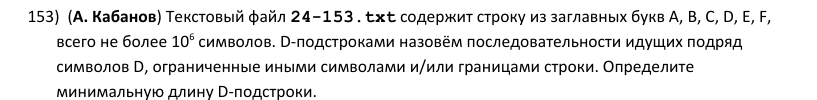

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-153.txt содержит строку из заглавных букв A, B, C, D, E, F, всего не более 10⁶ символов. D-подстроками назовём последовательности идущих подряд символов D, ограниченные иными символами и/или границами строки. Определите минимальную длину D-подстроки.</details>

**Способ 1:** findall + min

In [242]:
from re import findall
s = open('24-153.txt').readline().strip()
print(min(map(len, findall('D+', s))))

5


**Способ 2 (проверка):** groupby

In [243]:
from itertools import groupby
s = open('24-153.txt').readline().strip()
print(min(len(list(g)) for c, g in groupby(s) if c == 'D'))

5


**Ответ: `5`**

### Задача 154

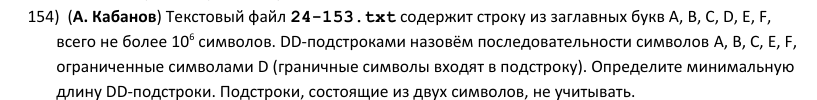

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-153.txt содержит строку из заглавных букв A, B, C, D, E, F, всего не более 10⁶ символов. DD-подстроками назовём последовательности символов A, B, C, E, F, ограниченные символами D (граничные символы входят в подстроку). Определите минимальную длину DD-подстроки. Подстроки, состоящие из двух символов, не учитывать.</details>

**Способ 1:** список позиций D

In [244]:
s = open('24-153.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] == 'D']
# соседние D, между которыми хотя бы один символ (подстроки из двух символов не считаем)
print(min(p[j+1] - p[j] + 1 for j in range(len(p) - 1) if p[j+1] - p[j] > 1))

139


**Способ 2 (проверка):** split по D

In [245]:
s = open('24-153.txt').readline().strip()
parts = s.split('D')[1:-1]          # куски, ограниченные D с обеих сторон
print(min(len(x) for x in parts if x) + 2)

139


**Ответ: `139`**

*Задача 155 — подобная предыдущим, пропущена.*

### Задача 156

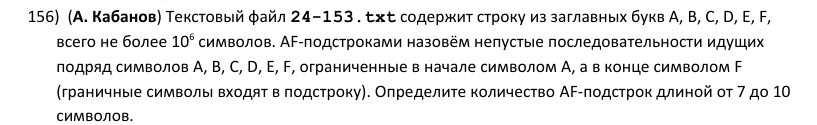

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-153.txt содержит строку из заглавных букв A, B, C, D, E, F, всего не более 10⁶ символов. AF-подстроками назовём непустые последовательности идущих подряд символов A, B, C, D, E, F, ограниченные в начале символом A, а в конце символом F (граничные символы входят в подстроку). Определите количество AF-подстрок длиной от 7 до 10 символов.</details>

**Способ 1:** перебор начала и длины

In [246]:
s = open('24-153.txt').readline().strip()
k = 0
for i in range(len(s)):
    if s[i] == 'A':
        for L in range(7, 11):
            if i + L - 1 < len(s) and s[i + L - 1] == 'F':
                k += 1
print(k)

3703


**Способ 2 (проверка):** регулярные выражения A.{n}F

In [247]:
from re import findall
s = open('24-153.txt').readline().strip()
# (?=...) позволяет искать совпадения, начинающиеся в каждой позиции
print(sum(len(findall(f'(?=A.{{{L-2}}}F)', s)) for L in range(7, 11)))

3703


**Ответ: `3703`**

> Внутри AF-подстроки могут быть любые буквы A–F (так сказано в условии), поэтому считаем все пары «A … F» длиной 7–10.

## Самый частый символ после/перед двумя одинаковыми

Перебираем тройки `s[i], s[i+1], s[i+2]`: условие «после двух одинаковых» — `s[i] == s[i+1]`, считаем `s[i+2]`;
«перед двумя одинаковыми» — `s[i+1] == s[i+2]`, считаем `s[i]`. Подсчёт — в `Counter`,
выбор ответа — сортировкой по `(-количество, буква)`.

### Задача 157

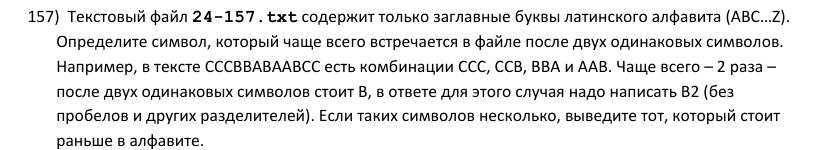

<details><summary>Текст условия</summary>Текстовый файл 24-157.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите символ, который чаще всего встречается в файле после двух одинаковых символов. Например, в тексте CCCBBABAABCC есть комбинации CCC, CCB, BBA и AAB. Чаще всего – 2 раза – после двух одинаковых символов стоит B, в ответе для этого случая надо написать B2 (без пробелов и других разделителей). Если таких символов несколько, выведите тот, который стоит раньше в алфавите.</details>

**Способ 1:** Counter

In [248]:
from collections import Counter
s = open('24-157.txt').readline().strip()
cnt = Counter(s[i+2] for i in range(len(s) - 2) if s[i] == s[i+1])
c, k = sorted(cnt.items(), key=lambda x: (-x[1], x[0]))[0]
print(c + str(k))

E1577


**Способ 2 (проверка):** словарь + регулярное выражение

In [249]:
from string import ascii_uppercase
from re import findall
s = open('24-157.txt').readline().strip()
a = findall(r'(?=(.)\1(.))', s)     # (?=...) — тройки «XX?» с каждой позиции
d = {c: 0 for c in ascii_uppercase}
for _, c in a:
    d[c] += 1
c = max(d, key=d.get)
print(c + str(d[c]))

E1577


**Ответ: `E1577`**

### Задача 158

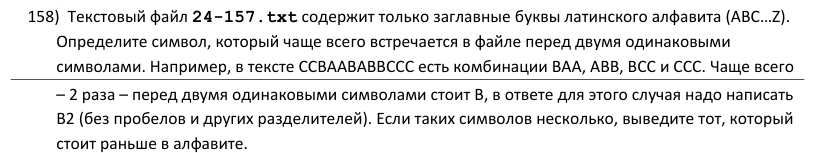

<details><summary>Текст условия</summary>Текстовый файл 24-157.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите символ, который чаще всего встречается в файле перед двумя одинаковыми символами. Например, в тексте CCBAABABBCCC есть комбинации BAA, ABB, BCC и CCC. Чаще всего – 2 раза – перед двумя одинаковыми символами стоит B, в ответе для этого случая надо написать B2 (без пробелов и других разделителей). Если таких символов несколько, выведите тот, который стоит раньше в алфавите.</details>

**Способ 1:** Counter

In [250]:
from collections import Counter
s = open('24-157.txt').readline().strip()
cnt = Counter(s[i] for i in range(len(s) - 2) if s[i+1] == s[i+2])
c, k = sorted(cnt.items(), key=lambda x: (-x[1], x[0]))[0]
print(c + str(k))

X1560


**Способ 2 (проверка):** словарь

In [251]:
from string import ascii_uppercase
s = open('24-157.txt').readline().strip()
d = {c: 0 for c in ascii_uppercase}
for i in range(len(s) - 2):
    if s[i+1] == s[i+2]:
        d[s[i]] += 1
c = max(d, key=d.get)
print(c + str(d[c]))

X1560


**Ответ: `X1560`**

*Задача 159 — подобная предыдущим, пропущена.*

## Выбор строки файла и подсчёт букв

Схема всегда одинаковая:
1. прочитать все строки: `a = open(...).read().split()`;
2. выбрать нужную строку (`min`/`max` с `key`); если при равенстве нужна **последняя** строка — ищем по перевёрнутому
   списку `a[::-1]` (функции `min`/`max` возвращают первый из равных);
3. посчитать буквы в строке (`Counter`) и выбрать букву по правилу — сортировкой с ключом;
4. посчитать эту букву во всём файле: `''.join(a).count(c)`.

Для «реже всего, но присутствует» перебираем только буквы, которые есть в строке, — это ключи `Counter`.

### Задача 160

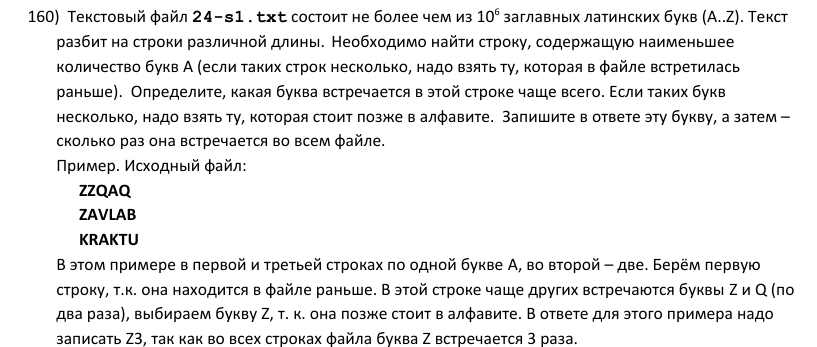

<details><summary>Текст условия</summary>Текстовый файл 24-s1.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Необходимо найти строку, содержащую наименьшее количество букв A (если таких строк несколько, надо взять ту, которая в файле встретилась раньше).  Определите, какая буква встречается в этой строке чаще всего. Если таких букв несколько, надо взять ту, которая стоит позже в алфавите.  Запишите в ответе эту букву, а затем – сколько раз она встречается во всем файле.<br>Пример. Исходный файл:<br>ZZQAQ<br>ZAVLAB<br>KRAKTU<br>В этом примере в первой и третьей строках по одной букве A, во второй – две. Берём первую строку, т.к. она находится в файле раньше. В этой строке чаще других встречаются буквы Z и Q (по два раза), выбираем букву Z, т. к. она позже стоит в алфавите. В ответе для этого примера надо записать Z3, так как во всех строках файла буква Z встречается 3 раза.</details>

**Способ 1:** min с key + Counter

In [252]:
from collections import Counter
a = open('24-s1.txt').read().split()
t = min(a, key=lambda x: x.count('A'))                   # первая из равных
cnt = Counter(t)
c = sorted(cnt, key=lambda ch: (-cnt[ch], -ord(ch)))[0]  # чаще всего, при равенстве — позже по алфавиту
print(c + str(''.join(a).count(c)))

V38429


**Способ 2 (проверка):** явные циклы

In [253]:
a = open('24-s1.txt').read().split()
best = 0
for i in range(len(a)):
    if a[i].count('A') < a[best].count('A'):
        best = i
t = a[best]
mx, c = -1, ''
for ch in 'ABCDEFGHIJKLMNOPQRSTUVWXYZ':
    if t.count(ch) >= mx:          # >= — при равенстве берём более позднюю букву
        mx, c = t.count(ch), ch
total = sum(x.count(c) for x in a)
print(c + str(total))

V38429


**Ответ: `V38429`**

### Задача 161

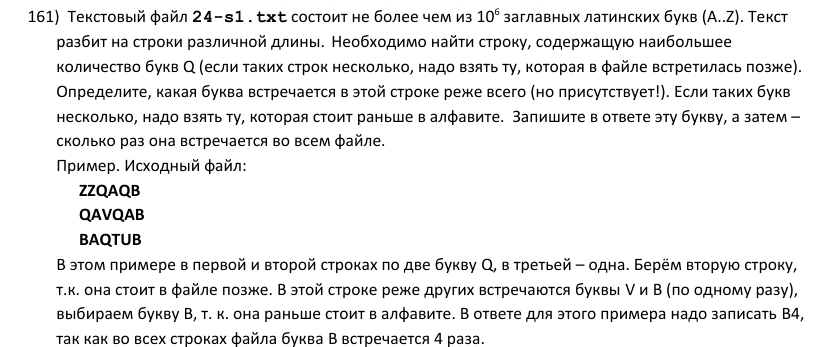

<details><summary>Текст условия</summary>Текстовый файл 24-s1.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Необходимо найти строку, содержащую наибольшее количество букв Q (если таких строк несколько, надо взять ту, которая в файле встретилась позже).  Определите, какая буква встречается в этой строке реже всего (но присутствует!). Если таких букв несколько, надо взять ту, которая стоит раньше в алфавите.  Запишите в ответе эту букву, а затем – сколько раз она встречается во всем файле.<br>Пример. Исходный файл:<br>ZZQAQB<br>QAVQAB<br>BAQTUB<br>В этом примере в первой и второй строках по две букву Q, в третьей – одна. Берём вторую строку, т.к. она стоит в файле позже. В этой строке реже других встречаются буквы V и B (по одному разу), выбираем букву B, т. к. она раньше стоит в алфавите. В ответе для этого примера надо записать B4, так как во всех строках файла буква B встречается 4 раза.</details>

**Способ 1:** max по перевёрнутому списку + Counter

In [254]:
from collections import Counter
a = open('24-s1.txt').read().split()
t = max(a[::-1], key=lambda x: x.count('Q'))             # последняя из равных
cnt = Counter(t)
c = sorted(cnt, key=lambda ch: (cnt[ch], ch))[0]         # реже всего, при равенстве — раньше по алфавиту
print(c + str(''.join(a).count(c)))

C38412


**Способ 2 (проверка):** явные циклы

In [255]:
a = open('24-s1.txt').read().split()
best = 0
for i in range(len(a)):
    if a[i].count('Q') >= a[best].count('Q'):
        best = i
t = a[best]
mn, c = 10**9, ''
for ch in 'ABCDEFGHIJKLMNOPQRSTUVWXYZ':
    if 0 < t.count(ch) < mn:
        mn, c = t.count(ch), ch
print(c + str(sum(x.count(c) for x in a)))

C38412


**Ответ: `C38412`**

*Задача 162 — подобная предыдущим, пропущена.*

### Задача 163

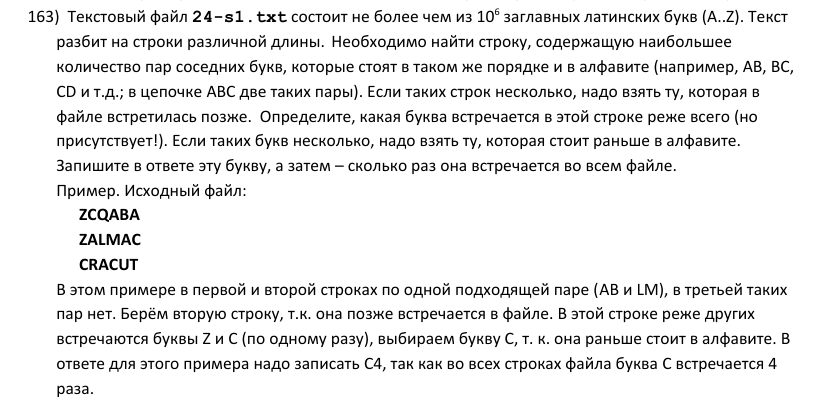

<details><summary>Текст условия</summary>Текстовый файл 24-s1.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Необходимо найти строку, содержащую наибольшее количество пар соседних букв, которые стоят в таком же порядке и в алфавите (например, AB, BC, CD и т.д.; в цепочке ABC две таких пары). Если таких строк несколько, надо взять ту, которая в файле встретилась позже.  Определите, какая буква встречается в этой строке реже всего (но присутствует!). Если таких букв несколько, надо взять ту, которая стоит раньше в алфавите.  Запишите в ответе эту букву, а затем – сколько раз она встречается во всем файле.<br>Пример. Исходный файл:<br>ZCQABA<br>ZALMAC<br>CRACUT<br>В этом примере в первой и второй строках по одной подходящей паре (AB и LM), в третьей таких пар нет. Берём вторую строку, т.к. она позже встречается в файле. В этой строке реже других встречаются буквы Z и C (по одному разу), выбираем букву С, т. к. она раньше стоит в алфавите. В ответе для этого примера надо записать C4, так как во всех строках файла буква C встречается 4 раза.</details>

**Способ 1:** функция подсчёта пар + max

In [256]:
from collections import Counter
a = open('24-s1.txt').read().split()
def pairs(t):          # пары соседних букв, идущих подряд в алфавите (AB, BC, ...)
    return sum(1 for i in range(len(t) - 1) if ord(t[i+1]) - ord(t[i]) == 1)
t = max(a[::-1], key=pairs)                              # последняя из равных
cnt = Counter(t)
c = sorted(cnt, key=lambda ch: (cnt[ch], ch))[0]
print(c + str(''.join(a).count(c)))

B38617


**Способ 2 (проверка):** count по списку пар

In [257]:
from string import ascii_uppercase as abc
a = open('24-s1.txt').read().split()
good = [abc[i] + abc[i+1] for i in range(25)]
best = 0
for i in range(len(a)):
    p = sum(a[i].count(g) for g in good)
    if p >= sum(a[best].count(g) for g in good):
        best = i
t = a[best]
mn, c = 10**9, ''
for ch in abc:
    if 0 < t.count(ch) < mn:
        mn, c = t.count(ch), ch
print(c + str(sum(x.count(c) for x in a)))

B38617


**Ответ: `B38617`**

### Задача 164

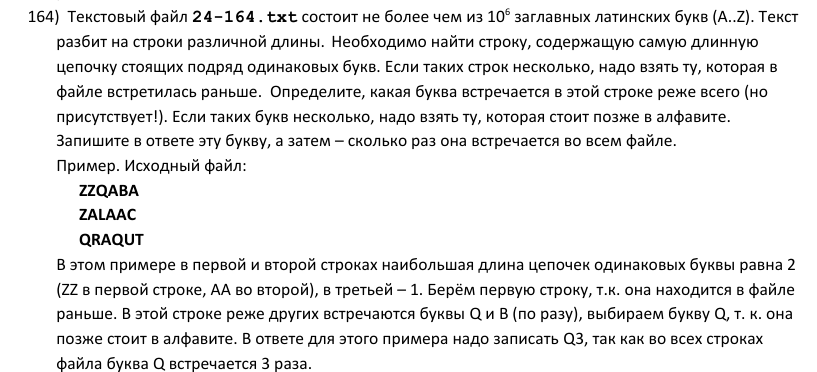

<details><summary>Текст условия</summary>Текстовый файл 24-164.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Текст разбит на строки различной длины. Необходимо найти строку, содержащую самую длинную цепочку стоящих подряд одинаковых букв. Если таких строк несколько, надо взять ту, которая в файле встретилась раньше.  Определите, какая буква встречается в этой строке реже всего (но присутствует!). Если таких букв несколько, надо взять ту, которая стоит позже в алфавите.  Запишите в ответе эту букву, а затем – сколько раз она встречается во всем файле.<br>Пример. Исходный файл:<br>ZZQABA<br>ZALAAC<br>QRAQUT<br>В этом примере в первой и второй строках наибольшая длина цепочек одинаковых буквы равна 2 (ZZ в первой строке, AA во второй), в третьей – 1. Берём первую строку, т.к. она находится в файле раньше. В этой строке реже других встречаются буквы Q и B (по разу), выбираем букву Q, т. к. она позже стоит в алфавите. В ответе для этого примера надо записать Q3, так как во всех строках файла буква Q встречается 3 раза.</details>

**Способ 1:** groupby + min/Counter

In [258]:
from collections import Counter
from itertools import groupby
a = open('24-164.txt').read().split()
def run(t):            # длина самой длинной цепочки одинаковых букв
    return max(len(list(g)) for c, g in groupby(t))
t = max(a, key=run)                                      # первая из равных
cnt = Counter(t)
c = sorted(cnt, key=lambda ch: (cnt[ch], -ord(ch)))[0]   # реже всего, при равенстве — позже по алфавиту
print(c + str(''.join(a).count(c)))

Z36493


**Способ 2 (проверка):** явные циклы

In [259]:
a = open('24-164.txt').read().split()
def run(t):
    k = mx = 1
    for i in range(1, len(t)):
        k = k + 1 if t[i] == t[i-1] else 1
        mx = max(mx, k)
    return mx
best = 0
for i in range(len(a)):
    if run(a[i]) > run(a[best]):
        best = i
t = a[best]
mn, c = 10**9, ''
for ch in 'ABCDEFGHIJKLMNOPQRSTUVWXYZ':
    if 0 < t.count(ch) <= mn:
        mn, c = t.count(ch), ch
print(c + str(sum(x.count(c) for x in a)))

Z36493


**Ответ: `Z36493`**

*Задача 165 — подобная предыдущим, пропущена.*

### Задача 166

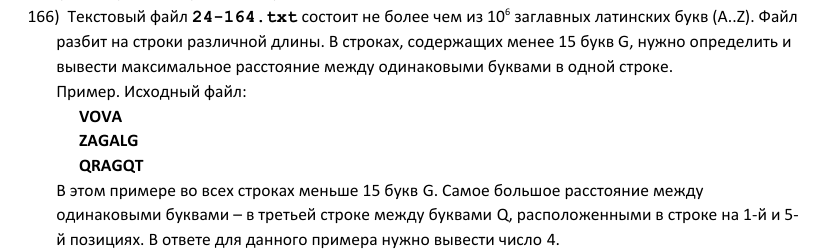

<details><summary>Текст условия</summary>Текстовый файл 24-164.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Файл разбит на строки различной длины. В строках, содержащих менее 15 букв G, нужно определить и вывести максимальное расстояние между одинаковыми буквами в одной строке.<br>Пример. Исходный файл:<br>VOVA<br>ZAGALG<br>QRAGQT<br>В этом примере во всех строках меньше 15 букв G. Самое большое расстояние между одинаковыми буквами – в третьей строке между буквами Q, расположенными в строке на 1-й и 5-й позициях. В ответе для данного примера нужно вывести число 4.</details>

**Способ 1:** find / rfind для каждой буквы

In [260]:
from string import ascii_uppercase
a = open('24-164.txt').read().split()
mx = 0
for t in a:
    if t.count('G') < 15:
        for c in ascii_uppercase:
            if c in t:
                mx = max(mx, t.rfind(c) - t.find(c))
print(mx)

916


**Способ 2 (проверка):** словарь первых вхождений

In [261]:
a = open('24-164.txt').read().split()
mx = 0
for t in a:
    if t.count('G') < 15:
        first = {}
        for i, c in enumerate(t):
            first.setdefault(c, i)        # запоминаем первое появление
            mx = max(mx, i - first[c])
print(mx)

916


**Ответ: `916`**

### Задача 167

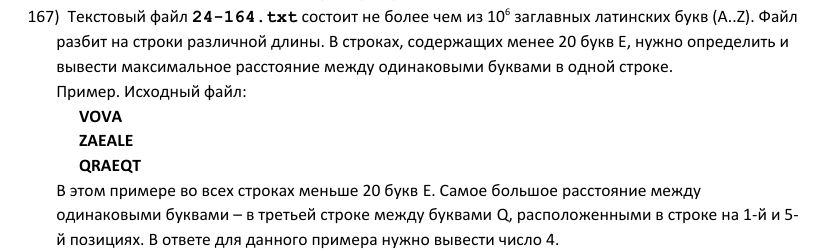

<details><summary>Текст условия</summary>Текстовый файл 24-164.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Файл разбит на строки различной длины. В строках, содержащих менее 20 букв E, нужно определить и вывести максимальное расстояние между одинаковыми буквами в одной строке.<br>Пример. Исходный файл:<br>VOVA<br>ZAEALE<br>QRAEQT<br>В этом примере во всех строках меньше 20 букв E. Самое большое расстояние между одинаковыми буквами – в третьей строке между буквами Q, расположенными в строке на 1-й и 5-й позициях. В ответе для данного примера нужно вывести число 4.</details>

**Способ 1:** find / rfind для каждой буквы

In [262]:
from string import ascii_uppercase
a = open('24-164.txt').read().split()
mx = 0
for t in a:
    if t.count('E') < 20:
        for c in ascii_uppercase:
            if c in t:
                mx = max(mx, t.rfind(c) - t.find(c))
print(mx)

974


**Способ 2 (проверка):** словарь первых вхождений

In [263]:
a = open('24-164.txt').read().split()
mx = 0
for t in a:
    if t.count('E') < 20:
        first = {}
        for i, c in enumerate(t):
            first.setdefault(c, i)
            mx = max(mx, i - first[c])
print(mx)

974


**Ответ: `974`**

## Разные задачи на цепочки

Здесь пригодится всё сразу: **groupby** (список участков одинаковых символов), **однопроходные алгоритмы**,
**регулярные выражения** и **список позиций** «плохих» мест. Последний приём такой: если подстрока не должна
целиком содержать «плохой» фрагмент длины `m`, начинающийся в позиции `b`, то для правой границы `R`
левая граница должна быть больше последнего `b`, у которого `b + m - 1 <= R`.

### Задача 168

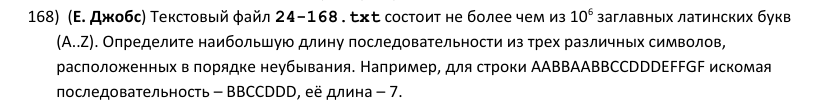

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-168.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Определите наибольшую длину последовательности из трех различных символов, расположенных в порядке неубывания. Например, для строки AABBAABBCCDDDEFFGF искомая последовательность – BBCCDDD, её длина – 7.</details>

**Способ 1:** groupby: тройки участков

In [264]:
from itertools import groupby
s = open('24-168.txt').readline().strip()
g = [(c, len(list(x))) for c, x in groupby(s)]   # участки одинаковых букв
mx = 0
for i in range(len(g) - 2):
    if g[i][0] < g[i+1][0] < g[i+2][0]:          # три разные буквы по возрастанию
        mx = max(mx, g[i][1] + g[i+1][1] + g[i+2][1])
print(mx)

6


**Способ 2 (проверка):** перебор с ранним выходом

In [265]:
s = open('24-168.txt').readline().strip()
mx = 0
# перебор начала; идём вправо, пока порядок не убывает и букв не больше трёх
for L in range(len(s)):
    if L > 0 and s[L] == s[L-1]:
        continue                     # начинать имеет смысл только с начала участка
    kinds = 1
    R = L + 1
    while R < len(s) and s[R] >= s[R-1]:
        if s[R] != s[R-1]:
            kinds += 1
            if kinds > 3:
                break
        R += 1
    if kinds >= 3:
        mx = max(mx, R - L)
print(mx)

6


**Ответ: `6`**

### Задача 169

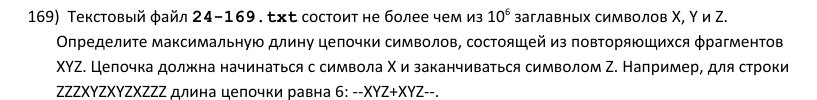

<details><summary>Текст условия</summary>Текстовый файл 24-169.txt состоит не более чем из 10⁶ заглавных символов X, Y и Z. Определите максимальную длину цепочки символов, состоящей из повторяющихся фрагментов XYZ. Цепочка должна начинаться с символа X и заканчиваться символом Z. Например, для строки ZZZXYZXYZXZZZ длина цепочки равна 6: --XYZ+XYZ--.</details>

**Способ 1:** регулярное выражение (?:XYZ)+

In [266]:
from re import findall
s = open('24-169.txt').readline().strip()
print(max(map(len, findall('(?:XYZ)+', s))))

66


**Способ 2 (проверка):** замена + split

In [267]:
s = open('24-169.txt').readline().strip()
s = s.replace('XYZ', '*')
print(len(max(s.replace('X', ' ').replace('Y', ' ').replace('Z', ' ').split(), key=len)) * 3)

66


**Ответ: `66`**

### Задача 170

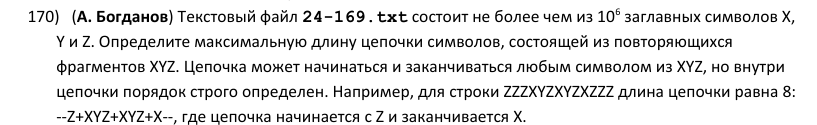

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-169.txt состоит не более чем из 10⁶ заглавных символов X, Y и Z. Определите максимальную длину цепочки символов, состоящей из повторяющихся фрагментов XYZ. Цепочка может начинаться и заканчиваться любым символом из XYZ, но внутри цепочки порядок строго определен. Например, для строки ZZZXYZXYZXZZZ длина цепочки равна 8: --Z+XYZ+XYZ+X--, где цепочка начинается с Z и заканчивается X.</details>

**Способ 1:** однопроходный алгоритм

In [268]:
s = open('24-169.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i-1] + s[i] in ('XY', 'YZ', 'ZX'):
        k += 1
        mx = max(mx, k)
    else:
        k = 1
print(mx)

69


**Способ 2 (проверка):** регулярное выражение

In [269]:
from re import findall
s = open('24-169.txt').readline().strip()
print(max(map(len, findall('(?:Z|YZ)?(?:XYZ)*(?:XY|X)?', s))))

69


**Ответ: `69`**

*Задача 171 — подобная предыдущим, пропущена.*

### Задача 172

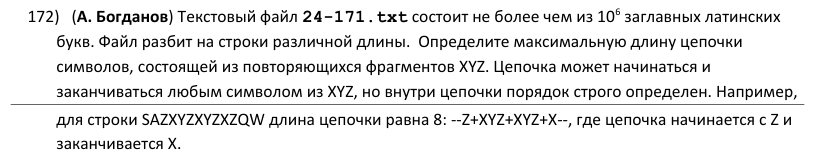

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-171.txt состоит не более чем из 10⁶ заглавных латинских букв. Файл разбит на строки различной длины.  Определите максимальную длину цепочки символов, состоящей из повторяющихся фрагментов XYZ. Цепочка может начинаться и заканчиваться любым символом из XYZ, но внутри цепочки порядок строго определен. Например, для строки SAZXYZXYZXZQW длина цепочки равна 8: --Z+XYZ+XYZ+X--, где цепочка начинается с Z и заканчивается X.</details>

**Способ 1:** однопроходный алгоритм по строкам

In [270]:
a = open('24-171.txt').read().split()
mx = 0
for t in a:
    k = 1 if t[0] in 'XYZ' else 0
    mx = max(mx, k)
    for i in range(1, len(t)):
        if t[i-1] + t[i] in ('XY', 'YZ', 'ZX'):
            k += 1
        else:
            k = 1 if t[i] in 'XYZ' else 0
        mx = max(mx, k)
print(mx)

53


**Способ 2 (проверка):** регулярное выражение

In [271]:
from re import findall
a = open('24-171.txt').read().split()
pat = '(?:Z|YZ)?(?:XYZ)*(?:XY|X)?|Y'
print(max(max(map(len, findall(pat, t))) for t in a))

53


**Ответ: `53`**

### Задача 173

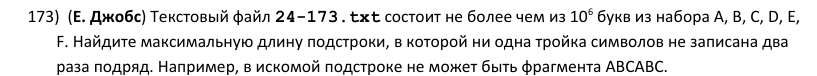

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-173.txt состоит не более чем из 10⁶ букв из набора A, B, C, D, E, F. Найдите максимальную длину подстроки, в которой ни одна тройка символов не записана два раза подряд. Например, в искомой подстроке не может быть фрагмента ABCABC.</details>

**Способ 1:** список «плохих» позиций

In [272]:
s = open('24-173.txt').readline().strip()
mx = 0
last = -1                        # начало последнего плохого фрагмента XYZXYZ, целиком лежащего левее R
for R in range(len(s)):
    b = R - 5
    if b >= 0 and s[b:b+3] == s[b+3:b+6]:
        last = b
    mx = max(mx, R - last)       # подстрока s[last+1 .. R]
print(mx)

2278


**Способ 2 (проверка):** два указателя

In [273]:
s = open('24-173.txt').readline().strip()
L = 0
mx = 0
for R in range(len(s)):
    # если подстрока заканчивается повтором тройки, сдвигаем левую границу за его начало
    if R >= 5 and s[R-5:R-2] == s[R-2:R+1] and L <= R - 5:
        L = R - 4
    mx = max(mx, R - L + 1)
print(mx)

2278


**Ответ: `2278`**

### Задача 174

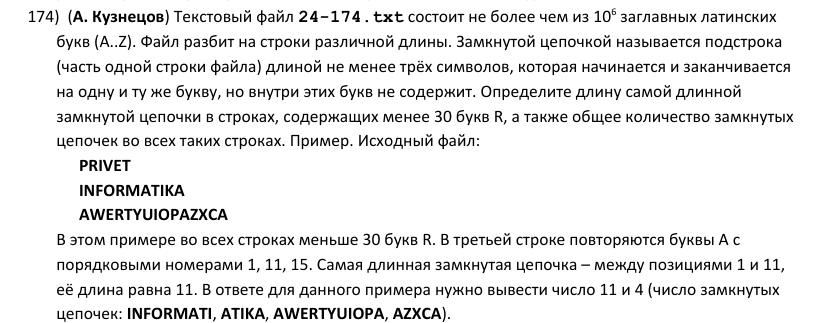

<details><summary>Текст условия</summary>(А. Кузнецов) Текстовый файл 24-174.txt состоит не более чем из 10⁶ заглавных латинских букв (A..Z). Файл разбит на строки различной длины. Замкнутой цепочкой называется подстрока (часть одной строки файла) длиной не менее трёх символов, которая начинается и заканчивается на одну и ту же букву, но внутри этих букв не содержит. Определите длину самой длинной замкнутой цепочки в строках, содержащих менее 30 букв R, а также общее количество замкнутых цепочек во всех таких строках. Пример. Исходный файл:<br>PRIVET<br>INFORMATIKA<br>AWERTYUIOPAZXCA<br>В этом примере во всех строках меньше 30 букв R. В третьей строке повторяются буквы А с порядковыми номерами 1, 11, 15. Самая длинная замкнутая цепочка – между позициями 1 и 11, её длина равна 11. В ответе для данного примера нужно вывести число 11 и 4 (число замкнутых цепочек: INFORMATI, ATIKA, AWERTYUIOPA, AZXCA).</details>

**Способ 1:** split по каждой букве

In [274]:
from string import ascii_uppercase
a = open('24-174.txt').read().split()
mx = cnt = 0
for t in a:
    if t.count('R') < 30:
        for c in ascii_uppercase:
            p = [i for i in range(len(t)) if t[i] == c]
            for j in range(len(p) - 1):
                L = p[j+1] - p[j] + 1
                if L >= 3:
                    cnt += 1
                    mx = max(mx, L)
print(mx, cnt)

356 119624


**Способ 2 (проверка):** словарь последних вхождений

In [275]:
a = open('24-174.txt').read().split()
mx = cnt = 0
for t in a:
    if t.count('R') < 30:
        last = {}
        for i, c in enumerate(t):
            if c in last and i - last[c] >= 2:
                cnt += 1
                mx = max(mx, i - last[c] + 1)
            last[c] = i
print(mx, cnt)

356 119624


**Ответ: `356 119624`**

### Задача 175

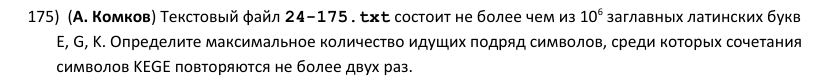

<details><summary>Текст условия</summary>(А. Комков) Текстовый файл 24-175.txt состоит не более чем из 10⁶ заглавных латинских букв E, G, K. Определите максимальное количество идущих подряд символов, среди которых сочетания символов KEGE повторяются не более двух раз.</details>

**Способ 1:** список позиций KEGE

In [276]:
s = open('24-175.txt').readline().strip()
n = len(s)
p = [i for i in range(n - 3) if s[i:i+4] == 'KEGE']
# фиктивные «вхождения» до начала и после конца строки
p = [-1] + p + [n - 3]
# от p[j]+1 (вхождение j уже не целиком) до p[j+3]+2 (вхождение j+3 ещё не целиком): внутри только 2 вхождения
print(max(p[j+3] - p[j] + 2 for j in range(len(p) - 3)))

946


**Способ 2 (проверка):** два указателя

In [277]:
s = open('24-175.txt').readline().strip()
L = 0
k = mx = 0
for R in range(len(s)):
    if R >= 3 and s[R-3:R+1] == 'KEGE':
        k += 1
    while k > 2:
        if s[L:L+4] == 'KEGE':
            k -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

946


**Ответ: `946`**

### Задача 176

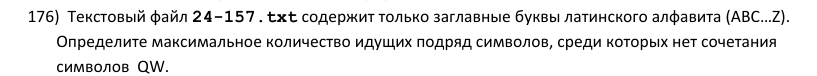

<details><summary>Текст условия</summary>Текстовый файл 24-157.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите максимальное количество идущих подряд символов, среди которых нет сочетания символов  QW.</details>

**Способ 1:** метод замен + split

In [278]:
s = open('24-157.txt').readline().strip()
s = s.replace('QW', 'Q W')
print(len(max(s.split(), key=len)))

5267


**Способ 2 (проверка):** однопроходный алгоритм

In [279]:
s = open('24-157.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    k = 1 if s[i-1:i+1] == 'QW' else k + 1
    mx = max(mx, k)
print(mx)

5267


**Ответ: `5267`**

### Задача 177

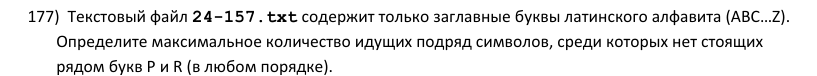

<details><summary>Текст условия</summary>Текстовый файл 24-157.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите максимальное количество идущих подряд символов, среди которых нет стоящих рядом букв P и R (в любом порядке).</details>

**Способ 1:** метод замен + split

In [280]:
s = open('24-157.txt').readline().strip()
s = s.replace('PR', 'P R').replace('RP', 'R P')
print(len(max(s.split(), key=len)))

2940


**Способ 2 (проверка):** однопроходный алгоритм

In [281]:
s = open('24-157.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    k = 1 if s[i-1:i+1] in ('PR', 'RP') else k + 1
    mx = max(mx, k)
print(mx)

2940


**Ответ: `2940`**

### Задача 178

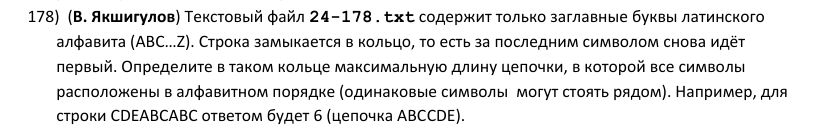

<details><summary>Текст условия</summary>(В. Якшигулов) Текстовый файл 24-178.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Строка замыкается в кольцо, то есть за последним символом снова идёт первый. Определите в таком кольце максимальную длину цепочки, в которой все символы расположены в алфавитном порядке (одинаковые символы  могут стоять рядом). Например, для строки CDEABCABC ответом будет 6 (цепочка ABCCDE).</details>

**Способ 1:** кольцо = строка, записанная дважды

In [282]:
s = open('24-178.txt').readline().strip()
n = len(s)
t = s + s                    # обход кольца
k = mx = 1
for i in range(1, len(t)):
    k = k + 1 if t[i] >= t[i-1] else 1
    mx = max(mx, k)
print(min(mx, n))

8


**Способ 2 (проверка):** перебор начала в кольце

In [283]:
s = open('24-178.txt').readline().strip()
n = len(s)
mx = 0
for st in range(n):          # перебор начала в кольце
    L = 1
    while L < n and s[(st + L) % n] >= s[(st + L - 1) % n]:
        L += 1
    mx = max(mx, L)
print(mx)

8


**Ответ: `8`**

### Задача 179

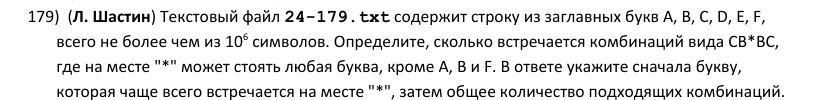

<details><summary>Текст условия</summary>(Л. Шастин) Текстовый файл 24-179.txt содержит строку из заглавных букв A, B, C, D, E, F, всего не более чем из 10⁶ символов. Определите, сколько встречается комбинаций вида CB*BC, где на месте &quot;*&quot; может стоять любая буква, кроме A, B и F. В ответе укажите сначала букву, которая чаще всего встречается на месте &quot;*&quot;, затем общее количество подходящих комбинаций.</details>

**Способ 1:** регулярное выражение с (?=...)

In [284]:
from collections import Counter
from re import findall
s = open('24-179.txt').readline().strip()
a = findall('(?=CB([CDE])BC)', s)      # с каждой позиции — комбинации могут перекрываться
c, k = Counter(a).most_common(1)[0]
print(c, len(a))

C 6347


**Способ 2 (проверка):** перебор позиций

In [285]:
from collections import Counter
s = open('24-179.txt').readline().strip()
cnt = Counter()
for i in range(len(s) - 4):
    if s[i:i+2] == 'CB' and s[i+3:i+5] == 'BC' and s[i+2] not in 'ABF':
        cnt[s[i+2]] += 1
print(cnt.most_common(1)[0][0], sum(cnt.values()))

C 6347


**Ответ: `C6347`**

### Задача 180

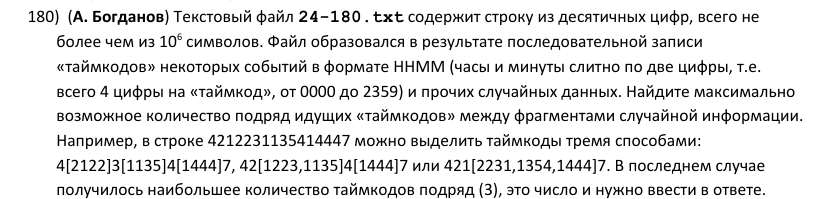

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-180.txt содержит строку из десятичных цифр, всего не более чем из 10⁶ символов. Файл образовался в результате последовательной записи «таймкодов» некоторых событий в формате HHMM (часы и минуты слитно по две цифры, т.е. всего 4 цифры на «таймкод», от 0000 до 2359) и прочих случайных данных. Найдите максимально возможное количество подряд идущих «таймкодов» между фрагментами случайной информации. Например, в строке 4212231135414447 можно выделить таймкоды тремя способами: 4[2122]3[1135]4[1444]7, 42[1223,1135]4[1444]7 или 421[2231,1354,1444]7. В последнем случае получилось наибольшее количество таймкодов подряд (3), это число и нужно ввести в ответе.</details>

**Способ 1:** динамическое программирование

In [286]:
s = open('24-180.txt').readline().strip()
n = len(s)
dp = [0] * n          # dp[i] — сколько таймкодов подряд заканчивается в позиции i
for i in range(3, n):
    hh, mm = int(s[i-3:i-1]), int(s[i-1:i+1])
    if hh <= 23 and mm <= 59:
        dp[i] = dp[i-4] + 1 if i >= 4 else 1
print(max(dp))

2504


**Способ 2 (проверка):** 4 сдвига + однопроходный алгоритм

In [287]:
s = open('24-180.txt').readline().strip()
def ok(t):
    return int(t[:2]) <= 23 and int(t[2:]) <= 59
mx = 0
for start in range(4):                     # 4 варианта «выравнивания» на четвёрки
    k = 0
    for i in range(start, len(s) - 3, 4):
        k = k + 1 if ok(s[i:i+4]) else 0
        mx = max(mx, k)
print(mx)

2504


**Ответ: `2504`**

## Не более k точек: список позиций

**Список позиций («статика»).** `p` — индексы точек, по краям добавляем фиктивные точки `-1` и `len(s)`.
Самая длинная подстрока с не более чем `k` точками лежит между точками `p[j]` и `p[j+k+1]` (их не включая):
длина `p[j+k+1] - p[j] - 1`.

**Два указателя («динамика»).** Двигаем правую границу `R`; если точек стало больше `k`, подтягиваем левую `L`.

### Задача 181

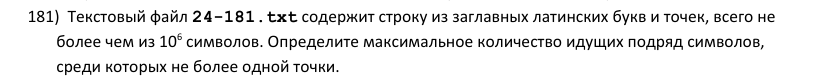

<details><summary>Текст условия</summary>Текстовый файл 24-181.txt содержит строку из заглавных латинских букв и точек, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых не более одной точки.</details>

**Способ 1:** список позиций точек

In [288]:
s = open('24-181.txt').readline().strip()
p = [-1] + [i for i in range(len(s)) if s[i] == '.'] + [len(s)]
k = 1
print(max(p[j+k+1] - p[j] - 1 for j in range(len(p) - k - 1)))

353


**Способ 2 (проверка):** два указателя

In [289]:
s = open('24-181.txt').readline().strip()
L = cnt = mx = 0
for R in range(len(s)):
    cnt += s[R] == '.'
    while cnt > 1:
        cnt -= s[L] == '.'
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

353


**Ответ: `353`**

### Задача 182

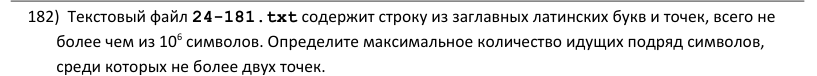

<details><summary>Текст условия</summary>Текстовый файл 24-181.txt содержит строку из заглавных латинских букв и точек, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых не более двух точек.</details>

**Способ 1:** список позиций точек

In [290]:
s = open('24-181.txt').readline().strip()
p = [-1] + [i for i in range(len(s)) if s[i] == '.'] + [len(s)]
k = 2
print(max(p[j+k+1] - p[j] - 1 for j in range(len(p) - k - 1)))

403


**Способ 2 (проверка):** два указателя

In [291]:
s = open('24-181.txt').readline().strip()
L = cnt = mx = 0
for R in range(len(s)):
    cnt += s[R] == '.'
    while cnt > 2:
        cnt -= s[L] == '.'
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

403


**Ответ: `403`**

*Задача 183 — подобная предыдущим, пропущена.*

### Задача 184

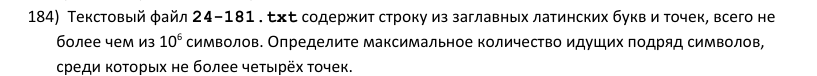

<details><summary>Текст условия</summary>Текстовый файл 24-181.txt содержит строку из заглавных латинских букв и точек, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых не более четырёх точек.</details>

**Способ 1:** список позиций точек

In [292]:
s = open('24-181.txt').readline().strip()
p = [-1] + [i for i in range(len(s)) if s[i] == '.'] + [len(s)]
k = 4
print(max(p[j+k+1] - p[j] - 1 for j in range(len(p) - k - 1)))

483


**Способ 2 (проверка):** два указателя

In [293]:
s = open('24-181.txt').readline().strip()
L = cnt = mx = 0
for R in range(len(s)):
    cnt += s[R] == '.'
    while cnt > 4:
        cnt -= s[L] == '.'
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

483


**Ответ: `483`**

### Задача 185

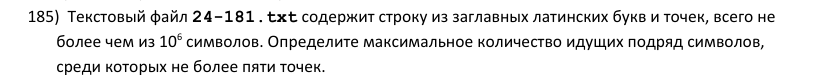

<details><summary>Текст условия</summary>Текстовый файл 24-181.txt содержит строку из заглавных латинских букв и точек, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых не более пяти точек.</details>

**Способ 1:** список позиций точек

In [294]:
s = open('24-181.txt').readline().strip()
p = [-1] + [i for i in range(len(s)) if s[i] == '.'] + [len(s)]
k = 5
print(max(p[j+k+1] - p[j] - 1 for j in range(len(p) - k - 1)))

550


**Способ 2 (проверка):** два указателя

In [295]:
s = open('24-181.txt').readline().strip()
L = cnt = mx = 0
for R in range(len(s)):
    cnt += s[R] == '.'
    while cnt > 5:
        cnt -= s[L] == '.'
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

550


**Ответ: `550`**

### Задача 186

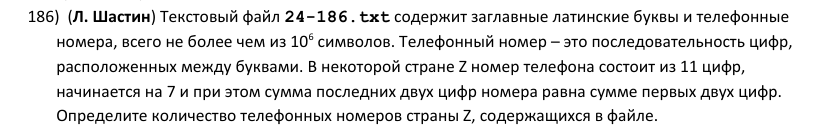

<details><summary>Текст условия</summary>(Л. Шастин) Текстовый файл 24-186.txt содержит заглавные латинские буквы и телефонные номера, всего не более чем из 10⁶ символов. Телефонный номер – это последовательность цифр, расположенных между буквами. В некоторой стране Z номер телефона состоит из 11 цифр,  начинается на 7 и при этом сумма последних двух цифр номера равна сумме первых двух цифр. Определите количество телефонных номеров страны Z, содержащихся в файле.</details>

**Способ 1:** findall + проверка номера

In [296]:
from re import findall
s = open('24-186.txt').readline().strip()
k = 0
for x in findall(r'\d+', s):
    if len(x) == 11 and x[0] == '7' and int(x[-2]) + int(x[-1]) == int(x[0]) + int(x[1]):
        k += 1
print(k)

89


**Способ 2 (проверка):** метод замен + split

In [297]:
from re import sub
s = open('24-186.txt').readline().strip()
a = sub('[A-Z]', ' ', s).split()
print(len([x for x in a if len(x) == 11 and x[0] == '7' and int(x[9]) + int(x[10]) == 7 + int(x[1])]))

89


**Ответ: `89`**

### Задача 187

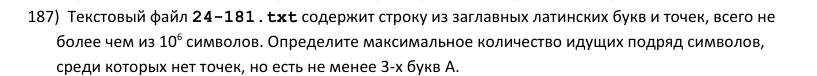

<details><summary>Текст условия</summary>Текстовый файл 24-181.txt содержит строку из заглавных латинских букв и точек, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых нет точек, но есть не менее 3-х букв A.</details>

**Способ 1:** split по точкам

In [298]:
s = open('24-181.txt').readline().strip()
print(max(len(x) for x in s.split('.') if x.count('A') >= 3))

284


**Способ 2 (проверка):** регулярное выражение

In [299]:
from re import findall
s = open('24-181.txt').readline().strip()
print(max(len(x) for x in findall('[A-Z]+', s) if x.count('A') >= 3))

284


**Ответ: `284`**

### Задача 188

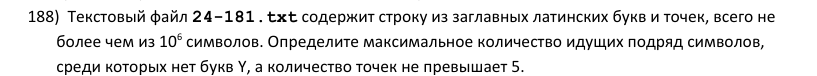

<details><summary>Текст условия</summary>Текстовый файл 24-181.txt содержит строку из заглавных латинских букв и точек, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых нет букв Y, а количество точек не превышает 5.</details>

**Способ 1:** split по Y + список позиций точек

In [300]:
s = open('24-181.txt').readline().strip()
mx = 0
for t in s.split('Y'):
    p = [-1] + [i for i in range(len(t)) if t[i] == '.'] + [len(t)]
    if len(p) - 2 <= 5:
        mx = max(mx, len(t))
    else:
        mx = max(mx, max(p[j+6] - p[j] - 1 for j in range(len(p) - 6)))
print(mx)

208


**Способ 2 (проверка):** два указателя со сбросом

In [301]:
s = open('24-181.txt').readline().strip()
L = dots = mx = 0
for R in range(len(s)):
    if s[R] == 'Y':
        L, dots = R + 1, 0
        continue
    dots += s[R] == '.'
    while dots > 5:
        dots -= s[L] == '.'
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

208


**Ответ: `208`**

*Задача 189 — подобная предыдущим, пропущена.*

### Задача 190

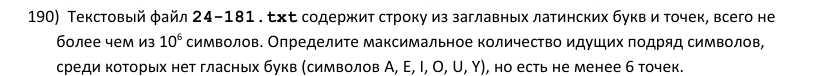

<details><summary>Текст условия</summary>Текстовый файл 24-181.txt содержит строку из заглавных латинских букв и точек, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых нет гласных букв (символов A, E, I, O, U, Y), но есть не менее 6 точек.</details>

**Способ 1:** метод замен + split

In [302]:
from re import sub
s = open('24-181.txt').readline().strip()
a = sub('[AEIOUY]', ' ', s).split()
print(max(len(x) for x in a if x.count('.') >= 6))

26


**Способ 2 (проверка):** регулярное выражение

In [303]:
from re import findall
s = open('24-181.txt').readline().strip()
print(max(len(x) for x in findall('[^AEIOUY]+', s) if x.count('.') >= 6))

26


**Ответ: `26`**

## Подстроки между ограничителями A и B

Подстрока начинается и заканчивается буквой A и не содержит других A — значит, это кусок между **соседними** A.
Берём список позиций `p` букв A (или A и B вместе) и проверяем каждую пару соседних позиций.

### Задача 191

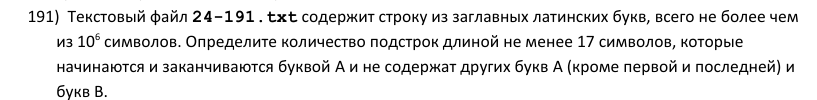

<details><summary>Текст условия</summary>Текстовый файл 24-191.txt содержит строку из заглавных латинских букв, всего не более чем из 10⁶ символов. Определите количество подстрок длиной не менее 17 символов, которые начинаются и заканчиваются буквой A и не содержат других букв A (кроме первой и последней) и букв B.</details>

**Способ 1:** список позиций A

In [304]:
s = open('24-191.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] == 'A']
k = 0
for j in range(len(p) - 1):
    t = s[p[j]:p[j+1] + 1]
    if len(t) >= 17 and 'B' not in t:
        k += 1
print(k)

597


**Способ 2 (проверка):** split по A

In [305]:
s = open('24-191.txt').readline().strip()
parts = s.split('A')[1:-1]                 # куски между соседними A
print(sum(1 for x in parts if len(x) + 2 >= 17 and 'B' not in x))

597


**Ответ: `597`**

### Задача 192

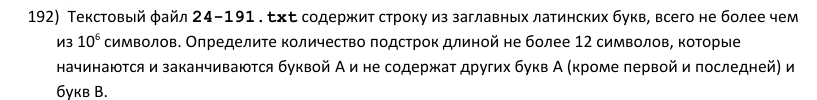

<details><summary>Текст условия</summary>Текстовый файл 24-191.txt содержит строку из заглавных латинских букв, всего не более чем из 10⁶ символов. Определите количество подстрок длиной не более 12 символов, которые начинаются и заканчиваются буквой A и не содержат других букв A (кроме первой и последней) и букв B.</details>

**Способ 1:** список позиций A

In [306]:
s = open('24-191.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] == 'A']
k = 0
for j in range(len(p) - 1):
    t = s[p[j]:p[j+1] + 1]
    if len(t) <= 12 and 'B' not in t:
        k += 1
print(k)

1118


**Способ 2 (проверка):** split по A

In [307]:
s = open('24-191.txt').readline().strip()
parts = s.split('A')[1:-1]
print(sum(1 for x in parts if len(x) + 2 <= 12 and 'B' not in x))

1118


**Ответ: `1118`**

*Задача 193 — подобная предыдущим, пропущена.*

### Задача 194

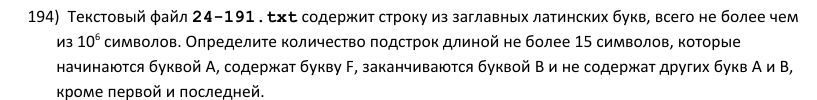

<details><summary>Текст условия</summary>Текстовый файл 24-191.txt содержит строку из заглавных латинских букв, всего не более чем из 10⁶ символов. Определите количество подстрок длиной не более 15 символов, которые начинаются буквой A, содержат букву F, заканчиваются буквой B и не содержат других букв A и B, кроме первой и последней.</details>

**Способ 1:** список позиций A и B

In [308]:
s = open('24-191.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] in 'AB']
k = 0
for j in range(len(p) - 1):
    t = s[p[j]:p[j+1] + 1]
    if t[0] == 'A' and t[-1] == 'B' and len(t) <= 15 and 'F' in t:
        k += 1
print(k)

245


**Способ 2 (проверка):** регулярное выражение A[^AB]*B

In [309]:
from re import findall
s = open('24-191.txt').readline().strip()
a = findall('A[^AB]*B', s)
print(sum(1 for t in a if len(t) <= 15 and 'F' in t))

245


**Ответ: `245`**

### Задача 195

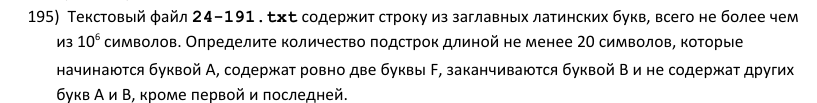

<details><summary>Текст условия</summary>Текстовый файл 24-191.txt содержит строку из заглавных латинских букв, всего не более чем из 10⁶ символов. Определите количество подстрок длиной не менее 20 символов, которые начинаются буквой A, содержат ровно две буквы F, заканчиваются буквой B и не содержат других букв A и B, кроме первой и последней.</details>

**Способ 1:** список позиций A и B

In [310]:
s = open('24-191.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] in 'AB']
k = 0
for j in range(len(p) - 1):
    t = s[p[j]:p[j+1] + 1]
    if t[0] == 'A' and t[-1] == 'B' and len(t) >= 20 and t.count('F') == 2:
        k += 1
print(k)

94


**Способ 2 (проверка):** регулярное выражение A[^AB]*B

In [311]:
from re import findall
s = open('24-191.txt').readline().strip()
a = findall('A[^AB]*B', s)
print(sum(1 for t in a if len(t) >= 20 and t.count('F') == 2))

94


**Ответ: `94`**

## Подряд идущие пары/тройки из набора

Если все комбинации начинаются с символа, который больше нигде в них не встречается (например, `Z`),
то разбиение строки на комбинации однозначно — работает **метод замен** (`Z[XY]` → `*`).
Если разбиение неоднозначно (`X*X`: в строке `XXXXX` тройки можно начать с разных мест), используем
**динамическое программирование**: `dp[i]` — сколько троек подряд заканчивается в позиции `i`,
`dp[i] = dp[i-3] + 1`, если `s[i-2:i+1]` подходит.

### Задача 196

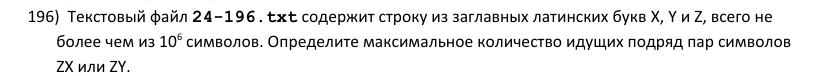

<details><summary>Текст условия</summary>Текстовый файл 24-196.txt содержит строку из заглавных латинских букв X, Y и Z, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд пар символов ZX или ZY.</details>

**Способ 1:** метод замен + groupby

In [312]:
from itertools import groupby
from re import sub
s = open('24-196.txt').readline().strip()
s = sub('Z[XY]', '*', s)
print(max(len(list(g)) for c, g in groupby(s) if c == '*'))

177


**Способ 2 (проверка):** регулярное выражение

In [313]:
from re import findall
s = open('24-196.txt').readline().strip()
print(max(map(len, findall('(?:Z[XY])+', s))) // 2)

177


**Ответ: `177`**

### Задача 197

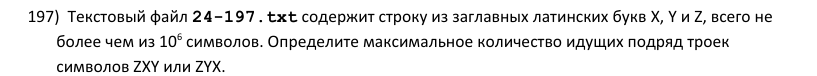

<details><summary>Текст условия</summary>Текстовый файл 24-197.txt содержит строку из заглавных латинских букв X, Y и Z, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд троек символов ZXY или ZYX.</details>

**Способ 1:** метод замен + groupby

In [314]:
from itertools import groupby
s = open('24-197.txt').readline().strip()
s = s.replace('ZXY', '*').replace('ZYX', '*')
print(max(len(list(g)) for c, g in groupby(s) if c == '*'))

28


**Способ 2 (проверка):** динамическое программирование

In [315]:
s = open('24-197.txt').readline().strip()
dp = [0] * len(s)
for i in range(2, len(s)):
    if s[i-2:i+1] in ('ZXY', 'ZYX'):
        dp[i] = dp[i-3] + 1 if i >= 3 else 1
print(max(dp))

28


**Ответ: `28`**

*Задача 198 — подобная предыдущим, пропущена.*

### Задача 199

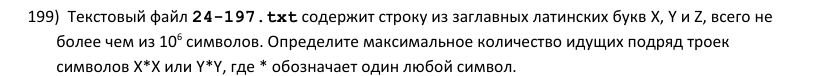

<details><summary>Текст условия</summary>Текстовый файл 24-197.txt содержит строку из заглавных латинских букв X, Y и Z, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд троек символов X*X или Y*Y, где * обозначает один любой символ.</details>

**Способ 1:** динамическое программирование

In [316]:
s = open('24-197.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — число подходящих троек подряд, последняя кончается в i
for i in range(2, len(s)):
    if s[i-2] == s[i] and s[i] in 'XY':
        dp[i] = dp[i-3] + 1 if i >= 3 else 1
print(max(dp))

16


**Способ 2 (проверка):** 3 сдвига + однопроходный алгоритм

In [317]:
s = open('24-197.txt').readline().strip()
mx = 0
for st in range(3):                 # 3 варианта выравнивания на тройки
    k = 0
    for i in range(st, len(s) - 2, 3):
        if s[i] == s[i+2] and s[i] in 'XY':
            k += 1
            mx = max(mx, k)
        else:
            k = 0
print(mx)

16


**Ответ: `16`**

## IP-адреса по маске

Маску удобно записать регулярным выражением и проверять **всю** строку функцией `fullmatch`:
`\d` — одна цифра, `\d?` — пустая строка или одна цифра, `\.` — именно точка. Различные адреса — через `set`.
Другой способ — `fnmatch` из стандартной библиотеки (там `?` — любой один символ, `*` — любая строка),
но маска `*` в `fnmatch` слишком широкая, поэтому её дополняют проверкой.

### Задача 200

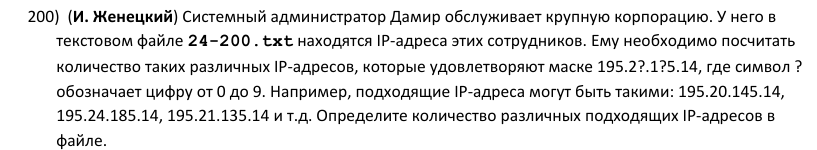

<details><summary>Текст условия</summary>(И. Женецкий) Системный администратор Дамир обслуживает крупную корпорацию. У него в текстовом файле 24-200.txt находятся IP-адреса этих сотрудников. Ему необходимо посчитать количество таких различных IP-адресов, которые удовлетворяют маске 195.2?.1?5.14, где символ ? обозначает цифру от 0 до 9. Например, подходящие IP-адреса могут быть такими: 195.20.145.14, 195.24.185.14, 195.21.135.14 и т.д. Определите количество различных подходящих IP-адресов в файле.</details>

**Способ 1:** регулярное выражение + set

In [318]:
from re import fullmatch
a = set(open('24-200.txt').read().split())
print(sum(1 for ip in a if fullmatch(r'195\.2\d\.1\d5\.14', ip)))

62


**Способ 2 (проверка):** fnmatch

In [319]:
from fnmatch import fnmatch
a = set(open('24-200.txt').read().split())
print(sum(1 for ip in a if fnmatch(ip, '195.2?.1?5.14') and all(c.isdigit() for c in ip.split('.')[1] + ip.split('.')[2])))

62


**Ответ: `62`**

### Задача 201

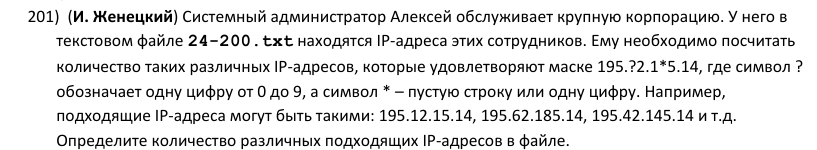

<details><summary>Текст условия</summary>(И. Женецкий) Системный администратор Алексей обслуживает крупную корпорацию. У него в текстовом файле 24-200.txt находятся IP-адреса этих сотрудников. Ему необходимо посчитать количество таких различных IP-адресов, которые удовлетворяют маске 195.?2.1*5.14, где символ ? обозначает одну цифру от 0 до 9, а символ * – пустую строку или одну цифру. Например, подходящие IP-адреса могут быть такими: 195.12.15.14, 195.62.185.14, 195.42.145.14 и т.д. Определите количество различных подходящих IP-адресов в файле.</details>

**Способ 1:** регулярное выражение + set

In [320]:
from re import fullmatch
a = set(open('24-200.txt').read().split())
print(sum(1 for ip in a if fullmatch(r'195\.\d2\.1\d?5\.14', ip)))

6


**Способ 2 (проверка):** разбор по split

In [321]:
a = set(open('24-200.txt').read().split())
k = 0
for ip in a:
    p = ip.split('.')
    if len(p) == 4 and p[0] == '195' and p[3] == '14' and len(p[1]) == 2 and p[1][1] == '2' \
       and p[2][0] == '1' and p[2][-1] == '5' and len(p[2]) in (2, 3):
        k += 1
print(k)

6


**Ответ: `6`**

*Задача 202 — подобная предыдущим, пропущена.*

### Задача 203

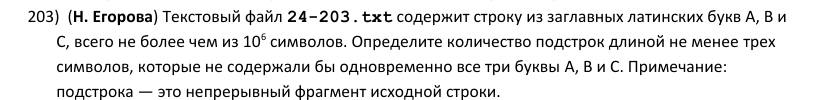

<details><summary>Текст условия</summary>(Н. Егорова) Текстовый файл 24-203.txt содержит строку из заглавных латинских букв A, B и C, всего не более чем из 106 символов. Определите количество подстрок длиной не менее трех символов, которые не содержали бы одновременно все три буквы A, B и C. Примечание: подстрока — это непрерывный фрагмент исходной строки.</details>

**Способ 1:** однопроходный подсчёт

In [322]:
s = open('24-203.txt').readline().strip()
last = {'A': -1, 'B': -1, 'C': -1}
total = 0
for R in range(len(s)):
    last[s[R]] = R
    m = min(last.values())        # при L <= m в подстроке s[L..R] есть все три буквы
    # подходят L от m+1 до R-2 (длина не меньше 3)
    total += max(0, (R - 2) - (m + 1) + 1)
print(total)

252776


**Способ 2 (проверка):** формула включений-исключений

In [323]:
s = open('24-203.txt').readline().strip()
# подстроки без буквы X — это подстроки кусков s.split(X); вычитаем двойной учёт (кусков из одной буквы)
from itertools import groupby
def cnt(L):                       # число подстрок длины >= 3 в куске длины L
    return (L - 2) * (L - 1) // 2 if L >= 3 else 0
total = 0
for x in 'ABC':
    total += sum(cnt(len(t)) for t in s.split(x))
total -= sum(cnt(len(list(g))) for c, g in groupby(s))   # куски из одной буквы посчитаны дважды
print(total)

252776


**Ответ: `252776`**

### Задача 204

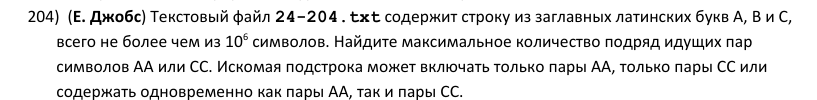

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-204.txt содержит строку из заглавных латинских букв A, B и C, всего не более чем из 106 символов. Найдите максимальное количество подряд идущих пар символов AA или CC. Искомая подстрока может включать только пары АA, только пары CС или содержать одновременно как пары АA, так и пары CC.</details>

**Способ 1:** динамическое программирование

In [324]:
s = open('24-204.txt').readline().strip()
dp = [0] * len(s)       # dp[i] — пар подряд, последняя пара кончается в i
for i in range(1, len(s)):
    if s[i-1:i+1] in ('AA', 'CC'):
        dp[i] = dp[i-2] + 1 if i >= 2 else 1
print(max(dp))

1310


**Способ 2 (проверка):** 2 сдвига + однопроходный алгоритм

In [325]:
from re import findall
s = open('24-204.txt').readline().strip()
# два варианта выравнивания: начинаем с позиции 0 или 1
mx = 0
for st in range(2):
    k = 0
    for i in range(st, len(s) - 1, 2):
        k = k + 1 if s[i:i+2] in ('AA', 'CC') else 0
        mx = max(mx, k)
print(mx)

1310


**Ответ: `1310`**

## Не более k вхождений: список позиций / два указателя

Для символа — список позиций с фиктивными краями (`-1` и `len(s)`), ответ `p[j+k+1] - p[j] - 1`.
Для подстроки длины `m` (например, `2022`, `KEGE`) вхождение «лежит в подстроке», только если попало туда
**целиком**. Поэтому от вхождения `j` можно взять левую границу `p[j] + 1` (вхождение `j` уже разрушено),
а правую — `p[j+k+1] + m - 2` (вхождение `j+k+1` ещё не дописано). Длина `p[j+k+1] - p[j] + m - 2`.

### Задача 205

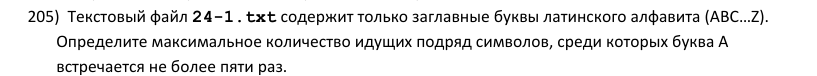

<details><summary>Текст условия</summary>Текстовый файл 24-1.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите максимальное количество идущих подряд символов, среди которых буква A встречается не более пяти раз.</details>

**Способ 1:** список позиций

In [326]:
s = open('24-1.txt').readline().strip()
p = [-1] + [i for i in range(len(s)) if s[i] == 'A'] + [len(s)]
print(max(p[j+6] - p[j] - 1 for j in range(len(p) - 6)))

229


**Способ 2 (проверка):** два указателя

In [327]:
s = open('24-1.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    k += s[R] == 'A'
    while k > 5:
        k -= s[L] == 'A'
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

229


**Ответ: `229`**

### Задача 206

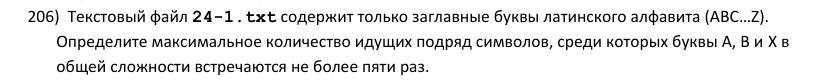

<details><summary>Текст условия</summary>Текстовый файл 24-1.txt содержит только заглавные буквы латинского алфавита (ABC…Z). Определите максимальное количество идущих подряд символов, среди которых буквы A, B и X в общей сложности встречаются не более пяти раз.</details>

**Способ 1:** список позиций

In [328]:
s = open('24-1.txt').readline().strip()
p = [-1] + [i for i in range(len(s)) if s[i] in 'ABX'] + [len(s)]
print(max(p[j+6] - p[j] - 1 for j in range(len(p) - 6)))

64


**Способ 2 (проверка):** два указателя

In [329]:
s = open('24-1.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    k += s[R] in 'ABX'
    while k > 5:
        k -= s[L] in 'ABX'
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

64


**Ответ: `64`**

*Задача 207 — подобная предыдущим, пропущена.*

### Задача 208

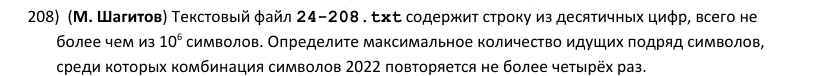

<details><summary>Текст условия</summary>(М. Шагитов) Текстовый файл 24-208.txt содержит строку из десятичных цифр, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд символов, среди которых комбинация символов 2022 повторяется не более четырёх раз.</details>

**Способ 1:** список позиций подстроки

In [330]:
s = open('24-208.txt').readline().strip()
n = len(s)
p = [-1] + [i for i in range(n - 3) if s[i:i+4] == '2022'] + [n - 3]
k = 4
print(max(p[j+k+1] - p[j] + 2 for j in range(len(p) - k - 1)))

2502


**Способ 2 (проверка):** два указателя

In [331]:
s = open('24-208.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    if R >= 3 and s[R-3:R+1] == '2022':
        k += 1
    while k > 4:
        if s[L:L+4] == '2022':
            k -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

2502


**Ответ: `2502`**

### Задача 209

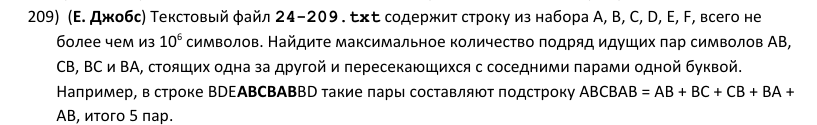

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-209.txt содержит строку из набора A, B, C, D, E, F, всего не более чем из 10⁶ символов. Найдите максимальное количество подряд идущих пар символов АB, CB, BС и BA, стоящих одна за другой и пересекающихся с соседними парами одной буквой. Например, в строке BDEABCBABBD такие пары составляют подстроку ABCBAB = AB + BC + CB + BA + AB, итого 5 пар.</details>

**Способ 1:** однопроходный алгоритм

In [332]:
s = open('24-209.txt').readline().strip()
k = mx = 0                 # k — число пар в текущей цепочке
for i in range(1, len(s)):
    if s[i-1:i+1] in ('AB', 'CB', 'BC', 'BA'):
        k += 1
        mx = max(mx, k)
    else:
        k = 0
print(mx)

16


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [333]:
from re import findall
s = open('24-209.txt').readline().strip()
# цепочка — это чередование B и (A или C), длиной не меньше 2
a = findall('(?=([AC]?(?:B[AC])*B?))', s)
print(max(len(x) for x in a) - 1)

16


**Ответ: `16`**

### Задача 210

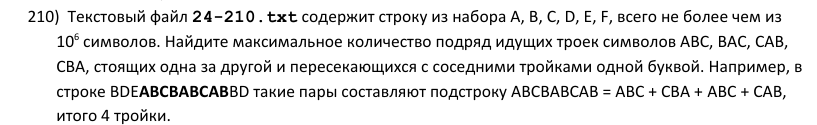

<details><summary>Текст условия</summary>Текстовый файл 24-210.txt содержит строку из набора A, B, C, D, E, F, всего не более чем из 10⁶ символов. Найдите максимальное количество подряд идущих троек символов ABC, BAC, CAB, CBA, стоящих одна за другой и пересекающихся с соседними тройками одной буквой. Например, в строке BDEABCBABCABBD такие пары составляют подстроку ABCBABCAB = ABC + СBA + ABC + CAB, итого 4 тройки.</details>

**Способ 1:** динамическое программирование

In [334]:
s = open('24-210.txt').readline().strip()
good = ('ABC', 'BAC', 'CAB', 'CBA')
dp = [0] * len(s)        # dp[i] — троек в цепочке, последняя тройка кончается в i
for i in range(2, len(s)):
    if s[i-2:i+1] in good:
        dp[i] = dp[i-2] + 1 if i >= 4 else 1   # предыдущая тройка кончается в i-2 (общая буква)
print(max(dp))

47


**Способ 2 (проверка):** 2 сдвига + однопроходный алгоритм

In [335]:
s = open('24-210.txt').readline().strip()
good = ('ABC', 'BAC', 'CAB', 'CBA')
mx = 0
for st in range(2):                  # тройки идут с шагом 2
    k = 0
    for i in range(st, len(s) - 2, 2):
        k = k + 1 if s[i:i+3] in good else 0
        mx = max(mx, k)
print(mx)

47


**Ответ: `47`**

*Задача 211 — подобная предыдущим, пропущена.*

## Пары и тройки вида «согласная + гласная», «буква + цифра»

**Метод замен** из статьи К.Ю. Полякова: заменяем все согласные на `s`, гласные на `g` (или буквы на `b`,
цифры на `d`), затем каждую нужную пару (тройку) — на `*`. Остаётся найти самую длинную цепочку `*`.
Осторожно: если шаблон может начинаться в разных местах (`ss` в `sss`), замена «съест» неудачное выравнивание.
Надёжный способ — **ДП**: `dp[i] = dp[i-m] + 1`, если `s[i-m+1:i+1]` подходит (m — длина шаблона).

### Задача 212

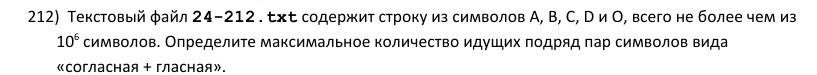

<details><summary>Текст условия</summary>Текстовый файл 24-212.txt содержит строку из символов A, B, C, D и O, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд пар символов вида «согласная + гласная».</details>

**Способ 1:** динамическое программирование

In [336]:
s = open('24-212.txt').readline().strip()
dp = [0] * len(s)
for i in range(1, len(s)):
    if s[i-1] in 'BCD' and s[i] in 'AO':
        dp[i] = dp[i-2] + 1 if i >= 2 else 1
print(max(dp))

202


**Способ 2 (проверка):** метод замен

In [337]:
from itertools import groupby
from re import sub
s = open('24-212.txt').readline().strip()
s = sub('[BCD]', 's', s)
s = sub('[AO]', 'g', s)
s = s.replace('sg', '*')          # 'sg' не перекрывается сам с собой — замена корректна
print(max(len(list(g)) for c, g in groupby(s) if c == '*'))

202


**Ответ: `202`**

### Задача 213

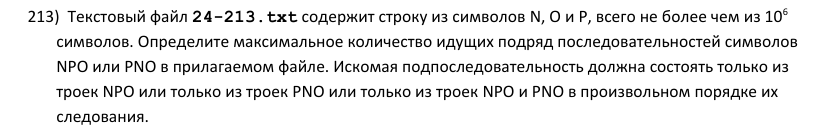

<details><summary>Текст условия</summary>Текстовый файл 24-213.txt содержит строку из символов N, O и P, всего не более чем из 10⁶ символов. Определите максимальное количество идущих подряд последовательностей символов NРО или РNО в прилагаемом файле. Искомая подпоследовательность должна состоять только из троек NРО или только из троек РNО или только из троек NРО и РNО в произвольном порядке их следования.</details>

**Способ 1:** метод замен + split

In [338]:
from re import sub
s = open('24-213.txt').readline().strip()
s = s.replace('NPO', '*').replace('PNO', '*')
s = sub('[NPO]', ' ', s)
print(len(max(s.split(), key=len)))

297


**Способ 2 (проверка):** динамическое программирование

In [339]:
s = open('24-213.txt').readline().strip()
dp = [0] * len(s)
for i in range(2, len(s)):
    if s[i-2:i+1] in ('NPO', 'PNO'):
        dp[i] = dp[i-3] + 1 if i >= 3 else 1
print(max(dp))

297


**Ответ: `297`**

*Задача 214 — подобная предыдущим, пропущена.*

### Задача 215

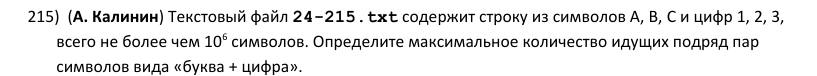

<details><summary>Текст условия</summary>(А. Калинин) Текстовый файл 24-215.txt содержит строку из символов A, B, C и цифр 1, 2, 3, всего не более чем 10⁶ символов. Определите максимальное количество идущих подряд пар символов вида «буква + цифра».</details>

**Способ 1:** динамическое программирование

In [340]:
s = open('24-215.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — групп «буква + цифра» подряд, последняя кончается в i
for i in range(1, len(s)):
    if s[i-1] in 'ABC' and s[i] in '123':
        dp[i] = dp[i-2] + 1 if i >= 2 else 1
print(max(dp))

183


**Способ 2 (проверка):** метод замен + перебор выравниваний

In [341]:
from re import sub
s = open('24-215.txt').readline().strip()
s = sub('[ABC]', 'b', s)
s = sub('[123]', 'd', s)
mx = 0
for st in range(2):             # 2 варианта выравнивания
    k = 0
    for i in range(st, len(s) - 1, 2):
        k = k + 1 if s[i:i+2] == 'bd' else 0
        mx = max(mx, k)
print(mx)

183


**Ответ: `183`**

### Задача 216

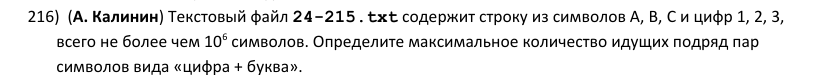

<details><summary>Текст условия</summary>(А. Калинин) Текстовый файл 24-215.txt содержит строку из символов A, B, C и цифр 1, 2, 3, всего не более чем 10⁶ символов. Определите максимальное количество идущих подряд пар символов вида «цифра + буква».</details>

**Способ 1:** динамическое программирование

In [342]:
s = open('24-215.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — групп «цифра + буква» подряд, последняя кончается в i
for i in range(1, len(s)):
    if s[i-1] in '123' and s[i] in 'ABC':
        dp[i] = dp[i-2] + 1 if i >= 2 else 1
print(max(dp))

182


**Способ 2 (проверка):** метод замен + перебор выравниваний

In [343]:
from re import sub
s = open('24-215.txt').readline().strip()
s = sub('[ABC]', 'b', s)
s = sub('[123]', 'd', s)
mx = 0
for st in range(2):             # 2 варианта выравнивания
    k = 0
    for i in range(st, len(s) - 1, 2):
        k = k + 1 if s[i:i+2] == 'db' else 0
        mx = max(mx, k)
print(mx)

182


**Ответ: `182`**

*Задача 217 — подобная предыдущим, пропущена.*

### Задача 218

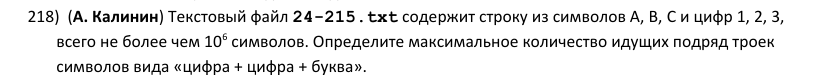

<details><summary>Текст условия</summary>(А. Калинин) Текстовый файл 24-215.txt содержит строку из символов A, B, C и цифр 1, 2, 3, всего не более чем 10⁶ символов. Определите максимальное количество идущих подряд троек символов вида «цифра + цифра + буква».</details>

**Способ 1:** динамическое программирование

In [344]:
s = open('24-215.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — групп «цифра + цифра + буква» подряд, последняя кончается в i
for i in range(2, len(s)):
    if s[i-2] in '123' and s[i-1] in '123' and s[i] in 'ABC':
        dp[i] = dp[i-3] + 1 if i >= 3 else 1
print(max(dp))

165


**Способ 2 (проверка):** метод замен + перебор выравниваний

In [345]:
from re import sub
s = open('24-215.txt').readline().strip()
s = sub('[ABC]', 'b', s)
s = sub('[123]', 'd', s)
mx = 0
for st in range(3):             # 3 варианта выравнивания
    k = 0
    for i in range(st, len(s) - 2, 3):
        k = k + 1 if s[i:i+3] == 'ddb' else 0
        mx = max(mx, k)
print(mx)

165


**Ответ: `165`**

### Задача 219

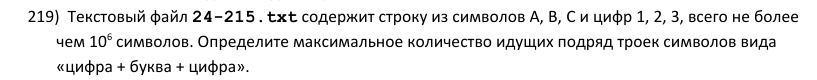

<details><summary>Текст условия</summary>Текстовый файл 24-215.txt содержит строку из символов A, B, C и цифр 1, 2, 3, всего не более чем 10⁶ символов. Определите максимальное количество идущих подряд троек символов вида «цифра + буква + цифра».</details>

**Способ 1:** динамическое программирование

In [346]:
s = open('24-215.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — групп «цифра + буква + цифра» подряд, последняя кончается в i
for i in range(2, len(s)):
    if s[i-2] in '123' and s[i-1] in 'ABC' and s[i] in '123':
        dp[i] = dp[i-3] + 1 if i >= 3 else 1
print(max(dp))

164


**Способ 2 (проверка):** метод замен + перебор выравниваний

In [347]:
from re import sub
s = open('24-215.txt').readline().strip()
s = sub('[ABC]', 'b', s)
s = sub('[123]', 'd', s)
mx = 0
for st in range(3):             # 3 варианта выравнивания
    k = 0
    for i in range(st, len(s) - 2, 3):
        k = k + 1 if s[i:i+3] == 'dbd' else 0
        mx = max(mx, k)
print(mx)

164


**Ответ: `164`**

*Задача 220 — подобная предыдущим, пропущена.*

### Задача 221

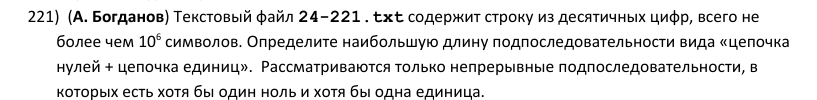

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-221.txt содержит строку из десятичных цифр, всего не более чем 10⁶ символов. Определите наибольшую длину подпоследовательности вида «цепочка нулей + цепочка единиц».  Рассматриваются только непрерывные подпоследовательности, в которых есть хотя бы один ноль и хотя бы одна единица.</details>

**Способ 1:** groupby: соседние участки

In [348]:
from itertools import groupby
s = open('24-221.txt').readline().strip()
g = [(c, len(list(x))) for c, x in groupby(s)]
print(max(g[i][1] + g[i+1][1] for i in range(len(g) - 1) if g[i][0] == '0' and g[i+1][0] == '1'))

58


**Способ 2 (проверка):** регулярное выражение 0+1+

In [349]:
from re import findall
s = open('24-221.txt').readline().strip()
print(max(map(len, findall('0+1+', s))))

58


**Ответ: `58`**

## Строки из заданных фрагментов

**Динамическое программирование** (пример из статьи К.Ю. Полякова): `dp[i]` — длина самой длинной правильной
цепочки, которая заканчивается символом `s[i]`. Если последний фрагмент — `AB`, то `dp[i] = dp[i-2] + 2`;
если `CAC`, то `dp[i] = dp[i-3] + 3`; берём максимум. Ответ — `max(dp)`.
Метод работает, даже когда фрагменты пересекаются и замены дают неправильный результат.

### Задача 222

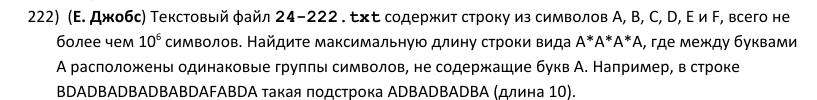

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-222.txt содержит строку из символов A, B, C, D, E и F, всего не более чем 10⁶ символов. Найдите максимальную длину строки вида А*А*А*А, где между буквами А расположены одинаковые группы символов, не содержащие букв А. Например, в строке BDADBADBADBABDAFABDA такая подстрока ADBADBADBA (длина 10).</details>

**Способ 1:** список позиций A + сравнение групп

In [350]:
s = open('24-222.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] == 'A']
mx = 0
for j in range(len(p) - 3):
    g1 = s[p[j]+1:p[j+1]]
    g2 = s[p[j+1]+1:p[j+2]]
    g3 = s[p[j+2]+1:p[j+3]]
    if g1 == g2 == g3:
        mx = max(mx, p[j+3] - p[j] + 1)
print(mx)

13


**Способ 2 (проверка):** split по A

In [351]:
s = open('24-222.txt').readline().strip()
parts = s.split('A')            # группы между соседними A
mx = 0
for j in range(1, len(parts) - 3):
    if parts[j] == parts[j+1] == parts[j+2]:
        mx = max(mx, 3 * len(parts[j]) + 4)
print(mx)

13


**Ответ: `13`**

### Задача 223

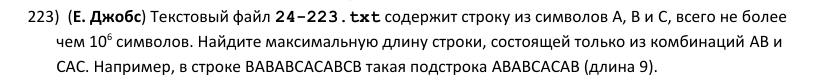

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-223.txt содержит строку из символов A, B и C, всего не более чем 10⁶ символов. Найдите максимальную длину строки, состоящей только из комбинаций AB и СAС. Например, в строке BABABCACABCB такая подстрока ABABCACAB (длина 9).</details>

**Способ 1:** динамическое программирование

In [352]:
s = open('24-223.txt').readline().strip()
n = len(s)
dp = [0] * (n + 1)      # dp[i] — длина цепочки, заканчивающейся перед позицией i (т.е. на s[i-1])
for i in range(2, n + 1):
    if s[i-2:i] == 'AB':
        dp[i] = dp[i-2] + 2
    if i >= 3 and s[i-3:i] == 'CAC':
        dp[i] = max(dp[i], dp[i-3] + 3)
print(max(dp))

69


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [353]:
from re import findall
s = open('24-223.txt').readline().strip()
print(max(map(len, findall('(?=((?:AB|CAC)+))', s))))

69


**Ответ: `69`**

*Задача 224 — подобная предыдущим, пропущена.*

## Числа по маске между парами символов (П. Финкель)

Маску переводим в регулярное выражение: каждый `?` — это `\d`. Ограничители `FF … FF` добавляем в шаблон,
а саму маску берём в группу. Конструкция `(?=...)` нужна, потому что закрывающая пара одного числа может
быть открывающей для следующего (`FF4411781113FF4499789993FF`).

> Файлы этой серии содержат пару «русских» символов, поэтому открываем их с `encoding='cp1251'`.

### Задача 225

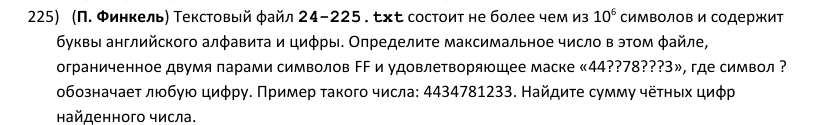

<details><summary>Текст условия</summary>(П. Финкель) Текстовый файл 24-225.txt состоит не более чем из 10⁶ символов и содержит буквы английского алфавита и цифры. Определите максимальное число в этом файле, ограниченное двумя парами символов FF и удовлетворяющее маске «44??78???3», где символ ? обозначает любую цифру. Пример такого числа: 4434781233. Найдите сумму чётных цифр найденного числа.</details>

**Способ 1:** регулярное выражение по маске

In [354]:
from math import prod
from re import findall
s = open('24-225.txt', encoding='cp1251').readline().strip()
a = findall(r'(?=FF(44\d\d78\d\d\d3)FF)', s)
x = max(a, key=int)
D = [int(c) for c in x]
print(x, sum(d for d in D if d % 2 == 0))    # число и ответ (сумма чётных цифр)

4488789673 38


**Способ 2 (проверка):** перебор окон + fnmatch

In [355]:
from math import prod
from fnmatch import fnmatch
s = open('24-225.txt', encoding='cp1251').readline().strip()
L = 10
best = -1
for i in range(len(s) - L - 3):
    t = s[i:i + L + 4]
    if t[:2] == 'FF' and t[-2:] == 'FF' and t[2:-2].isdigit() and fnmatch(t[2:-2], '44??78???3'):
        best = max(best, int(t[2:-2]))
D = [int(c) for c in str(best)]
print(best, sum(d for d in D if d % 2 == 0))

4488789673 38


**Ответ: `38`**

### Задача 226

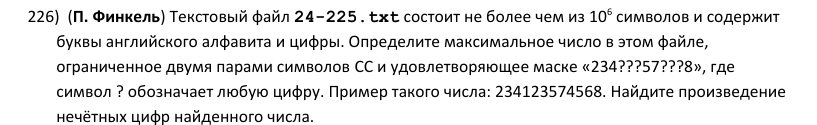

<details><summary>Текст условия</summary>(П. Финкель) Текстовый файл 24-225.txt состоит не более чем из 10⁶ символов и содержит буквы английского алфавита и цифры. Определите максимальное число в этом файле, ограниченное двумя парами символов CC и удовлетворяющее маске «234???57???8», где символ ? обозначает любую цифру. Пример такого числа: 234123574568. Найдите произведение нечётных цифр найденного числа.</details>

**Способ 1:** регулярное выражение по маске

In [356]:
from math import prod
from re import findall
s = open('24-225.txt', encoding='cp1251').readline().strip()
a = findall(r'(?=CC(234\d\d\d57\d\d\d8)CC)', s)
x = max(a, key=int)
D = [int(c) for c in x]
print(x, prod(d for d in D if d % 2 == 1))    # число и ответ (произведение нечётных цифр)

234773577898 972405


**Способ 2 (проверка):** перебор окон + fnmatch

In [357]:
from math import prod
from fnmatch import fnmatch
s = open('24-225.txt', encoding='cp1251').readline().strip()
L = 12
best = -1
for i in range(len(s) - L - 3):
    t = s[i:i + L + 4]
    if t[:2] == 'CC' and t[-2:] == 'CC' and t[2:-2].isdigit() and fnmatch(t[2:-2], '234???57???8'):
        best = max(best, int(t[2:-2]))
D = [int(c) for c in str(best)]
print(best, prod(d for d in D if d % 2 == 1))

234773577898 972405


**Ответ: `972405`**

*Задача 227 — подобная предыдущим, пропущена.*

### Задача 228

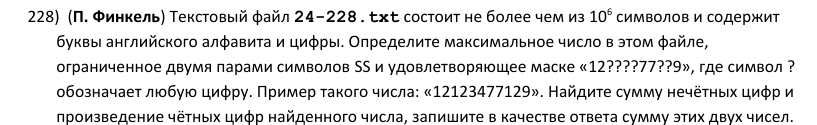

<details><summary>Текст условия</summary>(П. Финкель) Текстовый файл 24-228.txt состоит не более чем из 10⁶ символов и содержит буквы английского алфавита и цифры. Определите максимальное число в этом файле, ограниченное двумя парами символов SS и удовлетворяющее маске «12????77??9», где символ ? обозначает любую цифру. Пример такого числа: «12123477129». Найдите сумму нечётных цифр и произведение чётных цифр найденного числа, запишите в качестве ответа сумму этих двух чисел.</details>

**Способ 1:** регулярное выражение по маске

In [358]:
from math import prod
from re import findall
s = open('24-228.txt', encoding='cp1251').readline().strip()
a = findall(r'(?=SS(12\d\d\d\d77\d\d9)SS)', s)
x = max(a, key=int)
D = [int(c) for c in x]
print(x, sum(d for d in D if d % 2 == 1) + prod(d for d in D if d % 2 == 0))    # число и ответ (сумма нечётных + произведение чётных)

12888877679 49183


**Способ 2 (проверка):** перебор окон + fnmatch

In [359]:
from math import prod
from fnmatch import fnmatch
s = open('24-228.txt', encoding='cp1251').readline().strip()
L = 11
best = -1
for i in range(len(s) - L - 3):
    t = s[i:i + L + 4]
    if t[:2] == 'SS' and t[-2:] == 'SS' and t[2:-2].isdigit() and fnmatch(t[2:-2], '12????77??9'):
        best = max(best, int(t[2:-2]))
D = [int(c) for c in str(best)]
print(best, sum(d for d in D if d % 2 == 1) + prod(d for d in D if d % 2 == 0))

12888877679 49183


**Ответ: `49183`**

### Задача 229

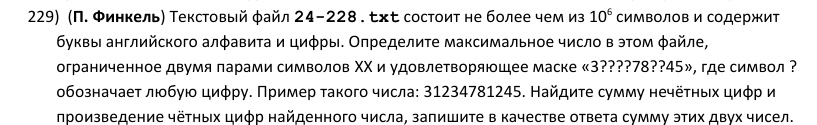

<details><summary>Текст условия</summary>(П. Финкель) Текстовый файл 24-228.txt состоит не более чем из 10⁶ символов и содержит буквы английского алфавита и цифры. Определите максимальное число в этом файле, ограниченное двумя парами символов XX и удовлетворяющее маске «3????78??45», где символ ? обозначает любую цифру. Пример такого числа: 31234781245. Найдите сумму нечётных цифр и произведение чётных цифр найденного числа, запишите в качестве ответа сумму этих двух чисел.</details>

**Способ 1:** регулярное выражение по маске

In [360]:
from math import prod
from re import findall
s = open('24-228.txt', encoding='cp1251').readline().strip()
a = findall(r'(?=XX(3\d\d\d\d78\d\d45)XX)', s)
x = max(a, key=int)
D = [int(c) for c in x]
print(x, sum(d for d in D if d % 2 == 1) + prod(d for d in D if d % 2 == 0))    # число и ответ (сумма нечётных + произведение чётных)

38765784345 6174


**Способ 2 (проверка):** перебор окон + fnmatch

In [361]:
from math import prod
from fnmatch import fnmatch
s = open('24-228.txt', encoding='cp1251').readline().strip()
L = 11
best = -1
for i in range(len(s) - L - 3):
    t = s[i:i + L + 4]
    if t[:2] == 'XX' and t[-2:] == 'XX' and t[2:-2].isdigit() and fnmatch(t[2:-2], '3????78??45'):
        best = max(best, int(t[2:-2]))
D = [int(c) for c in str(best)]
print(best, sum(d for d in D if d % 2 == 1) + prod(d for d in D if d % 2 == 0))

38765784345 6174


**Ответ: `6174`**

*Задача 230 — подобная предыдущим, пропущена.*

### Задача 231

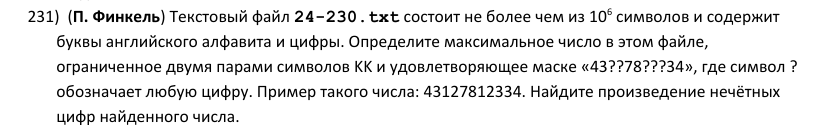

<details><summary>Текст условия</summary>(П. Финкель) Текстовый файл 24-230.txt состоит не более чем из 10⁶ символов и содержит буквы английского алфавита и цифры. Определите максимальное число в этом файле, ограниченное двумя парами символов KK и удовлетворяющее маске «43??78???34», где символ ? обозначает любую цифру. Пример такого числа: 43127812334. Найдите произведение нечётных цифр найденного числа.</details>

**Способ 1:** регулярное выражение по маске

In [362]:
from math import prod
from re import findall
s = open('24-230.txt', encoding='cp1251').readline().strip()
a = findall(r'(?=KK(43\d\d78\d\d\d34)KK)', s)
x = max(a, key=int)
D = [int(c) for c in x]
print(x, prod(d for d in D if d % 2 == 1))    # число и ответ (произведение нечётных цифр)

43997853334 229635


**Способ 2 (проверка):** перебор окон + fnmatch

In [363]:
from math import prod
from fnmatch import fnmatch
s = open('24-230.txt', encoding='cp1251').readline().strip()
L = 11
best = -1
for i in range(len(s) - L - 3):
    t = s[i:i + L + 4]
    if t[:2] == 'KK' and t[-2:] == 'KK' and t[2:-2].isdigit() and fnmatch(t[2:-2], '43??78???34'):
        best = max(best, int(t[2:-2]))
D = [int(c) for c in str(best)]
print(best, prod(d for d in D if d % 2 == 1))

43997853334 229635


**Ответ: `229635`**

## Разные авторские задачи

Комбинируем приёмы: `split` по разделителю, `findall` с проверками соседей, `Counter`, перебор окон.

### Задача 232

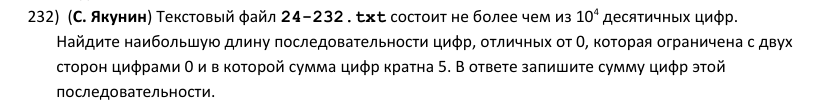

<details><summary>Текст условия</summary>(С. Якунин) Текстовый файл 24-232.txt состоит не более чем из 10⁴ десятичных цифр. Найдите наибольшую длину последовательности цифр, отличных от 0, которая ограничена с двух сторон цифрами 0 и в которой сумма цифр кратна 5. В ответе запишите сумму цифр этой последовательности.</details>

**Способ 1:** split по нулям

In [364]:
s = open('24-232.txt').readline().strip()
parts = s.split('0')[1:-1]          # только куски, ограниченные нулями с обеих сторон
good = [x for x in parts if x and sum(map(int, x)) % 5 == 0]
L = max(map(len, good))
best = [x for x in good if len(x) == L]
print(len(best), L, sum(map(int, best[0])))   # сколько таких, длина, сумма цифр

1 79 375


**Способ 2 (проверка):** регулярное выражение

In [365]:
from re import findall
s = open('24-232.txt').readline().strip()
a = findall('(?<=0)[1-9]+(?=0)', s)
a = [x for x in a if sum(map(int, x)) % 5 == 0]
w = max(a, key=len)
print(len([x for x in a if len(x) == len(w)]), len(w), sum(map(int, w)))

1 79 375


**Ответ: `375`**

> Программа печатает: сколько найдено самых длинных подходящих последовательностей, их длину и сумму цифр. Ответ — сумма цифр.

### Задача 233

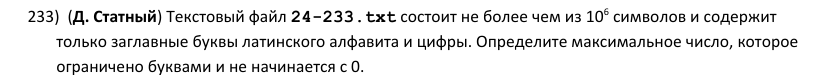

<details><summary>Текст условия</summary>(Д. Статный) Текстовый файл 24-233.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и цифры. Определите максимальное число, которое ограничено буквами и не начинается с 0.</details>

**Способ 1:** регулярное выражение с проверкой соседей

In [366]:
from re import findall
s = open('24-233.txt').readline().strip()
a = findall(r'(?<=[A-Z])[1-9]\d*(?=[A-Z])', s)
print(max(map(int, a)))

6769550677


**Способ 2 (проверка):** метод замен

In [367]:
from re import sub
s = open('24-233.txt').readline().strip()
parts = sub('[A-Z]', ' ', s).split(' ')[1:-1]   # только числа, ограниченные буквами с двух сторон
print(max(int(x) for x in parts if x and x[0] != '0'))

6769550677


**Ответ: `6769550677`**

### Задача 234

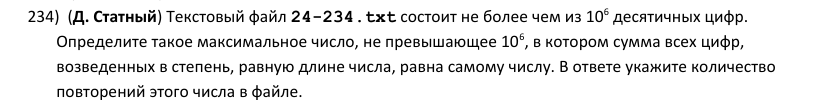

<details><summary>Текст условия</summary>(Д. Статный) Текстовый файл 24-234.txt состоит не более чем из 10⁶ десятичных цифр. Определите такое максимальное число, не превышающее 106, в котором сумма всех цифр, возведенных в степень, равную длине числа, равна самому числу. В ответе укажите количество повторений этого числа в файле.</details>

**Способ 1:** перебор чисел + count

In [368]:
s = open('24-234.txt').readline().strip()
arm = [x for x in range(1, 10**6 + 1) if sum(int(d) ** len(str(x)) for d in str(x)) == x]
x = max(arm)
print(x, s.count(str(x)))

548834 1


**Способ 2 (проверка):** проверка вручную + перебор окон

In [369]:
s = open('24-234.txt').readline().strip()
x = 548834             # 5^6+4^6+8^6+8^6+3^6+4^6 = 548834
print(x, sum(1 for i in range(len(s) - 5) if s[i:i+6] == str(x)))

548834 1


**Ответ: `1`**

> Числа Армстронга до 10^6: 1–9, 153, 370, 371, 407, 1634, 8208, 9474, 54748, 92727, 93084, 548834.

### Задача 235

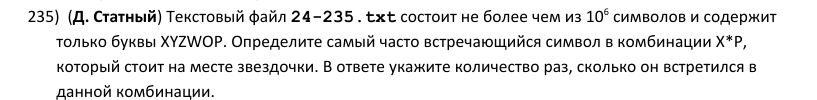

<details><summary>Текст условия</summary>(Д. Статный) Текстовый файл 24-235.txt состоит не более чем из 10⁶ символов и содержит только буквы XYZWOP. Определите самый часто встречающийся символ в комбинации X*P, который стоит на месте звездочки. В ответе укажите количество раз, сколько он встретился в данной комбинации.</details>

**Способ 1:** Counter по позициям X?P

In [370]:
from collections import Counter
s = open('24-235.txt').readline().strip()
cnt = Counter(s[i+1] for i in range(len(s) - 2) if s[i] == 'X' and s[i+2] == 'P')
print(cnt.most_common(1))

[('X', 4683)]


**Способ 2 (проверка):** регулярное выражение

In [371]:
from collections import Counter
from re import findall
s = open('24-235.txt').readline().strip()
print(Counter(findall('(?<=X).(?=P)', s)).most_common(1))

[('X', 4683)]


**Ответ: `4683`**

### Задача 236

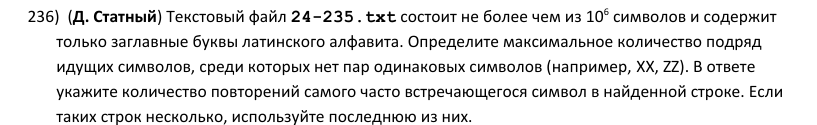

<details><summary>Текст условия</summary>(Д. Статный) Текстовый файл 24-235.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество подряд идущих символов, среди которых нет пар одинаковых символов (например, XX, ZZ). В ответе укажите количество повторений самого часто встречающегося символ в найденной строке. Если таких строк несколько, используйте последнюю из них.</details>

**Способ 1:** однопроходный алгоритм + Counter

In [372]:
from collections import Counter
s = open('24-235.txt').readline().strip()
start = 0
mx, best = 1, 0
for i in range(1, len(s)):
    if s[i] == s[i-1]:
        start = i
    if i - start + 1 >= mx:          # >= — при равенстве берём последнюю
        mx, best = i - start + 1, start
t = s[best:best + mx]
print(mx, Counter(t).most_common(1))

69 [('O', 19)]


**Способ 2 (проверка):** метод замен + split

In [373]:
from collections import Counter
from re import sub
s = open('24-235.txt').readline().strip()
a = sub(r'(.)(?=\1)', r'\1 ', s).split()
mx = max(map(len, a))
t = [x for x in a if len(x) == mx][-1]
print(mx, Counter(t).most_common(1))

69 [('O', 19)]


**Ответ: `19`**

### Задача 237

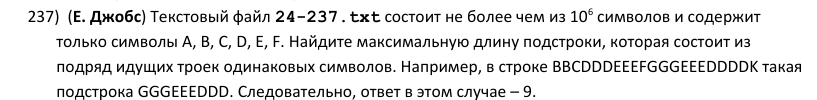

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-237.txt состоит не более чем из 10⁶ символов и содержит только символы A, B, C, D, E, F. Найдите максимальную длину подстроки, которая состоит из подряд идущих троек одинаковых символов. Например, в строке BBCDDDEEEFGGGEEEDDDDK такая подстрока GGGEEEDDD. Следовательно, ответ в этом случае – 9.</details>

**Способ 1:** динамическое программирование

In [374]:
s = open('24-237.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — длина цепочки троек, заканчивающейся в i
for i in range(2, len(s)):
    if s[i-2] == s[i-1] == s[i]:
        dp[i] = dp[i-3] + 3 if i >= 3 else 3
print(max(dp))

15


**Способ 2 (проверка):** 3 сдвига + однопроходный алгоритм

In [375]:
s = open('24-237.txt').readline().strip()
mx = 0
for st in range(3):
    k = 0
    for i in range(st, len(s) - 2, 3):
        k = k + 3 if s[i] == s[i+1] == s[i+2] else 0
        mx = max(mx, k)
print(mx)

15


**Ответ: `15`**

> Соседние тройки могут состоять и из одинаковых букв (AAAAAA = AAA + AAA) — условие этого не запрещает.

### Задача 238

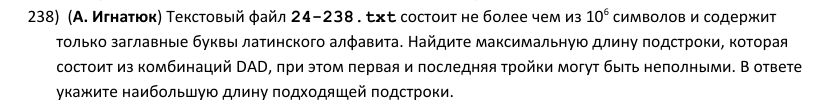

<details><summary>Текст условия</summary>(А. Игнатюк) Текстовый файл 24-238.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Найдите максимальную длину подстроки, которая состоит из комбинаций DAD, при этом первая и последняя тройки могут быть неполными. В ответе укажите наибольшую длину подходящей подстроки.</details>

**Способ 1:** однопроходный алгоритм для 3 сдвигов

In [376]:
s = open('24-238.txt').readline().strip()
p = 'DAD'
mx = 0
for sh in range(3):          # фаза: с какой буквы шаблона начинается строка
    k = 0
    for i in range(len(s)):
        k = k + 1 if s[i] == p[(i + sh) % 3] else 0
        mx = max(mx, k)
print(mx)

99


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [377]:
from re import findall
s = open('24-238.txt').readline().strip()
pat = '(?=((?:AD|D)?(?:DAD)*(?:DA|D)?))'
print(max(map(len, findall(pat, s))))

99


**Ответ: `99`**

### Задача 239

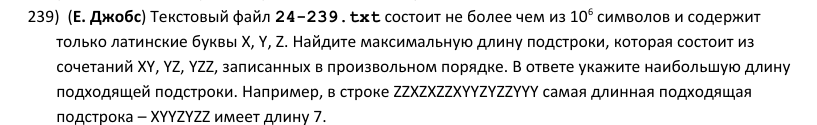

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-239.txt состоит не более чем из 10⁶ символов и содержит только латинские буквы X, Y, Z. Найдите максимальную длину подстроки, которая состоит из сочетаний XY, YZ, YZZ, записанных в произвольном порядке. В ответе укажите наибольшую длину подходящей подстроки. Например, в строке ZZXZXZZXYYZYZZYYY самая длинная подходящая подстрока – XYYZYZZ имеет длину 7.</details>

**Способ 1:** динамическое программирование

In [378]:
s = open('24-239.txt').readline().strip()
N = len(s)
dp = [0] * N
for i in range(N):
    if s[i-1:i+1] in ['XY', 'YZ']:
        dp[i] = 2 + dp[i-2]
    if s[i-2:i+1] in ['YZZ']:
        dp[i] = max(dp[i], 3 + dp[i-3])
print(max(dp))

314


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [379]:
from re import findall
s = open('24-239.txt').readline().strip()
expr = '(?:YZZ|XY|YZ)+'
print(max(map(len, findall(f'(?=({expr}))', s))))

314


**Ответ: `314`**

### Задача 240

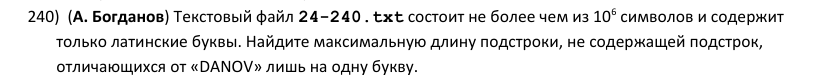

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-240.txt состоит не более чем из 10⁶ символов и содержит только латинские буквы. Найдите максимальную длину подстроки, не содержащей подстрок, отличающихся от «DANOV» лишь на одну букву.</details>

**Способ 1:** список «плохих» позиций

In [380]:
s = open('24-240.txt').readline().strip()
w = 'DANOV'
def bad(i):              # s[i:i+5] отличается от DANOV ровно одной буквой
    return sum(s[i+j] != w[j] for j in range(5)) == 1
last = -1                # начало последнего плохого фрагмента, целиком лежащего левее R
mx = 0
for R in range(len(s)):
    if R >= 4 and bad(R - 4):
        last = R - 4
    mx = max(mx, R - last)
print(mx)

229549


**Способ 2 (проверка):** регулярное выражение + список позиций

In [381]:
from re import finditer
s = open('24-240.txt').readline().strip()
w = 'DANOV'
pat = '|'.join(w[:j] + f'[^{w[j]}]' + w[j+1:] for j in range(5))   # .ANOV|D.NOV|... с «не той» буквой
b = [m.start() for m in finditer(f'(?=(?:{pat}))', s)]
b = [-1] + b + [len(s) - 4]
print(max(b[j+1] - b[j] + 3 for j in range(len(b) - 1)))

229549


**Ответ: `229549`**

## Группы «согласная + согласная + гласная» и цепочки между буквами O/E/F

Группы — **ДП с шагом 3**. Цепочки «от O до O» — **split** по букве O: куски между соседними O
проверяем по условию и склеиваем подряд идущие хорошие куски.

### Задача 241

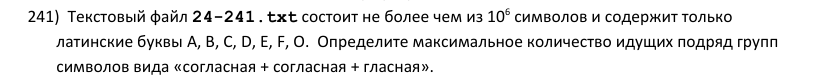

<details><summary>Текст условия</summary>Текстовый файл 24-241.txt состоит не более чем из 10⁶ символов и содержит только латинские буквы A, B, C, D, E, F, O.  Определите максимальное количество идущих подряд групп символов вида «согласная + согласная + гласная».</details>

**Способ 1:** динамическое программирование

In [382]:
s = open('24-241.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — групп «согласная + согласная + гласная» подряд, последняя кончается в i
for i in range(2, len(s)):
    if s[i-2] in 'BCDF' and s[i-1] in 'BCDF' and s[i] in 'AEO':
        dp[i] = dp[i-3] + 1 if i >= 3 else 1
print(max(dp))

19


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [383]:
from re import findall
s = open('24-241.txt').readline().strip()
print(max(map(len, findall('(?=((?:[BCDF][BCDF][AEO])+))', s))) // 3)

19


**Ответ: `19`**

### Задача 242

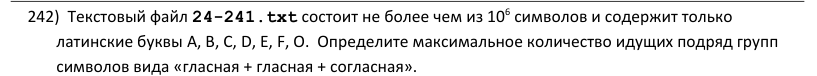

<details><summary>Текст условия</summary>Текстовый файл 24-241.txt состоит не более чем из 10⁶ символов и содержит только латинские буквы A, B, C, D, E, F, O.  Определите максимальное количество идущих подряд групп символов вида «гласная + гласная + согласная».</details>

**Способ 1:** динамическое программирование

In [384]:
s = open('24-241.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — групп «гласная + гласная + согласная» подряд, последняя кончается в i
for i in range(2, len(s)):
    if s[i-2] in 'AEO' and s[i-1] in 'AEO' and s[i] in 'BCDF':
        dp[i] = dp[i-3] + 1 if i >= 3 else 1
print(max(dp))

14


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [385]:
from re import findall
s = open('24-241.txt').readline().strip()
print(max(map(len, findall('(?=((?:[AEO][AEO][BCDF])+))', s))) // 3)

14


**Ответ: `14`**

### Задача 243

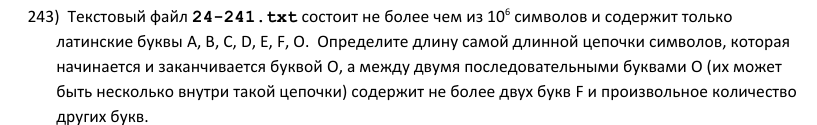

<details><summary>Текст условия</summary>Текстовый файл 24-241.txt состоит не более чем из 10⁶ символов и содержит только латинские буквы A, B, C, D, E, F, O.  Определите длину самой длинной цепочки символов, которая начинается и заканчивается буквой O, а между двумя последовательными буквами O (их может быть несколько внутри такой цепочки) содержит не более двух букв F и произвольное количество других букв.</details>

**Способ 1:** split по O

In [386]:
s = open('24-241.txt').readline().strip()
parts = s.split('O')[1:-1]       # куски между соседними O
mx = cur = 0                     # cur — длина текущей цепочки без последней O
for x in parts:
    if x.count('F') <= 2:
        cur += len(x) + 1
        mx = max(mx, cur + 1)
    else:
        cur = 0
print(mx)

565


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [387]:
from re import findall
s = open('24-241.txt').readline().strip()
seg = '[^OF]*(?:F[^OF]*){0,2}'    # кусок без O, в котором не больше двух F
a = findall(f'(?=(O(?:{seg}O)+))', s)
print(max(map(len, a)))

565


**Ответ: `565`**

### Задача 244

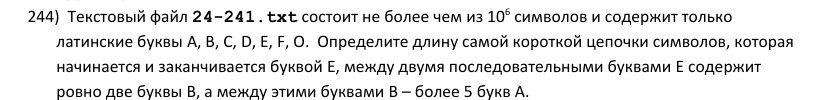

<details><summary>Текст условия</summary>Текстовый файл 24-241.txt состоит не более чем из 10⁶ символов и содержит только латинские буквы A, B, C, D, E, F, O.  Определите длину самой короткой цепочки символов, которая начинается и заканчивается буквой E, между двумя последовательными буквами E содержит ровно две буквы B, а между этими буквами B – более 5 букв A.</details>

**Способ 1:** split по E

In [388]:
s = open('24-241.txt').readline().strip()
parts = s.split('E')[1:-1]
mn = 10**9
for x in parts:
    if x.count('B') == 2:
        i, j = x.find('B'), x.rfind('B')
        if x[i+1:j].count('A') > 5:
            mn = min(mn, len(x) + 2)
print(mn)

13


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [389]:
from re import findall
s = open('24-241.txt').readline().strip()
a = findall('(?=(E[^EB]*B([^EB]*)B[^EB]*E))', s)
print(min(len(t) for t, mid in a if mid.count('A') > 5))

13


**Ответ: `13`**

> Самая короткая цепочка — это всегда кусок между двумя соседними E (добавление других кусков её только удлиняет).

*Задача 245 — подобная предыдущим, пропущена.*

### Задача 246

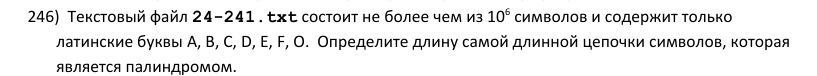

<details><summary>Текст условия</summary>Текстовый файл 24-241.txt состоит не более чем из 10⁶ символов и содержит только латинские буквы A, B, C, D, E, F, O.  Определите длину самой длинной цепочки символов, которая является палиндромом.</details>

**Способ 1:** расширение от центра

In [390]:
s = open('24-241.txt').readline().strip()
n = len(s)
mx = 1
for c in range(2 * n - 1):       # центр — символ (чётный c) или промежуток между символами (нечётный c)
    L, R = c // 2, (c + 1) // 2
    while L >= 0 and R < n and s[L] == s[R]:
        L -= 1
        R += 1
    mx = max(mx, R - L - 1)
print(mx)

19


**Способ 2 (проверка):** алгоритм Манакера

In [391]:
s = open('24-241.txt').readline().strip()
# алгоритм Манакера (линейный)
t = '^#' + '#'.join(s) + '#$'
P = [0] * len(t)
C = R = 0
for i in range(1, len(t) - 1):
    if i < R:
        P[i] = min(R - i, P[2 * C - i])
    while t[i + P[i] + 1] == t[i - P[i] - 1]:
        P[i] += 1
    if i + P[i] > R:
        C, R = i, i + P[i]
print(max(P))

19


**Ответ: `19`**

### Задача 247

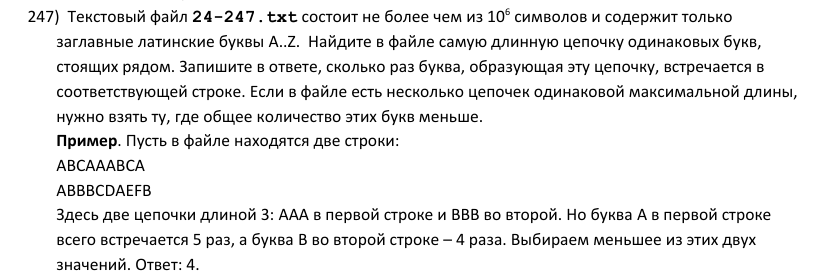

<details><summary>Текст условия</summary>Текстовый файл 24-247.txt состоит не более чем из 10⁶ символов и содержит только заглавные латинские буквы A..Z.  Найдите в файле самую длинную цепочку одинаковых букв, стоящих рядом. Запишите в ответе, сколько раз буква, образующая эту цепочку, встречается в соответствующей строке. Если в файле есть несколько цепочек одинаковой максимальной длины, нужно взять ту, где общее количество этих букв меньше.<br>Пример. Пусть в файле находятся две строки:<br>ABCAAABCA<br>ABBBCDAEFB<br>Здесь две цепочки длиной 3: AAA в первой строке и BBB во второй. Но буква A в первой строке всего встречается 5 раз, а буква B во второй строке – 4 раза. Выбираем меньшее из этих двух значений. Ответ: 4.</details>

**Способ 1:** groupby по строкам

In [392]:
from itertools import groupby
a = open('24-247.txt').read().split()
best = (0, 0)                     # (длина цепочки, -количество буквы в строке)
for t in a:
    for c, g in groupby(t):
        L = len(list(g))
        best = max(best, (L, -t.count(c)))
print(-best[1])

22


**Способ 2 (проверка):** регулярное выражение (.)\1*

In [393]:
from re import finditer
a = open('24-247.txt').read().split()
mx = max(len(m.group()) for t in a for m in finditer(r'(.)\1*', t))
print(min(t.count(m.group()[0]) for t in a for m in finditer(r'(.)\1*', t) if len(m.group()) == mx))

22


**Ответ: `22`**

### Задача 248

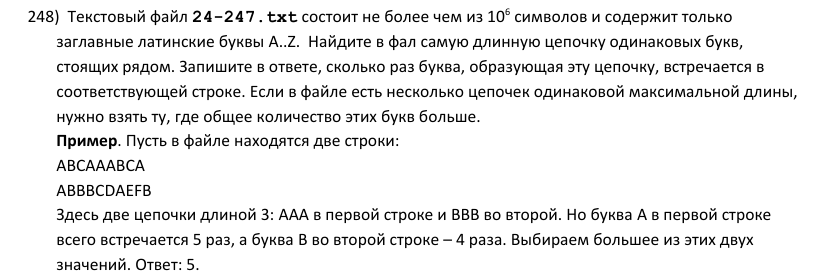

<details><summary>Текст условия</summary>Текстовый файл 24-247.txt состоит не более чем из 10⁶ символов и содержит только заглавные латинские буквы A..Z.  Найдите в фал самую длинную цепочку одинаковых букв, стоящих рядом. Запишите в ответе, сколько раз буква, образующая эту цепочку, встречается в соответствующей строке. Если в файле есть несколько цепочек одинаковой максимальной длины, нужно взять ту, где общее количество этих букв больше.<br>Пример. Пусть в файле находятся две строки:<br>ABCAAABCA<br>ABBBCDAEFB<br>Здесь две цепочки длиной 3: AAA в первой строке и BBB во второй. Но буква A в первой строке всего встречается 5 раз, а буква B во второй строке – 4 раза. Выбираем большее из этих двух значений. Ответ: 5.</details>

**Способ 1:** groupby по строкам

In [394]:
from itertools import groupby
a = open('24-247.txt').read().split()
best = (0, 0)                     # (длина цепочки, количество буквы в строке)
for t in a:
    for c, g in groupby(t):
        L = len(list(g))
        best = max(best, (L, t.count(c)))
print(best[1])

29


**Способ 2 (проверка):** регулярное выражение (.)\1*

In [395]:
from re import finditer
a = open('24-247.txt').read().split()
mx = max(len(m.group()) for t in a for m in finditer(r'(.)\1*', t))
print(max(t.count(m.group()[0]) for t in a for m in finditer(r'(.)\1*', t) if len(m.group()) == mx))

29


**Ответ: `29`**

## Минимальная подстрока: два указателя

**Минимум методом двух указателей.** Двигаем правую границу `R`; пока подстрока `s[L..R]` остаётся правильной
**и без левого символа**, сдвигаем `L` вправо. После этого `R - L + 1` — самая короткая правильная подстрока,
заканчивающаяся в `R`. Для счётчиков удобен словарь `cnt`.

### Задача 249

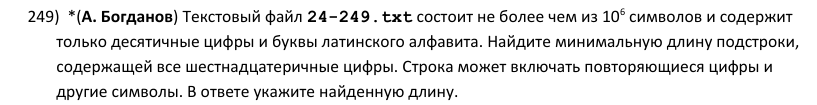

<details><summary>Текст условия</summary>*(А. Богданов) Текстовый файл 24-249.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и буквы латинского алфавита. Найдите минимальную длину подстроки, содержащей все шестнадцатеричные цифры. Строка может включать повторяющиеся цифры и другие символы. В ответе укажите найденную длину.</details>

**Способ 1:** два указателя + словарь

In [396]:
s = open('24-249.txt').readline().strip()
hexd = '0123456789ABCDEF'
cnt = {c: 0 for c in hexd}
have = 0                     # сколько разных шестнадцатеричных цифр в окне
L = 0
mn = 10**9
for R in range(len(s)):
    if s[R] in cnt:
        cnt[s[R]] += 1
        if cnt[s[R]] == 1:
            have += 1
    while have == 16:
        mn = min(mn, R - L + 1)
        if s[L] in cnt:
            cnt[s[L]] -= 1
            if cnt[s[L]] == 0:
                have -= 1
        L += 1
print(mn)

42


**Способ 2 (проверка):** последние вхождения

In [397]:
s = open('24-249.txt').readline().strip()
hexd = '0123456789ABCDEF'
last = {c: -1 for c in hexd}      # последнее вхождение каждой цифры
mn = 10**9
for R in range(len(s)):
    if s[R] in last:
        last[s[R]] = R
        m = min(last.values())
        if m >= 0:
            mn = min(mn, R - m + 1)
print(mn)

42


**Ответ: `42`**

### Задача 250

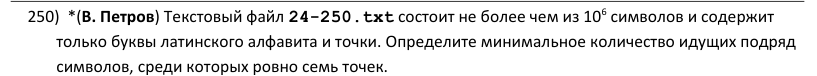

<details><summary>Текст условия</summary>*(В. Петров) Текстовый файл 24-250.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита и точки. Определите минимальное количество идущих подряд символов, среди которых ровно семь точек.</details>

**Способ 1:** список позиций точек

In [398]:
s = open('24-250.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] == '.']
print(min(p[j+6] - p[j] + 1 for j in range(len(p) - 6)))

16


**Способ 2 (проверка):** два указателя

In [399]:
s = open('24-250.txt').readline().strip()
L = k = 0
mn = 10**9
for R in range(len(s)):
    k += s[R] == '.'
    while k > 7 or (k == 7 and s[L] != '.'):
        k -= s[L] == '.'
        L += 1
    if k == 7:
        mn = min(mn, R - L + 1)
print(mn)

16


**Ответ: `16`**

## Авторские задачи 251–264

Снова комбинируем приёмы: **список позиций** ограничителей, **регулярные выражения с `(?=…)`** для
перекрывающихся совпадений, **ДП** для цепочек из фрагментов и **однопроходные алгоритмы с «ожидаемым символом»**.

### Задача 251

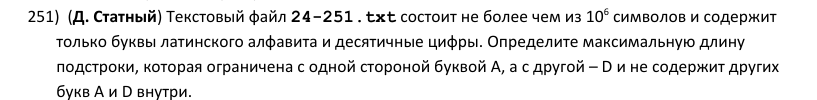

<details><summary>Текст условия</summary>(Д. Статный) Текстовый файл 24-251.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита и десятичные цифры. Определите максимальную длину подстроки, которая ограничена с одной стороной буквой A, а с другой – D и не содержит других букв A и D внутри.</details>

**Способ 1:** список позиций A и D

In [400]:
s = open('24-251.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] in 'AD']
print(max(p[j+1] - p[j] + 1 for j in range(len(p) - 1) if s[p[j]] != s[p[j+1]]))

273


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [401]:
from re import findall
s = open('24-251.txt').readline().strip()
a = findall('(?=(A[^AD]*D|D[^AD]*A))', s)
print(max(map(len, a)))

273


**Ответ: `273`**

### Задача 252

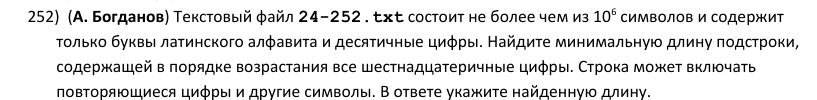

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-252.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита и десятичные цифры. Найдите минимальную длину подстроки, содержащей в порядке возрастания все шестнадцатеричные цифры. Строка может включать повторяющиеся цифры и другие символы. В ответе укажите найденную длину.</details>

**Способ 1:** однопроходный алгоритм: начало частичного совпадения

In [402]:
s = open('24-252.txt').readline().strip()
pat = '0123456789ABCDEF'
st = [-1] * 16          # st[k] — самое правое начало, с которого уже собраны pat[0..k] по порядку
mn = 10**9
for i, c in enumerate(s):
    k = pat.find(c)
    if k == 0:
        st[0] = i
    elif k > 0 and st[k-1] != -1:
        st[k] = st[k-1]
        if k == 15:
            mn = min(mn, i - st[15] + 1)
print(mn)

153


**Способ 2 (проверка):** жадный поиск от каждого 0 (find)

In [403]:
s = open('24-252.txt').readline().strip()
pat = '0123456789ABCDEF'
mn = 10**9
i = s.find('0')
while i != -1:                   # для каждого 0 жадно ищем 1, потом 2, ... , F
    j = i
    for c in pat[1:]:
        j = s.find(c, j + 1)
        if j == -1:
            break
    if j == -1:
        break
    mn = min(mn, j - i + 1)
    i = s.find('0', i + 1)
print(mn)

153


**Ответ: `153`**

### Задача 253

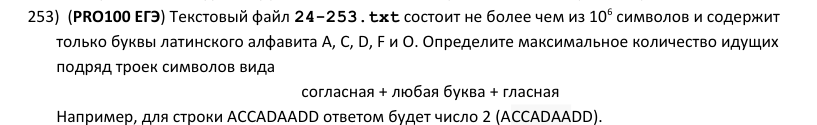

<details><summary>Текст условия</summary>(PRO100 ЕГЭ) Текстовый файл 24-253.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита A, C, D, F и O. Определите максимальное количество идущих подряд троек символов вида<br>согласная + любая буква + гласная<br>Например, для строки ACCADAADD ответом будет число 2 (ACCADAADD).</details>

**Способ 1:** динамическое программирование

In [404]:
s = open('24-253.txt').readline().strip()
dp = [0] * len(s)        # dp[i] — троек подряд, последняя кончается в i
for i in range(2, len(s)):
    if s[i-2] in 'CDF' and s[i] in 'AO':
        dp[i] = dp[i-3] + 1 if i >= 3 else 1
print(max(dp))

6


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [405]:
from re import findall
s = open('24-253.txt').readline().strip()
print(max(map(len, findall('(?=((?:[CDF].[AO])+))', s))) // 3)

6


**Ответ: `6`**

### Задача 254

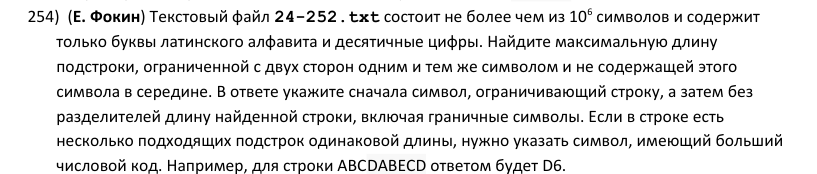

<details><summary>Текст условия</summary>(Е. Фокин) Текстовый файл 24-252.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита и десятичные цифры. Найдите максимальную длину подстроки, ограниченной с двух сторон одним и тем же символом и не содержащей этого символа в середине. В ответе укажите сначала символ, ограничивающий строку, а затем без разделителей длину найденной строки, включая граничные символы. Если в строке есть несколько подходящих подстрок одинаковой длины, нужно указать символ, имеющий больший числовой код. Например, для строки ABCDABECD ответом будет D6.</details>

**Способ 1:** словарь последних вхождений

In [406]:
s = open('24-252.txt').readline().strip()
last = {}
best = (0, '')
for i, c in enumerate(s):
    if c in last:
        best = max(best, (i - last[c] + 1, c))   # при равной длине — символ с большим кодом
    last[c] = i
print(best[1] + str(best[0]))

D9747


**Способ 2 (проверка):** список позиций для каждого символа

In [407]:
s = open('24-252.txt').readline().strip()
res = []
for c in set(s):
    p = [i for i in range(len(s)) if s[i] == c]
    if len(p) > 1:
        res.append((max(p[j+1] - p[j] + 1 for j in range(len(p) - 1)), c))
L, c = max(res)
print(c + str(L))

D9747


**Ответ: `D9747`**

### Задача 255

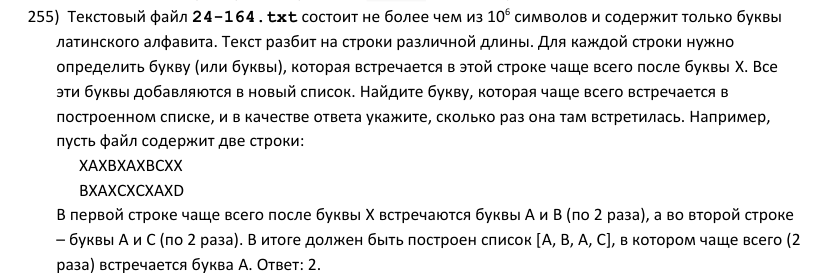

<details><summary>Текст условия</summary>Текстовый файл 24-164.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита. Текст разбит на строки различной длины. Для каждой строки нужно определить букву (или буквы), которая встречается в этой строке чаще всего после буквы X. Все эти буквы добавляются в новый список. Найдите букву, которая чаще всего встречается в построенном списке, и в качестве ответа укажите, сколько раз она там встретилась. Например, пусть файл содержит две строки:<br>XAXBXAXBCXX<br>BXAXCXCXAXD<br>В первой строке чаще всего после буквы X встречаются буквы А и B (по 2 раза), а во второй строке – буквы A и С (по 2 раза). В итоге должен быть построен список [A, B, A, C], в котором чаще всего (2 раза) встречается буква A. Ответ: 2.</details>

**Способ 1:** Counter по каждой строке

In [408]:
from collections import Counter
a = open('24-164.txt').read().split()
lst = []
for t in a:
    cnt = Counter(t[i+1] for i in range(len(t) - 1) if t[i] == 'X')
    if cnt:
        mx = max(cnt.values())
        lst += [c for c in cnt if cnt[c] == mx]
print(Counter(lst).most_common(1)[0][1])

928


**Способ 2 (проверка):** словари + регулярное выражение

In [409]:
from re import findall
a = open('24-164.txt').read().split()
total = {}
for t in a:
    d = {}
    for c in findall('(?<=X).', t):
        d[c] = d.get(c, 0) + 1
    if d:
        mx = max(d.values())
        for c in d:
            if d[c] == mx:
                total[c] = total.get(c, 0) + 1
print(max(total.values()))

928


**Ответ: `928`**

### Задача 256

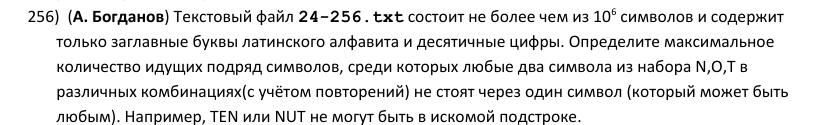

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-256.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и десятичные цифры. Определите максимальное количество идущих подряд символов, среди которых любые два символа из набора N,O,T в различных комбинациях(с учётом повторений) не стоят через один символ (который может быть любым). Например, ТEN или NUТ не могут быть в искомой подстроке.</details>

**Способ 1:** список «плохих» позиций

In [410]:
s = open('24-256.txt').readline().strip()
last = -1          # левый символ последней «плохой» пары (символы из NOT через один)
mx = 0
for R in range(len(s)):
    if R >= 2 and s[R] in 'NOT' and s[R-2] in 'NOT':
        last = R - 2
    mx = max(mx, R - last)     # подстрока s[last+1 .. R]
print(mx)

1461


**Способ 2 (проверка):** два указателя

In [411]:
s = open('24-256.txt').readline().strip()
L = mx = 0
for R in range(len(s)):
    if R - 2 >= L and s[R] in 'NOT' and s[R-2] in 'NOT':
        L = R - 1
    mx = max(mx, R - L + 1)
print(mx)

1461


**Ответ: `1461`**

### Задача 257

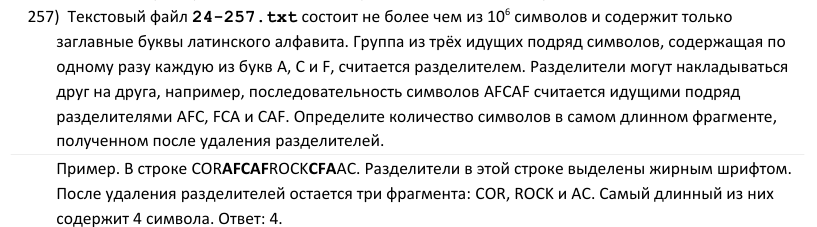

<details><summary>Текст условия</summary>Текстовый файл 24-257.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Группа из трёх идущих подряд символов, содержащая по одному разу каждую из букв A, C и F, считается разделителем. Разделители могут накладываться друг на друга, например, последовательность символов AFCAF считается идущими подряд разделителями AFC, FCA и CAF. Определите количество символов в самом длинном фрагменте, полученном после удаления разделителей.<br>Пример. В строке CORAFCAFROCKCFAAC. Разделители в этой строке выделены жирным шрифтом. После удаления разделителей остается три фрагмента: COR, ROCK и AC. Самый длинный из них содержит 4 символа. Ответ: 4.</details>

**Способ 1:** пометка символов разделителей

In [412]:
s = open('24-257.txt').readline().strip()
cover = [False] * len(s)
for i in range(len(s) - 2):
    if sorted(s[i:i+3]) == ['A', 'C', 'F']:
        cover[i] = cover[i+1] = cover[i+2] = True
k = mx = 0
for i in range(len(s)):
    k = 0 if cover[i] else k + 1
    mx = max(mx, k)
print(mx)

532


**Способ 2 (проверка):** регулярное выражение + split

In [413]:
from re import finditer
s = list(open('24-257.txt').readline().strip())
t = ''.join(s)
for m in finditer('(?=(ACF|AFC|CAF|CFA|FAC|FCA))', t):
    i = m.start()
    s[i] = s[i+1] = s[i+2] = ' '
print(max(map(len, ''.join(s).split())))

532


**Ответ: `532`**

### Задача 258

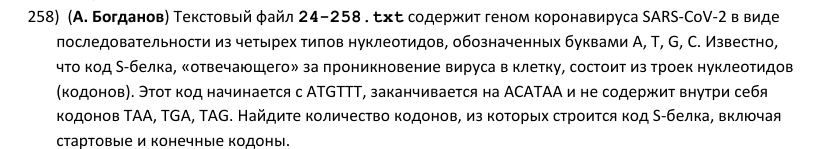

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-258.txt содержит геном коронавируса SARS-CoV-2 в виде последовательности из четырех типов нуклеотидов, обозначенных буквами A, T, G, C. Известно, что код S-белка, «отвечающего» за проникновение вируса в клетку, состоит из троек нуклеотидов (кодонов). Этот код начинается с ATGTTT, заканчивается на ACATAA и не содержит внутри себя кодонов TAA, TGA, TAG. Найдите количество кодонов, из которых строится код S-белка, включая стартовые и конечные кодоны.</details>

**Способ 1:** чтение по кодонам

In [414]:
s = open('24-258.txt').readline().strip()
stop = ('TAA', 'TGA', 'TAG')
p = s.find('ATGTTT')
while p != -1:
    q = p
    while q + 3 <= len(s) and s[q:q+3] not in stop:
        q += 3
    if s[q-3:q+3] == 'ACATAA':
        print(p, (q + 3 - p) // 3)   # начало и число кодонов
    p = s.find('ATGTTT', p + 1)

21562 1274


**Способ 2 (проверка):** регулярное выражение по кодонам

In [415]:
from re import finditer
s = open('24-258.txt').readline().strip()
# кодоны от ATGTTT: любые тройки, кроме стоп-кодонов, затем ACA и TAA
for m in finditer('(?=(ATGTTT(?:(?!TAA|TGA|TAG)...)*?ACATAA))', s):
    t = m.group(1)
    print(m.start(), len(t) // 3)

21562 1274


**Ответ: `1274`**

### Задача 259

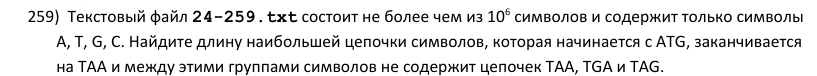

<details><summary>Текст условия</summary>Текстовый файл 24-259.txt состоит не более чем из 10⁶ символов и содержит только символы A, T, G, C. Найдите длину наибольшей цепочки символов, которая начинается с ATG, заканчивается на TAA и между этими группами символов не содержит цепочек TAA, TGA и TAG.</details>

**Способ 1:** бинарный поиск по позициям ATG

In [416]:
from bisect import bisect_left
s = open('24-259.txt').readline().strip()
n = len(s)
atg = [i for i in range(n - 2) if s[i:i+3] == 'ATG']
lastBad = -10          # начало последней «стоп-тройки», целиком лежащей левее q
mx = 0
for q in range(n - 2):
    if q >= 3 and s[q-3:q] in ('TAA', 'TGA', 'TAG'):
        lastBad = q - 3
    if s[q:q+3] == 'TAA':
        # нужен ATG в позиции p: p + 3 > lastBad (середина без стоп-троек) и p + 3 <= q
        j = bisect_left(atg, max(0, lastBad - 2))
        if j < len(atg) and atg[j] + 3 <= q:
            mx = max(mx, q + 3 - atg[j])
print(mx)

124


**Способ 2 (проверка):** массив «следующая стоп-тройка»

In [417]:
s = open('24-259.txt').readline().strip()
n = len(s)
nxt = [n] * (n + 3)    # nxt[i] — ближайшее начало стоп-тройки в позиции >= i
for i in range(n - 3, -1, -1):
    nxt[i] = i if s[i:i+3] in ('TAA', 'TGA', 'TAG') else nxt[i+1]
mx = 0
for p in range(n - 2):
    if s[p:p+3] == 'ATG':
        b = nxt[p + 3]                  # первая стоп-тройка после ATG
        if b < n and s[b:b+3] == 'TAA':
            mx = max(mx, b + 3 - p)
print(mx)

124


**Ответ: `124`**

### Задача 260

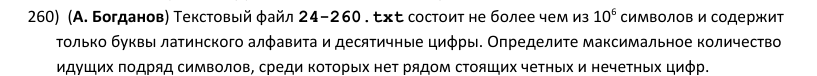

<details><summary>Текст условия</summary>(А. Богданов) Текстовый файл 24-260.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита и десятичные цифры. Определите максимальное количество идущих подряд символов, среди которых нет рядом стоящих четных и нечетных цифр.</details>

**Способ 1:** однопроходный алгоритм

In [418]:
s = open('24-260.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    a, b = s[i-1], s[i]
    if a.isdigit() and b.isdigit() and int(a) % 2 != int(b) % 2:
        k = 1
    else:
        k += 1
    mx = max(mx, k)
print(mx)

263


**Способ 2 (проверка):** вставка пробелов регулярным выражением

In [419]:
from re import sub
s = open('24-260.txt').readline().strip()
s = sub('(?<=[02468])(?=[13579])|(?<=[13579])(?=[02468])', ' ', s)   # пробел между цифрами разной чётности
print(max(map(len, s.split())))

263


**Ответ: `263`**

### Задача 261

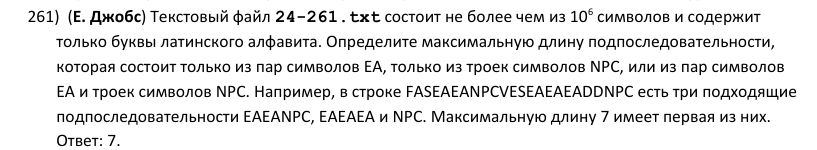

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-261.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита. Определите максимальную длину подпоследовательности, которая состоит только из пар символов EA, только из троек символов NPC, или из пар символов EA и троек символов NPC. Например, в строке FASEAEANPCVESEAEAEADDNPC есть три подходящие подпоследовательности EAEANPC, EAEAEA и NPC. Максимальную длину 7 имеет первая из них. Ответ: 7.</details>

**Способ 1:** регулярное выражение

In [420]:
from re import findall
s = open('24-261.txt').readline().strip()
print(max(map(len, findall('(?:EA|NPC)+', s))))

135


**Способ 2 (проверка):** динамическое программирование

In [421]:
s = open('24-261.txt').readline().strip()
dp = [0] * (len(s) + 1)     # dp[i] — длина цепочки, кончающейся на s[i-1]
for i in range(2, len(s) + 1):
    if s[i-2:i] == 'EA':
        dp[i] = dp[i-2] + 2
    elif i >= 3 and s[i-3:i] == 'NPC':
        dp[i] = dp[i-3] + 3
print(max(dp))

135


**Ответ: `135`**

### Задача 262

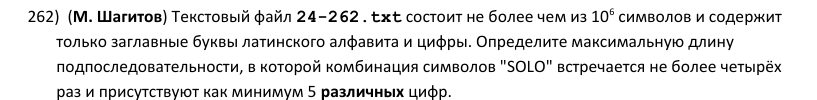

<details><summary>Текст условия</summary>(М. Шагитов) Текстовый файл 24-262.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и цифры. Определите максимальную длину подпоследовательности, в которой комбинация символов &quot;SOLO&quot; встречается не более четырёх раз и присутствуют как минимум 5 различных цифр.</details>

**Способ 1:** два указателя

In [422]:
s = open('24-262.txt').readline().strip()
L = solo = mx = 0
dig = {}                       # цифры в окне и их количество
for R in range(len(s)):
    if s[R].isdigit():
        dig[s[R]] = dig.get(s[R], 0) + 1
    if R - 3 >= L and s[R-3:R+1] == 'SOLO':
        solo += 1
    while solo > 4:
        if s[L:L+4] == 'SOLO' and L + 3 <= R:
            solo -= 1
        if s[L].isdigit():
            dig[s[L]] -= 1
            if dig[s[L]] == 0:
                del dig[s[L]]
        L += 1
    if len(dig) >= 5:
        mx = max(mx, R - L + 1)
print(mx)

431


**Способ 2 (проверка):** максимальные окна по списку позиций

In [423]:
s = open('24-262.txt').readline().strip()
n = len(s)
p = [-1] + [i for i in range(n - 3) if s[i:i+4] == 'SOLO'] + [n - 3]
mx = 0
for j in range(len(p) - 5):
    L, R = p[j] + 1, p[j+5] + 2          # максимальное окно с 4 вхождениями SOLO
    if len(set(c for c in s[L:R+1] if c.isdigit())) >= 5:
        mx = max(mx, R - L + 1)
print(mx)

431


**Ответ: `431`**

### Задача 263

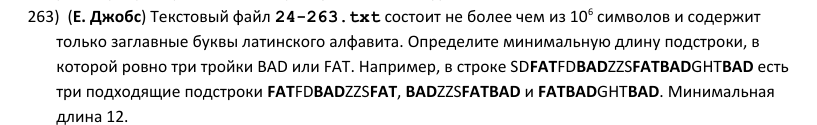

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-263.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите минимальную длину подстроки, в которой ровно три тройки BAD или FAT. Например, в строке SDFATFDBADZZSFATBADGHTBAD есть три подходящие подстроки FATFDBADZZSFAT, BADZZSFATBAD и FATBADGHTBAD. Минимальная длина 12.</details>

**Способ 1:** список позиций BAD и FAT

In [424]:
s = open('24-263.txt').readline().strip()
p = [i for i in range(len(s) - 2) if s[i:i+3] in ('BAD', 'FAT')]
print(min(p[j+2] + 3 - p[j] for j in range(len(p) - 2)))

10


**Способ 2 (проверка):** finditer

In [425]:
from re import finditer
s = open('24-263.txt').readline().strip()
p = [m.start() for m in finditer('BAD|FAT', s)]
print(min(p[j+2] - p[j] + 3 for j in range(len(p) - 2)))

10


**Ответ: `10`**

> «Ровно три тройки BAD или FAT» — всего три (в сумме), как в примере FATFDBADZZSFAT.

### Задача 264

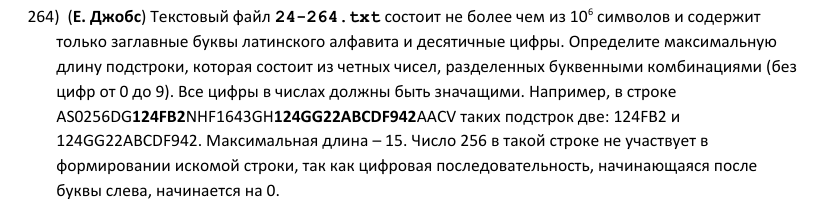

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-264.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и десятичные цифры. Определите максимальную длину подстроки, которая состоит из четных чисел, разделенных буквенными комбинациями (без цифр от 0 до 9). Все цифры в числах должны быть значащими. Например, в строке AS0256DG124FB2NHF1643GH124GG22ABCDF942AACV таких подстрок две: 124FB2 и 124GG22ABCDF942. Максимальная длина – 15. Число 256 в такой строке не участвует в формировании искомой строки, так как цифровая последовательность, начинающаяся после буквы слева, начинается на 0.</details>

**Способ 1:** разбиение на числа и буквенные группы

In [426]:
from re import findall
s = open('24-264.txt').readline().strip()
tok = findall('[0-9]+|[A-Z]+', s)          # чередуются числа и буквенные группы
def good(x):
    return x[0] != '0' and int(x[-1]) % 2 == 0
mx = cur = 0
for i, x in enumerate(tok):
    if x[0].isdigit():
        if good(x):
            # продолжаем цепочку, если перед буквами было хорошее число
            if i >= 2 and cur > 0:
                cur += len(tok[i-1]) + len(x)
            else:
                cur = len(x)
            mx = max(mx, cur)
        else:
            cur = 0
print(mx)

70


**Способ 2 (проверка):** регулярное выражение

In [427]:
from re import findall
s = open('24-264.txt').readline().strip()
num = '(?:[1-9][0-9]*[02468]|[2468])'
a = findall(f'(?<![0-9]){num}(?:[A-Z]+{num})*(?![0-9])', s)
print(max(map(len, a)))

70


**Ответ: `70`**

## Задачи ЕГЭ-2023 и похожие

«Не более k» / «не менее k» для одного символа — **список позиций** (статика) или **два указателя**.
Записи чисел в системах счисления — **регулярные выражения**: цифры системы задаём классом
(`[0-9A-F]` для 16-ричной), «без ведущих нулей» — первая цифра из `[1-9A-F]`.

### Задача 265

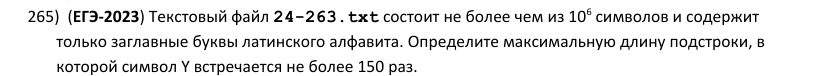

<details><summary>Текст условия</summary>(ЕГЭ-2023) Текстовый файл 24-263.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальную длину подстроки, в которой символ Y встречается не более 150 раз.</details>

**Способ 1:** список позиций

In [428]:
s = open('24-263.txt').readline().strip()
p = [-1] + [i for i in range(len(s)) if s[i] == 'Y'] + [len(s)]
print(max(p[j+151] - p[j] - 1 for j in range(len(p) - 151)))

5195


**Способ 2 (проверка):** два указателя

In [429]:
s = open('24-263.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    k += s[R] == 'Y'
    while k > 150:
        k -= s[L] == 'Y'
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

5195


**Ответ: `5195`**

### Задача 266

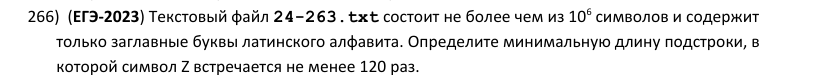

<details><summary>Текст условия</summary>(ЕГЭ-2023) Текстовый файл 24-263.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите минимальную длину подстроки, в которой символ Z встречается не менее 120 раз.</details>

**Способ 1:** список позиций

In [430]:
s = open('24-263.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] == 'Z']
print(min(p[j+119] - p[j] + 1 for j in range(len(p) - 119)))

2310


**Способ 2 (проверка):** два указателя

In [431]:
s = open('24-263.txt').readline().strip()
L = k = 0
mn = 10**9
for R in range(len(s)):
    k += s[R] == 'Z'
    while k > 120 or (k == 120 and s[L] != 'Z'):
        k -= s[L] == 'Z'
        L += 1
    if k >= 120:
        mn = min(mn, R - L + 1)
print(mn)

2310


**Ответ: `2310`**

### Задача 267

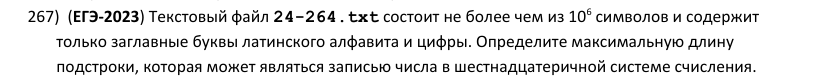

<details><summary>Текст условия</summary>(ЕГЭ-2023) Текстовый файл 24-264.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и цифры. Определите максимальную длину подстроки, которая может являться записью числа в шестнадцатеричной системе счисления.</details>

**Способ 1:** регулярное выражение

In [432]:
from re import findall
s = open('24-264.txt').readline().strip()
print(max(map(len, findall('[1-9A-F][0-9A-F]*', s))))

34


**Способ 2 (проверка):** метод замен + lstrip

In [433]:
from re import sub
s = open('24-264.txt').readline().strip()
a = sub('[G-Z]', ' ', s).split()
print(max(len(x.lstrip('0')) for x in a))

34


**Ответ: `34`**

> Запись числа не начинается с незначащего нуля, поэтому ведущие нули отбрасываем.

### Задача 268

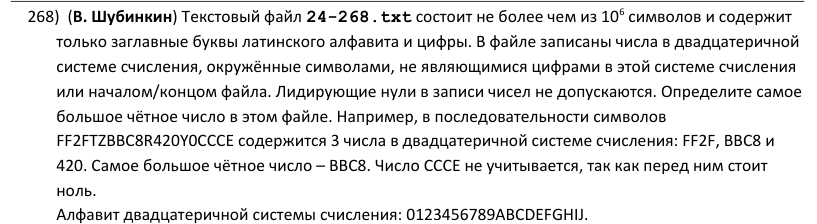

<details><summary>Текст условия</summary>(В. Шубинкин) Текстовый файл 24-268.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и цифры. В файле записаны числа в двадцатеричной системе счисления, окружённые символами, не являющимися цифрами в этой системе счисления или началом/концом файла. Лидирующие нули в записи чисел не допускаются. Определите самое большое чётное число в этом файле. Например, в последовательности символов FF2FTZBBC8R420Y0CCCE содержится 3 числа в двадцатеричной системе счисления: FF2F, BBC8 и 420. Самое большое чётное число – BBC8. Число CCCE не учитывается, так как перед ним стоит ноль.<br>Алфавит двадцатеричной системы счисления: 0123456789ABCDEFGHIJ.</details>

**Способ 1:** findall + max по значению

In [434]:
from re import findall
s = open('24-268.txt').readline().strip()
a = [x for x in findall('[0-9A-J]+', s) if x[0] != '0' or x == '0']
x = max((x for x in a if int(x, 20) % 2 == 0), key=lambda x: int(x, 20))
print(x)

85A6J7CE


**Способ 2 (проверка):** метод замен, сравнение по (длина, запись)

In [435]:
from re import sub
s = open('24-268.txt').readline().strip()
a = sub('[K-Z]', ' ', s).split()
a = [x for x in a if x[0] != '0' and int(x[-1], 20) % 2 == 0]   # основание чётное: решает последняя цифра
print(max(a, key=lambda x: (len(x), x)))

85A6J7CE


**Ответ: `85A6J7CE`**

### Задача 269

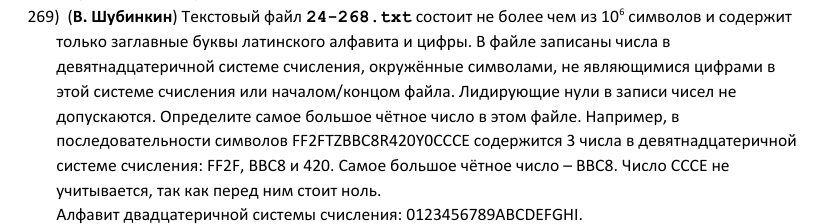

<details><summary>Текст условия</summary>(В. Шубинкин) Текстовый файл 24-268.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и цифры. В файле записаны числа в девятнадцатеричной системе счисления, окружённые символами, не являющимися цифрами в этой системе счисления или началом/концом файла. Лидирующие нули в записи чисел не допускаются. Определите самое большое чётное число в этом файле. Например, в последовательности символов FF2FTZBBC8R420Y0CCCE содержится 3 числа в девятнадцатеричной системе счисления: FF2F, BBC8 и 420. Самое большое чётное число – BBC8. Число CCCE не учитывается, так как перед ним стоит ноль.<br>Алфавит двадцатеричной системы счисления: 0123456789ABCDEFGHI.</details>

**Способ 1:** findall + max по значению

In [436]:
from re import findall
s = open('24-268.txt').readline().strip()
a = [x for x in findall('[0-9A-I]+', s) if x[0] != '0' or x == '0']
x = max((x for x in a if int(x, 19) % 2 == 0), key=lambda x: int(x, 19))
print(x)

GGA55CF9


**Способ 2 (проверка):** чётность по сумме цифр

In [437]:
from re import sub
s = open('24-268.txt').readline().strip()
a = sub('[J-Z]', ' ', s).split()
# основание нечётное: число чётно, когда чётна сумма цифр
a = [x for x in a if x[0] != '0' and sum(int(c, 19) for c in x) % 2 == 0]
print(max(a, key=lambda x: (len(x), x)))

GGA55CF9


**Ответ: `GGA55CF9`**

### Задача 270

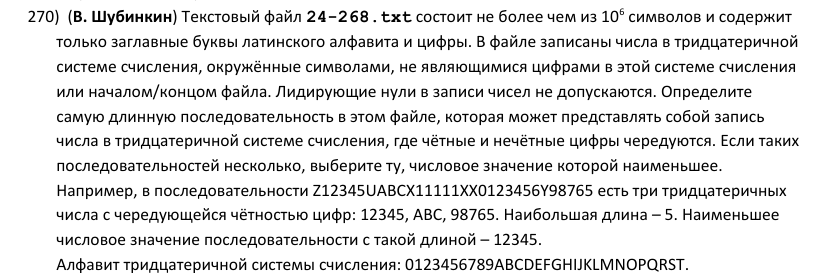

<details><summary>Текст условия</summary>(В. Шубинкин) Текстовый файл 24-268.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и цифры. В файле записаны числа в тридцатеричной системе счисления, окружённые символами, не являющимися цифрами в этой системе счисления или началом/концом файла. Лидирующие нули в записи чисел не допускаются. Определите самую длинную последовательность в этом файле, которая может представлять собой запись числа в тридцатеричной системе счисления, где чётные и нечётные цифры чередуются. Если таких последовательностей несколько, выберите ту, числовое значение которой наименьшее. Например, в последовательности Z12345UABCX11111XX0123456Y98765 есть три тридцатеричных числа с чередующейся чётностью цифр: 12345, ABC, 98765. Наибольшая длина – 5. Наименьшее числовое значение последовательности с такой длиной – 12345.<br>Алфавит тридцатеричной системы счисления: 0123456789ABCDEFGHIJKLMNOPQRST.</details>

**Способ 1:** findall + проверка чередования

In [438]:
from re import findall
s = open('24-268.txt').readline().strip()
def ok(x):
    v = [int(c, 30) for c in x]
    return x[0] != '0' and all((v[i] + v[i+1]) % 2 == 1 for i in range(len(v) - 1))
a = [x for x in findall('[0-9A-T]+', s) if ok(x)]
print(max(a, key=lambda x: (len(x), -int(x, 30))))

8NERO9KLST


**Способ 2 (проверка):** метод замен + перебор

In [439]:
from re import sub
s = open('24-268.txt').readline().strip()
dig = '0123456789ABCDEFGHIJKLMNOPQRST'
best = ''
for x in sub('[U-Z]', ' ', s).split():
    if x[0] == '0':
        continue
    if all(dig.index(x[i]) % 2 != dig.index(x[i+1]) % 2 for i in range(len(x) - 1)):
        if len(x) > len(best) or (len(x) == len(best) and x < best):
            best = x
print(best)

8NERO9KLST


**Ответ: `8NERO9KLST`**

### Задача 271

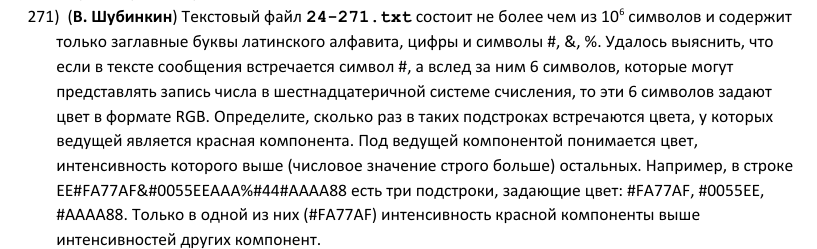

<details><summary>Текст условия</summary>(В. Шубинкин) Текстовый файл 24-271.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита, цифры и символы #, &amp;, %. Удалось выяснить, что если в тексте сообщения встречается символ #, а вслед за ним 6 символов, которые могут представлять запись числа в шестнадцатеричной системе счисления, то эти 6 символов задают цвет в формате RGB. Определите, сколько раз в таких подстроках встречаются цвета, у которых ведущей является красная компонента. Под ведущей компонентой понимается цвет, интенсивность которого выше (числовое значение строго больше) остальных. Например, в строке EE#FA77AF&amp;#0055EEAAA%#44#AAAA88 есть три подстроки, задающие цвет: #FA77AF, #0055EE, #AAAA88. Только в одной из них (#FA77AF) интенсивность красной компоненты выше интенсивностей других компонент.</details>

**Способ 1:** findall + сравнение компонент

In [440]:
from re import findall
s = open('24-271.txt').readline().strip()
k = 0
for c in findall('#([0-9A-F]{6})', s):
    r, g, b = int(c[:2], 16), int(c[2:4], 16), int(c[4:], 16)
    if r > g and r > b:
        k += 1
print(k)

3369


**Способ 2 (проверка):** поиск # через find

In [441]:
s = open('24-271.txt').readline().strip()
hexd = '0123456789ABCDEF'
k = 0
i = s.find('#')
while i != -1:
    c = s[i+1:i+7]
    if len(c) == 6 and all(ch in hexd for ch in c):
        if int(c[:2], 16) > max(int(c[2:4], 16), int(c[4:], 16)):
            k += 1
    i = s.find('#', i + 1)
print(k)

3369


**Ответ: `3369`**

### Задача 272

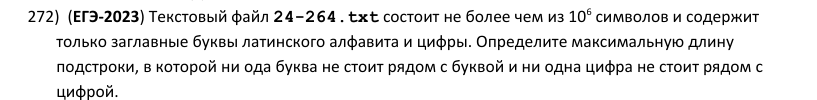

<details><summary>Текст условия</summary>(ЕГЭ-2023) Текстовый файл 24-264.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и цифры. Определите максимальную длину подстроки, в которой ни ода буква не стоит рядом с буквой и ни одна цифра не стоит рядом с цифрой.</details>

**Способ 1:** однопроходный алгоритм

In [442]:
s = open('24-264.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    if s[i].isdigit() != s[i-1].isdigit():   # буква и цифра чередуются
        k += 1
    else:
        k = 1
    mx = max(mx, k)
print(mx)

18


**Способ 2 (проверка):** метод замен + split

In [443]:
from re import sub
s = open('24-264.txt').readline().strip()
s = sub('[0-9]', 'd', s)
s = sub('[A-Z]', 'b', s)
for p in ('dd', 'bb'):
    s = s.replace(p, p[0] + ' ' + p[1]).replace(p, p[0] + ' ' + p[1])
print(max(map(len, s.split())))

18


**Ответ: `18`**

### Задача 273

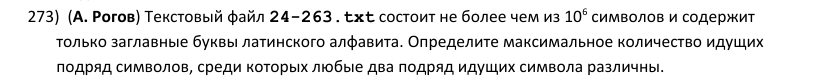

<details><summary>Текст условия</summary>(А. Рогов) Текстовый файл 24-263.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых любые два подряд идущих символа различны.</details>

**Способ 1:** однопроходный алгоритм

In [444]:
s = open('24-263.txt').readline().strip()
k = mx = 1
for i in range(1, len(s)):
    k = k + 1 if s[i] != s[i-1] else 1
    mx = max(mx, k)
print(mx)

302


**Способ 2 (проверка):** метод замен + split

In [445]:
from re import sub
s = open('24-263.txt').readline().strip()
s = sub(r'(.)(?=\1)', r'\1 ', s)
print(max(map(len, s.split())))

302


**Ответ: `302`**

### Задача 274

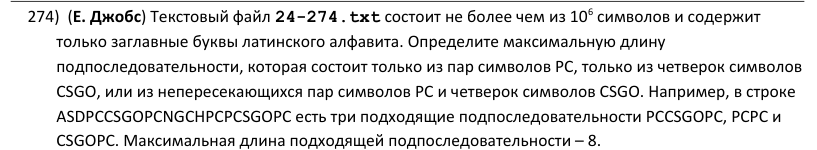

<details><summary>Текст условия</summary>(Е. Джобс) Текстовый файл 24-274.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальную длину подпоследовательности, которая состоит только из пар символов PC, только из четверок символов CSGO, или из непересекающихся пар символов PC и четверок символов CSGO. Например, в строке ASDPCCSGOPCNGCHPCPCSGOPC есть три подходящие подпоследовательности PCCSGOPC, РСРС и CSGOPC. Максимальная длина подходящей подпоследовательности – 8.</details>

**Способ 1:** динамическое программирование

In [446]:
s = open('24-274.txt').readline().strip()
n = len(s)
dp = [0] * (n + 1)     # dp[i] — длина цепочки, кончающейся на s[i-1]
for i in range(2, n + 1):
    if s[i-2:i] == 'PC':
        dp[i] = dp[i-2] + 2
    if i >= 4 and s[i-4:i] == 'CSGO':
        dp[i] = max(dp[i], dp[i-4] + 4)
print(max(dp))

90


**Способ 2 (проверка):** регулярное выражение с (?=...)

In [447]:
from re import findall
s = open('24-274.txt').readline().strip()
print(max(map(len, findall('(?=((?:PC|CSGO)+))', s))))

90


**Ответ: `90`**

### Задача 275

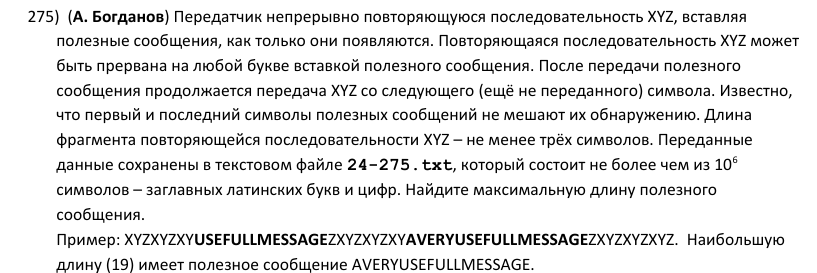

<details><summary>Текст условия</summary>(А. Богданов) Передатчик непрерывно повторяющуюся последовательность XYZ, вставляя полезные сообщения, как только они появляются. Повторяющаяся последовательность XYZ может быть прервана на любой букве вставкой полезного сообщения. После передачи полезного сообщения продолжается передача XYZ со следующего (ещё не переданного) символа. Известно, что первый и последний символы полезных сообщений не мешают их обнаружению. Длина фрагмента повторяющейся последовательности XYZ – не менее трёх символов. Переданные данные сохранены в текстовом файле 24-275.txt, который состоит не более чем из 10⁶ символов – заглавных латинских букв и цифр. Найдите максимальную длину полезного сообщения.<br>Пример: XYZXYZXYUSEFULLMESSAGEZXYZXYZXYAVERYUSEFULLMESSAGEZXYZXYZXYZ.  Наибольшую длину (19) имеет полезное сообщение AVERYUSEFULLMESSAGE.</details>

**Способ 1:** однопроходный алгоритм с «ожидаемым символом»

In [448]:
s = open('24-275.txt').readline().strip()
cyc = 'XYZ'
n = len(s)
i = 0
e = 0               # индекс в 'XYZ' символа, который передатчик должен отправить следующим
mx = 0
while i < n:
    if s[i] == cyc[e]:              # идёт повторяющаяся последовательность
        e = (e + 1) % 3
        i += 1
    else:                           # началось полезное сообщение — ищем, где XYZ продолжится
        nxt = cyc[e] + cyc[(e + 1) % 3] + cyc[(e + 2) % 3]
        j = s.find(nxt, i + 1)      # фрагмент XYZ не короче трёх символов
        if j == -1:
            j = n
        mx = max(mx, j - i)
        i = j
print(mx)

1339


**Способ 2 (проверка):** посимвольный автомат

In [449]:
from re import finditer
s = open('24-275.txt').readline().strip()
# склеим строку с номером символа в цикле: передатчик шлёт cyc[t % 3], где t — счётчик переданных символов XYZ
cyc = 'XYZ'
t = 0
i = 0
mx = 0
msg_start = None
while i < len(s):
    if s[i] == cyc[t % 3] and (msg_start is None or s[i:i+3] == cyc[t % 3] + cyc[(t+1) % 3] + cyc[(t+2) % 3]):
        if msg_start is not None:
            mx = max(mx, i - msg_start)
            msg_start = None
        t += 1
    elif msg_start is None:
        msg_start = i
    i += 1
if msg_start is not None:
    mx = max(mx, len(s) - msg_start)
print(mx)

1339


**Ответ: `1339`**

> После сообщения передача продолжается со следующего символа цикла, и фрагмент XYZ не короче трёх символов — поэтому конец сообщения ищем как первое появление трёх «ожидаемых» символов подряд.

### Задача 276

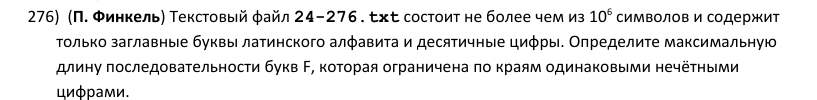

<details><summary>Текст условия</summary>(П. Финкель) Текстовый файл 24-276.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и десятичные цифры. Определите максимальную длину последовательности букв F, которая ограничена по краям одинаковыми нечётными цифрами.</details>

**Способ 1:** регулярное выражение с обратной ссылкой

In [450]:
from re import findall
s = open('24-276.txt').readline().strip()
# (?=...) — ограничивающая цифра может быть общей для двух соседних последовательностей
a = findall(r'(?=([13579])(F+)\1)', s)
print(max(len(x) for d, x in a))

468


**Способ 2 (проверка):** проход с запоминанием последней цифры

In [451]:
from re import fullmatch
s = open('24-276.txt').readline().strip()
mx = 0
last = {}                    # последняя позиция каждой цифры
for i, c in enumerate(s):
    if c.isdigit():
        if fullmatch('[13579]', c) and c in last and fullmatch('F+', s[last[c]+1:i]):
            mx = max(mx, i - last[c] - 1)
        last = {c: i}            # между цифрами-ограничителями не должно быть других цифр
print(mx)

468


**Ответ: `468`**

### Задача 277

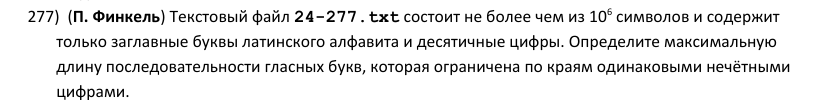

<details><summary>Текст условия</summary>(П. Финкель) Текстовый файл 24-277.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и десятичные цифры. Определите максимальную длину последовательности гласных букв, которая ограничена по краям одинаковыми нечётными цифрами.</details>

**Способ 1:** регулярное выражение с обратной ссылкой

In [452]:
from re import findall
s = open('24-277.txt').readline().strip()
# (?=...) — ограничивающая цифра может быть общей для двух соседних последовательностей
a = findall(r'(?=([13579])([AEIOUY]+)\1)', s)
print(max(len(x) for d, x in a))

456


**Способ 2 (проверка):** проход с запоминанием последней цифры

In [453]:
from re import fullmatch
s = open('24-277.txt').readline().strip()
mx = 0
last = {}                    # последняя позиция каждой цифры
for i, c in enumerate(s):
    if c.isdigit():
        if fullmatch('[13579]', c) and c in last and fullmatch('[AEIOUY]+', s[last[c]+1:i]):
            mx = max(mx, i - last[c] - 1)
        last = {c: i}            # между цифрами-ограничителями не должно быть других цифр
print(mx)

456


**Ответ: `456`**

### Задача 278

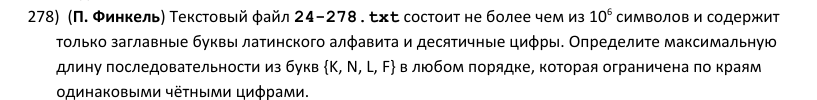

<details><summary>Текст условия</summary>(П. Финкель) Текстовый файл 24-278.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и десятичные цифры. Определите максимальную длину последовательности из букв {K, N, L, F} в любом порядке, которая ограничена по краям одинаковыми чётными цифрами.</details>

**Способ 1:** регулярное выражение с обратной ссылкой

In [454]:
from re import findall
s = open('24-278.txt').readline().strip()
# (?=...) — ограничивающая цифра может быть общей для двух соседних последовательностей
a = findall(r'(?=([02468])([KNLF]+)\1)', s)
print(max(len(x) for d, x in a))

5103


**Способ 2 (проверка):** проход с запоминанием последней цифры

In [455]:
from re import fullmatch
s = open('24-278.txt').readline().strip()
mx = 0
last = {}                    # последняя позиция каждой цифры
for i, c in enumerate(s):
    if c.isdigit():
        if fullmatch('[02468]', c) and c in last and fullmatch('[KNLF]+', s[last[c]+1:i]):
            mx = max(mx, i - last[c] - 1)
        last = {c: i}            # между цифрами-ограничителями не должно быть других цифр
print(mx)

5103


**Ответ: `5103`**

### Задача 279

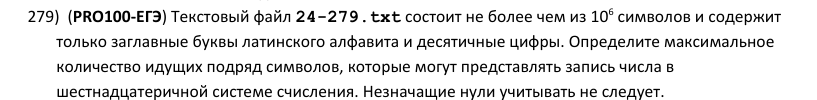

<details><summary>Текст условия</summary>(PRO100-ЕГЭ) Текстовый файл 24-279.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и десятичные цифры. Определите максимальное количество идущих подряд символов, которые могут представлять запись числа в шестнадцатеричной системе счисления. Незначащие нули учитывать не следует.</details>

**Способ 1:** регулярное выражение

In [456]:
from re import findall
s = open('24-279.txt').readline().strip()
print(max(len(x.lstrip('0')) for x in findall('[0-9A-F]+', s)))

21


**Способ 2 (проверка):** однопроходный алгоритм

In [457]:
s = open('24-279.txt').readline().strip()
k = mx = 0
for c in s:
    if c in '0123456789ABCDEF':
        if k > 0 or c != '0':     # ведущие нули не считаем
            k += 1
    else:
        k = 0
    mx = max(mx, k)
print(mx)

21


**Ответ: `21`**

## Ограничения на количество букв: два указателя

Все задачи этой серии решаются одной схемой **двух указателей**: двигаем `R`, считаем буквы в окне
в словаре `cnt`, и пока окно нарушает ограничение «не более» (букв больше нормы или есть запрещённые) —
сдвигаем `L`. После этого окно `s[L..R]` — самое длинное из допустимых, заканчивающихся в `R`.
Для условия «ровно k» проверяем, что в этом самом длинном окне буквы встречаются ровно `k` раз
(если в нём меньше, в более коротких окнах тоже меньше).

Проверка — **метод последних вхождений**: для каждой буквы храним список её позиций; самое левое допустимое
`L` определяется (k+1)-м с конца вхождением буквы, а для «ровно k» правая граница начала — k-м с конца.

### Задача 280

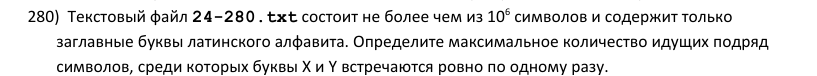

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых буквы X и Y встречаются ровно по одному разу.</details>

**Способ 1:** два указателя + словарь-счётчик

In [458]:
s = open('24-280.txt').readline().strip()
EX, k = 'XY', 1          # ровно k раз каждая
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in EX and cnt[c] > k):
        cnt[s[L]] -= 1
        L += 1
    if all(cnt.get(x, 0) == k for x in EX):
        mx = max(mx, R - L + 1)
print(mx)

193


**Способ 2 (проверка):** метод последних вхождений

In [459]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'XY' and len(p) > 1:
        lo = max(lo, p[-1-1] + 1)
    hi = R                   # начало должно быть не правее k-го с конца вхождения каждой буквы
    for x in 'XY':
        q = pos.get(x, [])
        hi = min(hi, q[-1] if len(q) >= 1 else -1)
    if lo <= hi:
        mx = max(mx, R - lo + 1)
print(mx)

193


**Ответ: `193`**

### Задача 281

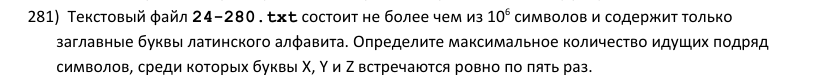

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых буквы X, Y и Z встречаются ровно по пять раз.</details>

**Способ 1:** два указателя + словарь-счётчик

In [460]:
s = open('24-280.txt').readline().strip()
EX, k = 'XYZ', 5          # ровно k раз каждая
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in EX and cnt[c] > k):
        cnt[s[L]] -= 1
        L += 1
    if all(cnt.get(x, 0) == k for x in EX):
        mx = max(mx, R - L + 1)
print(mx)

288


**Способ 2 (проверка):** метод последних вхождений

In [461]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'XYZ' and len(p) > 5:
        lo = max(lo, p[-5-1] + 1)
    hi = R                   # начало должно быть не правее k-го с конца вхождения каждой буквы
    for x in 'XYZ':
        q = pos.get(x, [])
        hi = min(hi, q[-5] if len(q) >= 5 else -1)
    if lo <= hi:
        mx = max(mx, R - lo + 1)
print(mx)

288


**Ответ: `288`**

### Задача 282

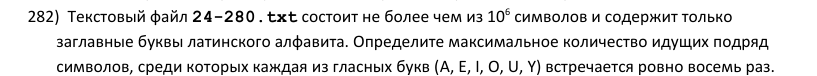

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых каждая из гласных букв (A, E, I, O, U, Y) встречается ровно восемь раз.</details>

**Способ 1:** два указателя + словарь-счётчик

In [462]:
s = open('24-280.txt').readline().strip()
EX, k = 'AEIOUY', 8          # ровно k раз каждая
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in EX and cnt[c] > k):
        cnt[s[L]] -= 1
        L += 1
    if all(cnt.get(x, 0) == k for x in EX):
        mx = max(mx, R - L + 1)
print(mx)

259


**Способ 2 (проверка):** метод последних вхождений

In [463]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'AEIOUY' and len(p) > 8:
        lo = max(lo, p[-8-1] + 1)
    hi = R                   # начало должно быть не правее k-го с конца вхождения каждой буквы
    for x in 'AEIOUY':
        q = pos.get(x, [])
        hi = min(hi, q[-8] if len(q) >= 8 else -1)
    if lo <= hi:
        mx = max(mx, R - lo + 1)
print(mx)

259


**Ответ: `259`**

### Задача 283

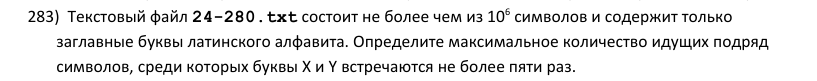

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых буквы X и Y встречаются не более пяти раз.</details>

**Способ 1:** два указателя + словарь-счётчик

In [464]:
s = open('24-280.txt').readline().strip()
AT, m = 'XY', 5          # не более m раз каждая
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in AT and cnt[c] > m):
        cnt[s[L]] -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

342


**Способ 2 (проверка):** метод последних вхождений

In [465]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'XY' and len(p) > 5:
        lo = max(lo, p[-5-1] + 1)
    mx = max(mx, R - lo + 1)
print(mx)

342


**Ответ: `342`**

> «Буквы X и Y встречаются не более пяти раз» понимаем как «каждая из них — не более пяти раз». Если понимать как «в сумме не более пяти», ответ 277.

### Задача 284

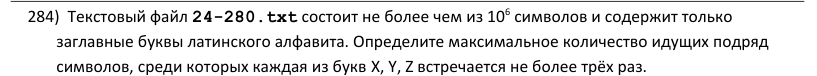

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых каждая из букв X, Y, Z встречается не более трёх раз.</details>

**Способ 1:** два указателя + словарь-счётчик

In [466]:
s = open('24-280.txt').readline().strip()
AT, m = 'XYZ', 3          # не более m раз каждая
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in AT and cnt[c] > m):
        cnt[s[L]] -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

213


**Способ 2 (проверка):** метод последних вхождений

In [467]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'XYZ' and len(p) > 3:
        lo = max(lo, p[-3-1] + 1)
    mx = max(mx, R - lo + 1)
print(mx)

213


**Ответ: `213`**

### Задача 285

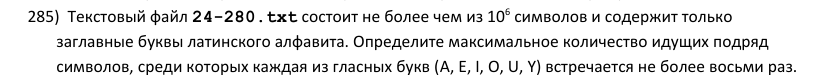

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых каждая из гласных букв (A, E, I, O, U, Y) встречается не более восьми раз.</details>

**Способ 1:** два указателя + словарь-счётчик

In [468]:
s = open('24-280.txt').readline().strip()
AT, m = 'AEIOUY', 8          # не более m раз каждая
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in AT and cnt[c] > m):
        cnt[s[L]] -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

291


**Способ 2 (проверка):** метод последних вхождений

In [469]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'AEIOUY' and len(p) > 8:
        lo = max(lo, p[-8-1] + 1)
    mx = max(mx, R - lo + 1)
print(mx)

291


**Ответ: `291`**

### Задача 286

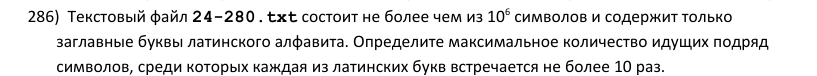

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых каждая из латинских букв встречается не более 10 раз.</details>

**Способ 1:** два указателя + словарь-счётчик

In [470]:
s = open('24-280.txt').readline().strip()
AT, m = 'ALL', 10
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while cnt[c] > m:
        cnt[s[L]] -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

226


**Способ 2 (проверка):** метод последних вхождений

In [471]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if len(p) > 10:
        lo = max(lo, p[-10-1] + 1)
    mx = max(mx, R - lo + 1)
print(mx)

226


**Ответ: `226`**

### Задача 287

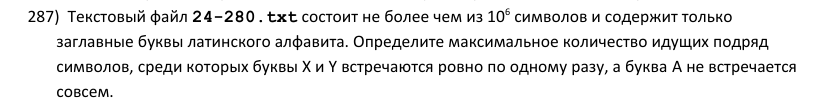

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых буквы X и Y встречаются ровно по одному разу, а буква A не встречается совсем.</details>

**Способ 1:** два указателя + словарь-счётчик

In [472]:
s = open('24-280.txt').readline().strip()
EX, k = 'XY', 1          # ровно k раз каждая
NO = 'A'                # не встречаются совсем
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in EX and cnt[c] > k) or (c in NO and cnt[c] > 0):
        cnt[s[L]] -= 1
        L += 1
    if all(cnt.get(x, 0) == k for x in EX):
        mx = max(mx, R - L + 1)
print(mx)

135


**Способ 2 (проверка):** метод последних вхождений

In [473]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'A':
        lo = R + 1
    if c in 'XY' and len(p) > 1:
        lo = max(lo, p[-1-1] + 1)
    hi = R                   # начало должно быть не правее k-го с конца вхождения каждой буквы
    for x in 'XY':
        q = pos.get(x, [])
        hi = min(hi, q[-1] if len(q) >= 1 else -1)
    if lo <= hi:
        mx = max(mx, R - lo + 1)
print(mx)

135


**Ответ: `135`**

### Задача 288

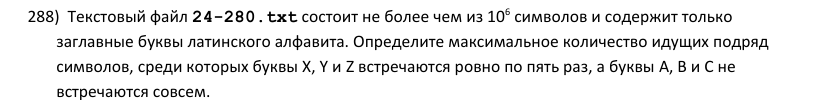

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых буквы X, Y и Z встречаются ровно по пять раз, а буквы A, B и C не встречаются совсем.</details>

**Способ 1:** два указателя + словарь-счётчик

In [474]:
s = open('24-280.txt').readline().strip()
EX, k = 'XYZ', 5          # ровно k раз каждая
NO = 'ABC'                # не встречаются совсем
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in EX and cnt[c] > k) or (c in NO and cnt[c] > 0):
        cnt[s[L]] -= 1
        L += 1
    if all(cnt.get(x, 0) == k for x in EX):
        mx = max(mx, R - L + 1)
print(mx)

77


**Способ 2 (проверка):** метод последних вхождений

In [475]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'ABC':
        lo = R + 1
    if c in 'XYZ' and len(p) > 5:
        lo = max(lo, p[-5-1] + 1)
    hi = R                   # начало должно быть не правее k-го с конца вхождения каждой буквы
    for x in 'XYZ':
        q = pos.get(x, [])
        hi = min(hi, q[-5] if len(q) >= 5 else -1)
    if lo <= hi:
        mx = max(mx, R - lo + 1)
print(mx)

77


**Ответ: `77`**

### Задача 289

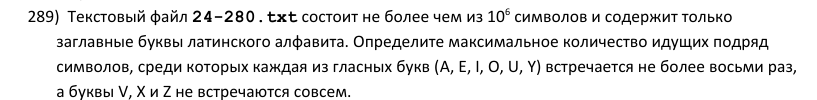

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых каждая из гласных букв (A, E, I, O, U, Y) встречается не более восьми раз, а буквы V, X и Z не встречаются совсем.</details>

**Способ 1:** два указателя + словарь-счётчик

In [476]:
s = open('24-280.txt').readline().strip()
AT, m = 'AEIOUY', 8          # не более m раз каждая
NO = 'VXZ'                # не встречаются совсем
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in AT and cnt[c] > m) or (c in NO and cnt[c] > 0):
        cnt[s[L]] -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

89


**Способ 2 (проверка):** метод последних вхождений

In [477]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'AEIOUY' and len(p) > 8:
        lo = max(lo, p[-8-1] + 1)
    if c in 'VXZ':
        lo = R + 1
    mx = max(mx, R - lo + 1)
print(mx)

89


**Ответ: `89`**

### Задача 290

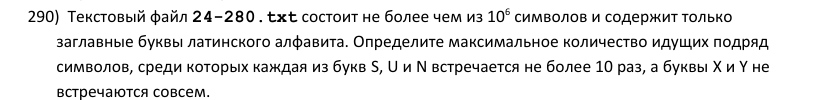

<details><summary>Текст условия</summary>Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Определите максимальное количество идущих подряд символов, среди которых каждая из букв S, U и N встречается не более 10 раз, а буквы X и Y не встречаются совсем.</details>

**Способ 1:** два указателя + словарь-счётчик

In [478]:
s = open('24-280.txt').readline().strip()
AT, m = 'SUN', 10          # не более m раз каждая
NO = 'XY'                # не встречаются совсем
cnt = {}
L = mx = 0
for R in range(len(s)):
    c = s[R]
    cnt[c] = cnt.get(c, 0) + 1
    while (c in AT and cnt[c] > m) or (c in NO and cnt[c] > 0):
        cnt[s[L]] -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

128


**Способ 2 (проверка):** метод последних вхождений

In [479]:
s = open('24-280.txt').readline().strip()
pos = {}                 # позиции каждой буквы
lo = 0                   # самое левое допустимое начало (растёт)
mx = 0
for R, c in enumerate(s):
    pos.setdefault(c, []).append(R)
    p = pos[c]
    if c in 'SUN' and len(p) > 10:
        lo = max(lo, p[-10-1] + 1)
    if c in 'XY':
        lo = R + 1
    mx = max(mx, R - lo + 1)
print(mx)

128


**Ответ: `128`**

### Задача 291

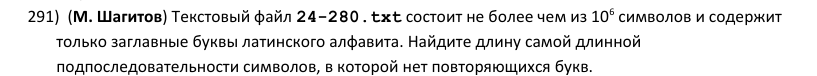

<details><summary>Текст условия</summary>(М. Шагитов) Текстовый файл 24-280.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Найдите длину самой длинной подпоследовательности символов, в которой нет повторяющихся букв.</details>

**Способ 1:** два указателя + последние вхождения

In [480]:
s = open('24-280.txt').readline().strip()
last = {}
L = mx = 0
for R, c in enumerate(s):
    if c in last and last[c] >= L:
        L = last[c] + 1          # повтор — начинаем сразу после предыдущего такого символа
    last[c] = R
    mx = max(mx, R - L + 1)
print(mx)

23


**Способ 2 (проверка):** два указателя + множество

In [481]:
s = open('24-280.txt').readline().strip()
win = set()
L = mx = 0
for R, c in enumerate(s):
    while c in win:
        win.discard(s[L])
        L += 1
    win.add(c)
    mx = max(mx, len(win))
print(mx)

23


**Ответ: `23`**

### Задача 292

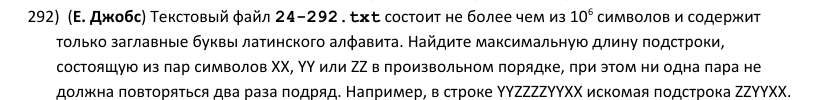

<details><summary>Текст условия</summary>(E. Джобс) Текстовый файл 24-292.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита. Найдите максимальную длину подстроки, состоящую из пар символов XX, YY или ZZ в произвольном порядке, при этом ни одна пара не должна повторяться два раза подряд. Например, в строке YYZZZZYYXX искомая подстрока ZZYYXX.</details>

**Способ 1:** динамическое программирование

In [482]:
s = open('24-292.txt').readline().strip()
dp = [0] * len(s)      # dp[i] — длина правильной цепочки, кончающейся парой s[i-1:i+1]
for i in range(1, len(s)):
    p = s[i-1:i+1]
    if p in ('XX', 'YY', 'ZZ'):
        if i >= 3 and dp[i-2] > 0 and s[i-3:i-1] != p:
            dp[i] = dp[i-2] + 2
        else:
            dp[i] = 2
print(max(dp))

52


**Способ 2 (проверка):** два сдвига + однопроходный алгоритм

In [483]:
s = open('24-292.txt').readline().strip()
mx = 0
for st in range(2):                # два варианта разбиения на пары
    k, prev = 0, ''
    for i in range(st, len(s) - 1, 2):
        p = s[i:i+2]
        if p in ('XX', 'YY', 'ZZ'):
            k = 1 if p == prev else k + 1
            prev = p
        else:
            k, prev = 0, ''
        mx = max(mx, 2 * k)
print(mx)

52


**Ответ: `52`**

### Задача 293

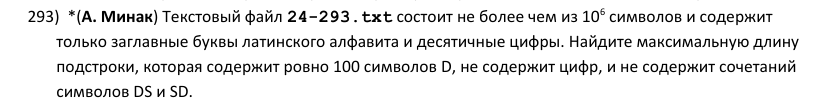

<details><summary>Текст условия</summary>*(А. Минак) Текстовый файл 24-293.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и десятичные цифры. Найдите максимальную длину подстроки, которая содержит ровно 100 символов D, не содержит цифр, и не содержит сочетаний символов DS и SD.</details>

**Способ 1:** метод замен + список позиций

In [484]:
from re import sub
s = open('24-293.txt').readline().strip()
s = sub('[0-9]', ' ', s)
s = s.replace('DS', 'D S').replace('SD', 'S D')       # DSD -> D SD -> D S D
mx = 0
for t in s.split():
    p = [-1] + [i for i in range(len(t)) if t[i] == 'D'] + [len(t)]
    for j in range(len(p) - 101):
        mx = max(mx, p[j+101] - p[j] - 1)
print(mx)

644


**Способ 2 (проверка):** два указателя со сбросом

In [485]:
s = open('24-293.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    c = s[R]
    if c.isdigit():                        # цифра — окно начинается заново после неё
        L, k = R + 1, 0
        continue
    if R > L and s[R-1:R+1] in ('DS', 'SD'):
        L, k = R, 0                        # запрещённая пара — начинаем с её второго символа
    k += c == 'D'
    while k > 100:
        k -= s[L] == 'D'
        L += 1
    if k == 100:
        mx = max(mx, R - L + 1)
print(mx)

644


**Ответ: `644`**

### Задача 294

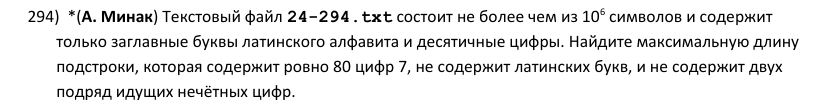

<details><summary>Текст условия</summary>*(А. Минак) Текстовый файл 24-294.txt состоит не более чем из 10⁶ символов и содержит только заглавные буквы латинского алфавита и десятичные цифры. Найдите максимальную длину подстроки, которая содержит ровно 80 цифр 7, не содержит латинских букв, и не содержит двух подряд идущих нечётных цифр.</details>

**Способ 1:** метод замен + список позиций

In [486]:
from re import sub
s = open('24-294.txt').readline().strip()
s = sub('[A-Z]', ' ', s)
s = sub('(?<=[13579])(?=[13579])', ' ', s)   # пробел между двумя нечётными цифрами
mx = 0
for t in s.split():
    p = [-1] + [i for i in range(len(t)) if t[i] == '7'] + [len(t)]
    for j in range(len(p) - 81):
        mx = max(mx, p[j+81] - p[j] - 1)
print(mx)

479


**Способ 2 (проверка):** два указателя со сбросом

In [487]:
s = open('24-294.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    c = s[R]
    if not c.isdigit():
        L, k = R + 1, 0
        continue
    if R > L and c in '13579' and s[R-1] in '13579':
        L, k = R, 0
    k += c == '7'
    while k > 80:
        k -= s[L] == '7'
        L += 1
    if k == 80:
        mx = max(mx, R - L + 1)
print(mx)

479


**Ответ: `479`**

## Задачи ЕГЭ-2024

Пары символов (`DE`, `CD`, `AF`) — **список позиций пар**. Пара «лежит» в подстроке, только если оба её символа
внутри, поэтому подстрока `s[p[j]+1 .. p[j+k+1]]` (от второго символа j-й пары до первого символа
(j+k+1)-й) содержит ровно k пар. Арифметические выражения — **регулярные выражения** (статья К.Ю. Полякова):
число без ведущих нулей `[1-9]\d*|0`, выражение `число(?:знак число)*`, произведение, равное нулю, —
`(?:число\*)*0(?:\*число)*`.

### Задача 295

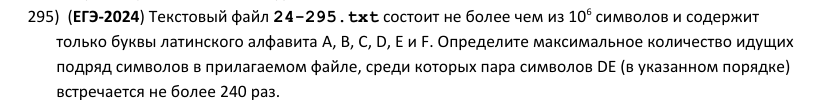

<details><summary>Текст условия</summary>(ЕГЭ-2024) Текстовый файл 24-295.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита A, B, C, D, E и F. Определите максимальное количество идущих подряд символов в прилагаемом файле, среди которых пара символов DE (в указанном порядке) встречается не более 240 раз.</details>

**Способ 1:** список позиций пар

In [488]:
s = open('24-295.txt').readline().strip()
n = len(s)
p = [-1] + [i for i in range(n - 1) if s[i:i+2] == 'DE'] + [n - 1]
k = 240
print(max(p[j+k+1] - p[j] for j in range(len(p) - k - 1)))

1792


**Способ 2 (проверка):** два указателя

In [489]:
s = open('24-295.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    if R >= 1 and s[R-1:R+1] == 'DE' and R - 1 >= L:
        k += 1
    while k > 240:
        if s[L:L+2] == 'DE':
            k -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

1792


**Ответ: `1792`**

### Задача 296

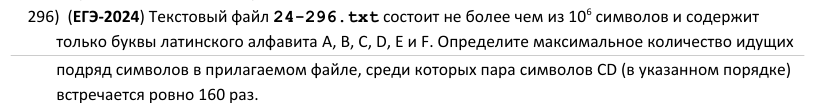

<details><summary>Текст условия</summary>(ЕГЭ-2024) Текстовый файл 24-296.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита A, B, C, D, E и F. Определите максимальное количество идущих подряд символов в прилагаемом файле, среди которых пара символов СD (в указанном порядке) встречается ровно 160 раз.</details>

**Способ 1:** список позиций пар

In [490]:
s = open('24-296.txt').readline().strip()
n = len(s)
p = [-1] + [i for i in range(n - 1) if s[i:i+2] == 'CD'] + [n - 1]
k = 160
print(max(p[j+k+1] - p[j] for j in range(len(p) - k - 1)))

1288


**Способ 2 (проверка):** два указателя

In [491]:
s = open('24-296.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    if R >= 1 and s[R-1:R+1] == 'CD' and R - 1 >= L:
        k += 1
    while k > 160:
        if s[L:L+2] == 'CD':
            k -= 1
        L += 1
    if k == 160:
        mx = max(mx, R - L + 1)
print(mx)

1288


**Ответ: `1288`**

### Задача 297

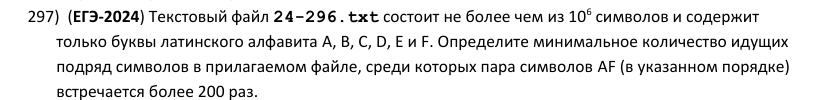

<details><summary>Текст условия</summary>(ЕГЭ-2024) Текстовый файл 24-296.txt состоит не более чем из 10⁶ символов и содержит только буквы латинского алфавита A, B, C, D, E и F. Определите минимальное количество идущих подряд символов в прилагаемом файле, среди которых пара символов AF (в указанном порядке) встречается более 200 раз.</details>

**Способ 1:** список позиций пар

In [492]:
s = open('24-296.txt').readline().strip()
p = [i for i in range(len(s) - 1) if s[i:i+2] == 'AF']
k = 201
print(min(p[j+k-1] + 2 - p[j] for j in range(len(p) - k + 1)))

9511


**Способ 2 (проверка):** два указателя

In [493]:
s = open('24-296.txt').readline().strip()
L = k = 0
mn = 10**9
for R in range(len(s)):
    if R >= 1 and s[R-1:R+1] == 'AF' and R - 1 >= L:
        k += 1
    # сдвигаем L, пока пар остаётся больше 200 и после сдвига
    while k > 201 or (k == 201 and s[L:L+2] != 'AF'):
        if s[L:L+2] == 'AF':
            k -= 1
        L += 1
    if k > 200:
        mn = min(mn, R - L + 1)
print(mn)

9511


**Ответ: `9511`**

### Задача 298

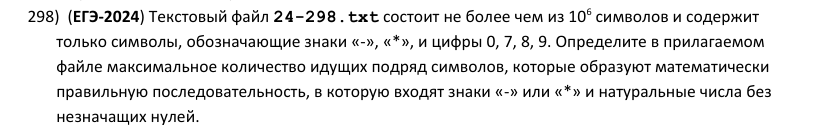

<details><summary>Текст условия</summary>(ЕГЭ-2024) Текстовый файл 24-298.txt состоит не более чем из 10⁶ символов и содержит только символы, обозначающие знаки «-», «*», и цифры 0, 7, 8, 9. Определите в прилагаемом файле максимальное количество идущих подряд символов, которые образуют математически правильную последовательность, в которую входят знаки «-» или «*» и натуральные числа без незначащих нулей.</details>

**Способ 1:** регулярное выражение

In [494]:
from re import findall
s = open('24-298.txt').readline().strip()
num = '[789][0789]*'                     # натуральное число без ведущих нулей
print(max(map(len, findall(f'{num}(?:[-*]{num})*', s))))

177


**Способ 2 (проверка):** разбиение по знакам + однопроходный алгоритм

In [495]:
from re import split
s = open('24-298.txt').readline().strip()
tok = split('[-*]', s)                   # числа между знаками ('' — если знаки стоят рядом)
mx = cur = 0
for t in tok:
    if t and t[0] != '0':                # правильное число — продолжаем выражение
        cur = cur + 1 + len(t) if cur else len(t)
    else:
        # неправильное число: выражение может начаться с его «хвоста» без ведущих нулей
        tail = t.lstrip('0')
        cur = len(tail)
    mx = max(mx, cur)
print(mx)

177


**Ответ: `177`**

> В выражении — натуральные числа, поэтому число 0 (и числа с ведущим нулём) не допускаются.

### Задача 299

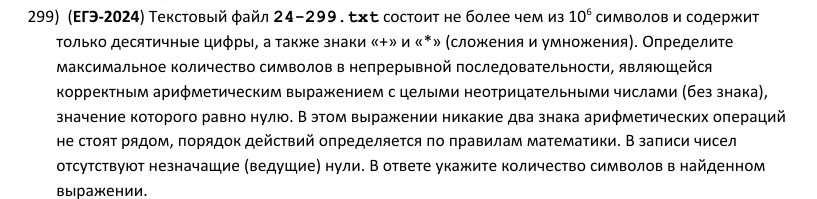

<details><summary>Текст условия</summary>(ЕГЭ-2024) Текстовый файл 24-299.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры, а также знаки «+» и «*» (сложения и умножения). Определите максимальное количество символов в непрерывной последовательности, являющейся корректным арифметическим выражением с целыми неотрицательными числами (без знака), значение которого равно нулю. В этом выражении никакие два знака арифметических операций не стоят рядом, порядок действий определяется по правилам математики. В записи чисел отсутствуют незначащие (ведущие) нули. В ответе укажите количество символов в найденном выражении.</details>

**Способ 1:** регулярное выражение с (?=...)

In [496]:
from re import findall
s = open('24-299.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
prod = fr'(?:{num}\*)*0(?:\*{num})*'      # произведение, в котором есть множитель 0
expr = fr'{prod}(?:\+{prod})*'
print(max(map(len, findall(f'(?=({expr}))', s))))

104


**Способ 2 (проверка):** то же выражение без (?=...) (быстрее)

In [497]:
from re import findall
s = open('24-299.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
prod = fr'(?:{num}\*)*0(?:\*{num})*'
print(max(map(len, findall(fr'{prod}(?:\+{prod})*', s))))

104


**Ответ: `104`**

> Метод дополнительно проверен полным перебором на тысячах случайных строк.

### Задача 300

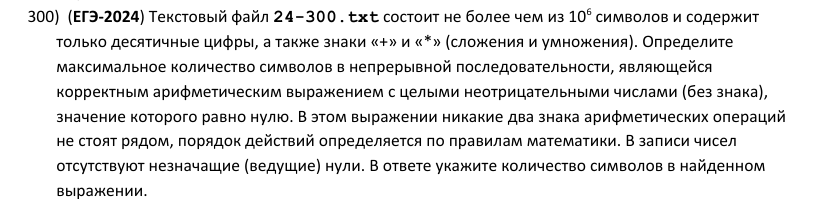

<details><summary>Текст условия</summary>(ЕГЭ-2024) Текстовый файл 24-300.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры, а также знаки «+» и «*» (сложения и умножения). Определите максимальное количество символов в непрерывной последовательности, являющейся корректным арифметическим выражением с целыми неотрицательными числами (без знака), значение которого равно нулю. В этом выражении никакие два знака арифметических операций не стоят рядом, порядок действий определяется по правилам математики. В записи чисел отсутствуют незначащие (ведущие) нули. В ответе укажите количество символов в найденном выражении.</details>

**Способ 1:** регулярное выражение с (?=...)

In [498]:
from re import findall
s = open('24-300.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
prod = fr'(?:{num}\*)*0(?:\*{num})*'      # произведение, в котором есть множитель 0
expr = fr'{prod}(?:\+{prod})*'
print(max(map(len, findall(f'(?=({expr}))', s))))

126


**Способ 2 (проверка):** то же выражение без (?=...) (быстрее)

In [499]:
from re import findall
s = open('24-300.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
prod = fr'(?:{num}\*)*0(?:\*{num})*'
print(max(map(len, findall(fr'{prod}(?:\+{prod})*', s))))

126


**Ответ: `126`**

> Метод дополнительно проверен полным перебором на тысячах случайных строк.

## Скобочные выражения (К. Багдасарян)

**Стек.** Идём по строке и кладём в стек индексы открывающих скобок. Закрывающая скобка:
* если на вершине стека парная открывающая — снимаем её; подстрока от неё до текущей скобки сбалансирована,
  её длина `i - j + 1` — кандидат в ответ;
* иначе (стек пуст или скобка другого типа) эта скобка не может входить ни в одно правильное выражение —
  очищаем стек и начинаем заново.

### Задача 301

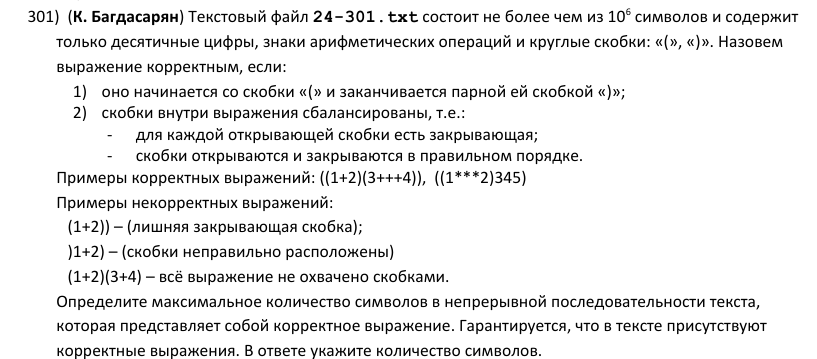

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-301.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры, знаки арифметических операций и круглые скобки: «(», «)». Назовем выражение корректным, если:<br>1) оно начинается со скобки «(» и заканчивается парной ей скобкой «)»;<br>2) скобки внутри выражения сбалансированы, т.е.:<br>• для каждой открывающей скобки есть закрывающая;<br>• скобки открываются и закрываются в правильном порядке.<br>Примеры корректных выражений: ((1+2)(3+++4)),  ((1***2)345)<br>Примеры некорректных выражений:<br>(1+2)) – (лишняя закрывающая скобка);<br>)1+2) – (скобки неправильно расположены)<br>(1+2)(3+4) – всё выражение не охвачено скобками.<br>Определите максимальное количество символов в непрерывной последовательности текста, которая представляет собой корректное выражение. Гарантируется, что в тексте присутствуют корректные выражения. В ответе укажите количество символов.</details>

**Способ 1:** стек

In [500]:
s = open('24-301.txt').readline().strip()
pair = {')': '('}
st = []                     # индексы ещё не закрытых открывающих скобок
mx = 0
for i, c in enumerate(s):
    if c in '(':
        st.append(i)
    elif c in pair:
        if st and s[st[-1]] == pair[c]:
            j = st.pop()
            mx = max(mx, i - j + 1)
        else:
            st = []         # лишняя или непарная скобка — всё сначала
print(mx)

65


**Способ 2 (проверка):** перебор начала (квадратичный, файл короткий)

In [501]:
s = open('24-301.txt').readline().strip()
pair = {'(': ')'}
mx = 0
for L in range(len(s)):            # пробуем начать выражение с каждой открывающей скобки
    if s[L] not in pair:
        continue
    st = []
    for R in range(L, len(s)):
        c = s[R]
        if c in pair:
            st.append(pair[c])     # ждём такую закрывающую
        elif c in ')':
            if not st or st.pop() != c:
                break
            if not st:             # закрылась первая скобка — выражение готово
                mx = max(mx, R - L + 1)
                break
print(mx)

65


**Ответ: `65`**

### Задача 302

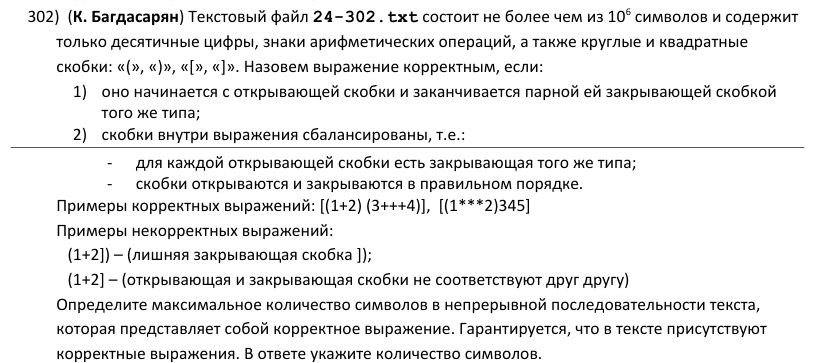

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-302.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры, знаки арифметических операций, а также круглые и квадратные скобки: «(», «)», «[», «]». Назовем выражение корректным, если:<br>1) оно начинается с открывающей скобки и заканчивается парной ей закрывающей скобкой того же типа;<br>2) скобки внутри выражения сбалансированы, т.е.:<br>• для каждой открывающей скобки есть закрывающая того же типа;<br>• скобки открываются и закрываются в правильном порядке.<br>Примеры корректных выражений: [(1+2) (3+++4)],  [(1***2)345]<br>Примеры некорректных выражений:<br>(1+2]) – (лишняя закрывающая скобка ]);<br>(1+2] – (открывающая и закрывающая скобки не соответствуют друг другу)<br>Определите максимальное количество символов в непрерывной последовательности текста, которая представляет собой корректное выражение. Гарантируется, что в тексте присутствуют корректные выражения. В ответе укажите количество символов.</details>

**Способ 1:** стек

In [502]:
s = open('24-302.txt').readline().strip()
pair = {')': '(', ']': '['}
st = []                     # индексы ещё не закрытых открывающих скобок
mx = 0
for i, c in enumerate(s):
    if c in '([':
        st.append(i)
    elif c in pair:
        if st and s[st[-1]] == pair[c]:
            j = st.pop()
            mx = max(mx, i - j + 1)
        else:
            st = []         # лишняя или непарная скобка — всё сначала
print(mx)

68


**Способ 2 (проверка):** перебор начала (квадратичный, файл короткий)

In [503]:
s = open('24-302.txt').readline().strip()
pair = {'(': ')', '[': ']'}
mx = 0
for L in range(len(s)):            # пробуем начать выражение с каждой открывающей скобки
    if s[L] not in pair:
        continue
    st = []
    for R in range(L, len(s)):
        c = s[R]
        if c in pair:
            st.append(pair[c])     # ждём такую закрывающую
        elif c in ')]':
            if not st or st.pop() != c:
                break
            if not st:             # закрылась первая скобка — выражение готово
                mx = max(mx, R - L + 1)
                break
print(mx)

68


**Ответ: `68`**

### Задача 303

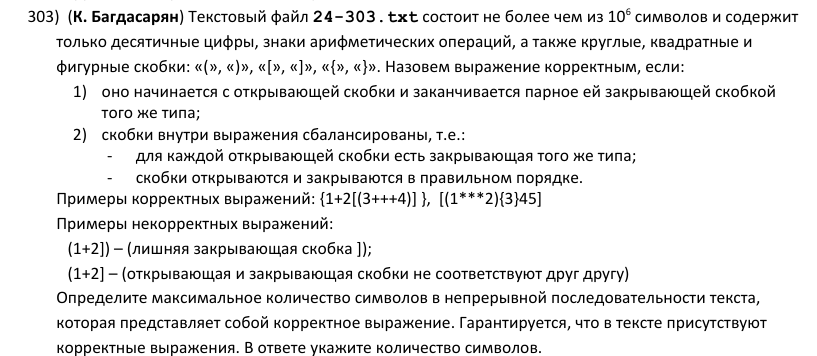

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-303.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры, знаки арифметических операций, а также круглые, квадратные и фигурные скобки: «(», «)», «[», «]», «{», «}». Назовем выражение корректным, если:<br>1) оно начинается с открывающей скобки и заканчивается парное ей закрывающей скобкой того же типа;<br>2) скобки внутри выражения сбалансированы, т.е.:<br>• для каждой открывающей скобки есть закрывающая того же типа;<br>• скобки открываются и закрываются в правильном порядке.<br>Примеры корректных выражений: {1+2[(3+++4)] },  [(1***2){3}45]<br>Примеры некорректных выражений:<br>(1+2]) – (лишняя закрывающая скобка ]);<br>(1+2] – (открывающая и закрывающая скобки не соответствуют друг другу)<br>Определите максимальное количество символов в непрерывной последовательности текста, которая представляет собой корректное выражение. Гарантируется, что в тексте присутствуют корректные выражения. В ответе укажите количество символов.</details>

**Способ 1:** стек

In [504]:
s = open('24-303.txt').readline().strip()
pair = {')': '(', ']': '[', '}': '{'}
st = []                     # индексы ещё не закрытых открывающих скобок
mx = 0
for i, c in enumerate(s):
    if c in '([{':
        st.append(i)
    elif c in pair:
        if st and s[st[-1]] == pair[c]:
            j = st.pop()
            mx = max(mx, i - j + 1)
        else:
            st = []         # лишняя или непарная скобка — всё сначала
print(mx)

59


**Способ 2 (проверка):** перебор начала (квадратичный, файл короткий)

In [505]:
s = open('24-303.txt').readline().strip()
pair = {'(': ')', '[': ']', '{': '}'}
mx = 0
for L in range(len(s)):            # пробуем начать выражение с каждой открывающей скобки
    if s[L] not in pair:
        continue
    st = []
    for R in range(L, len(s)):
        c = s[R]
        if c in pair:
            st.append(pair[c])     # ждём такую закрывающую
        elif c in ')]}':
            if not st or st.pop() != c:
                break
            if not st:             # закрылась первая скобка — выражение готово
                mx = max(mx, R - L + 1)
                break
print(mx)

59


**Ответ: `59`**

## Арифметическое выражение после/перед заданными символами

**Регулярное выражение** для правильного выражения: `num = (?:[1-9]\d*|0)`, `expr = num(?:[+*]num)*`.
Префикс `A` просто дописываем в начало шаблона, суффикс `B` — в конец.
Проверка — **ручной разбор (парсер)**: функция `parse(i)` читает от позиции `i` число, потом пары «знак + число»,
пока это возможно, и возвращает конец самого длинного правильного выражения.

### Задача 304

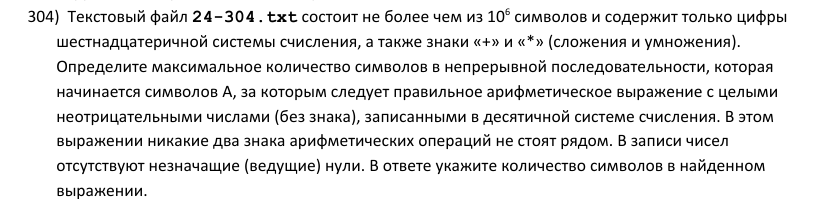

<details><summary>Текст условия</summary>Текстовый файл 24-304.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления, а также знаки «+» и «*» (сложения и умножения). Определите максимальное количество символов в непрерывной последовательности, которая начинается символов A, за которым следует правильное арифметическое выражение с целыми неотрицательными числами (без знака), записанными в десятичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом. В записи чисел отсутствуют незначащие (ведущие) нули. В ответе укажите количество символов в найденном выражении.</details>

**Способ 1:** регулярное выражение

In [506]:
from re import findall
s = open('24-304.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
print(max(map(len, findall(fr'A{num}(?:[+*]{num})*', s))))

147


**Способ 2 (проверка):** ручной разбор (парсер)

In [507]:
s = open('24-304.txt').readline().strip()
n = len(s)
def number(j):              # конец числа, начинающегося в j (или -1)
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in '123456789':
        j += 1
        while j < n and s[j].isdigit():
            j += 1
        return j
    return -1
def parse(i):               # конец самого длинного выражения от позиции i (или -1)
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
mx = 0
i = s.find('A')
while i != -1:
    e = parse(i + 1)
    if e != -1:
        mx = max(mx, e - i)
    i = s.find('A', i + 1)
print(mx)

147


**Ответ: `147`**

### Задача 305

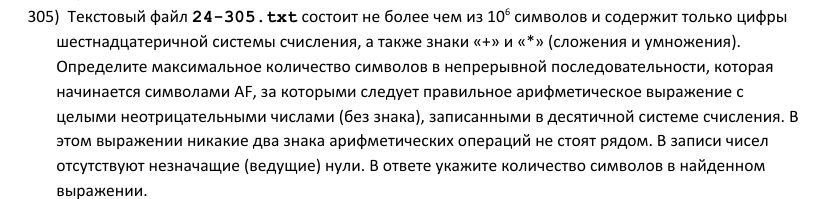

<details><summary>Текст условия</summary>Текстовый файл 24-305.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления, а также знаки «+» и «*» (сложения и умножения). Определите максимальное количество символов в непрерывной последовательности, которая начинается символами AF, за которыми следует правильное арифметическое выражение с целыми неотрицательными числами (без знака), записанными в десятичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом. В записи чисел отсутствуют незначащие (ведущие) нули. В ответе укажите количество символов в найденном выражении.</details>

**Способ 1:** регулярное выражение

In [508]:
from re import findall
s = open('24-305.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
print(max(map(len, findall(fr'AF{num}(?:[+*]{num})*', s))))

77


**Способ 2 (проверка):** ручной разбор (парсер)

In [509]:
s = open('24-305.txt').readline().strip()
n = len(s)
def number(j):              # конец числа, начинающегося в j (или -1)
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in '123456789':
        j += 1
        while j < n and s[j].isdigit():
            j += 1
        return j
    return -1
def parse(i):               # конец самого длинного выражения от позиции i (или -1)
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
mx = 0
i = s.find('AF')
while i != -1:
    e = parse(i + 2)
    if e != -1:
        mx = max(mx, e - i)
    i = s.find('AF', i + 1)
print(mx)

77


**Ответ: `77`**

### Задача 306

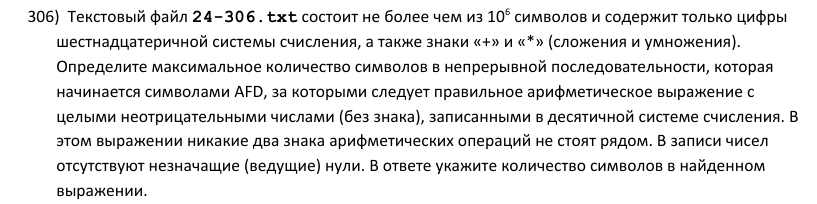

<details><summary>Текст условия</summary>Текстовый файл 24-306.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления, а также знаки «+» и «*» (сложения и умножения). Определите максимальное количество символов в непрерывной последовательности, которая начинается символами AFD, за которыми следует правильное арифметическое выражение с целыми неотрицательными числами (без знака), записанными в десятичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом. В записи чисел отсутствуют незначащие (ведущие) нули. В ответе укажите количество символов в найденном выражении.</details>

**Способ 1:** регулярное выражение

In [510]:
from re import findall
s = open('24-306.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
print(max(map(len, findall(fr'AFD{num}(?:[+*]{num})*', s))))

72


**Способ 2 (проверка):** ручной разбор (парсер)

In [511]:
s = open('24-306.txt').readline().strip()
n = len(s)
def number(j):              # конец числа, начинающегося в j (или -1)
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in '123456789':
        j += 1
        while j < n and s[j].isdigit():
            j += 1
        return j
    return -1
def parse(i):               # конец самого длинного выражения от позиции i (или -1)
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
mx = 0
i = s.find('AFD')
while i != -1:
    e = parse(i + 3)
    if e != -1:
        mx = max(mx, e - i)
    i = s.find('AFD', i + 1)
print(mx)

72


**Ответ: `72`**

### Задача 307

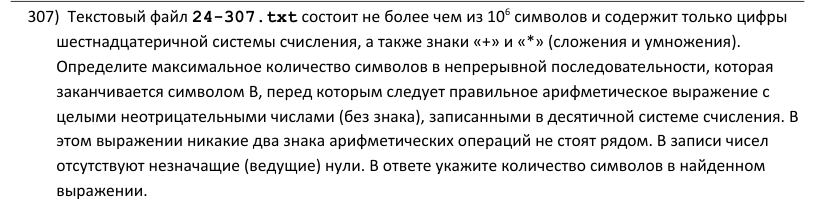

<details><summary>Текст условия</summary>Текстовый файл 24-307.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления, а также знаки «+» и «*» (сложения и умножения). Определите максимальное количество символов в непрерывной последовательности, которая заканчивается символом B, перед которым следует правильное арифметическое выражение с целыми неотрицательными числами (без знака), записанными в десятичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом. В записи чисел отсутствуют незначащие (ведущие) нули. В ответе укажите количество символов в найденном выражении.</details>

**Способ 1:** регулярное выражение

In [512]:
from re import findall
s = open('24-307.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
print(max(map(len, findall(fr'{num}(?:[+*]{num})*B', s))))

199


**Способ 2 (проверка):** ручной разбор (парсер)

In [513]:
s = open('24-307.txt').readline().strip()
n = len(s)
def number(j):              # конец числа, начинающегося в j (или -1)
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in '123456789':
        j += 1
        while j < n and s[j].isdigit():
            j += 1
        return j
    return -1
def parse(i):               # конец самого длинного выражения от позиции i (или -1)
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
mx = 0
for i in range(n):
    # начинать с цифры, перед которой стоит ненулевая цифра, невыгодно: можно начать на символ раньше
    if i > 0 and s[i-1] in '123456789':
        continue
    e = parse(i)
    if e != -1 and s[e:e + 1] == 'B':
        mx = max(mx, e + 1 - i)
print(mx)

199


**Ответ: `199`**

### Задача 308

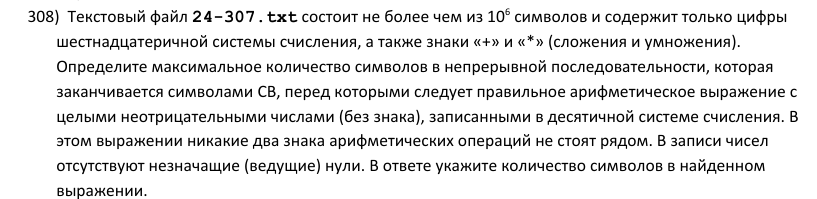

<details><summary>Текст условия</summary>Текстовый файл 24-307.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления, а также знаки «+» и «*» (сложения и умножения). Определите максимальное количество символов в непрерывной последовательности, которая заканчивается символами CB, перед которыми следует правильное арифметическое выражение с целыми неотрицательными числами (без знака), записанными в десятичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом. В записи чисел отсутствуют незначащие (ведущие) нули. В ответе укажите количество символов в найденном выражении.</details>

**Способ 1:** регулярное выражение

In [514]:
from re import findall
s = open('24-307.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
print(max(map(len, findall(fr'{num}(?:[+*]{num})*CB', s))))

83


**Способ 2 (проверка):** ручной разбор (парсер)

In [515]:
s = open('24-307.txt').readline().strip()
n = len(s)
def number(j):              # конец числа, начинающегося в j (или -1)
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in '123456789':
        j += 1
        while j < n and s[j].isdigit():
            j += 1
        return j
    return -1
def parse(i):               # конец самого длинного выражения от позиции i (или -1)
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
mx = 0
for i in range(n):
    # начинать с цифры, перед которой стоит ненулевая цифра, невыгодно: можно начать на символ раньше
    if i > 0 and s[i-1] in '123456789':
        continue
    e = parse(i)
    if e != -1 and s[e:e + 2] == 'CB':
        mx = max(mx, e + 2 - i)
print(mx)

83


**Ответ: `83`**

### Задача 309

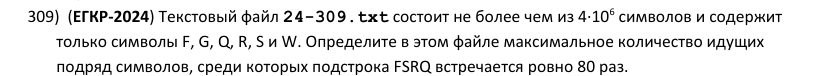

<details><summary>Текст условия</summary>(ЕГКР-2024) Текстовый файл 24-309.txt состоит не более чем из 4·10⁶ символов и содержит только символы F, G, Q, R, S и W. Определите в этом файле максимальное количество идущих подряд символов, среди которых подстрока FSRQ встречается ровно 80 раз.</details>

**Способ 1:** список позиций подстроки

In [516]:
s = open('24-309.txt').readline().strip()
n = len(s)
p = [-1] + [i for i in range(n - 3) if s[i:i+4] == 'FSRQ'] + [n - 3]
k = 80
print(max(p[j+k+1] - p[j] + 2 for j in range(len(p) - k - 1)))

2379


**Способ 2 (проверка):** finditer + список позиций

In [517]:
from re import finditer
s = open('24-309.txt').readline().strip()
p = [m.start() for m in finditer('FSRQ', s)]
p = [-1] + p + [len(s) - 3]
print(max(p[j+81] - p[j] + 2 for j in range(len(p) - 81)))

2379


**Ответ: `2379`**

## Выражения с числами в разных системах счисления

Меняется только шаблон числа: в системе с цифрами `D` и ненулевыми цифрами `NZ` число без ведущих нулей —
`(?:[NZ][D]*|0)`. Например, шестнадцатеричное `(?:[1-9A-F][0-9A-F]*|0)`, троичное `(?:[12][012]*|0)`.
Проверка — **метод замен** из статьи К.Ю. Полякова: все «чужие» символы → пробел, знаки → `*`, затем
разрезаем пробелами запрещённые места (`**`, знак у края, ведущие нули) и берём самый длинный кусок.

Если нужно **значение** выражения, считаем его как сумму произведений: `x.split('+')`, затем `split('*')`
и `int(число, основание)`.

### Задача 310

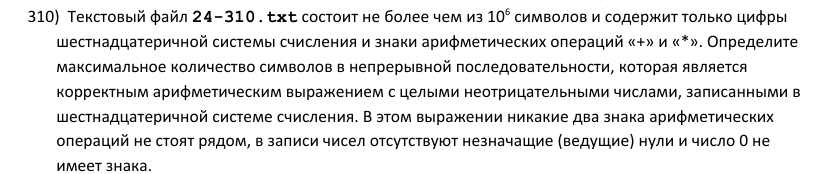

<details><summary>Текст условия</summary>Текстовый файл 24-310.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Определите максимальное количество символов в непрерывной последовательности, которая является корректным арифметическим выражением с целыми неотрицательными числами, записанными в шестнадцатеричной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака.</details>

**Способ 1:** регулярное выражение

In [518]:
from re import findall
s = open('24-310.txt').readline().strip()
num = '(?:[1-9A-F][0-9A-F]*|0)'          # шестнадцатеричные числа без ведущих нулей
print(max(map(len, findall(f'{num}(?:[+*]{num})*', s))))

502


**Способ 2 (проверка):** метод замен (статья К.Ю. Полякова)

In [519]:
from re import sub
s = open('24-310.txt').readline().strip()
D = '0123456789ABCDEF'
s = ' ' + sub('[^' + D + '+*]', ' ', s) + ' '      # «чужие» символы -> пробел
s = s.replace('+', '*')
s = s.replace('**', ' ')
s = s.replace(' *', ' ').replace('* ', ' ')
for d in D:
    s = s.replace('*0' + d, '*0 ' + d)             # после знака 0 — отдельное число
while ' 00' in s:
    s = s.replace(' 00', ' 0')                     # убираем ведущие нули в начале
for d in D:
    s = s.replace(' 0' + d, ' ' + d)
print(max(map(len, s.split())))

502


**Ответ: `502`**

### Задача 311

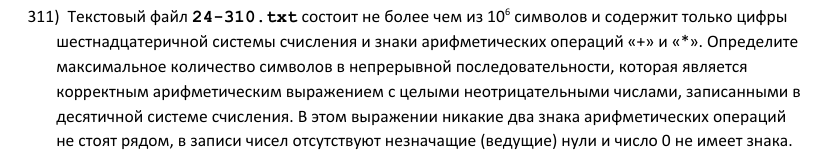

<details><summary>Текст условия</summary>Текстовый файл 24-310.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Определите максимальное количество символов в непрерывной последовательности, которая является корректным арифметическим выражением с целыми неотрицательными числами, записанными в десятичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака.</details>

**Способ 1:** регулярное выражение

In [520]:
from re import findall
s = open('24-310.txt').readline().strip()
num = '(?:[1-9][0-9]*|0)'          # десятичные числа без ведущих нулей
print(max(map(len, findall(f'{num}(?:[+*]{num})*', s))))

200


**Способ 2 (проверка):** метод замен (статья К.Ю. Полякова)

In [521]:
from re import sub
s = open('24-310.txt').readline().strip()
D = '0123456789'
s = ' ' + sub('[^' + D + '+*]', ' ', s) + ' '      # «чужие» символы -> пробел
s = s.replace('+', '*')
s = s.replace('**', ' ')
s = s.replace(' *', ' ').replace('* ', ' ')
for d in D:
    s = s.replace('*0' + d, '*0 ' + d)             # после знака 0 — отдельное число
while ' 00' in s:
    s = s.replace(' 00', ' 0')                     # убираем ведущие нули в начале
for d in D:
    s = s.replace(' 0' + d, ' ' + d)
print(max(map(len, s.split())))

200


**Ответ: `200`**

### Задача 312

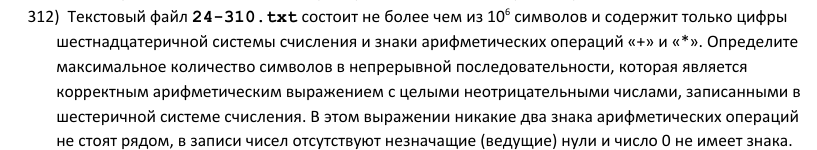

<details><summary>Текст условия</summary>Текстовый файл 24-310.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Определите максимальное количество символов в непрерывной последовательности, которая является корректным арифметическим выражением с целыми неотрицательными числами, записанными в шестеричной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака.</details>

**Способ 1:** регулярное выражение

In [522]:
from re import findall
s = open('24-310.txt').readline().strip()
num = '(?:[1-5][012345]*|0)'          # шестеричные числа без ведущих нулей
print(max(map(len, findall(f'{num}(?:[+*]{num})*', s))))

26


**Способ 2 (проверка):** метод замен (статья К.Ю. Полякова)

In [523]:
from re import sub
s = open('24-310.txt').readline().strip()
D = '012345'
s = ' ' + sub('[^' + D + '+*]', ' ', s) + ' '      # «чужие» символы -> пробел
s = s.replace('+', '*')
s = s.replace('**', ' ')
s = s.replace(' *', ' ').replace('* ', ' ')
for d in D:
    s = s.replace('*0' + d, '*0 ' + d)             # после знака 0 — отдельное число
while ' 00' in s:
    s = s.replace(' 00', ' 0')                     # убираем ведущие нули в начале
for d in D:
    s = s.replace(' 0' + d, ' ' + d)
print(max(map(len, s.split())))

26


**Ответ: `26`**

### Задача 313

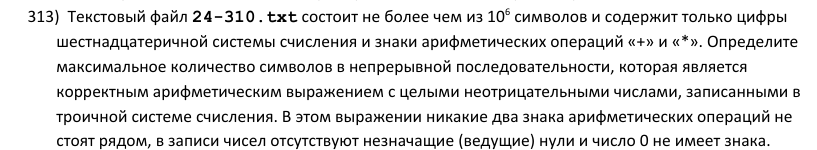

<details><summary>Текст условия</summary>Текстовый файл 24-310.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Определите максимальное количество символов в непрерывной последовательности, которая является корректным арифметическим выражением с целыми неотрицательными числами, записанными в троичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака.</details>

**Способ 1:** регулярное выражение

In [524]:
from re import findall
s = open('24-310.txt').readline().strip()
num = '(?:[12][012]*|0)'          # троичные числа без ведущих нулей
print(max(map(len, findall(f'{num}(?:[+*]{num})*', s))))

11


**Способ 2 (проверка):** метод замен (статья К.Ю. Полякова)

In [525]:
from re import sub
s = open('24-310.txt').readline().strip()
D = '012'
s = ' ' + sub('[^' + D + '+*]', ' ', s) + ' '      # «чужие» символы -> пробел
s = s.replace('+', '*')
s = s.replace('**', ' ')
s = s.replace(' *', ' ').replace('* ', ' ')
for d in D:
    s = s.replace('*0' + d, '*0 ' + d)             # после знака 0 — отдельное число
while ' 00' in s:
    s = s.replace(' 00', ' 0')                     # убираем ведущие нули в начале
for d in D:
    s = s.replace(' 0' + d, ' ' + d)
print(max(map(len, s.split())))

11


**Ответ: `11`**

### Задача 314

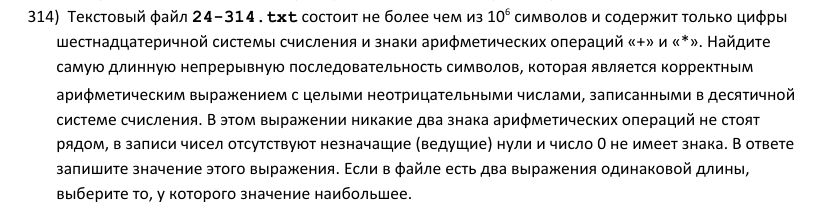

<details><summary>Текст условия</summary>Текстовый файл 24-314.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Найдите самую длинную непрерывную последовательность символов, которая является корректным арифметическим выражением с целыми неотрицательными числами, записанными в десятичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака. В ответе запишите значение этого выражения. Если в файле есть два выражения одинаковой длины, выберите то, у которого значение наибольшее.</details>

**Способ 1:** регулярное выражение + вычисление значения

In [526]:
from re import findall
s = open('24-314.txt').readline().strip()
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
num = '(?:[1-9][0-9]*|0)'
a = findall(f'{num}(?:[+*]{num})*', s)
best = max(a, key=lambda x: (len(x), value(x, 10)))   # длиннее, при равенстве — значение больше
v = value(best, 10)
print(len(best), v)

55 404903289


**Способ 2 (проверка):** ручной разбор (парсер)

In [527]:
s = open('24-314.txt').readline().strip()
D = '0123456789'
n = len(s)
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
def number(j):
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in D[1:]:
        j += 1
        while j < n and s[j] in D:
            j += 1
        return j
    return -1
def parse(i):
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
best = (0, 0)
for i in range(n):
    if i > 0 and s[i-1] in D[1:]:    # можно начать на символ раньше — будет длиннее
        continue
    e = parse(i)
    if e != -1:
        x = s[i:e]
        best = max(best, (len(x), value(x, 10)))
v = best[1]
print(best[0], v)

55 404903289


**Ответ: `404903289`**

> Программа печатает длину найденного выражения и его значение (ответ).

### Задача 315

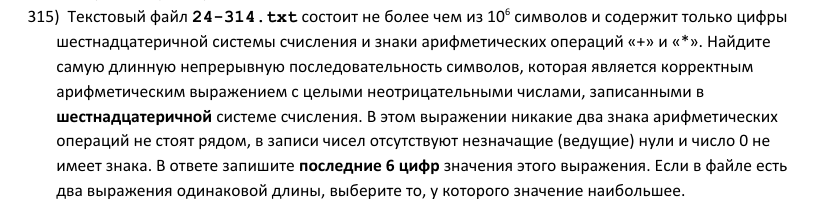

<details><summary>Текст условия</summary>Текстовый файл 24-314.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Найдите самую длинную непрерывную последовательность символов, которая является корректным арифметическим выражением с целыми неотрицательными числами, записанными в шестнадцатеричной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака. В ответе запишите последние 6 цифр значения этого выражения. Если в файле есть два выражения одинаковой длины, выберите то, у которого значение наибольшее.</details>

**Способ 1:** регулярное выражение + вычисление значения

In [528]:
from re import findall
s = open('24-314.txt').readline().strip()
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
num = '(?:[1-9A-F][0-9A-F]*|0)'
a = findall(f'{num}(?:[+*]{num})*', s)
best = max(a, key=lambda x: (len(x), value(x, 16)))   # длиннее, при равенстве — значение больше
v = value(best, 16)
print(len(best), str(v)[-6:])

264 283733


**Способ 2 (проверка):** ручной разбор (парсер)

In [529]:
s = open('24-314.txt').readline().strip()
D = '0123456789ABCDEF'
n = len(s)
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
def number(j):
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in D[1:]:
        j += 1
        while j < n and s[j] in D:
            j += 1
        return j
    return -1
def parse(i):
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
best = (0, 0)
for i in range(n):
    if i > 0 and s[i-1] in D[1:]:    # можно начать на символ раньше — будет длиннее
        continue
    e = parse(i)
    if e != -1:
        x = s[i:e]
        best = max(best, (len(x), value(x, 16)))
v = best[1]
print(best[0], str(v)[-6:])

264 283733


**Ответ: `283733`**

> Программа печатает длину выражения и ответ. «Последние 6 цифр» — в десятичной записи значения.

### Задача 316

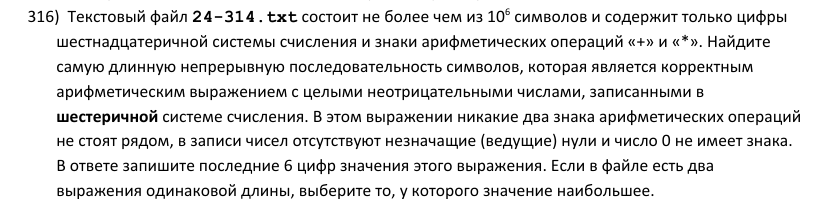

<details><summary>Текст условия</summary>Текстовый файл 24-314.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Найдите самую длинную непрерывную последовательность символов, которая является корректным арифметическим выражением с целыми неотрицательными числами, записанными в шестеричной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака. В ответе запишите последние 6 цифр значения этого выражения. Если в файле есть два выражения одинаковой длины, выберите то, у которого значение наибольшее.</details>

**Способ 1:** регулярное выражение + вычисление значения

In [530]:
from re import findall
s = open('24-314.txt').readline().strip()
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
num = '(?:[1-5][0-5]*|0)'
a = findall(f'{num}(?:[+*]{num})*', s)
best = max(a, key=lambda x: (len(x), value(x, 6)))   # длиннее, при равенстве — значение больше
v = value(best, 6)
print(len(best), str(v)[-6:])

27 5513


**Способ 2 (проверка):** ручной разбор (парсер)

In [531]:
s = open('24-314.txt').readline().strip()
D = '012345'
n = len(s)
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
def number(j):
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in D[1:]:
        j += 1
        while j < n and s[j] in D:
            j += 1
        return j
    return -1
def parse(i):
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
best = (0, 0)
for i in range(n):
    if i > 0 and s[i-1] in D[1:]:    # можно начать на символ раньше — будет длиннее
        continue
    e = parse(i)
    if e != -1:
        x = s[i:e]
        best = max(best, (len(x), value(x, 6)))
v = best[1]
print(best[0], str(v)[-6:])

27 5513


**Ответ: `5513`**

> Программа печатает длину выражения и ответ. «Последние 6 цифр» — в десятичной записи значения.

### Задача 317

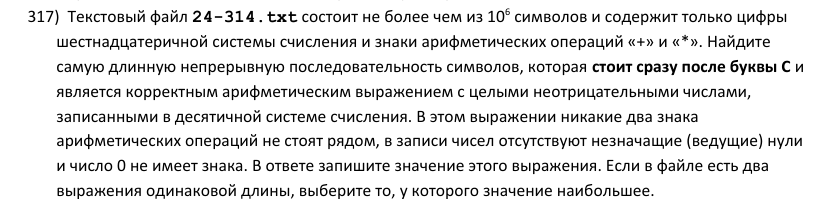

<details><summary>Текст условия</summary>Текстовый файл 24-314.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Найдите самую длинную непрерывную последовательность символов, которая стоит сразу после буквы С и является корректным арифметическим выражением с целыми неотрицательными числами, записанными в десятичной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака. В ответе запишите значение этого выражения. Если в файле есть два выражения одинаковой длины, выберите то, у которого значение наибольшее.</details>

**Способ 1:** регулярное выражение + вычисление значения

In [532]:
from re import findall
s = open('24-314.txt').readline().strip()
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
num = '(?:[1-9][0-9]*|0)'
a = findall(f'(?<=C){num}(?:[+*]{num})*', s)
best = max(a, key=lambda x: (len(x), value(x, 10)))   # длиннее, при равенстве — значение больше
v = value(best, 10)
print(len(best), v)

52 31201


**Способ 2 (проверка):** ручной разбор (парсер)

In [533]:
s = open('24-314.txt').readline().strip()
D = '0123456789'
n = len(s)
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
def number(j):
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in D[1:]:
        j += 1
        while j < n and s[j] in D:
            j += 1
        return j
    return -1
def parse(i):
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
best = (0, 0)
for i in range(n):
    if i == 0 or s[i-1] != 'C':
        continue
    e = parse(i)
    if e != -1:
        x = s[i:e]
        best = max(best, (len(x), value(x, 10)))
v = best[1]
print(best[0], v)

52 31201


**Ответ: `31201`**

> Программа печатает длину найденного выражения и его значение (ответ).

### Задача 318

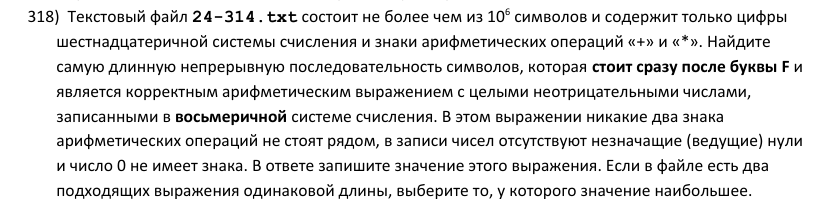

<details><summary>Текст условия</summary>Текстовый файл 24-314.txt состоит не более чем из 10⁶ символов и содержит только цифры шестнадцатеричной системы счисления и знаки арифметических операций «+» и «*». Найдите самую длинную непрерывную последовательность символов, которая стоит сразу после буквы F и является корректным арифметическим выражением с целыми неотрицательными числами, записанными в восьмеричной системе счисления. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака. В ответе запишите значение этого выражения. Если в файле есть два подходящих выражения одинаковой длины, выберите то, у которого значение наибольшее.</details>

**Способ 1:** регулярное выражение + вычисление значения

In [534]:
from re import findall
s = open('24-314.txt').readline().strip()
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
num = '(?:[1-7][0-7]*|0)'
a = findall(f'(?<=F){num}(?:[+*]{num})*', s)
best = max(a, key=lambda x: (len(x), value(x, 8)))   # длиннее, при равенстве — значение больше
v = value(best, 8)
print(len(best), v)

34 142844


**Способ 2 (проверка):** ручной разбор (парсер)

In [535]:
s = open('24-314.txt').readline().strip()
D = '01234567'
n = len(s)
def value(x, b):            # значение выражения: сумма произведений
    total = 0
    for term in x.split('+'):
        p = 1
        for v in term.split('*'):
            p *= int(v, b)
        total += p
    return total
def number(j):
    if j < n and s[j] == '0':
        return j + 1
    if j < n and s[j] in D[1:]:
        j += 1
        while j < n and s[j] in D:
            j += 1
        return j
    return -1
def parse(i):
    e = number(i)
    if e == -1:
        return -1
    while e < n and s[e] in '+*':
        e2 = number(e + 1)
        if e2 == -1:
            break
        e = e2
    return e
best = (0, 0)
for i in range(n):
    if i == 0 or s[i-1] != 'F':
        continue
    e = parse(i)
    if e != -1:
        x = s[i:e]
        best = max(best, (len(x), value(x, 8)))
v = best[1]
print(best[0], v)

34 142844


**Ответ: `142844`**

> Программа печатает длину найденного выражения и его значение (ответ).

### Задача 319

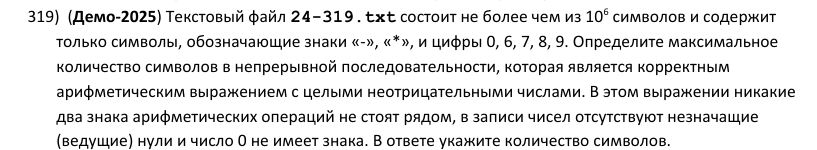

<details><summary>Текст условия</summary>(Демо-2025) Текстовый файл 24-319.txt состоит не более чем из 10⁶ символов и содержит только символы, обозначающие знаки «-», «*», и цифры 0, 6, 7, 8, 9. Определите максимальное количество символов в непрерывной последовательности, которая является корректным арифметическим выражением с целыми неотрицательными числами. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака. В ответе укажите количество символов.</details>

**Способ 1:** регулярное выражение

In [536]:
from re import findall
s = open('24-319.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
print(max(map(len, findall(fr'{num}(?:[-*]{num})*', s))))

140


**Способ 2 (проверка):** метод замен (статья К.Ю. Полякова)

In [537]:
s = open('24-319.txt').readline().strip()
# метод замен из статьи К.Ю. Полякова (разбор Демо-2025)
s = ' ' + s + ' '
for c in '6789':
    s = s.replace(c, '1')
s = s.replace('-', '*')
s = s.replace('**', ' ')
s = s.replace(' *', ' ')
s = s.replace('* ', ' ')
s = s.replace('*00', '*0 0')
s = s.replace('*01', '*0 1')
while ' 00' in s:
    s = s.replace(' 00', ' 0')
s = s.replace(' 01', ' 1')
print(len(max(s.split(), key=len)))

140


**Ответ: `140`**

## Цепочки «число=число=…» (С. Якунин)

**Разбиение на цепочки.** `re.finditer(r'\d+(?:=\d+)*', s)` находит максимальные цепочки без соседних `=`.
Внутри цепочки числа — это `t = run.split('=')`. Если какое-то **целое** число цепочки подходит под условие,
ответ-кандидат — вся цепочка. Если нет, условию может удовлетворять **обрезанное** крайнее число:
цепочка может начинаться с «хвоста» числа и заканчиваться «головой» числа. Тогда берём цепочку от начала до
подходящего префикса числа `t[k]` или от подходящего суффикса `t[k]` до конца.
Чисел в цепочке должно быть не меньше двух.

> В файле нет нулей, поэтому любое обрезанное число — правильная запись без ведущих нулей.

### Задача 320

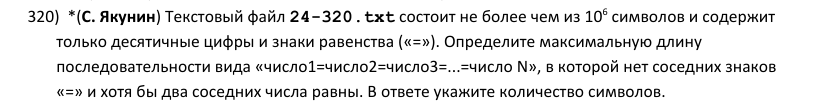

<details><summary>Текст условия</summary>*(С. Якунин) Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и хотя бы два соседних числа равны. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка соседних чисел

In [538]:
from re import finditer
s = open('24-320.txt').readline().strip()
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    t = m.group().split('=')
    full = len(m.group())
    if len(t) < 2:
        continue
    if any(t[i] == t[i+1] for i in range(len(t) - 1)):
        mx = max(mx, full)
        continue
    pre = 0                                  # длина цепочки до числа t[k]
    for k in range(len(t) - 1):
        a, b = t[k], t[k+1]
        if a.endswith(b):                    # хвост a равен b: от хвоста a до конца цепочки
            mx = max(mx, full - pre - (len(a) - len(b)))
        if b.startswith(a):                  # голова b равна a: от начала цепочки до головы b
            mx = max(mx, pre + len(a) + 1 + len(a))
        for L in range(min(len(a), len(b)), 0, -1):   # хвост a = голова b
            if a[-L:] == b[:L]:
                mx = max(mx, 2 * L + 1)
                break
        pre += len(a) + 1
print(mx)

989


**Ответ: `989`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 321

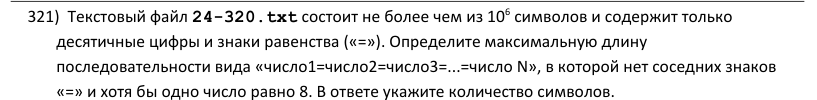

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и хотя бы одно число равно 8. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (хотя бы одно число равно 8)

In [539]:
from re import finditer
s = open('24-320.txt').readline().strip()
def P(x):                 # подходит ли число x
    return x == '8'
LENS = [1]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

1032


**Ответ: `1032`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 322

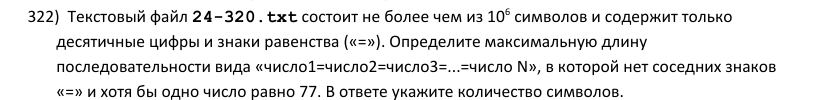

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и хотя бы одно число равно 77. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (хотя бы одно число равно 77)

In [540]:
from re import finditer
s = open('24-320.txt').readline().strip()
def P(x):                 # подходит ли число x
    return x == '77'
LENS = [2]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

670


**Ответ: `670`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 323

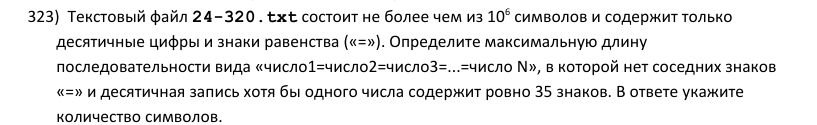

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и десятичная запись хотя бы одного числа содержит ровно 35 знаков. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (есть число из 35 цифр)

In [541]:
from re import finditer
s = open('24-320.txt').readline().strip()
def P(x):                 # подходит ли число x
    return len(x) == 35
LENS = [35]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

821


**Ответ: `821`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 324

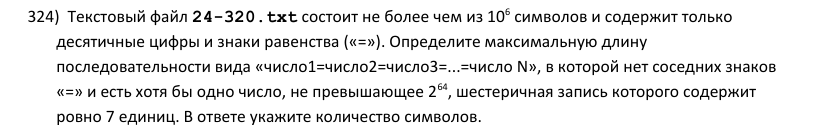

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и есть хотя бы одно число, не превышающее 2⁶⁴, шестеричная запись которого содержит ровно 7 единиц. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (число ≤ 2^64 с семью единицами в шестеричной записи)

In [542]:
from re import finditer
s = open('24-320.txt').readline().strip()
def to6(v):              # запись в шестеричной системе
    r = ''
    while v:
        r = str(v % 6) + r
        v //= 6
    return r
def P(x):                 # подходит ли число x
    return int(x) <= 2**64 and to6(int(x)).count('1') == 7
LENS = range(1, 21)            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

910


**Ответ: `910`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 325

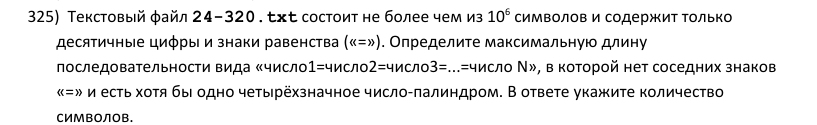

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и есть хотя бы одно четырёхзначное число-палиндром. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (четырёхзначный палиндром)

In [543]:
from re import finditer
s = open('24-320.txt').readline().strip()
def P(x):                 # подходит ли число x
    return len(x) == 4 and x == x[::-1]
LENS = [4]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

836


**Ответ: `836`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 326

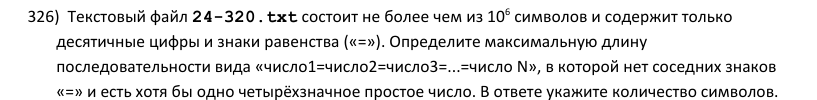

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и есть хотя бы одно четырёхзначное простое число. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (четырёхзначное простое)

In [544]:
from re import finditer
s = open('24-320.txt').readline().strip()
def isprime(v):
    return v > 1 and all(v % d for d in range(2, int(v ** 0.5) + 1))
def P(x):                 # подходит ли число x
    return len(x) == 4 and isprime(int(x))
LENS = [4]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

999


**Ответ: `999`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 327

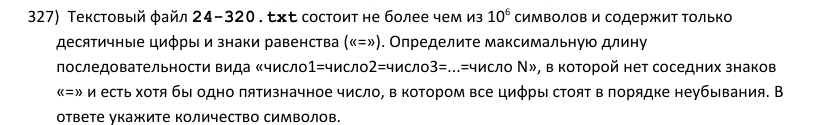

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и есть хотя бы одно пятизначное число, в котором все цифры стоят в порядке неубывания. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (пятизначное с неубывающими цифрами)

In [545]:
from re import finditer
s = open('24-320.txt').readline().strip()
def P(x):                 # подходит ли число x
    return len(x) == 5 and list(x) == sorted(x)
LENS = [5]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

796


**Ответ: `796`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 328

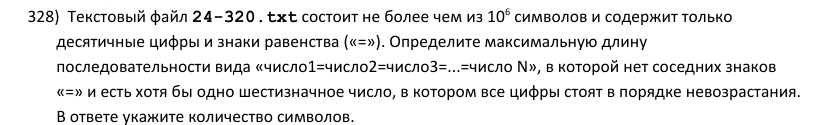

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и есть хотя бы одно шестизначное число, в котором все цифры стоят в порядке невозрастания. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (шестизначное с невозрастающими цифрами)

In [546]:
from re import finditer
s = open('24-320.txt').readline().strip()
def P(x):                 # подходит ли число x
    return len(x) == 6 and list(x) == sorted(x, reverse=True)
LENS = [6]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

708


**Ответ: `708`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 329

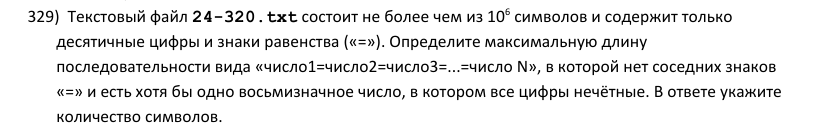

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и есть хотя бы одно восьмизначное число, в котором все цифры нечётные. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (восьмизначное из нечётных цифр)

In [547]:
from re import finditer
s = open('24-320.txt').readline().strip()
def P(x):                 # подходит ли число x
    return len(x) == 8 and all(c in '13579' for c in x)
LENS = [8]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

873


**Ответ: `873`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 330

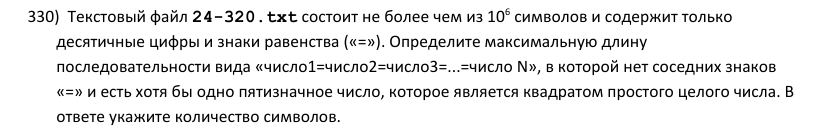

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и есть хотя бы одно пятизначное число, которое является квадратом простого целого числа. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (пятизначный квадрат простого числа)

In [548]:
from re import finditer
s = open('24-320.txt').readline().strip()
def isprime(v):
    return v > 1 and all(v % d for d in range(2, int(v ** 0.5) + 1))
SQ = {p * p for p in range(100, 317) if isprime(p)}     # пятизначные квадраты простых
def P(x):                 # подходит ли число x
    return len(x) == 5 and int(x) in SQ
LENS = [5]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

430


**Ответ: `430`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

### Задача 331

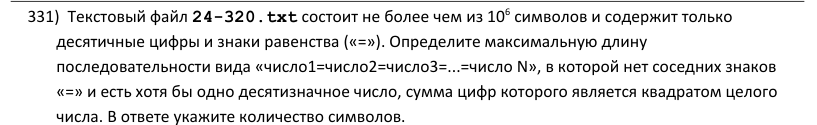

<details><summary>Текст условия</summary>Текстовый файл 24-320.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры и знаки равенства («=»). Определите максимальную длину последовательности вида «число1=число2=число3=...=число N», в которой нет соседних знаков «=» и есть хотя бы одно десятизначное число, сумма цифр которого является квадратом целого числа. В ответе укажите количество символов.</details>

**Способ 1:** цепочки + проверка чисел (десятизначное с суммой цифр — точным квадратом)

In [549]:
from re import finditer
s = open('24-320.txt').readline().strip()
def P(x):                 # подходит ли число x
    return len(x) == 10 and int(sum(map(int, x)) ** 0.5) ** 2 == sum(map(int, x))
LENS = [10]            # какой длины может быть подходящее число
mx = 0
for m in finditer(r'\d+(?:=\d+)*', s):
    run = m.group()
    t = run.split('=')
    if len(t) < 2:
        continue
    full = len(run)
    if any(P(x) for x in t):
        mx = max(mx, full)
        continue
    pre = 0                                    # длина цепочки до числа t[k]
    for k, x in enumerate(t):
        for L in LENS:
            if L < len(x):
                if k > 0 and P(x[:L]):         # цепочка от начала до «головы» числа x
                    mx = max(mx, pre + L)
                if k < len(t) - 1 and P(x[-L:]):   # от «хвоста» числа x до конца цепочки
                    mx = max(mx, full - pre - (len(x) - L))
        pre += len(x) + 1
print(mx)

961


**Ответ: `961`**

> Метод проверен полным перебором подстрок на тысячах случайных строк.

## Предложения, адреса, группы — регулярные выражения

Сложные «корректные записи» удобно описывать шаблоном по частям: слово → предложение, имя → адрес,
число → группа. Если совпадения могут перекрываться (адрес может начаться внутри предыдущего), используем
`(?=(шаблон))`.

### Задача 332

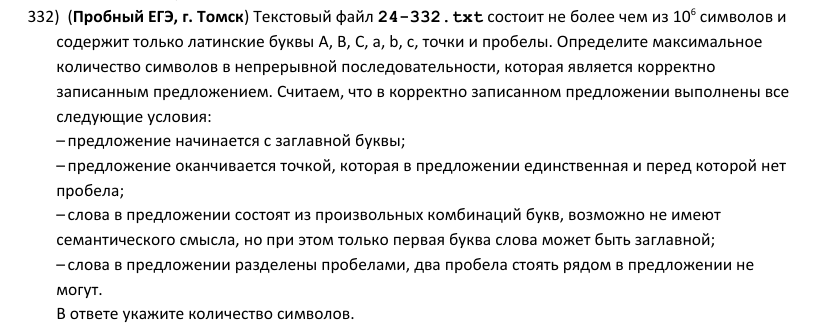

<details><summary>Текст условия</summary>(Пробный ЕГЭ, г. Томск) Текстовый файл 24-332.txt состоит не более чем из 10⁶ символов и содержит только латинские буквы A, B, C, a, b, c, точки и пробелы. Определите максимальное количество символов в непрерывной последовательности, которая является корректно записанным предложением. Считаем, что в корректно записанном предложении выполнены все следующие условия:<br>–	предложение начинается с заглавной буквы;<br>–	предложение оканчивается точкой, которая в предложении единственная и перед которой нет пробела;<br>–	слова в предложении состоят из произвольных комбинаций букв, возможно не имеют семантического смысла, но при этом только первая буква слова может быть заглавной;<br>–	слова в предложении разделены пробелами, два пробела стоять рядом в предложении не могут.<br>В ответе укажите количество символов.</details>

**Способ 1:** регулярное выражение

In [550]:
from re import findall
s = open('24-332.txt').readline().strip()
word = '[A-Ca-c][a-c]*'                      # заглавной может быть только первая буква слова
sent = f'[A-C][a-c]*(?: {word})*\\.'         # с заглавной, слова через один пробел, точка в конце
print(max(map(len, findall(sent, s))))

22


**Способ 2 (проверка):** разбор с конца каждого куска до точки

In [551]:
s = open('24-332.txt').readline().strip()
mx = 0
for chunk in s.split('.')[:-1]:              # всё, что стоит перед очередной точкой
    if not chunk or chunk[-1] == ' ':
        continue
    j = len(chunk)
    start = -1
    while True:
        k = j
        while k > 0 and chunk[k-1] in 'abc':  # строчные буквы слова
            k -= 1
        if k > 0 and chunk[k-1] in 'ABC':     # заглавная — начало слова
            k -= 1
            start = k
        if k == j:                            # пустое слово — дальше влево нельзя
            break
        if k >= 2 and chunk[k-1] == ' ' and chunk[k-2] != ' ':
            j = k - 1                         # слева один пробел и ещё слово
        else:
            break
    if start != -1:
        mx = max(mx, len(chunk) - start + 1)
print(mx)

22


**Ответ: `22`**

### Задача 333

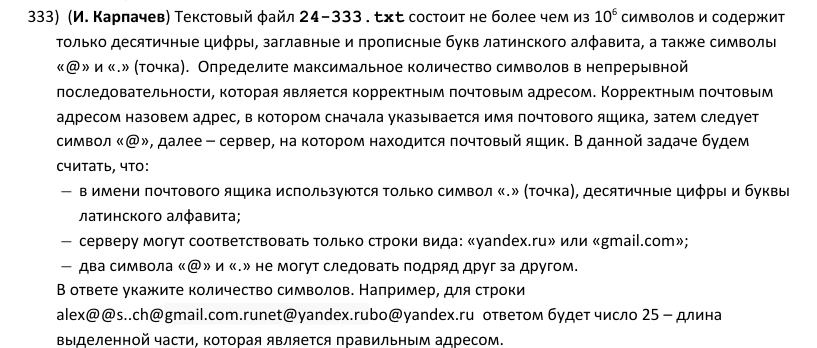

<details><summary>Текст условия</summary>(И. Карпачев) Текстовый файл 24-333.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры, заглавные и прописные букв латинского алфавита, а также символы «@» и «.» (точка).  Определите максимальное количество символов в непрерывной последовательности, которая является корректным почтовым адресом. Корректным почтовым адресом назовем адрес, в котором сначала указывается имя почтового ящика, затем следует символ «@», далее – сервер, на котором находится почтовый ящик. В данной задаче будем считать, что:<br>• в имени почтового ящика используются только символ «.» (точка), десятичные цифры и буквы латинского алфавита;<br>• серверу могут соответствовать только строки вида: «yandex.ru» или «gmail.com»;<br>• два символа «@» и «.» не могут следовать подряд друг за другом.<br>В ответе укажите количество символов. Например, для строки alex@@s..ch@gmail.com.runet@yandex.rubo@yandex.ru  ответом будет число 25 – длина выделенной части, которая является правильным адресом.</details>

**Способ 1:** регулярное выражение с (?=...)

In [552]:
from re import findall
s = open('24-333.txt').readline().strip()
name = r'[A-Za-z0-9]+(?:\.[A-Za-z0-9]+)*'     # без двух точек подряд и точки по краям
mail = name + r'@(?:yandex\.ru|gmail\.com)'
print(max(map(len, findall(f'(?=({mail}))', s))))

118


**Способ 2 (проверка):** split по @ + разбор хвоста

In [553]:
s = open('24-333.txt').readline().strip()
parts = s.split('@')
alnum = set('abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789')
mx = 0
for i in range(len(parts) - 1):
    a, b = parts[i], parts[i+1]
    if not (b.startswith('yandex.ru') or b.startswith('gmail.com')):
        continue
    # самый длинный правильный хвост a — имя ящика
    k = len(a)
    while k > 0 and (a[k-1] in alnum or (a[k-1] == '.' and k - 1 > 0 and a[k-2] in alnum and k < len(a) and a[k] in alnum)):
        k -= 1
    if k < len(a) and a[k] in alnum:
        mx = max(mx, len(a) - k + 1 + 9)       # имя + @ + 9 символов сервера
print(mx)

118


**Ответ: `118`**

### Задача 334

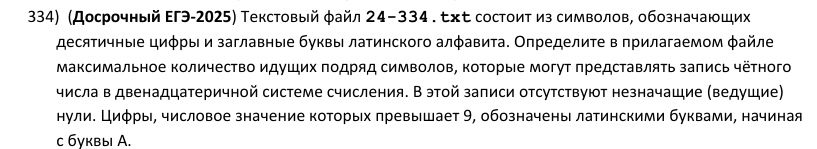

<details><summary>Текст условия</summary>(Досрочный ЕГЭ-2025) Текстовый файл 24-334.txt состоит из символов, обозначающих десятичные цифры и заглавные буквы латинского алфавита. Определите в прилагаемом файле максимальное количество идущих подряд символов, которые могут представлять запись чётного числа в двенадцатеричной системе счисления. В этой записи отсутствуют незначащие (ведущие) нули. Цифры, числовое значение которых превышает 9, обозначены латинскими буквами, начиная с буквы А.</details>

**Способ 1:** регулярное выражение

In [554]:
from re import findall
s = open('24-334.txt').readline().strip()
a = findall('[1-9AB][0-9AB]*[02468A]|[02468A]', s)     # чётное 12-ричное: последняя цифра чётная
print(max(map(len, a)))

19


**Способ 2 (проверка):** однопроходный алгоритм

In [555]:
s = open('24-334.txt').readline().strip()
D = '0123456789AB'
mx = 0
L = -1          # начало числа (первая ненулевая цифра текущего участка), -1 — нет
for R, c in enumerate(s):
    if c not in D:
        L = -1
        continue
    if L == -1 and c != '0':
        L = R
    if c in '02468A':
        mx = max(mx, R - L + 1 if L != -1 else 1)
print(mx)

19


**Ответ: `19`**

### Задача 335

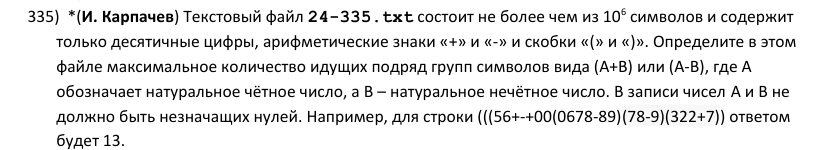

<details><summary>Текст условия</summary>*(И. Карпачев) Текстовый файл 24-335.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры, арифметические знаки «+» и «-» и скобки «(» и «)». Определите в этом файле максимальное количество идущих подряд групп символов вида (A+B) или (A-B), где А обозначает натуральное чётное число, а B – натуральное нечётное число. В записи чисел A и B не должно быть незначащих нулей. Например, для строки (((56+-+00(0678-89)(78-9)(322+7)) ответом будет 13.</details>

**Способ 1:** регулярное выражение

In [556]:
from re import findall
s = open('24-335.txt').readline().strip()
A = '(?:[1-9][0-9]*[02468]|[2468])'
B = '(?:[1-9][0-9]*[13579]|[13579])'                 # A чётное, B нечётное
grp = rf'\({A}[+-]{B}\)'
print(max(map(len, findall(f'(?:{grp})+', s))))

89


**Способ 2 (проверка):** группы по одной + склейка

In [557]:
from re import finditer
s = open('24-335.txt').readline().strip()
A = '(?:[1-9][0-9]*[02468]|[2468])'
B = '(?:[1-9][0-9]*[13579]|[13579])'
grp = rf'\({A}[+-]{B}\)'
best = 0
end = -1
cur = 0
for m in finditer(grp, s):          # отдельные группы; склеиваем идущие вплотную
    cur = cur + len(m.group()) if m.start() == end else len(m.group())
    end = m.end()
    best = max(best, cur)
print(best)

89


**Ответ: `89`**

> Как видно из примера в условии (ответ 13 = длина «(78-9)(322+7)»), в ответ пишется количество символов.

### Задача 336

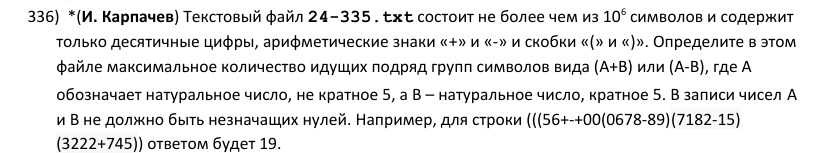

<details><summary>Текст условия</summary>*(И. Карпачев) Текстовый файл 24-335.txt состоит не более чем из 10⁶ символов и содержит только десятичные цифры, арифметические знаки «+» и «-» и скобки «(» и «)». Определите в этом файле максимальное количество идущих подряд групп символов вида (A+B) или (A-B), где А обозначает натуральное число, не кратное 5, а B – натуральное число, кратное 5. В записи чисел A и B не должно быть незначащих нулей. Например, для строки (((56+-+00(0678-89)(7182-15)(3222+745)) ответом будет 19.</details>

**Способ 1:** регулярное выражение

In [558]:
from re import findall
s = open('24-335.txt').readline().strip()
A = '(?:[1-9][0-9]*[1-46-9]|[1-46-9])'
B = '(?:[1-9][0-9]*[05]|5)'                 # A не кратно 5, B кратно 5
grp = rf'\({A}[+-]{B}\)'
print(max(map(len, findall(f'(?:{grp})+', s))))

55


**Способ 2 (проверка):** группы по одной + склейка

In [559]:
from re import finditer
s = open('24-335.txt').readline().strip()
A = '(?:[1-9][0-9]*[1-46-9]|[1-46-9])'
B = '(?:[1-9][0-9]*[05]|5)'
grp = rf'\({A}[+-]{B}\)'
best = 0
end = -1
cur = 0
for m in finditer(grp, s):          # отдельные группы; склеиваем идущие вплотную
    cur = cur + len(m.group()) if m.start() == end else len(m.group())
    end = m.end()
    best = max(best, cur)
print(best)

55


**Ответ: `55`**

> Как видно из примера в условии (ответ 13 = длина «(78-9)(322+7)»), в ответ пишется количество символов.

## Числа в системах счисления с делимостью (К. Багдасарян, А. Кабанов)

Признаки делимости в системе с основанием `b`:
* на делители `b` (и на `b` целиком) — по **последней цифре**: 16-ричное кратно 8 ⇔ последняя цифра 0 или 8;
  12-ричное кратно 3 ⇔ последняя цифра 0, 3, 6, 9;
* на `b²` — по двум последним цифрам; 12-ричное кратно 144 ⇔ оканчивается на `00`;
* на `b − 1` (и его делители) — по **сумме цифр**: 12-ричное кратно 11 ⇔ сумма цифр кратна 11.

Самое длинное подходящее число в участке цифр начинается с первой ненулевой цифры и заканчивается последней
подходящей цифрой — это ровно то, что находит «жадный» шаблон вида `[1-9…][…]*[подходящие]`.
Если признака нет (14-ричное, кратное 5), перебираем начало и конец внутри каждого участка цифр и проверяем
`int(x, b) % m == 0` — участки короткие, это быстро.

Проверка — **перебор** всех подстрок каждого участка с `int(x, b)`.

### Задача 337

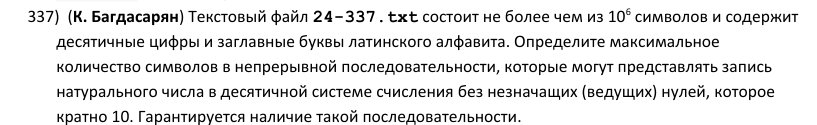

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-337.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите максимальное количество символов в непрерывной последовательности, которые могут представлять запись натурального числа в десятичной системе счисления без незначащих (ведущих) нулей, которое кратно 10. Гарантируется наличие такой последовательности.</details>

**Способ 1:** регулярное выражение по признаку делимости

In [560]:
from re import findall
s = open('24-337.txt').readline().strip()
print(max(map(len, findall('[1-9][0-9]*0', s))))

74


**Способ 2 (проверка):** перебор подстрок участков с int()

In [561]:
from re import findall
s = open('24-337.txt').readline().strip()
best = None
for run in findall('[0-9]+', s):
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):      # от длинных к коротким
            if int(run[i:j], 10) % 10 == 0 and True:
                if best is None or j - i > len(best):
                    best = run[i:j]
                break
print(len(best))

74


**Ответ: `74`**

### Задача 338

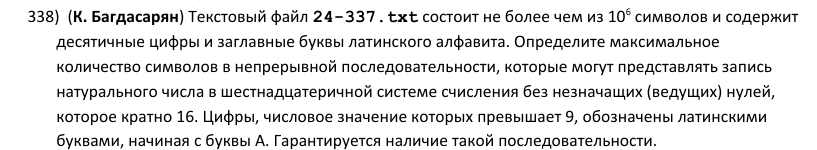

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-337.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите максимальное количество символов в непрерывной последовательности, которые могут представлять запись натурального числа в шестнадцатеричной системе счисления без незначащих (ведущих) нулей, которое кратно 16. Цифры, числовое значение которых превышает 9, обозначены латинскими буквами, начиная с буквы А. Гарантируется наличие такой последовательности.</details>

**Способ 1:** регулярное выражение по признаку делимости

In [562]:
from re import findall
s = open('24-337.txt').readline().strip()
print(max(map(len, findall('[1-9A-F][0-9A-F]*0', s))))

76


**Способ 2 (проверка):** перебор подстрок участков с int()

In [563]:
from re import findall
s = open('24-337.txt').readline().strip()
best = None
for run in findall('[0-9A-F]+', s):
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):      # от длинных к коротким
            if int(run[i:j], 16) % 16 == 0 and True:
                if best is None or j - i > len(best):
                    best = run[i:j]
                break
print(len(best))

76


**Ответ: `76`**

### Задача 339

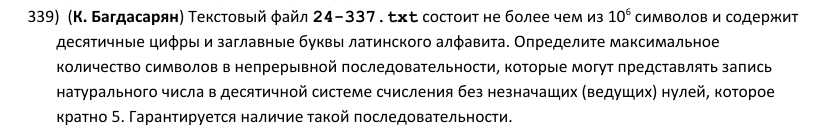

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-337.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите максимальное количество символов в непрерывной последовательности, которые могут представлять запись натурального числа в десятичной системе счисления без незначащих (ведущих) нулей, которое кратно 5. Гарантируется наличие такой последовательности.</details>

**Способ 1:** регулярное выражение по признаку делимости

In [564]:
from re import findall
s = open('24-337.txt').readline().strip()
print(max(map(len, findall('[1-9][0-9]*[05]|5', s))))

75


**Способ 2 (проверка):** перебор подстрок участков с int()

In [565]:
from re import findall
s = open('24-337.txt').readline().strip()
best = None
for run in findall('[0-9]+', s):
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):      # от длинных к коротким
            if int(run[i:j], 10) % 5 == 0 and True:
                if best is None or j - i > len(best):
                    best = run[i:j]
                break
print(len(best))

75


**Ответ: `75`**

### Задача 340

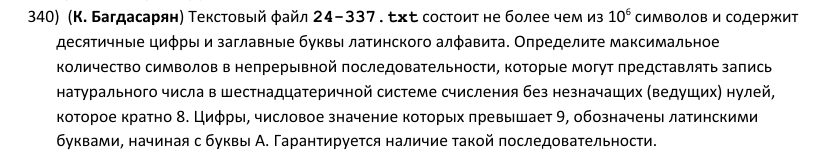

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-337.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите максимальное количество символов в непрерывной последовательности, которые могут представлять запись натурального числа в шестнадцатеричной системе счисления без незначащих (ведущих) нулей, которое кратно 8. Цифры, числовое значение которых превышает 9, обозначены латинскими буквами, начиная с буквы А. Гарантируется наличие такой последовательности.</details>

**Способ 1:** регулярное выражение по признаку делимости

In [566]:
from re import findall
s = open('24-337.txt').readline().strip()
print(max(map(len, findall('[1-9A-F][0-9A-F]*[08]|8', s))))

80


**Способ 2 (проверка):** перебор подстрок участков с int()

In [567]:
from re import findall
s = open('24-337.txt').readline().strip()
best = None
for run in findall('[0-9A-F]+', s):
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):      # от длинных к коротким
            if int(run[i:j], 16) % 8 == 0 and True:
                if best is None or j - i > len(best):
                    best = run[i:j]
                break
print(len(best))

80


**Ответ: `80`**

### Задача 341

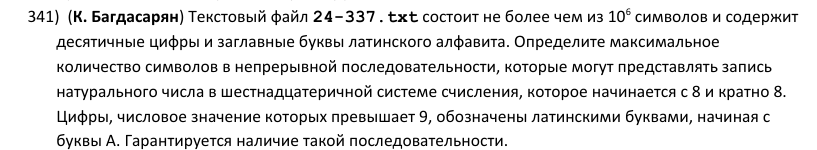

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-337.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите максимальное количество символов в непрерывной последовательности, которые могут представлять запись натурального числа в шестнадцатеричной системе счисления, которое начинается с 8 и кратно 8. Цифры, числовое значение которых превышает 9, обозначены латинскими буквами, начиная с буквы А. Гарантируется наличие такой последовательности.</details>

**Способ 1:** регулярное выражение по признаку делимости

In [568]:
from re import findall
s = open('24-337.txt').readline().strip()
print(max(map(len, findall('8[0-9A-F]*[08]|8', s))))

78


**Способ 2 (проверка):** перебор подстрок участков с int()

In [569]:
from re import findall
s = open('24-337.txt').readline().strip()
best = None
for run in findall('[0-9A-F]+', s):
    for i in range(len(run)):
        if run[i] != '8':
            continue
        for j in range(len(run), i, -1):      # от длинных к коротким
            if int(run[i:j], 16) % 8 == 0 and True:
                if best is None or j - i > len(best):
                    best = run[i:j]
                break
print(len(best))

78


**Ответ: `78`**

### Задача 342

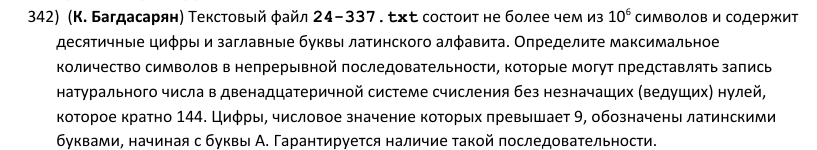

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-337.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите максимальное количество символов в непрерывной последовательности, которые могут представлять запись натурального числа в двенадцатеричной системе счисления без незначащих (ведущих) нулей, которое кратно 144. Цифры, числовое значение которых превышает 9, обозначены латинскими буквами, начиная с буквы А. Гарантируется наличие такой последовательности.</details>

**Способ 1:** регулярное выражение по признаку делимости

In [570]:
from re import findall
s = open('24-337.txt').readline().strip()
print(max(map(len, findall('[1-9AB][0-9AB]*00', s))))

71


**Способ 2 (проверка):** перебор подстрок участков с int()

In [571]:
from re import findall
s = open('24-337.txt').readline().strip()
best = None
for run in findall('[0-9AB]+', s):
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):      # от длинных к коротким
            if int(run[i:j], 12) % 144 == 0 and True:
                if best is None or j - i > len(best):
                    best = run[i:j]
                break
print(len(best))

71


**Ответ: `71`**

### Задача 343

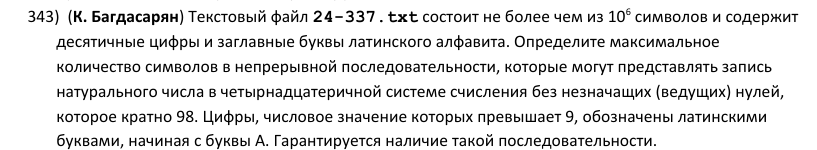

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-337.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите максимальное количество символов в непрерывной последовательности, которые могут представлять запись натурального числа в четырнадцатеричной системе счисления без незначащих (ведущих) нулей, которое кратно 98. Цифры, числовое значение которых превышает 9, обозначены латинскими буквами, начиная с буквы А. Гарантируется наличие такой последовательности.</details>

**Способ 1:** регулярное выражение по признаку делимости

In [572]:
from re import findall
s = open('24-337.txt').readline().strip()
print(max(map(len, findall('[1-9A-D][0-9A-D]*[07]0|70', s))))

73


**Способ 2 (проверка):** перебор подстрок участков с int()

In [573]:
from re import findall
s = open('24-337.txt').readline().strip()
best = None
for run in findall('[0-9A-D]+', s):
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):      # от длинных к коротким
            if int(run[i:j], 14) % 98 == 0 and True:
                if best is None or j - i > len(best):
                    best = run[i:j]
                break
print(len(best))

73


**Ответ: `73`**

> 98 = 14·7: последняя цифра 0, а предпоследняя кратна 7 (0 или 7), так как 14 ≡ 0 (mod 7).

### Задача 344

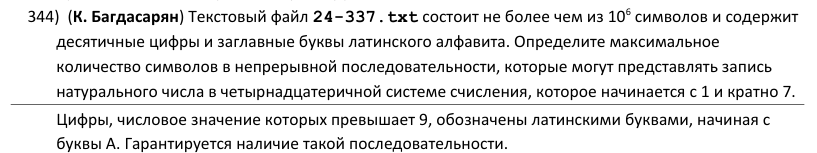

<details><summary>Текст условия</summary>(К. Багдасарян) Текстовый файл 24-337.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите максимальное количество символов в непрерывной последовательности, которые могут представлять запись натурального числа в четырнадцатеричной системе счисления, которое начинается с 1 и кратно 7. Цифры, числовое значение которых превышает 9, обозначены латинскими буквами, начиная с буквы А. Гарантируется наличие такой последовательности.</details>

**Способ 1:** регулярное выражение по признаку делимости

In [574]:
from re import findall
s = open('24-337.txt').readline().strip()
print(max(map(len, findall('1[0-9A-D]*[07]', s))))

71


**Способ 2 (проверка):** перебор подстрок участков с int()

In [575]:
from re import findall
s = open('24-337.txt').readline().strip()
best = None
for run in findall('[0-9A-D]+', s):
    for i in range(len(run)):
        if run[i] != '1':
            continue
        for j in range(len(run), i, -1):      # от длинных к коротким
            if int(run[i:j], 14) % 7 == 0 and True:
                if best is None or j - i > len(best):
                    best = run[i:j]
                break
print(len(best))

71


**Ответ: `71`**

> Так как 14 ≡ 0 (mod 7), число кратно 7 ⇔ последняя цифра 0 или 7.

## Максимальное число в записи: индекс начала/конца

**Максимальное число** — сначала самое длинное (без ведущих нулей), при равной длине — больше по цифрам.
Для цифр `0-9A-Z` порядок символов совпадает с порядком значений, поэтому при равной длине можно сравнивать
сами строки. `re.finditer` даёт и запись (`m.group()`), и позицию (`m.start()`, `m.end() - 1`).

### Задача 345

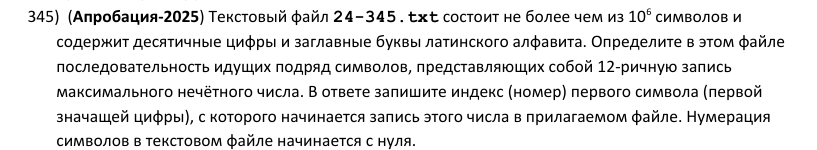

<details><summary>Текст условия</summary>(Апробация-2025) Текстовый файл 24-345.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность идущих подряд символов, представляющих собой 12-ричную запись максимального нечётного числа. В ответе запишите индекс (номер) первого символа (первой значащей цифры), с которого начинается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** регулярное выражение + max

In [576]:
from re import finditer
s = open('24-345.txt').readline().strip()
a = [(m.group(), m.start(), m.end() - 1) for m in finditer('[1-9AB][0-9AB]*[13579B]|[13579B]', s)]
x, st, en = max(a, key=lambda t: (len(t[0]), t[0]))
print(len(x), st)

108 144895


**Способ 2 (проверка):** перебор подстрок участков с int()

In [577]:
from re import findall, finditer
s = open('24-345.txt').readline().strip()
best = None
for m in finditer('[0-9AB]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):
            v = int(run[i:j], 12)
            if v % 2 == 1:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
                break
x, st, en = best
print(len(x), st)

108 144895


**Ответ: `144895`**

### Задача 346

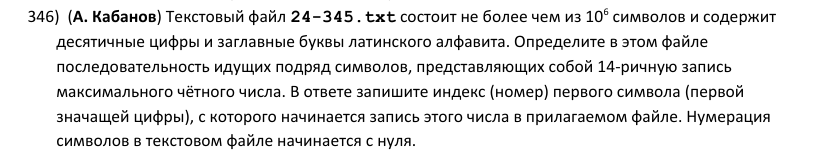

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-345.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность идущих подряд символов, представляющих собой 14-ричную запись максимального чётного числа. В ответе запишите индекс (номер) первого символа (первой значащей цифры), с которого начинается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** регулярное выражение + max

In [578]:
from re import finditer
s = open('24-345.txt').readline().strip()
a = [(m.group(), m.start(), m.end() - 1) for m in finditer('[1-9A-D][0-9A-D]*[02468AC]|[2468AC]', s)]
x, st, en = max(a, key=lambda t: (len(t[0]), t[0]))
print(len(x), st)

112 873241


**Способ 2 (проверка):** перебор подстрок участков с int()

In [579]:
from re import findall, finditer
s = open('24-345.txt').readline().strip()
best = None
for m in finditer('[0-9A-D]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):
            v = int(run[i:j], 14)
            if v % 2 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
                break
x, st, en = best
print(len(x), st)

112 873241


**Ответ: `873241`**

### Задача 347

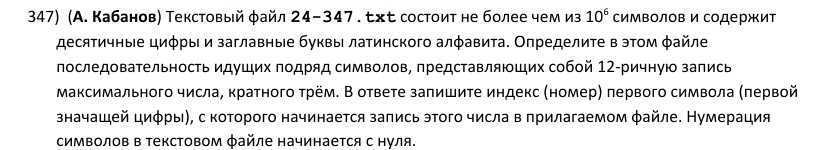

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность идущих подряд символов, представляющих собой 12-ричную запись максимального числа, кратного трём. В ответе запишите индекс (номер) первого символа (первой значащей цифры), с которого начинается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** регулярное выражение + max

In [580]:
from re import finditer
s = open('24-347.txt').readline().strip()
a = [(m.group(), m.start(), m.end() - 1) for m in finditer('[1-9AB][0-9AB]*[0369]|[369]', s)]
x, st, en = max(a, key=lambda t: (len(t[0]), t[0]))
print(len(x), st)

107 99831


**Способ 2 (проверка):** перебор подстрок участков с int()

In [581]:
from re import findall, finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-9AB]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):
            v = int(run[i:j], 12)
            if v % 3 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
                break
x, st, en = best
print(len(x), st)

107 99831


**Ответ: `99831`**

### Задача 348

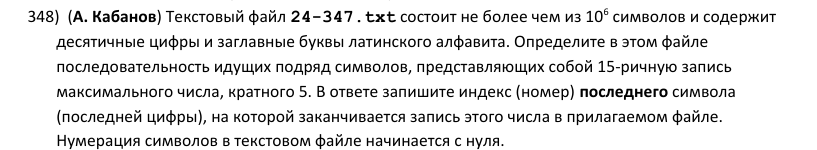

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность идущих подряд символов, представляющих собой 15-ричную запись максимального числа, кратного 5. В ответе запишите индекс (номер) последнего символа (последней цифры), на которой заканчивается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** регулярное выражение + max

In [582]:
from re import finditer
s = open('24-347.txt').readline().strip()
a = [(m.group(), m.start(), m.end() - 1) for m in finditer('[1-9A-E][0-9A-E]*[05A]|[5A]', s)]
x, st, en = max(a, key=lambda t: (len(t[0]), t[0]))
print(len(x), en)

112 13381


**Способ 2 (проверка):** перебор подстрок участков с int()

In [583]:
from re import findall, finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-9A-E]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):
            v = int(run[i:j], 15)
            if v % 5 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
                break
x, st, en = best
print(len(x), en)

112 13381


**Ответ: `13381`**

### Задача 349

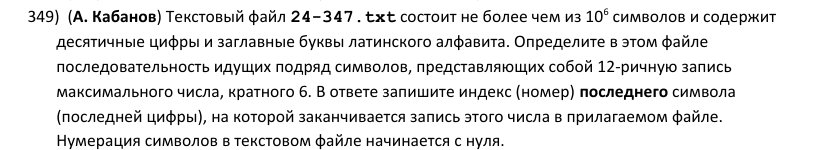

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность идущих подряд символов, представляющих собой 12-ричную запись максимального числа, кратного 6. В ответе запишите индекс (номер) последнего символа (последней цифры), на которой заканчивается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** регулярное выражение + max

In [584]:
from re import finditer
s = open('24-347.txt').readline().strip()
a = [(m.group(), m.start(), m.end() - 1) for m in finditer('[1-9AB][0-9AB]*[06]|6', s)]
x, st, en = max(a, key=lambda t: (len(t[0]), t[0]))
print(len(x), en)

107 99937


**Способ 2 (проверка):** перебор подстрок участков с int()

In [585]:
from re import findall, finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-9AB]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):
            v = int(run[i:j], 12)
            if v % 6 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
                break
x, st, en = best
print(len(x), en)

107 99937


**Ответ: `99937`**

### Задача 350

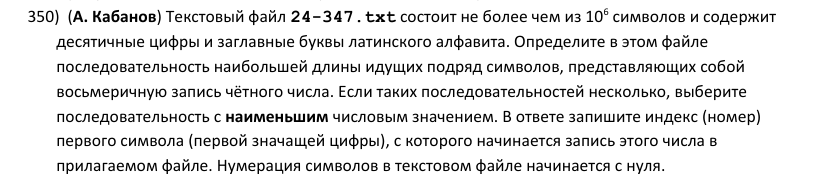

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность наибольшей длины идущих подряд символов, представляющих собой восьмеричную запись чётного числа. Если таких последовательностей несколько, выберите последовательность с наименьшим числовым значением. В ответе запишите индекс (номер) первого символа (первой значащей цифры), с которого начинается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** регулярное выражение + max

In [586]:
from re import finditer
s = open('24-347.txt').readline().strip()
a = [(m.group(), m.start(), m.end() - 1) for m in finditer('[1-7][0-7]*[0246]|[246]', s)]
x, st, en = max(a, key=lambda t: (len(t[0]), -int(t[0], 8)))
print(len(x), st)

17 655664


**Способ 2 (проверка):** перебор подстрок участков с int()

In [587]:
from re import findall, finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-7]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):
            v = int(run[i:j], 8)
            if v % 2 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), -int(cand[0], 8)) > (len(best[0]), -int(best[0], 8)):
                    best = cand
                break
x, st, en = best
print(len(x), st)

17 655664


**Ответ: `655664`**

### Задача 351

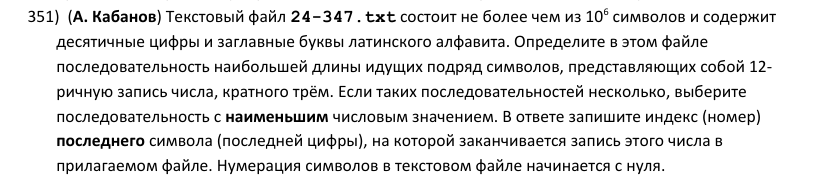

<details><summary>Текст условия</summary>(А. Кабанов) Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность наибольшей длины идущих подряд символов, представляющих собой 12-ричную запись числа, кратного трём. Если таких последовательностей несколько, выберите последовательность с наименьшим числовым значением. В ответе запишите индекс (номер) последнего символа (последней цифры), на которой заканчивается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** регулярное выражение + max

In [588]:
from re import finditer
s = open('24-347.txt').readline().strip()
a = [(m.group(), m.start(), m.end() - 1) for m in finditer('[1-9AB][0-9AB]*[0369]|[369]', s)]
x, st, en = max(a, key=lambda t: (len(t[0]), -int(t[0], 12)))
print(len(x), en)

107 770526


**Способ 2 (проверка):** перебор подстрок участков с int()

In [589]:
from re import findall, finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-9AB]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):
            v = int(run[i:j], 12)
            if v % 3 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), -int(cand[0], 12)) > (len(best[0]), -int(best[0], 12)):
                    best = cand
                break
x, st, en = best
print(len(x), en)

107 770526


**Ответ: `770526`**

### Задача 352

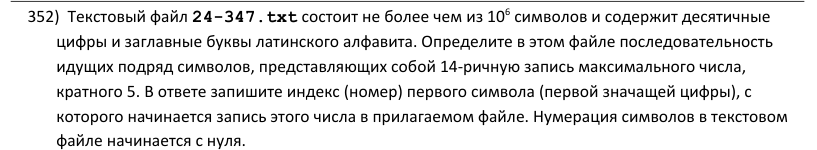

<details><summary>Текст условия</summary>Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность идущих подряд символов, представляющих собой 14-ричную запись максимального числа, кратного 5. В ответе запишите индекс (номер) первого символа (первой значащей цифры), с которого начинается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** перебор подстрок каждого участка цифр

In [590]:
from re import finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-9A-D]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):          # от длинных к коротким
            if int(run[i:j], 14) % 5 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
                break
x, st, en = best
print(len(x), st)

109 13273


**Способ 2 (проверка):** остатки по схеме Горнера

In [591]:
s = open('24-347.txt').readline().strip()
D = '0123456789ABCD'
best = None
i = 0
n = len(s)
while i < n:
    if s[i] not in D:
        i += 1
        continue
    j = i
    while j < n and s[j] in D:
        j += 1
    run = s[i:j]
    for a in range(len(run)):                     # остатки «на лету»: v = v*14 + цифра
        if run[a] == '0':
            continue
        v = 0
        for e in range(a, len(run)):
            v = (v * 14 + D.index(run[e])) % 5
            if v == 0:
                cand = (run[a:e+1], i + a, i + e)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
    i = j
x, st, en = best
print(len(x), st)

109 13273


**Ответ: `13273`**

### Задача 353

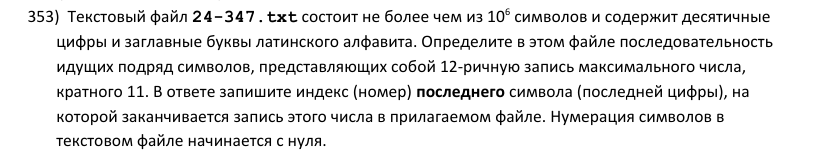

<details><summary>Текст условия</summary>Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность идущих подряд символов, представляющих собой 12-ричную запись максимального числа, кратного 11. В ответе запишите индекс (номер) последнего символа (последней цифры), на которой заканчивается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** перебор подстрок каждого участка цифр

In [592]:
from re import finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-9AB]+', s):
    run, base = m.group(), m.start()
    ps = [0]                                   # префиксные суммы цифр
    for c in run:
        ps.append(ps[-1] + int(c, 12))
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):          # от длинных к коротким
            if (ps[j] - ps[i]) % 11 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
                break
x, st, en = best
print(len(x), en)

106 1690


**Способ 2 (проверка):** остатки по схеме Горнера

In [593]:
s = open('24-347.txt').readline().strip()
D = '0123456789AB'
best = None
i = 0
n = len(s)
while i < n:
    if s[i] not in D:
        i += 1
        continue
    j = i
    while j < n and s[j] in D:
        j += 1
    run = s[i:j]
    for a in range(len(run)):                     # остатки «на лету»: v = v*12 + цифра
        if run[a] == '0':
            continue
        v = 0
        for e in range(a, len(run)):
            v = (v * 12 + D.index(run[e])) % 11
            if v == 0:
                cand = (run[a:e+1], i + a, i + e)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
    i = j
x, st, en = best
print(len(x), en)

106 1690


**Ответ: `1690`**

> Признак: 12 ≡ 1 (mod 11), поэтому число кратно 11 ⇔ сумма цифр кратна 11.

### Задача 354

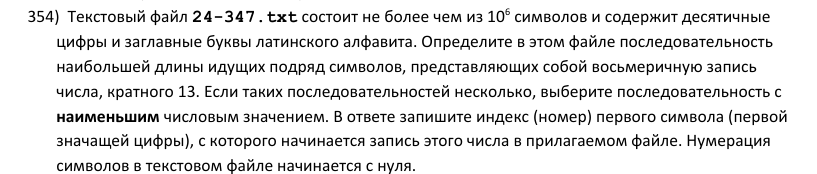

<details><summary>Текст условия</summary>Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность наибольшей длины идущих подряд символов, представляющих собой восьмеричную запись числа, кратного 13. Если таких последовательностей несколько, выберите последовательность с наименьшим числовым значением. В ответе запишите индекс (номер) первого символа (первой значащей цифры), с которого начинается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** перебор подстрок каждого участка цифр

In [594]:
from re import finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-7]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):          # от длинных к коротким
            if int(run[i:j], 8) % 13 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), -int(cand[0], 8)) > (len(best[0]), -int(best[0], 8)):
                    best = cand
                break
x, st, en = best
print(len(x), st)

16 605381


**Способ 2 (проверка):** остатки по схеме Горнера

In [595]:
s = open('24-347.txt').readline().strip()
D = '01234567'
best = None
i = 0
n = len(s)
while i < n:
    if s[i] not in D:
        i += 1
        continue
    j = i
    while j < n and s[j] in D:
        j += 1
    run = s[i:j]
    for a in range(len(run)):                     # остатки «на лету»: v = v*8 + цифра
        if run[a] == '0':
            continue
        v = 0
        for e in range(a, len(run)):
            v = (v * 8 + D.index(run[e])) % 13
            if v == 0:
                cand = (run[a:e+1], i + a, i + e)
                if best is None or (len(cand[0]), -int(cand[0], 8)) > (len(best[0]), -int(best[0], 8)):
                    best = cand
    i = j
x, st, en = best
print(len(x), st)

16 605381


**Ответ: `605381`**

### Задача 355

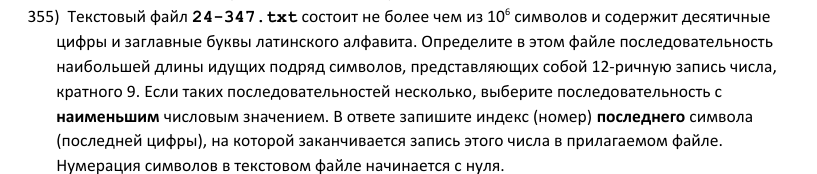

<details><summary>Текст условия</summary>Текстовый файл 24-347.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность наибольшей длины идущих подряд символов, представляющих собой 12-ричную запись числа, кратного 9. Если таких последовательностей несколько, выберите последовательность с наименьшим числовым значением. В ответе запишите индекс (номер) последнего символа (последней цифры), на которой заканчивается запись этого числа в прилагаемом файле. Нумерация символов в текстовом файле начинается с нуля.</details>

**Способ 1:** перебор подстрок каждого участка цифр

In [596]:
from re import finditer
s = open('24-347.txt').readline().strip()
best = None
for m in finditer('[0-9AB]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):          # от длинных к коротким
            if int(run[j-2:j] if j - i >= 2 else run[i:j], 12) % 9 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), -int(cand[0], 12)) > (len(best[0]), -int(best[0], 12)):
                    best = cand
                break
x, st, en = best
print(len(x), en)

107 770526


**Способ 2 (проверка):** остатки по схеме Горнера

In [597]:
s = open('24-347.txt').readline().strip()
D = '0123456789AB'
best = None
i = 0
n = len(s)
while i < n:
    if s[i] not in D:
        i += 1
        continue
    j = i
    while j < n and s[j] in D:
        j += 1
    run = s[i:j]
    for a in range(len(run)):                     # остатки «на лету»: v = v*12 + цифра
        if run[a] == '0':
            continue
        v = 0
        for e in range(a, len(run)):
            v = (v * 12 + D.index(run[e])) % 9
            if v == 0:
                cand = (run[a:e+1], i + a, i + e)
                if best is None or (len(cand[0]), -int(cand[0], 12)) > (len(best[0]), -int(best[0], 12)):
                    best = cand
    i = j
x, st, en = best
print(len(x), en)

107 770526


**Ответ: `770526`**

> Признак: 12² = 144 ≡ 0 (mod 9), поэтому кратность 9 зависит только от двух последних цифр.

### Задача 356

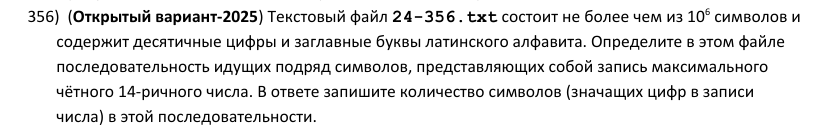

<details><summary>Текст условия</summary>(Открытый вариант-2025) Текстовый файл 24-356.txt состоит не более чем из 10⁶ символов и содержит десятичные цифры и заглавные буквы латинского алфавита. Определите в этом файле последовательность идущих подряд символов, представляющих собой запись максимального чётного 14-ричного числа. В ответе запишите количество символов (значащих цифр в записи числа) в этой последовательности.</details>

**Способ 1:** регулярное выражение + max

In [598]:
from re import finditer
s = open('24-356.txt').readline().strip()
a = [(m.group(), m.start(), m.end() - 1) for m in finditer('[1-9A-D][0-9A-D]*[02468AC]|[2468AC]', s)]
x, st, en = max(a, key=lambda t: (len(t[0]), t[0]))
print(len(x), st)

2598 1


**Способ 2 (проверка):** перебор подстрок участков с int()

In [599]:
from re import findall, finditer
s = open('24-356.txt').readline().strip()
best = None
for m in finditer('[0-9A-D]+', s):
    run, base = m.group(), m.start()
    for i in range(len(run)):
        if run[i] == '0':
            continue
        for j in range(len(run), i, -1):
            v = int(run[i:j], 14)
            if v % 2 == 0:
                cand = (run[i:j], base + i, base + j - 1)
                if best is None or (len(cand[0]), cand[0]) > (len(best[0]), best[0]):
                    best = cand
                break
x, st, en = best
print(len(x), st)

2598 1


**Ответ: `2598`**

## Задачи ЕГЭ-2025 / Демо-2026

Несколько условий одновременно. Удобно для каждой правой границы `R` найти **диапазон допустимых левых границ**
по каждому условию через списки позиций, и пересечь диапазоны:
* «ровно k символов c» — `L` между (k+1)-м и k-м с конца вхождениями `c`;
* «подстрока встречается не менее k раз» — `L` не правее начала k-го с конца вхождения;
* «начинается с чётной цифры и других чётных нет» — `L` — это позиция последней чётной цифры.

### Задача 357

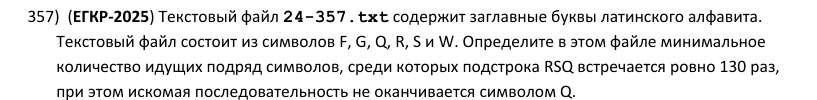

<details><summary>Текст условия</summary>(ЕГКР-2025) Текстовый файл 24-357.txt содержит заглавные буквы латинского алфавита. Текстовый файл состоит из символов F, G, Q, R, S и W. Определите в этом файле минимальное количество идущих подряд символов, среди которых подстрока RSQ встречается ровно 130 раз, при этом искомая последовательность не оканчивается символом Q.</details>

**Способ 1:** список позиций RSQ

In [600]:
s = open('24-357.txt').readline().strip()
n = len(s)
p = [i for i in range(n - 2) if s[i:i+3] == 'RSQ'] + [n]       # n — фиктивное «следующее» вхождение
k = 130
mn = 10**9
for j in range(len(p) - k):
    L = p[j]
    e = p[j+k-1] + 3                  # первый символ после 130-го вхождения
    while e < n and s[e] == 'Q':      # последовательность не должна кончаться на Q
        e += 1
    if e < n and e <= p[j+k] + 1:     # и не должна целиком захватить следующее RSQ
        mn = min(mn, e - L + 1)
print(mn)

497


**Способ 2 (проверка):** два указателя

In [601]:
s = open('24-357.txt').readline().strip()
L = k = 0
mn = 10**9
for R in range(len(s)):
    if R >= 2 and s[R-2:R+1] == 'RSQ' and R - 2 >= L:
        k += 1
    while k > 130 or (k == 130 and s[L:L+3] != 'RSQ'):
        if s[L:L+3] == 'RSQ' and L + 2 <= R:
            k -= 1
        L += 1
    if k == 130 and s[R] != 'Q':
        mn = min(mn, R - L + 1)
print(mn)

497


**Ответ: `497`**

### Задача 358

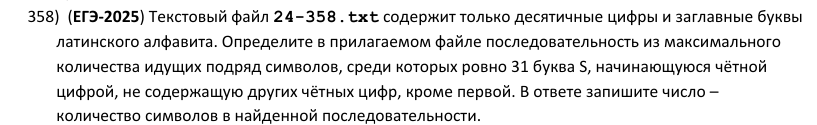

<details><summary>Текст условия</summary>(ЕГЭ-2025) Текстовый файл 24-358.txt содержит только десятичные цифры и заглавные буквы латинского алфавита. Определите в прилагаемом файле последовательность из максимального количества идущих подряд символов, среди которых ровно 31 буква S, начинающуюся чётной цифрой, не содержащую других чётных цифр, кроме первой. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** позиции чётных цифр и букв S

In [602]:
from bisect import bisect_left
s = open('24-358.txt').readline().strip()
n = len(s)
ev = [i for i in range(n) if s[i] in '02468'] + [n]
S_ = [i for i in range(n) if s[i] == 'S'] + [n]
mx = 0
for j in range(len(ev) - 1):
    L, nxt = ev[j], ev[j+1]                 # начинаем с чётной цифры, до следующей чётной
    a = bisect_left(S_, L)                  # первая буква S после L
    if a + 31 < len(S_) and S_[a + 30] < nxt:
        R = min(nxt, S_[a + 31]) - 1        # до 32-й S или до следующей чётной цифры
        mx = max(mx, R - L + 1)
print(mx)

326


**Способ 2 (проверка):** однопроходный алгоритм

In [603]:
s = open('24-358.txt').readline().strip()
even = '02468'
mx = 0
l = -1
cntS = 0
for r in range(len(s)):
    if s[r] in even:
        l, cntS = r, 0
    if l == -1:
        continue
    if s[r] == 'S':
        cntS += 1
    if cntS == 31:
        mx = max(mx, r - l + 1)
print(mx)

326


**Ответ: `326`**

### Задача 359

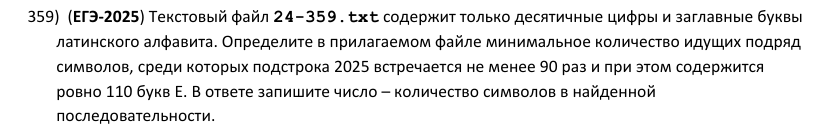

<details><summary>Текст условия</summary>(ЕГЭ-2025) Текстовый файл 24-359.txt содержит только десятичные цифры и заглавные буквы латинского алфавита. Определите в прилагаемом файле минимальное количество идущих подряд символов, среди которых подстрока 2025 встречается не менее 90 раз и при этом содержится ровно 110 букв E. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** диапазон левых границ для каждого R

In [604]:
s = open('24-359.txt').readline().strip()
n = len(s)
E = []          # позиции букв E
Q = []          # начала вхождений 2025, уже целиком левее R
mn = 10**9
for R in range(n):
    if s[R] == 'E':
        E.append(R)
    if R >= 3 and s[R-3:R+1] == '2025':
        Q.append(R - 3)
    if len(E) >= 110 and len(Q) >= 90:
        hi = min(E[-110], Q[-90])                   # L не правее 110-й с конца E и 90-го с конца 2025
        lo = E[-111] + 1 if len(E) > 110 else 0     # и правее 111-й с конца E
        if lo <= hi:
            mn = min(mn, R - hi + 1)
print(mn)

2849


**Способ 2 (проверка):** перебор блоков из 110 букв E

In [605]:
from bisect import bisect_left, bisect_right
s = open('24-359.txt').readline().strip()
n = len(s)
E = [i for i in range(n) if s[i] == 'E']
Q = [i for i in range(n - 3) if s[i:i+4] == '2025']
mn = 10**9
for j in range(len(E) - 109):                       # окно содержит E[j] .. E[j+109]
    lo = E[j-1] + 1 if j > 0 else 0
    Rmax = E[j+110] - 1 if j + 110 < len(E) else n - 1
    # левая граница: E[j] или начало одного из вхождений 2025 между lo и E[j]
    cands = [E[j]] + [q for q in Q[bisect_left(Q, lo):bisect_right(Q, E[j])]]
    for L in cands:
        a = bisect_left(Q, L)
        if a + 89 < len(Q):
            R = max(E[j+109], Q[a + 89] + 3)
            if R <= Rmax:
                mn = min(mn, R - L + 1)
print(mn)

2849


**Ответ: `2849`**

### Задача 360

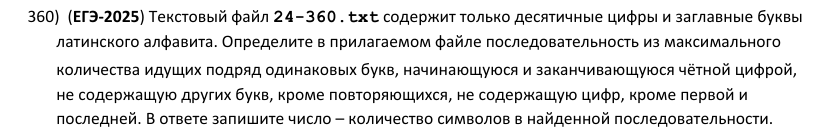

<details><summary>Текст условия</summary>(ЕГЭ-2025) Текстовый файл 24-360.txt содержит только десятичные цифры и заглавные буквы латинского алфавита. Определите в прилагаемом файле последовательность из максимального количества идущих подряд одинаковых букв, начинающуюся и заканчивающуюся чётной цифрой, не содержащую других букв, кроме повторяющихся, не содержащую цифр, кроме первой и последней. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** регулярное выражение с обратной ссылкой

In [606]:
from re import findall
s = open('24-360.txt').readline().strip()
a = findall(r'(?=([02468]([A-Z])\2*[02468]))', s)
print(max(len(x) for x, c in a))

1212


**Способ 2 (проверка):** groupby

In [607]:
from itertools import groupby
s = open('24-360.txt').readline().strip()
g = [(c, len(list(x))) for c, x in groupby(s)]
mx = 0
for i in range(1, len(g) - 1):
    c, L = g[i]
    if c.isalpha() and g[i-1][0] in '02468' and g[i+1][0] in '02468':
        mx = max(mx, L + 2)
print(mx)

1212


**Ответ: `1212`**

### Задача 361

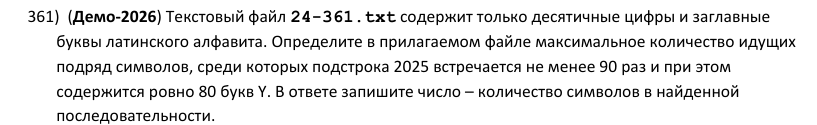

<details><summary>Текст условия</summary>(Демо-2026) Текстовый файл 24-361.txt содержит только десятичные цифры и заглавные буквы латинского алфавита. Определите в прилагаемом файле максимальное количество идущих подряд символов, среди которых подстрока 2025 встречается не менее 90 раз и при этом содержится ровно 80 букв Y. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** диапазон левых границ для каждого R

In [608]:
s = open('24-361.txt').readline().strip()
n = len(s)
Y = []
pref = [0] * (n + 1)          # pref[i] — число вхождений 2025, начинающихся левее i
for i in range(n):
    pref[i+1] = pref[i] + (s[i:i+4] == '2025')
mx = 0
for R in range(n):
    if s[R] == 'Y':
        Y.append(R)
    if len(Y) >= 80:
        L = Y[-81] + 1 if len(Y) > 80 else 0     # самое левое начало с ровно 80 буквами Y
        cnt = pref[max(L, R - 2)] - pref[L]      # вхождения целиком внутри s[L..R]
        if cnt >= 90:
            mx = max(mx, R - L + 1)
print(mx)

2886


**Способ 2 (проверка):** два указателя

In [609]:
s = open('24-361.txt').readline().strip()
mx = 0
l = 0
cnt2025 = cntY = 0
for r in range(len(s)):
    if s[r] == 'Y':
        cntY += 1
    if r >= 3 and s[r-3:r+1] == '2025' and r - 3 >= l:
        cnt2025 += 1
    while cntY > 80:
        if s[l] == 'Y':
            cntY -= 1
        if s[l:l+4] == '2025' and l + 3 <= r:
            cnt2025 -= 1
        l += 1
    if cntY == 80 and cnt2025 >= 90:
        mx = max(mx, r - l + 1)
print(mx)

2886


**Ответ: `2886`**

### Задача 362

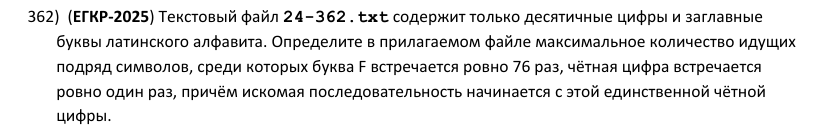

<details><summary>Текст условия</summary>(ЕГКР-2025) Текстовый файл 24-362.txt содержит только десятичные цифры и заглавные буквы латинского алфавита. Определите в прилагаемом файле максимальное количество идущих подряд символов, среди которых буква F встречается ровно 76 раз, чётная цифра встречается ровно один раз, причём искомая последовательность начинается с этой единственной чётной цифры.</details>

**Способ 1:** позиции чётных цифр и букв F

In [610]:
from bisect import bisect_left
s = open('24-362.txt').readline().strip()
n = len(s)
ev = [i for i in range(n) if s[i] in '02468'] + [n]
F = [i for i in range(n) if s[i] == 'F'] + [n]
mx = 0
for j in range(len(ev) - 1):
    L, nxt = ev[j], ev[j+1]
    a = bisect_left(F, L)
    if a + 76 < len(F) and F[a + 75] < nxt:
        R = min(nxt, F[a + 76]) - 1
        mx = max(mx, R - L + 1)
print(mx)

163


**Способ 2 (проверка):** однопроходный алгоритм

In [611]:
s = open('24-362.txt').readline().strip()
mx = 0
l = -1
cnt = 0
for r in range(len(s)):
    if s[r] in '02468':
        l, cnt = r, 0
    if l == -1:
        continue
    cnt += s[r] == 'F'
    if cnt == 76:
        mx = max(mx, r - l + 1)
print(mx)

163


**Ответ: `163`**

## Выражения из ограниченного числа слагаемых/множителей

Разбиваем строку на **цепочки чисел** (между соседними знаками без пропусков). Из цепочки берём окно
не более чем из k чисел подряд: длина окна = сумма длин чисел + (k − 1) знаков. Брать числа целиком выгоднее,
чем обрезанные (цифры 1–9, обрезанное число всегда меньше и короче), а добавлять числа никогда не вредно
(все числа ≥ 1). Поэтому достаточно перебрать окна ровно из k чисел — **скользящее окно / префиксные суммы**.

### Задача 363

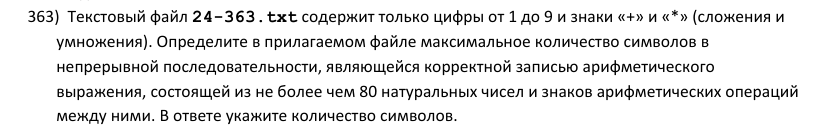

<details><summary>Текст условия</summary>Текстовый файл 24-363.txt содержит только цифры от 1 до 9 и знаки «+» и «*» (сложения и умножения). Определите в прилагаемом файле максимальное количество символов в непрерывной последовательности, являющейся корректной записью арифметического выражения, состоящей из не более чем 80 натуральных чисел и знаков арифметических операций между ними. В ответе укажите количество символов.</details>

**Способ 1:** цепочки чисел + скользящее окно

In [612]:
from re import finditer
s = open('24-363.txt').readline().strip()
k = 80
mx = 0
for m in finditer(r'\d+(?:[+*]\d+)*', s):
    nums = [len(x) for x in m.group().replace('*', '+').split('+')]
    if len(nums) <= k:
        mx = max(mx, len(m.group()))
        continue
    w = sum(nums[:k])                       # сумма длин k чисел в окне
    mx = max(mx, w + k - 1)
    for i in range(k, len(nums)):
        w += nums[i] - nums[i-k]
        mx = max(mx, w + k - 1)
print(mx)

346


**Способ 2 (проверка):** два указателя

In [613]:
s = open('24-363.txt').readline().strip()
# два указателя по символам: в окне не более 80 чисел и нет двух знаков подряд
L = cnt = mx = 0
for R in range(len(s)):
    c = s[R]
    if c in '+*':
        if R == 0 or s[R-1] in '+*':
            L, cnt = R + 1, 0
        continue
    if R == L or s[R-1] in '+*':
        cnt += 1                            # началось новое число
    while cnt > 80:                         # убираем первое число и знак после него
        while s[L] not in '+*':
            L += 1
        L += 1
        cnt -= 1
    mx = max(mx, R - L + 1)
print(mx)

346


**Ответ: `346`**

### Задача 364

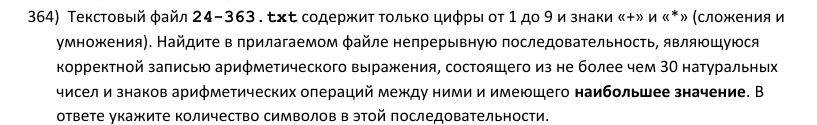

<details><summary>Текст условия</summary>Текстовый файл 24-363.txt содержит только цифры от 1 до 9 и знаки «+» и «*» (сложения и умножения). Найдите в прилагаемом файле непрерывную последовательность, являющуюся корректной записью арифметического выражения, состоящего из не более чем 30 натуральных чисел и знаков арифметических операций между ними и имеющего наибольшее значение. В ответе укажите количество символов в этой последовательности.</details>

**Способ 1:** цепочки + перебор окон из 30 чисел

In [614]:
from re import finditer
s = open('24-363.txt').readline().strip()
k = 30
best = (0, 0)                               # (значение, длина)
for m in finditer(r'\d+(?:[+*]\d+)*', s):
    run = m.group()
    nums = run.replace('*', '+').split('+')
    ops = [c for c in run if c in '+*']
    for i in range(max(1, len(nums) - k + 1)):
        j = min(len(nums), i + k)
        total, prod = 0, int(nums[i])       # значение: сумма произведений
        for t in range(i + 1, j):
            if ops[t-1] == '*':
                prod *= int(nums[t])
            else:
                total += prod
                prod = int(nums[t])
        total += prod
        length = sum(len(x) for x in nums[i:j]) + (j - i - 1)
        best = max(best, (total, length))
print(best[1])

124


**Способ 2 (проверка):** eval подстрок (только цифры и знаки)

In [615]:
from re import finditer
s = open('24-363.txt').readline().strip()
best = (0, 0)
for m in finditer(r'\d+(?:[+*]\d+)*', s):
    run = m.group()
    starts = [0] + [i + 1 for i, c in enumerate(run) if c in '+*']   # начала чисел
    ends = [i for i, c in enumerate(run) if c in '+*'] + [len(run)]  # концы чисел
    k = min(30, len(starts))
    for i in range(len(starts) - k + 1):
        x = run[starts[i]:ends[i + k - 1]]
        best = max(best, (eval(x), len(x)))    # x состоит только из цифр, + и *
print(best[1])

124


**Ответ: `124`**

### Задача 365

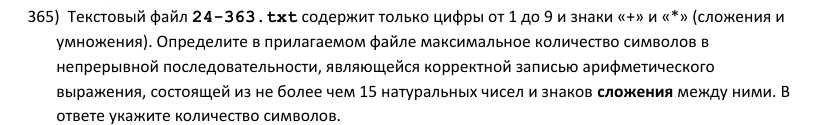

<details><summary>Текст условия</summary>Текстовый файл 24-363.txt содержит только цифры от 1 до 9 и знаки «+» и «*» (сложения и умножения). Определите в прилагаемом файле максимальное количество символов в непрерывной последовательности, являющейся корректной записью арифметического выражения, состоящей из не более чем 15 натуральных чисел и знаков сложения между ними. В ответе укажите количество символов.</details>

**Способ 1:** цепочки через + и скользящее окно

In [616]:
from re import finditer
s = open('24-363.txt').readline().strip()
k = 15
mx = 0
for m in finditer(r'\d+(?:\+\d+)*', s):
    nums = [len(x) for x in m.group().split('+')]
    w = sum(nums[:k])
    mx = max(mx, w + min(k, len(nums)) - 1)
    for i in range(k, len(nums)):
        w += nums[i] - nums[i-k]
        mx = max(mx, w + k - 1)
print(mx)

65


**Способ 2 (проверка):** split по * и по +

In [617]:
from re import split
s = open('24-363.txt').readline().strip()
mx = 0
for chunk in split(r'\*', s):              # умножение разрывает цепочку сложений
    nums = chunk.split('+')
    cur = []                                # текущая цепочка подряд идущих непустых чисел
    for x in nums + ['']:
        if x:
            cur.append(len(x))
        else:
            for i in range(len(cur)):
                part = cur[i:i+15]
                mx = max(mx, sum(part) + len(part) - 1)
            cur = []
print(mx)

65


**Ответ: `65`**

### Задача 366

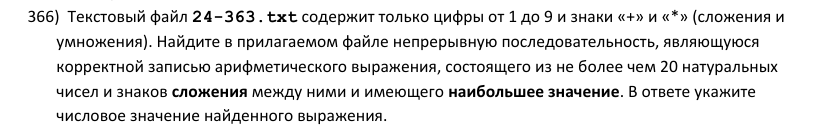

<details><summary>Текст условия</summary>Текстовый файл 24-363.txt содержит только цифры от 1 до 9 и знаки «+» и «*» (сложения и умножения). Найдите в прилагаемом файле непрерывную последовательность, являющуюся корректной записью арифметического выражения, состоящего из не более чем 20 натуральных чисел и знаков сложения между ними и имеющего наибольшее значение. В ответе укажите числовое значение найденного выражения.</details>

**Способ 1:** цепочки через + и скользящая сумма

In [618]:
from re import split
s = open('24-363.txt').readline().strip()
best = 0
for chunk in split(r'\*', s):
    cur = []
    for x in chunk.split('+') + ['']:
        if x:
            cur.append(int(x))
        else:
            if cur:
                w = sum(cur[:20])
                best = max(best, w)
                for i in range(20, len(cur)):
                    w += cur[i] - cur[i-20]
                    best = max(best, w)
            cur = []
print(best)

14255


**Способ 2 (проверка):** регулярное выражение + перебор окон

In [619]:
from re import finditer
s = open('24-363.txt').readline().strip()
best = 0
for m in finditer(r'\d+(?:\+\d+)*', s):
    v = list(map(int, m.group().split('+')))
    for i in range(max(1, len(v) - 19)):
        best = max(best, sum(v[i:i+20]))
print(best)

14255


**Ответ: `14255`**

## Слова между точками: минимальное окно

Слово — буквы, ограниченные точками с двух сторон, поэтому вместе с точками оно занимает отрезок
`[a, b]` (`a` — точка перед словом, `b` — точка после). Находим все слова через `re.finditer` с проверками
`(?<=\.)` и `(?=\.)`, оставляем подходящие, и минимальная подстрока с k словами подряд — от точки перед
j-м словом до точки после (j+k−1)-го: `b[j+k-1] - a[j] + 1`.

### Задача 367

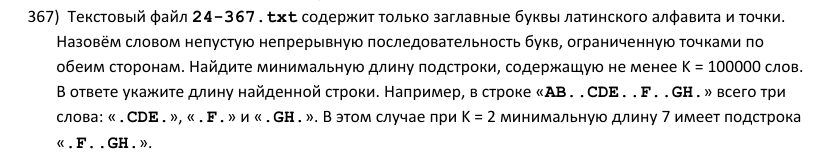

<details><summary>Текст условия</summary>Текстовый файл 24-367.txt содержит только заглавные буквы латинского алфавита и точки. Назовём словом непустую непрерывную последовательность букв, ограниченную точками по обеим сторонам. Найдите минимальную длину подстроки, содержащую не менее K = 100000 слов. В ответе укажите длину найденной строки. Например, в строке «AB..CDE..F..GH.» всего три слова: «.CDE.», «.F.» и «.GH.». В этом случае при K = 2 минимальную длину 7 имеет подстрока «.F..GH.».</details>

**Способ 1:** список слов + окно (все слова)

In [620]:
from re import finditer
s = open('24-367.txt').readline().strip()
K = 100000
a = []          # (точка перед словом, точка после слова)
for m in finditer(r'(?<=\.)[A-Z]+(?=\.)', s):
    w = m.group()
    if True:
        a.append((m.start() - 1, m.end()))
print(min(a[j+K-1][1] - a[j][0] + 1 for j in range(len(a) - K + 1)))

499310


**Способ 2 (проверка):** список точек

In [621]:
s = open('24-367.txt').readline().strip()
K = 100000
dots = [i for i in range(len(s)) if s[i] == '.']
a = []
for j in range(len(dots) - 1):
    if dots[j+1] - dots[j] > 1:          # между соседними точками есть буквы — это слово
        w = s[dots[j]+1:dots[j+1]]
        if True:
            a.append((dots[j], dots[j+1]))
print(min(a[j+K-1][1] - a[j][0] + 1 for j in range(len(a) - K + 1)))

499310


**Ответ: `499310`**

### Задача 368

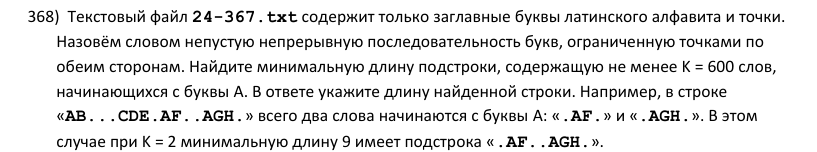

<details><summary>Текст условия</summary>Текстовый файл 24-367.txt содержит только заглавные буквы латинского алфавита и точки. Назовём словом непустую непрерывную последовательность букв, ограниченную точками по обеим сторонам. Найдите минимальную длину подстроки, содержащую не менее K = 600 слов, начинающихся с буквы A. В ответе укажите длину найденной строки. Например, в строке «AB...CDE.AF..AGH.» всего два слова начинаются с буквы A: «.AF.» и «.AGH.». В этом случае при K = 2 минимальную длину 9 имеет подстрока «.AF..AGH.».</details>

**Способ 1:** список слов + окно (слова на A)

In [622]:
from re import finditer
s = open('24-367.txt').readline().strip()
K = 600
a = []          # (точка перед словом, точка после слова)
for m in finditer(r'(?<=\.)[A-Z]+(?=\.)', s):
    w = m.group()
    if w[0] == 'A':
        a.append((m.start() - 1, m.end()))
print(min(a[j+K-1][1] - a[j][0] + 1 for j in range(len(a) - K + 1)))

70849


**Способ 2 (проверка):** список точек

In [623]:
s = open('24-367.txt').readline().strip()
K = 600
dots = [i for i in range(len(s)) if s[i] == '.']
a = []
for j in range(len(dots) - 1):
    if dots[j+1] - dots[j] > 1:          # между соседними точками есть буквы — это слово
        w = s[dots[j]+1:dots[j+1]]
        if w[0] == 'A':
            a.append((dots[j], dots[j+1]))
print(min(a[j+K-1][1] - a[j][0] + 1 for j in range(len(a) - K + 1)))

70849


**Ответ: `70849`**

### Задача 369

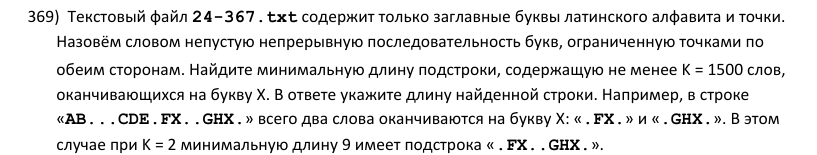

<details><summary>Текст условия</summary>Текстовый файл 24-367.txt содержит только заглавные буквы латинского алфавита и точки. Назовём словом непустую непрерывную последовательность букв, ограниченную точками по обеим сторонам. Найдите минимальную длину подстроки, содержащую не менее K = 1500 слов, оканчивающихся на букву X. В ответе укажите длину найденной строки. Например, в строке «AB...CDE.FX..GHX.» всего два слова оканчиваются на букву X: «.FX.» и «.GHX.». В этом случае при K = 2 минимальную длину 9 имеет подстрока «.FX..GHX.».</details>

**Способ 1:** список слов + окно (слова на X)

In [624]:
from re import finditer
s = open('24-367.txt').readline().strip()
K = 1500
a = []          # (точка перед словом, точка после слова)
for m in finditer(r'(?<=\.)[A-Z]+(?=\.)', s):
    w = m.group()
    if w[-1] == 'X':
        a.append((m.start() - 1, m.end()))
print(min(a[j+K-1][1] - a[j][0] + 1 for j in range(len(a) - K + 1)))

188521


**Способ 2 (проверка):** список точек

In [625]:
s = open('24-367.txt').readline().strip()
K = 1500
dots = [i for i in range(len(s)) if s[i] == '.']
a = []
for j in range(len(dots) - 1):
    if dots[j+1] - dots[j] > 1:          # между соседними точками есть буквы — это слово
        w = s[dots[j]+1:dots[j+1]]
        if w[-1] == 'X':
            a.append((dots[j], dots[j+1]))
print(min(a[j+K-1][1] - a[j][0] + 1 for j in range(len(a) - K + 1)))

188521


**Ответ: `188521`**

### Задача 370

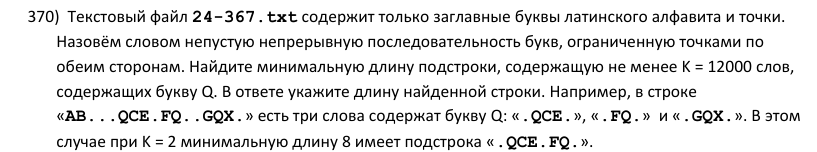

<details><summary>Текст условия</summary>Текстовый файл 24-367.txt содержит только заглавные буквы латинского алфавита и точки. Назовём словом непустую непрерывную последовательность букв, ограниченную точками по обеим сторонам. Найдите минимальную длину подстроки, содержащую не менее K = 12000 слов, содержащих букву Q. В ответе укажите длину найденной строки. Например, в строке «AB...QCE.FQ..GQX.» есть три слова содержат букву Q: «.QCE.», «.FQ.»  и «.GQX.». В этом случае при K = 2 минимальную длину 8 имеет подстрока «.QCE.FQ.».</details>

**Способ 1:** список слов + окно (слова с Q)

In [626]:
from re import finditer
s = open('24-367.txt').readline().strip()
K = 12000
a = []          # (точка перед словом, точка после слова)
for m in finditer(r'(?<=\.)[A-Z]+(?=\.)', s):
    w = m.group()
    if 'Q' in w:
        a.append((m.start() - 1, m.end()))
print(min(a[j+K-1][1] - a[j][0] + 1 for j in range(len(a) - K + 1)))

645835


**Способ 2 (проверка):** список точек

In [627]:
s = open('24-367.txt').readline().strip()
K = 12000
dots = [i for i in range(len(s)) if s[i] == '.']
a = []
for j in range(len(dots) - 1):
    if dots[j+1] - dots[j] > 1:          # между соседними точками есть буквы — это слово
        w = s[dots[j]+1:dots[j+1]]
        if 'Q' in w:
            a.append((dots[j], dots[j+1]))
print(min(a[j+K-1][1] - a[j][0] + 1 for j in range(len(a) - K + 1)))

645835


**Ответ: `645835`**

## Предложения (точки, пробелы, слова)

Делим текст по точкам: `s.split('.')` — куски перед каждой точкой (последний кусок без точки отбрасываем).
Предложение — это **хвост** такого куска плюс точка. Дальше работаем с каждым куском отдельно:
считаем буквы, режем на слова `chunk.split()` и т. п. Если в условии сказано «не начинается с пробела»
и «перед точкой буква» — проверяем это явно.

### Задача 371

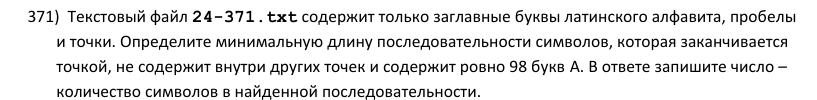

<details><summary>Текст условия</summary>Текстовый файл 24-371.txt содержит только заглавные буквы латинского алфавита, пробелы и точки. Определите минимальную длину последовательности символов, которая заканчивается точкой, не содержит внутри других точек и содержит ровно 98 букв A. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** куски между точками + позиции буквы A

In [628]:
s = open('24-371.txt').readline().strip()
mn = 10**9
for chunk in s.split('.')[:-1]:
    p = [i for i in range(len(chunk)) if chunk[i] == 'A']
    if len(p) >= 98:
        mn = min(mn, len(chunk) - p[-98] + 1)   # от 98-й с конца буквы A до точки
print(mn)

575


**Способ 2 (проверка):** проход влево от каждой точки

In [629]:
s = open('24-371.txt').readline().strip()
mn = 10**9
for d in range(len(s)):
    if s[d] == '.':
        k = 0
        i = d - 1
        while i >= 0 and s[i] != '.':           # идём от точки влево
            if s[i] == 'A':
                k += 1
                if k == 98:
                    mn = min(mn, d - i + 1)
                    break
            i -= 1
print(mn)

575


**Ответ: `575`**

### Задача 372

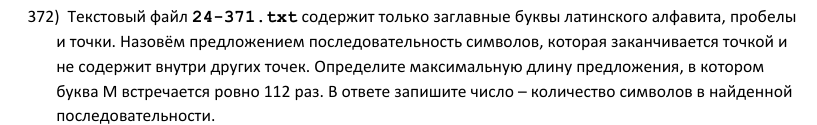

<details><summary>Текст условия</summary>Текстовый файл 24-371.txt содержит только заглавные буквы латинского алфавита, пробелы и точки. Назовём предложением последовательность символов, которая заканчивается точкой и не содержит внутри других точек. Определите максимальную длину предложения, в котором буква M встречается ровно 112 раз. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** куски между точками + позиции буквы M

In [630]:
s = open('24-371.txt').readline().strip()
mx = 0
for chunk in s.split('.')[:-1]:
    p = [i for i in range(len(chunk)) if chunk[i] == 'M']
    if len(p) >= 112:
        start = p[-113] + 1 if len(p) > 112 else 0   # сразу после 113-й с конца M (или с начала куска)
        mx = max(mx, len(chunk) - start + 1)
print(mx)

4594


**Способ 2 (проверка):** перевёрнутые куски

In [631]:
from re import findall
s = open('24-371.txt').readline().strip()
mx = 0
for chunk in findall(r'[^.]*\.', s):
    t = chunk[::-1]                     # переворачиваем: идём от точки
    k = 0
    for i, c in enumerate(t):
        if c == 'M':
            k += 1
            if k == 113:
                mx = max(mx, i)          # всё до 113-й M (не включая)
                break
    else:
        if k == 112:
            mx = max(mx, len(t))
print(mx)

4594


**Ответ: `4594`**

### Задача 373

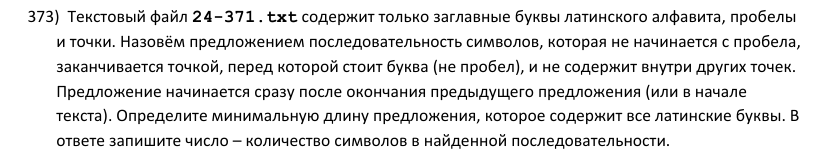

<details><summary>Текст условия</summary>Текстовый файл 24-371.txt содержит только заглавные буквы латинского алфавита, пробелы и точки. Назовём предложением последовательность символов, которая не начинается с пробела, заканчивается точкой, перед которой стоит буква (не пробел), и не содержит внутри других точек. Предложение начинается сразу после окончания предыдущего предложения (или в начале текста). Определите минимальную длину предложения, которое содержит все латинские буквы. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** куски между точками + set

In [632]:
from string import ascii_uppercase
s = open('24-371.txt').readline().strip()
mn = 10**9
for chunk in s.split('.')[:-1]:
    t = chunk.lstrip(' ')                 # предложение не начинается с пробела
    if t and t[-1] != ' ' and set(ascii_uppercase) <= set(t):
        mn = min(mn, len(t) + 1)
print(mn)

83


**Способ 2 (проверка):** регулярное выражение

In [633]:
from re import findall
s = open('24-371.txt').readline().strip()
a = findall(r'(?:^|(?<=\.)) *([^. ][^.]*[A-Z]\.)', s)
print(min(len(x) for x in a if len(set(x) - set(' .')) == 26))

83


**Ответ: `83`**

> Предложение начинается сразу после предыдущего (после пробелов, которыми оно не может начинаться).

### Задача 374

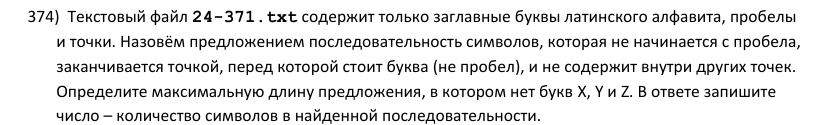

<details><summary>Текст условия</summary>Текстовый файл 24-371.txt содержит только заглавные буквы латинского алфавита, пробелы и точки. Назовём предложением последовательность символов, которая не начинается с пробела, заканчивается точкой, перед которой стоит буква (не пробел), и не содержит внутри других точек. Определите максимальную длину предложения, в котором нет букв X, Y и Z. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** куски между точками

In [634]:
from re import sub
s = open('24-371.txt').readline().strip()
mx = 0
for chunk in s.split('.')[:-1]:
    if not chunk or chunk[-1] == ' ':
        continue                           # перед точкой должна стоять буква
    t = sub('.*[XYZ]', '', chunk)          # хвост после последней буквы X, Y или Z
    t = t.lstrip(' ')                      # не начинается с пробела
    if t:
        mx = max(mx, len(t) + 1)
print(mx)

84


**Способ 2 (проверка):** проход влево от каждой точки

In [635]:
s = open('24-371.txt').readline().strip()
mx = 0
for d in range(len(s)):
    if s[d] == '.' and d > 0 and s[d-1] not in ' .':
        i = d - 1
        start = d - 1
        while i >= 0 and s[i] not in '.XYZ':   # идём влево до точки или запрещённой буквы
            if s[i] != ' ':
                start = i                     # самое левое начало — не пробел
            i -= 1
        mx = max(mx, d - start + 1)
print(mx)

84


**Ответ: `84`**

### Задача 375

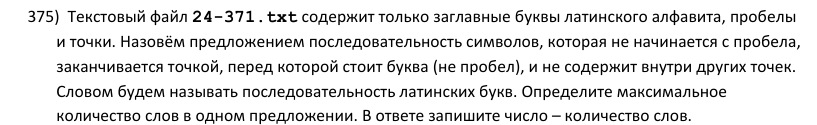

<details><summary>Текст условия</summary>Текстовый файл 24-371.txt содержит только заглавные буквы латинского алфавита, пробелы и точки. Назовём предложением последовательность символов, которая не начинается с пробела, заканчивается точкой, перед которой стоит буква (не пробел), и не содержит внутри других точек. Словом будем называть последовательность латинских букв. Определите максимальное количество слов в одном предложении. В ответе запишите число – количество слов.</details>

**Способ 1:** split

In [636]:
s = open('24-371.txt').readline().strip()
mx = 0
for chunk in s.split('.')[:-1]:
    if chunk and chunk[-1] != ' ':
        mx = max(mx, len(chunk.split()))
print(mx)

926


**Способ 2 (проверка):** регулярное выражение

In [637]:
from re import findall
s = open('24-371.txt').readline().strip()
print(max(len(findall('[A-Z]+', x)) for x in findall(r'[^.]*[A-Z]\.', s)))

926


**Ответ: `926`**

### Задача 376

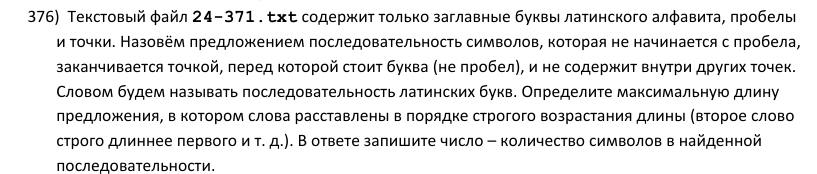

<details><summary>Текст условия</summary>Текстовый файл 24-371.txt содержит только заглавные буквы латинского алфавита, пробелы и точки. Назовём предложением последовательность символов, которая не начинается с пробела, заканчивается точкой, перед которой стоит буква (не пробел), и не содержит внутри других точек. Словом будем называть последовательность латинских букв. Определите максимальную длину предложения, в котором слова расставлены в порядке строгого возрастания длины (второе слово строго длиннее первого и т. д.). В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** слова с конца предложения

In [638]:
from re import finditer
s = open('24-371.txt').readline().strip()
mx = 0
for chunk in s.split('.')[:-1]:
    if not chunk or chunk[-1] == ' ':
        continue
    w = [(m.start(), m.end()) for m in finditer('[A-Z]+', chunk)]     # слова: начало и конец
    i = len(w) - 1
    start = w[i][0]
    while i > 0:
        prev_len, cur_len = w[i-1][1] - w[i-1][0], w[i][1] - w[i][0]
        if prev_len < cur_len:
            i -= 1
            start = w[i][0]
        else:
            if cur_len > 1:                    # можно взять хвост предыдущего слова длиной cur_len - 1
                start = w[i-1][1] - (cur_len - 1)
            break
    mx = max(mx, len(chunk) - start + 1)
print(mx)

57


**Способ 2 (проверка):** сдвиг начала справа налево

In [639]:
s = open('24-371.txt').readline().strip()
mx = 0
for chunk in s.split('.')[:-1]:
    if not chunk or chunk[-1] == ' ':
        continue
    # двигаем начало справа налево, пока предложение остаётся правильным
    best = -1
    for st in range(len(chunk) - 1, -1, -1):
        if chunk[st] == ' ':
            continue
        L = [len(x) for x in chunk[st:].split()]
        if all(L[i] < L[i+1] for i in range(len(L) - 1)):
            best = st
        else:
            break                       # дальше влево станет только хуже
    if best != -1:
        mx = max(mx, len(chunk) - best + 1)
print(mx)

57


**Ответ: `57`**

> Предложение может начинаться с середины слова: тогда первое «слово» — хвост слова.

### Задача 377

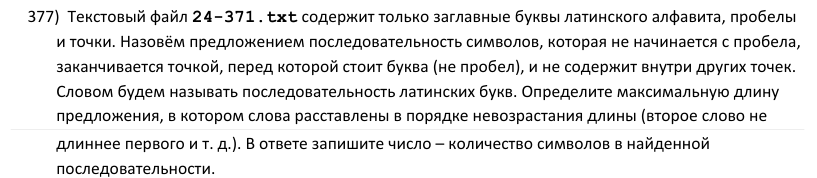

<details><summary>Текст условия</summary>Текстовый файл 24-371.txt содержит только заглавные буквы латинского алфавита, пробелы и точки. Назовём предложением последовательность символов, которая не начинается с пробела, заканчивается точкой, перед которой стоит буква (не пробел), и не содержит внутри других точек. Словом будем называть последовательность латинских букв. Определите максимальную длину предложения, в котором слова расставлены в порядке невозрастания длины (второе слово не длиннее первого и т. д.). В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** слова с конца предложения

In [640]:
from re import finditer
s = open('24-371.txt').readline().strip()
mx = 0
for chunk in s.split('.')[:-1]:
    if not chunk or chunk[-1] == ' ':
        continue
    w = [(m.start(), m.end()) for m in finditer('[A-Z]+', chunk)]     # слова: начало и конец
    i = len(w) - 1
    start = w[i][0]
    while i > 0:
        prev_len, cur_len = w[i-1][1] - w[i-1][0], w[i][1] - w[i][0]
        if prev_len >= cur_len:
            i -= 1
            start = w[i][0]
        else:
            pass
            break
    mx = max(mx, len(chunk) - start + 1)
print(mx)

59


**Способ 2 (проверка):** сдвиг начала справа налево

In [641]:
s = open('24-371.txt').readline().strip()
mx = 0
for chunk in s.split('.')[:-1]:
    if not chunk or chunk[-1] == ' ':
        continue
    # двигаем начало по началам слов справа налево, пока предложение остаётся правильным
    # (обрезать первое слово бессмысленно: короче оно станет только хуже)
    best = -1
    for st in range(len(chunk) - 1, -1, -1):
        if chunk[st] == ' ' or (st > 0 and chunk[st-1] != ' '):
            continue
        L = [len(x) for x in chunk[st:].split()]
        if all(L[i] >= L[i+1] for i in range(len(L) - 1)):
            best = st
        else:
            break                       # дальше влево станет только хуже
    if best != -1:
        mx = max(mx, len(chunk) - best + 1)
print(mx)

59


**Ответ: `59`**

## «Есть все символы набора»: split и два указателя

Запрещённые символы режут строку на участки (`re.split`). В участке:
* **максимум** с условием «есть все символы» — весь участок, если в нём есть все символы;
* **минимум** — двумя указателями: сдвигаем `L`, пока в окне остаются все нужные символы.
Условие «ровно три буквы из набора» добавляет диапазон для `L` по позициям этих букв.

### Задача 378

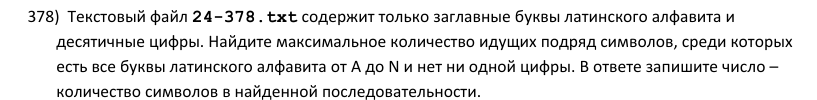

<details><summary>Текст условия</summary>Текстовый файл 24-378.txt содержит только заглавные буквы латинского алфавита и десятичные цифры. Найдите максимальное количество идущих подряд символов, среди которых есть все буквы латинского алфавита от A до N и нет ни одной цифры. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** split по цифрам

In [642]:
from re import split
s = open('24-378.txt').readline().strip()
need = set('ABCDEFGHIJKLMN')
print(max(len(t) for t in split(r'\d', s) if need <= set(t)))

689


**Способ 2 (проверка):** findall + проверка букв

In [643]:
from re import findall
s = open('24-378.txt').readline().strip()
best = 0
for t in findall('[A-Z]+', s):
    if all(c in t for c in 'ABCDEFGHIJKLMN'):
        best = max(best, len(t))
print(best)

689


**Ответ: `689`**

### Задача 379

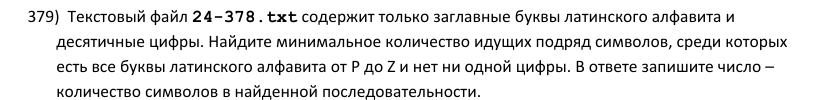

<details><summary>Текст условия</summary>Текстовый файл 24-378.txt содержит только заглавные буквы латинского алфавита и десятичные цифры. Найдите минимальное количество идущих подряд символов, среди которых есть все буквы латинского алфавита от P до Z и нет ни одной цифры. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** split + два указателя

In [644]:
from re import split
s = open('24-378.txt').readline().strip()
need = 'PQRSTUVWXYZ'
mn = 10**9
for t in split('\\d', s):
    cnt = {}
    have = L = 0
    for R, c in enumerate(t):
        if c in need:
            cnt[c] = cnt.get(c, 0) + 1
            have += cnt[c] == 1
        while have == len(need):
            mn = min(mn, R - L + 1)
            if t[L] in need:
                cnt[t[L]] -= 1
                have -= cnt[t[L]] == 0
            L += 1
print(mn)

23


**Способ 2 (проверка):** последние вхождения

In [645]:
from re import finditer
s = open('24-378.txt').readline().strip()
need = 'PQRSTUVWXYZ'
mn = 10**9
for m in finditer('[A-Z]+', s):
    t = m.group()
    last = {c: -1 for c in need}
    for R, c in enumerate(t):
        if c in last:
            last[c] = R
            L = min(last.values())          # окно от самого «старого» нужного символа
            if L >= 0:
                mn = min(mn, R - L + 1)
print(mn)

23


**Ответ: `23`**

### Задача 380

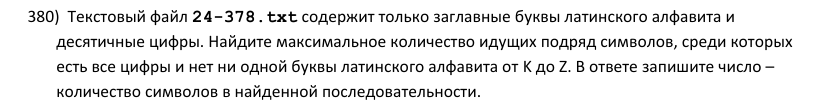

<details><summary>Текст условия</summary>Текстовый файл 24-378.txt содержит только заглавные буквы латинского алфавита и десятичные цифры. Найдите максимальное количество идущих подряд символов, среди которых есть все цифры и нет ни одной буквы латинского алфавита от K до Z. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** split по буквам K–Z

In [646]:
from re import split
s = open('24-378.txt').readline().strip()
print(max(len(t) for t in split('[K-Z]', s) if set('0123456789') <= set(t)))

103


**Способ 2 (проверка):** findall + проверка цифр

In [647]:
from re import findall
s = open('24-378.txt').readline().strip()
print(max(len(t) for t in findall('[0-9A-J]+', s) if all(d in t for d in '0123456789')))

103


**Ответ: `103`**

### Задача 381

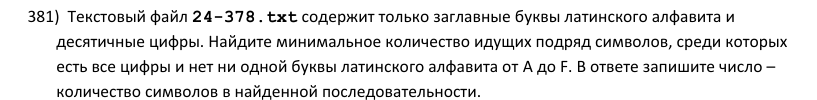

<details><summary>Текст условия</summary>Текстовый файл 24-378.txt содержит только заглавные буквы латинского алфавита и десятичные цифры. Найдите минимальное количество идущих подряд символов, среди которых есть все цифры и нет ни одной буквы латинского алфавита от A до F. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** split + два указателя

In [648]:
from re import split
s = open('24-378.txt').readline().strip()
need = '0123456789'
mn = 10**9
for t in split('[A-F]', s):
    cnt = {}
    have = L = 0
    for R, c in enumerate(t):
        if c in need:
            cnt[c] = cnt.get(c, 0) + 1
            have += cnt[c] == 1
        while have == len(need):
            mn = min(mn, R - L + 1)
            if t[L] in need:
                cnt[t[L]] -= 1
                have -= cnt[t[L]] == 0
            L += 1
print(mn)

13


**Способ 2 (проверка):** последние вхождения

In [649]:
from re import finditer
s = open('24-378.txt').readline().strip()
need = '0123456789'
mn = 10**9
for m in finditer('[0-9G-Z]+', s):
    t = m.group()
    last = {c: -1 for c in need}
    for R, c in enumerate(t):
        if c in last:
            last[c] = R
            L = min(last.values())          # окно от самого «старого» нужного символа
            if L >= 0:
                mn = min(mn, R - L + 1)
print(mn)

13


**Ответ: `13`**

### Задача 382

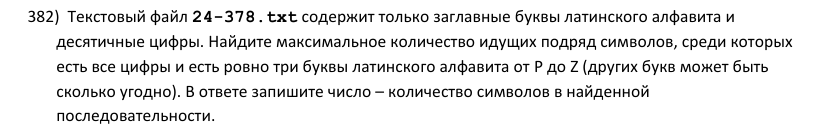

<details><summary>Текст условия</summary>Текстовый файл 24-378.txt содержит только заглавные буквы латинского алфавита и десятичные цифры. Найдите максимальное количество идущих подряд символов, среди которых есть все цифры и есть ровно три буквы латинского алфавита от P до Z (других букв может быть сколько угодно). В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** диапазон левых границ

In [650]:
s = open('24-378.txt').readline().strip()
P = []                         # позиции букв P..Z
last = {d: -1 for d in '0123456789'}
mx = 0
for R, c in enumerate(s):
    if c in last:
        last[c] = R
    if 'P' <= c <= 'Z':
        P.append(R)
    if len(P) >= 3:
        L = P[-4] + 1 if len(P) > 3 else 0      # самое левое начало с ровно тремя буквами P..Z
        if min(last.values()) >= L:             # все цифры есть в окне
            mx = max(mx, R - L + 1)
print(mx)

137


**Способ 2 (проверка):** два указателя

In [651]:
s = open('24-378.txt').readline().strip()
L = k = mx = 0
cnt = {}
for R, c in enumerate(s):
    if 'P' <= c <= 'Z':
        k += 1
    if c.isdigit():
        cnt[c] = cnt.get(c, 0) + 1
    while k > 3:
        if 'P' <= s[L] <= 'Z':
            k -= 1
        if s[L].isdigit():
            cnt[s[L]] -= 1
            if cnt[s[L]] == 0:
                del cnt[s[L]]
        L += 1
    if k == 3 and len(cnt) == 10:
        mx = max(mx, R - L + 1)
print(mx)

137


**Ответ: `137`**

### Задача 383

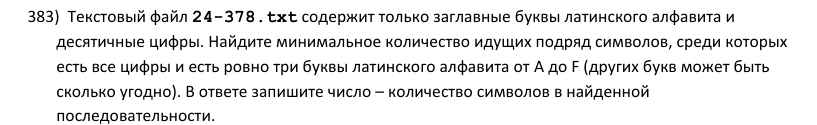

<details><summary>Текст условия</summary>Текстовый файл 24-378.txt содержит только заглавные буквы латинского алфавита и десятичные цифры. Найдите минимальное количество идущих подряд символов, среди которых есть все цифры и есть ровно три буквы латинского алфавита от A до F (других букв может быть сколько угодно). В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** диапазон левых границ

In [652]:
s = open('24-378.txt').readline().strip()
A = []                         # позиции букв A..F
last = {d: -1 for d in '0123456789'}
mn = 10**9
for R, c in enumerate(s):
    if c in last:
        last[c] = R
    if 'A' <= c <= 'F':
        A.append(R)
    if len(A) >= 3:
        hi = min(min(last.values()), A[-3])     # L не правее самой «старой» цифры и 3-й с конца буквы
        lo = A[-4] + 1 if len(A) > 3 else 0
        if hi >= lo and hi >= 0:
            mn = min(mn, R - hi + 1)
print(mn)

17


**Способ 2 (проверка):** два указателя

In [653]:
s = open('24-378.txt').readline().strip()
L = k = 0
cnt = {}
mn = 10**9
for R, c in enumerate(s):
    if 'A' <= c <= 'F':
        k += 1
    if c.isdigit():
        cnt[c] = cnt.get(c, 0) + 1
    # сдвигаем L, пока букв больше 3 или левый символ лишний (не нужен ни для цифр, ни для букв)
    while k > 3 or (L < R and not ('A' <= s[L] <= 'F') and (not s[L].isdigit() or cnt[s[L]] > 1)):
        if 'A' <= s[L] <= 'F':
            k -= 1
        if s[L].isdigit():
            cnt[s[L]] -= 1
            if cnt[s[L]] == 0:
                del cnt[s[L]]
        L += 1
    if k == 3 and len(cnt) == 10:
        mn = min(mn, R - L + 1)
print(mn)

17


**Ответ: `17`**

## Задачи 2026 года

Всё уже знакомое: **список позиций** (для «не менее k» и «ровно k» пар/троек), **регулярные выражения**
(числа, римские цифры, выражения), **двойной перебор с ограничением длины** для коротких записей.

### Задача 384

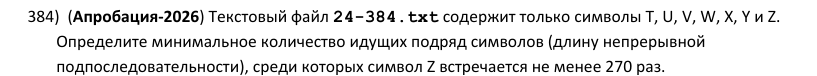

<details><summary>Текст условия</summary>(Апробация-2026) Текстовый файл 24-384.txt содержит только символы Т, U, V, W, X, Y и Z. Определите минимальное количество идущих подряд символов (длину непрерывной подпоследовательности), среди которых символ Z встречается не менее 270 раз.</details>

**Способ 1:** список позиций

In [654]:
s = open('24-384.txt').readline().strip()
p = [i for i in range(len(s)) if s[i] == 'Z']
print(min(p[j+269] - p[j] + 1 for j in range(len(p) - 269)))

1090


**Способ 2 (проверка):** два указателя

In [655]:
s = open('24-384.txt').readline().strip()
L = k = 0
mn = 10**9
for R in range(len(s)):
    k += s[R] == 'Z'
    while k > 270 or (k == 270 and s[L] != 'Z'):
        k -= s[L] == 'Z'
        L += 1
    if k >= 270:
        mn = min(mn, R - L + 1)
print(mn)

1090


**Ответ: `1090`**

### Задача 385

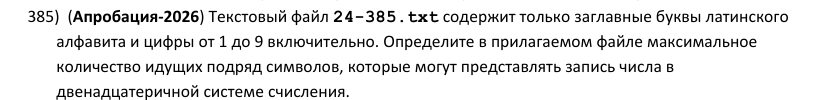

<details><summary>Текст условия</summary>(Апробация-2026) Текстовый файл 24-385.txt содержит только заглавные буквы латинского алфавита и цифры от 1 до 9 включительно. Определите в прилагаемом файле максимальное количество идущих подряд символов, которые могут представлять запись числа в двенадцатеричной системе счисления.</details>

**Способ 1:** регулярное выражение

In [656]:
from re import findall
s = open('24-385.txt').readline().strip()
print(max(map(len, findall('[1-9AB]+', s))))

15


**Способ 2 (проверка):** однопроходный алгоритм

In [657]:
s = open('24-385.txt').readline().strip()
k = mx = 0
for c in s:
    k = k + 1 if c in '123456789AB' else 0
    mx = max(mx, k)
print(mx)

15


**Ответ: `15`**

### Задача 386

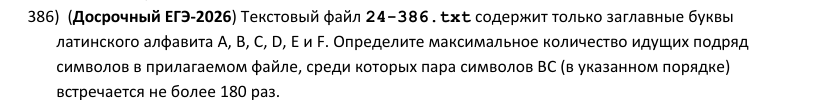

<details><summary>Текст условия</summary>(Досрочный ЕГЭ-2026) Текстовый файл 24-386.txt содержит только заглавные буквы латинского алфавита A, B, C, D, E и F. Определите максимальное количество идущих подряд символов в прилагаемом файле, среди которых пара символов BС (в указанном порядке) встречается не более 180 раз.</details>

**Способ 1:** список позиций пар

In [658]:
s = open('24-386.txt').readline().strip()
n = len(s)
p = [-1] + [i for i in range(n - 1) if s[i:i+2] == 'BC'] + [n - 1]
k = 180
print(max(p[j+k+1] - p[j] for j in range(len(p) - k - 1)))

35243


**Способ 2 (проверка):** два указателя

In [659]:
s = open('24-386.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    if R >= 1 and s[R-1:R+1] == 'BC' and R - 1 >= L:
        k += 1
    while k > 180:
        if s[L:L+2] == 'BC':
            k -= 1
        L += 1
    mx = max(mx, R - L + 1)
print(mx)

35243


**Ответ: `35243`**

### Задача 387

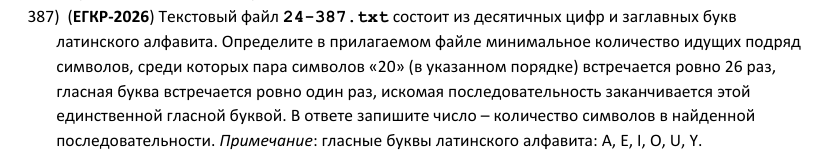

<details><summary>Текст условия</summary>(ЕГКР-2026) Текстовый файл 24-387.txt состоит из десятичных цифр и заглавных букв латинского алфавита. Определите в прилагаемом файле минимальное количество идущих подряд символов, среди которых пара символов «20» (в указанном порядке) встречается ровно 26 раз, гласная буква встречается ровно один раз, искомая последовательность заканчивается этой единственной гласной буквой. В ответе запишите число – количество символов в найденной последовательности. Примечание: гласные буквы латинского алфавита: A, E, I, O, U, Y.</details>

**Способ 1:** позиции гласных и пар 20

In [660]:
from bisect import bisect_right
s = open('24-387.txt').readline().strip()
n = len(s)
p = [i for i in range(n - 1) if s[i:i+2] == '20']
mn = 10**9
prev = -1                              # предыдущая гласная
for v in range(n):
    if s[v] in 'AEIOUY':
        j = bisect_right(p, v - 2)         # вхождения 20, целиком левее гласной
        if j >= 26:
            L = p[j - 26]                  # начинаем с 26-го с конца вхождения
            if L > prev:                   # и других гласных в окне нет
                mn = min(mn, v - L + 1)
        prev = v
print(mn)

66


**Способ 2 (проверка):** два указателя со сбросом на гласной

In [661]:
s = open('24-387.txt').readline().strip()
mn = 10**9
L = k = 0
for R in range(len(s)):
    if s[R] in 'AEIOUY':
        # окно заканчивается гласной: левее — только символы после предыдущей гласной
        while k > 26 or (k == 26 and s[L:L+2] != '20'):
            if s[L:L+2] == '20' and L + 1 <= R:
                k -= 1
            L += 1
        if k == 26:
            mn = min(mn, R - L + 1)
        L, k = R + 1, 0                    # следующая последовательность — после этой гласной
        continue
    if R >= 1 and s[R-1:R+1] == '20' and R - 1 >= L:
        k += 1
print(mn)

66


**Ответ: `66`**

### Задача 388

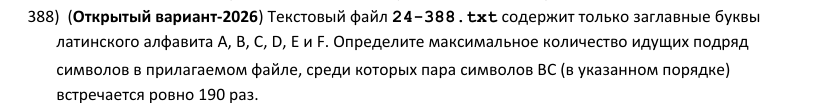

<details><summary>Текст условия</summary>(Открытый вариант-2026) Текстовый файл 24-388.txt содержит только заглавные буквы латинского алфавита A, B, C, D, E и F. Определите максимальное количество идущих подряд символов в прилагаемом файле, среди которых пара символов BС (в указанном порядке) встречается ровно 190 раз.</details>

**Способ 1:** список позиций пар

In [662]:
s = open('24-388.txt').readline().strip()
n = len(s)
p = [-1] + [i for i in range(n - 1) if s[i:i+2] == 'BC'] + [n - 1]
k = 190
print(max(p[j+k+1] - p[j] for j in range(len(p) - k - 1)))

2244


**Способ 2 (проверка):** два указателя

In [663]:
s = open('24-388.txt').readline().strip()
L = k = mx = 0
for R in range(len(s)):
    if R >= 1 and s[R-1:R+1] == 'BC' and R - 1 >= L:
        k += 1
    while k > 190:
        if s[L:L+2] == 'BC':
            k -= 1
        L += 1
    if k == 190:
        mx = max(mx, R - L + 1)
print(mx)

2244


**Ответ: `2244`**

### Задача 389

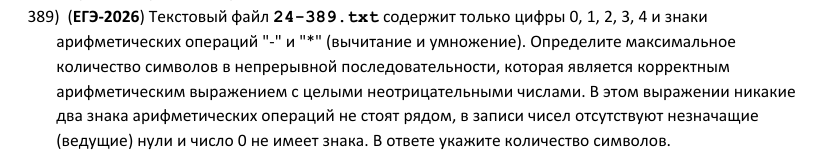

<details><summary>Текст условия</summary>(ЕГЭ-2026) Текстовый файл 24-389.txt содержит только цифры 0, 1, 2, 3, 4 и знаки арифметических операций &quot;-&quot; и &quot;*&quot; (вычитание и умножение). Определите максимальное количество символов в непрерывной последовательности, которая является корректным арифметическим выражением с целыми неотрицательными числами. В этом выражении никакие два знака арифметических операций не стоят рядом, в записи чисел отсутствуют незначащие (ведущие) нули и число 0 не имеет знака. В ответе укажите количество символов.</details>

**Способ 1:** регулярное выражение

In [664]:
from re import findall
s = open('24-389.txt').readline().strip()
num = '(?:[1-4][0-4]*|0)'
print(max(map(len, findall(f'{num}(?:[-*]{num})*', s))))

933


**Способ 2 (проверка):** метод замен (статья К.Ю. Полякова)

In [665]:
s = open('24-389.txt').readline().strip()
s = ' ' + s + ' '
for c in '234':
    s = s.replace(c, '1')
s = s.replace('-', '*')
s = s.replace('**', ' ')
s = s.replace(' *', ' ')
s = s.replace('* ', ' ')
s = s.replace('*00', '*0 0')
s = s.replace('*01', '*0 1')
while ' 00' in s:
    s = s.replace(' 00', ' 0')
s = s.replace(' 01', ' 1')
print(len(max(s.split(), key=len)))

933


**Ответ: `933`**

### Задача 390

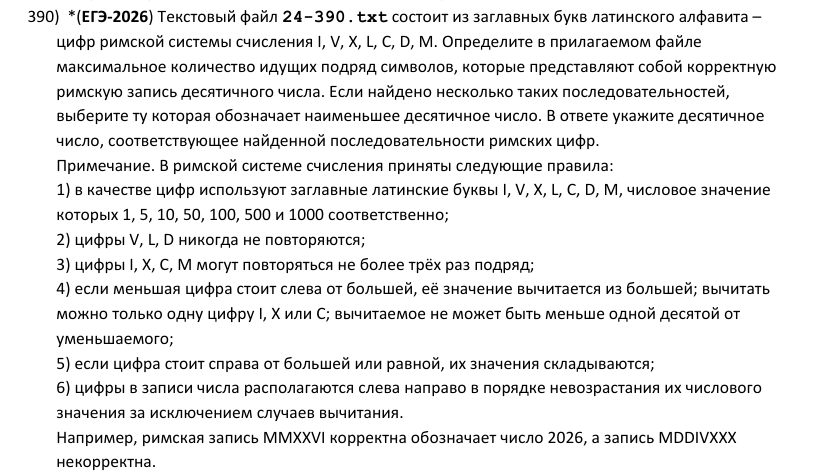

<details><summary>Текст условия</summary>*(ЕГЭ-2026) Текстовый файл 24-390.txt состоит из заглавных букв латинского алфавита – цифр римской системы счисления I, V, X, L, C, D, M. Определите в прилагаемом файле максимальное количество идущих подряд символов, которые представляют собой корректную римскую запись десятичного числа. Если найдено несколько таких последовательностей, выберите ту которая обозначает наименьшее десятичное число. В ответе укажите десятичное число, соответствующее найденной последовательности римских цифр.<br>Примечание. В римской системе счисления приняты следующие правила:<br>1) в качестве цифр используют заглавные латинские буквы I, V, X, L, C, D, M, числовое значение которых 1, 5, 10, 50, 100, 500 и 1000 соответственно;<br>2) цифры V, L, D никогда не повторяются;<br>3) цифры I, X, C, M могут повторяться не более трёх раз подряд;<br>4) если меньшая цифра стоит слева от большей, её значение вычитается из большей; вычитать можно только одну цифру I, Х или С; вычитаемое не может быть меньше одной десятой от уменьшаемого;<br>5) если цифра стоит справа от большей или равной, их значения складываются;<br>6) цифры в записи числа располагаются слева направо в порядке невозрастания их числового значения за исключением случаев вычитания.<br>Например, римская запись MMXXVI корректна обозначает число 2026, а запись MDDIVXXX некорректна.</details>

**Способ 1:** словарь всех правильных римских чисел

In [666]:
def roman(v):
    r = ''
    for val, sym in [(1000, 'M'), (900, 'CM'), (500, 'D'), (400, 'CD'), (100, 'C'), (90, 'XC'),
                     (50, 'L'), (40, 'XL'), (10, 'X'), (9, 'IX'), (5, 'V'), (4, 'IV'), (1, 'I')]:
        while v >= val:
            r += sym
            v -= val
    return r
R = {roman(v): v for v in range(1, 4000)}      # все правильные записи 1..3999
s = open('24-390.txt').readline().strip()
best = (0, 0)
for i in range(len(s)):
    for L in range(15, 0, -1):                  # самая длинная запись — 15 символов (MMMDCCCLXXXVIII)
        x = s[i:i+L]
        if len(x) == L and x in R:          # у конца строки срез может быть короче
            best = max(best, (L, -R[x]))         # длиннее, при равенстве — меньше число
            break
print(best[0], -best[1])

13 3738


**Способ 2 (проверка):** регулярное выражение римского числа

In [667]:
from re import findall
s = open('24-390.txt').readline().strip()
pat = 'M{0,3}(?:CM|CD|D?C{0,3})(?:XC|XL|L?X{0,3})(?:IX|IV|V?I{0,3})'
a = [x for x in findall(f'(?=({pat}))', s) if x]
val = {'I': 1, 'V': 5, 'X': 10, 'L': 50, 'C': 100, 'D': 500, 'M': 1000}
def toint(x):
    return sum(-val[x[i]] if i + 1 < len(x) and val[x[i]] < val[x[i+1]] else val[x[i]] for i in range(len(x)))
L = max(map(len, a))
print(L, min(toint(x) for x in a if len(x) == L))

13 3738


**Ответ: `3738`**

> Правила из условия задают стандартную запись римских чисел от 1 до 3999. Программа печатает длину и число (ответ — число).

### Задача 391

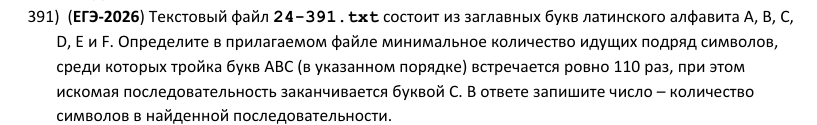

<details><summary>Текст условия</summary>(ЕГЭ-2026) Текстовый файл 24-391.txt состоит из заглавных букв латинского алфавита А, В, С, D, Е и F. Определите в прилагаемом файле минимальное количество идущих подряд символов, среди которых тройка букв АВС (в указанном порядке) встречается ровно 110 раз, при этом искомая последовательность заканчивается буквой С. В ответе запишите число – количество символов в найденной последовательности.</details>

**Способ 1:** список позиций тройки

In [668]:
s = open('24-391.txt').readline().strip()
p = [i for i in range(len(s) - 2) if s[i:i+3] == 'ABC']
k = 110
print(min(p[j+k-1] + 3 - p[j] for j in range(len(p) - k + 1)))

470


**Способ 2 (проверка):** finditer

In [669]:
from re import finditer
s = open('24-391.txt').readline().strip()
p = [m.start() for m in finditer('ABC', s)]
print(min(p[j+109] - p[j] + 3 for j in range(len(p) - 109)))

470


**Ответ: `470`**

> Самая короткая подстрока начинается с A первой тройки и заканчивается C последней — то есть буквой C.

### Задача 392

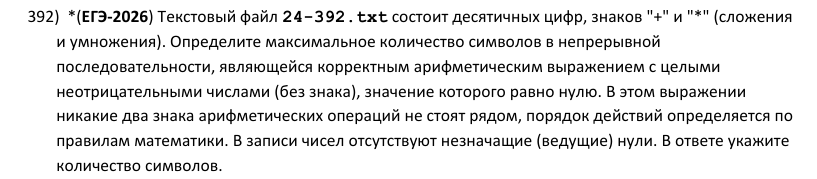

<details><summary>Текст условия</summary>*(ЕГЭ-2026) Текстовый файл 24-392.txt состоит десятичных цифр, знаков &quot;+&quot; и &quot;*&quot; (сложения и умножения). Определите максимальное количество символов в непрерывной последовательности, являющейся корректным арифметическим выражением с целыми неотрицательными числами (без знака), значение которого равно нулю. В этом выражении никакие два знака арифметических операций не стоят рядом, порядок действий определяется по правилам математики. В записи чисел отсутствуют незначащие (ведущие) нули. В ответе укажите количество символов.</details>

**Способ 1:** регулярное выражение с (?=...)

In [670]:
from re import findall
s = open('24-392.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
prod = fr'(?:{num}\*)*0(?:\*{num})*'      # произведение, в котором есть множитель 0
expr = fr'{prod}(?:\+{prod})*'
print(max(map(len, findall(f'(?=({expr}))', s))))

123


**Способ 2 (проверка):** то же выражение без (?=...) (быстрее)

In [671]:
from re import findall
s = open('24-392.txt').readline().strip()
num = r'(?:[1-9]\d*|0)'
prod = fr'(?:{num}\*)*0(?:\*{num})*'
print(max(map(len, findall(fr'{prod}(?:\+{prod})*', s))))

123


**Ответ: `123`**

> Метод (статья К.Ю. Полякова) проверен полным перебором на тысячах случайных строк.